In [ ]:

# ============================================================
# WIND VISION — FINAL COMPLETION
# CELL 0: PINNED SOURCE RECOVERY + EVIDENCE DISCOVERY
#
# Safe:
# - Mounts Google Drive
# - Clones pinned public NASA reference into /content
# - Finds existing project data and source files
# - Verifies critical model checkpoints
#
# Does NOT train, install packages, or change archives.
# ============================================================

import sys
import os
import subprocess
import hashlib
from pathlib import Path
from collections import defaultdict

from google.colab import drive

drive.mount("/content/drive")

PIN = "921e666c8d6060ae13bfd901dcc7f74f819d0eea"

URL = "https://github.com/nasa/random_field_c-lfm.git"

REPO = Path("/content/nasa_clfm_reference")

ROOT = Path(
    "/content/drive/MyDrive/"
    "CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction"
)

EVIDENCE = ROOT / "evidence"

FULLSCALE = (
    EVIDENCE / "fullscale_physicsnemo_training"
)

FLOW_V3 = (
    FULLSCALE /
    "matched_flow_v3_fullcov_preconditioned_100epoch_v1"
)

def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(
            lambda: f.read(8 * 1024 * 1024),
            b""
        ):
            h.update(chunk)
    return h.hexdigest()

def run(*args):
    return subprocess.check_output(
        args,
        text=True,
        stderr=subprocess.STDOUT
    ).strip()

print("=" * 70)
print("WIND VISION — FINAL COMPLETION BOOTSTRAP")
print("=" * 70)

assert ROOT.is_dir(), "Project Drive directory missing"

print("PROJECT_ROOT:", ROOT)
print("PYTHON:", sys.version.split()[0])

# ------------------------------------------------------------
# Restore exact historical NASA source.
# ------------------------------------------------------------

if not REPO.exists():
    print("\nCloning pinned NASA reference repository ...")
    run("git", "clone", URL, str(REPO))

assert (REPO / ".git").is_dir(), (
    "Existing NASA source directory is not a Git checkout."
)

head = run(
    "git", "-C", str(REPO),
    "rev-parse", "HEAD"
)

if head != PIN:
    # Do not overwrite user modifications in an existing checkout.
    status = run(
        "git", "-C", str(REPO),
        "status", "--porcelain"
    )
    assert not status, (
        "Existing checkout contains local changes. "
        "Review before switching commits."
    )

    run(
        "git", "-C", str(REPO),
        "fetch", "origin", PIN
    )

    run(
        "git", "-C", str(REPO),
        "checkout", "--detach", PIN
    )

assert run(
    "git", "-C", str(REPO),
    "rev-parse", "HEAD"
) == PIN

print("\nNASA_PINNED_SOURCE: VERIFIED")
print("NASA_COMMIT:", PIN)

required_scripts = [
    "scripts/wind/train_vae.py",
    "scripts/wind/train_lfm.py",
    "scripts/wind/test_lfm.py",
    "clfm/problems/wind.py",
    "data/wind_data_generation/generate_wind_data.py"
]

for rel in required_scripts:
    path = REPO / rel
    assert path.is_file(), f"Missing source: {rel}"
    print("SOURCE_OK:", rel)

# ------------------------------------------------------------
# Find existing project data and native model source.
# Read-only inventory; does not load any wind data.
# ------------------------------------------------------------

wanted = {
    "wind_train_data.hdf5",
    "wind_test_data.hdf5",
    "models.py",
    "environment.yml",
    "requirements.txt",
    "requirements-dev.txt"
}

found = defaultdict(list)

print("\nDISCOVERING_EXISTING_PROJECT_ASSETS ...")

for directory, dirs, filenames in os.walk(ROOT):
    for filename in filenames:
        if filename in wanted:
            path = Path(directory) / filename
            found[filename].append(path)

for name in sorted(wanted):
    matches = found[name]

    print(
        "\nASSET:",
        name,
        "FOUND:", len(matches)
    )

    for path in matches[:8]:
        print(
            " ",
            path,
            "| MiB:",
            round(path.stat().st_size / 2**20, 2)
        )

# ------------------------------------------------------------
# Verify frozen checkpoints still exist on Drive.
# ------------------------------------------------------------

checkpoints = {
    "NASA_REFERENCE_VAE":
        EVIDENCE /
        "w1_e32_20261104T040902726350Z/"
        "checkpoints/last.ckpt",

    "NASA_REFERENCE_FLOW":
        EVIDENCE /
        "w1_e49_matched_e32_flow100_20261104/"
        "matched_flow_final.pth",

    "PHYSICSNEMO_TRAINED_FLOW_448":
        EVIDENCE /
        "gate2f_physicsnemo_flow_448_seed490150/"
        "gate2f_native_flow_448_final.pth",

    "FULLSCALE_PHYSICSNEMO_VAE":
        FULLSCALE /
        "joint_stochastic_vae_from_repaired8_v1/"
        "latest.pt",

    "FULLSCALE_FLOW_V3":
        FLOW_V3 / "latest.pt",
}

for name, path in checkpoints.items():
    if path.is_file():
        print(
            "\nCHECKPOINT_OK:",
            name,
            "SHA256:",
            sha256(path)
        )
    else:
        print("\nCHECKPOINT_MISSING:", name)

print("\n" + "=" * 70)
print("CELL 0 COMPLETE")
print("PINNED_NASA_SOURCE: AVAILABLE")
print("EXISTING_ASSETS: INVENTORIED")
print("NO_TRAINING_PERFORMED: TRUE")
print("NO_ARCHIVED_ARTIFACTS_MODIFIED: TRUE")
print("=" * 70)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
WIND VISION — FINAL COMPLETION BOOTSTRAP
PROJECT_ROOT: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_proposal_reproduction
PYTHON: 3.13.16

NASA_PINNED_SOURCE: VERIFIED
NASA_COMMIT: 921e666c8d6060ae13bfd901dcc7f74f819d0eea
SOURCE_OK: scripts/wind/train_vae.py
SOURCE_OK: scripts/wind/train_lfm.py
SOURCE_OK: scripts/wind/test_lfm.py
SOURCE_OK: clfm/problems/wind.py
SOURCE_OK: data/wind_data_generation/generate_wind_data.py

DISCOVERING_EXISTING_PROJECT_ASSETS ...

ASSET: environment.yml FOUND: 0

ASSET: models.py FOUND: 0

ASSET: requirements-dev.txt FOUND: 0

ASSET: requirements.txt FOUND: 0

ASSET: wind_test_data.hdf5 FOUND: 0

ASSET: wind_train_data.hdf5 FOUND: 0

CHECKPOINT_OK: NASA_REFERENCE_VAE SHA256: bb8457f5650536966e82916aac197726df0089f061b0c18ed6c980a62d6aa9c5

CHECKPOINT_OK: NASA_REFERENCE_FLOW SHA256: 6d7ab8117dabad90232beaf55a7d4d345d3

In [ ]:

# ====================================================================
# WIND VISION — FINAL COMPLETION / CELL 1
# RESTORE VERIFIED NATIVE SOURCE + PINNED RUNTIME DEPENDENCIES
#
# Does not train, generate wind, alter archived checkpoints,
# modify the NASA reference repository, or access final-test data.
# ====================================================================

from pathlib import Path
import hashlib
import importlib.metadata as md
import os
import shutil
import subprocess
import sys

PIN = "921e666c8d6060ae13bfd901dcc7f74f819d0eea"

ROOT = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction"
)

EVIDENCE = ROOT / "evidence/fullscale_physicsnemo_training"

REPO = Path("/content/nasa_clfm_reference")

BACKUP = (
    EVIDENCE /
    "research_handoff_after_cell44_v1/"
    "verified_native_models.py"
)

NATIVE = Path(
    "/content/wind_vision_fullscale/models/models.py"
)

EXPECTED_NATIVE_SHA = (
    "c45282f2ac65eece3b935d30e018dea71e4566d32fb43fbd89a138ab989d52eb"
)

ENV_FILE = Path(
    "/content/wind_vision_final_completion_environment.txt"
)


def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(
            lambda: f.read(8 * 1024 * 1024),
            b""
        ):
            h.update(block)
    return h.hexdigest()


def command(args):
    return subprocess.run(
        args,
        check=True,
        text=True
    )


print("=" * 72)
print("WIND VISION — CELL 1 SOURCE AND ENVIRONMENT RESTORATION")
print("=" * 72)

assert REPO.is_dir()
assert BACKUP.is_file(), (
    "Archived native source not found: " + str(BACKUP)
)

assert sha256(BACKUP) == EXPECTED_NATIVE_SHA, (
    "Native source backup hash mismatch. STOP."
)

head = subprocess.check_output(
    ["git", "-C", str(REPO), "rev-parse", "HEAD"],
    text=True
).strip()

assert head == PIN, "NASA source commit mismatch."

print("NASA_REFERENCE_COMMIT: VERIFIED")
print("NATIVE_SOURCE_BACKUP_SHA256: VERIFIED")

# --------------------------------------------------------------------
# Restore only into ephemeral Colab storage.
# Never overwrite a different existing source.
# --------------------------------------------------------------------

NATIVE.parent.mkdir(
    parents=True,
    exist_ok=True
)

if NATIVE.exists():
    assert sha256(NATIVE) == EXPECTED_NATIVE_SHA, (
        "Existing native source differs. STOP, do not overwrite."
    )
    print("NATIVE_SOURCE: ALREADY RESTORED")

else:
    stage = NATIVE.with_name(
        ".models.py.restoring"
    )
    assert not stage.exists(), "Stale staging file."

    shutil.copyfile(
        BACKUP,
        stage
    )

    assert sha256(stage) == EXPECTED_NATIVE_SHA

    os.replace(
        stage,
        NATIVE
    )
    print("NATIVE_SOURCE: RESTORED FROM VERIFIED BACKUP")

assert sha256(NATIVE) == EXPECTED_NATIVE_SHA

print("NATIVE_SOURCE_PATH:", NATIVE)
print("NATIVE_SOURCE_SHA256:", sha256(NATIVE))

# --------------------------------------------------------------------
# Preserve existing CUDA PyTorch version through dependency resolution.
# Do not silently replace the validated torch installation.
# --------------------------------------------------------------------

torch_before = md.version("torch")

assert torch_before == "2.14.1+cu130", (
    f"Unexpected PyTorch {torch_before}. "
    "Review environment before installation."
)

constraints = Path(
    "/content/wind_vision_completion_constraints.txt"
)

constraints.write_text(
    "torch==2.14.1+cu130\n",
    encoding="utf-8"
)

print("EXISTING_TORCH:", torch_before)
print("INSTALLING_HISTORICALLY_USED_DEPENDENCIES")

# Nvidia's distribution name is nvidia-physicsnemo.
# Use a basic install, rather than changing CUDA backends.
# The torch constraint prevents a silent replacement.

command([
    sys.executable, "-m", "pip", "install",
    "--upgrade-strategy", "only-if-needed",
    "--constraint", str(constraints),
    "nvidia-physicsnemo==2.2.2",
    "lightning==2.6.6",
    "torchdyn",
    "torchdiffeq",
])

assert md.version("torch") == torch_before, (
    "PyTorch version changed unexpectedly."
)

assert md.version("nvidia-physicsnemo") == "2.2.2"
assert md.version("lightning") == "2.6.6"

print("PACKAGE_INSTALLATION: COMPLETED")
print("TORCH_VERSION_PRESERVED:", md.version("torch"))

# --------------------------------------------------------------------
# Test imports in a clean Python subprocess.
# Avoid relying on cached notebook module imports.
# --------------------------------------------------------------------

probe = r'''
import sys
import torch
import lightning
import physicsnemo
import torchdyn
import torchdiffeq

from pathlib import Path

repo = Path("/content/nasa_clfm_reference")
native = Path("/content/wind_vision_fullscale/models")

sys.path.insert(0, str(repo))
sys.path.insert(0, str(native))

from physicsnemo.core.module import Module

from clfm.nn.vae import FunctionalVAE
from clfm.nn.fully_connected_nets import FlowModel
from clfm.problems.wind import WindDataset, WindLoss

from models import PhysicsNeMoWindVAE, PhysicsNeMoWindFlow

assert torch.cuda.is_available()
assert torch.cuda.device_count() == 1

assert issubclass(PhysicsNeMoWindVAE, Module)
assert issubclass(PhysicsNeMoWindFlow, Module)

print("NASA_VAE_IMPORT: PASS")
print("NASA_FLOW_IMPORT: PASS")
print("NATIVE_PHYSICSNEMO_VAE_IMPORT: PASS")
print("NATIVE_PHYSICSNEMO_FLOW_IMPORT: PASS")
print("PHYSICSNEMO_MODULE_INHERITANCE: PASS")
print("CUDA_GPU:", torch.cuda.get_device_name(0))
print("TORCH:", torch.__version__)
print("PHYSICSNEMO:", physicsnemo.__version__)
print("LIGHTNING:", lightning.__version__)
'''

command([
    sys.executable,
    "-c",
    probe
])

# --------------------------------------------------------------------
# Save exact environment metadata for final reproducibility.
# Local runtime only: no Drive archive is modified.
# --------------------------------------------------------------------

freeze = subprocess.check_output(
    [sys.executable, "-m", "pip", "freeze"],
    text=True
)

ENV_FILE.write_text(
    freeze,
    encoding="utf-8"
)

assert sha256(BACKUP) == EXPECTED_NATIVE_SHA
assert sha256(NATIVE) == EXPECTED_NATIVE_SHA

print("\n" + "=" * 72)
print("WIND VISION — CELL 1 COMPLETE")
print("=" * 72)

print("NASA_SOURCE_PINNED: PASS")
print("NATIVE_MODEL_SOURCE_RECOVERED: PASS")
print("NATIVE_MODEL_SOURCE_HASH: PASS")
print("ORIGINAL_SOURCE_UNMODIFIED: TRUE")
print("CHECKPOINTS_UNMODIFIED: TRUE")
print("MODEL_TRAINING_PERFORMED: FALSE")
print("RUNTIME_IMPORT_SMOKE_TEST: PASS")

print("ENVIRONMENT_FREEZE:", ENV_FILE)
print("ENVIRONMENT_FREEZE_SHA256:", sha256(ENV_FILE))

print("=" * 72)


WIND VISION — CELL 1 SOURCE AND ENVIRONMENT RESTORATION
NASA_REFERENCE_COMMIT: VERIFIED
NATIVE_SOURCE_BACKUP_SHA256: VERIFIED
NATIVE_SOURCE: RESTORED FROM VERIFIED BACKUP
NATIVE_SOURCE_PATH: /content/wind_vision_fullscale/models/models.py
NATIVE_SOURCE_SHA256: c45282f2ac65eece3b935d30e018dea71e4566d32fb43fbd89a138ab989d52eb
EXISTING_TORCH: 2.14.1+cu130
INSTALLING_HISTORICALLY_USED_DEPENDENCIES
PACKAGE_INSTALLATION: COMPLETED
TORCH_VERSION_PRESERVED: 2.14.1+cu130

WIND VISION — CELL 1 COMPLETE
NASA_SOURCE_PINNED: PASS
NATIVE_MODEL_SOURCE_RECOVERED: PASS
NATIVE_MODEL_SOURCE_HASH: PASS
ORIGINAL_SOURCE_UNMODIFIED: TRUE
CHECKPOINTS_UNMODIFIED: TRUE
MODEL_TRAINING_PERFORMED: FALSE
RUNTIME_IMPORT_SMOKE_TEST: PASS
ENVIRONMENT_FREEZE: /content/wind_vision_final_completion_environment.txt
ENVIRONMENT_FREEZE_SHA256: 464f4e2cb8734b121ae7aa0eab53b3b3020876d5dfd24e84f503eff189f54388


In [ ]:

# ====================================================================
# WIND VISION — FINAL COMPLETION / CELL 2
# W3: FRESH RANDOM-NOISE -> FLOW V3 -> VAE -> WIND GENERATION
#
# Uses frozen, SHA-256-verified models.
# No training and no test-field values accessed.
# Adaptive Dopri5 is explicitly recorded as this replay's solver.
# Writes new evidence only under final_completion_20261108_v1.
# ====================================================================

import os
import sys
import json
import time
import hashlib
import platform
import importlib.metadata as metadata
from pathlib import Path

import numpy as np
import torch
from torchdiffeq import odeint

ROOT = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction/evidence/"
    "fullscale_physicsnemo_training"
)

V3 = ROOT / (
    "matched_flow_v3_fullcov_preconditioned_100epoch_v1"
)

SOURCE = Path(
    "/content/wind_vision_fullscale/models/models.py"
)

ORIGIN = ROOT / (
    "native_vae_5000_seed490300_extend_to200_v1/latest.pt"
)

VAE = ROOT / (
    "joint_stochastic_vae_from_repaired8_v1/latest.pt"
)

FLOW = V3 / "latest.pt"

TRANSFORM = V3 / "fullcov_transform_v1.npz"

PREVIEW = ROOT / (
    "matched_flow_v2_100epoch_pilot_v1/"
    "physical_generation_epoch100/"
    "wind_preview_8_v1.npz"
)

PRIOR = V3 / (
    "physical_generation_epoch100_v1/"
    "generated_latents_128_v1.npz"
)

OUT = ROOT / (
    "final_completion_20261108_v1/"
    "cell02_native_fresh_generation_v1"
)

FIELDS_FILE = OUT / "generated_wind_16_v1.npz"
REPORT_FILE = OUT / "generation_report_v1.json"

EXPECTED = {
    SOURCE:
        "c45282f2ac65eece3b935d30e018dea71e4566d32fb43fbd89a138ab989d52eb",

    ORIGIN:
        "d1c4fe3bf00bdc4bd9789a242eeb13f7464a85671dbc6206ba506af9661e64d5",

    VAE:
        "d2bc9d42c3aa9738217dfde92aa12b4468268945fd1a7b958b087878f704f9e9",

    FLOW:
        "0ac1d4eec243fe069dbd4cf095e628f35f97168b22699f73b7f753f157da6368",

    TRANSFORM:
        "a7109beb5d8fa239aa86d844c9fd2f0ed54746d203076956c7d1463b5e9fe244",

    PREVIEW:
        "098580cafd4191dc6637c628c743dfbda9b72748e43a41fe940f35b31267da1f",

    PRIOR:
        "e5fbbfd1ff206e9f399267518894c3b1ce4b033ad550a04cb965a9caa360b97f",
}

SEED = 490802
N_FIELDS = 16
BATCH_SIZE = 2
DECODE_CHUNK = 2048
LATENT_DIM = 128

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(
            lambda: f.read(8 * 1024 * 1024),
            b""
        ):
            h.update(block)
    return h.hexdigest()

def array_sha(a):
    return hashlib.sha256(
        np.ascontiguousarray(a).tobytes()
    ).hexdigest()

print("=" * 72)
print("WIND VISION — CELL 2 FRESH PHYSICSNEMO GENERATION")
print("=" * 72, flush=True)

# ------------------------------------------------------------
# 1. Verify frozen sources and current runtime.
# ------------------------------------------------------------

assert torch.cuda.is_available()
assert torch.cuda.device_count() == 1

assert torch.__version__ == "2.14.1+cu130"

for path, expected in EXPECTED.items():
    assert path.is_file(), f"Missing: {path}"
    assert sha256(path) == expected, (
        f"SHA-256 mismatch: {path}"
    )

print("ALL_FROZEN_INPUTS: VERIFIED", flush=True)

if str(SOURCE.parent) not in sys.path:
    sys.path.insert(0, str(SOURCE.parent))

if "/content/nasa_clfm_reference" not in sys.path:
    sys.path.insert(
        0,
        "/content/nasa_clfm_reference"
    )

from models import (
    PhysicsNeMoWindVAE,
    PhysicsNeMoWindFlow
)

torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda")

# ------------------------------------------------------------
# 2. Inspect the trained checkpoint lineage.
# ------------------------------------------------------------

origin = torch.load(
    ORIGIN,
    map_location="cpu",
    weights_only=True
)

trained_vae = torch.load(
    VAE,
    map_location="cpu",
    weights_only=True
)

trained_flow = torch.load(
    FLOW,
    map_location="cpu",
    weights_only=True
)

assert trained_vae["completed_epochs"] == 6

assert trained_flow["format"] == (
    "wind_vision_flow_v3_checkpoint_v1"
)

assert trained_flow["completed_epochs"] == 100

assert trained_flow["optimizer_updates"] == 3200

experiment = trained_flow["experiment"]

assert experiment["vae_v2_checkpoint_sha256"] == EXPECTED[VAE]

assert experiment["native_model_code_sha256"] == EXPECTED[SOURCE]

assert experiment["transform_sha256"] == EXPECTED[TRANSFORM]

print("MATCHED_VAE_FLOW_LINEAGE: VERIFIED")
print("FLOW_V3_EPOCHS: 100")
print("FLOW_V3_OPTIMIZER_UPDATES: 3200")

# ------------------------------------------------------------
# 3. Restore the exact trained model architectures.
# ------------------------------------------------------------

vae = PhysicsNeMoWindVAE(
    origin["architecture_config"]
).to(DEVICE)

vae.load_state_dict(
    trained_vae["model_state"],
    strict=True
)

flow = PhysicsNeMoWindFlow(
    experiment["flow_architecture"]
).to(DEVICE)

flow.load_state_dict(
    trained_flow["model_state"],
    strict=True
)

vae.eval().requires_grad_(False)
flow.eval().requires_grad_(False)

assert sum(
    p.numel() for p in vae.parameters()
) == 877057

assert sum(
    p.numel() for p in flow.parameters()
) == 1182848

print("NATIVE_VAE_CHECKPOINT_RESTORED: PASS")
print("NATIVE_FLOW_V3_CHECKPOINT_RESTORED: PASS")

# ------------------------------------------------------------
# 4. Restore the full-covariance latent inverse transform.
# ------------------------------------------------------------

with np.load(TRANSFORM, allow_pickle=False) as p:
    z_mean = p["z_mean"].astype(np.float32).copy()
    z_std = p["z_std"].astype(np.float32).copy()
    dewhitening = p[
        "dewhitening"
    ].astype(np.float32).copy()

assert z_mean.shape == (LATENT_DIM,)
assert z_std.shape == (LATENT_DIM,)
assert dewhitening.shape == (
    LATENT_DIM,
    LATENT_DIM
)

assert np.all(z_std > 0)
assert np.isfinite(dewhitening).all()

mean_gpu = torch.from_numpy(z_mean).to(DEVICE)
std_gpu = torch.from_numpy(z_std).to(DEVICE)
inv_gpu = torch.from_numpy(dewhitening).to(DEVICE)

# ------------------------------------------------------------
# 5. Restore verified physical spatial/time coordinates.
# We use only the coordinate metadata, not reference wind.
# ------------------------------------------------------------

with np.load(PREVIEW, allow_pickle=False) as p:
    xyz = p["x_grid"].astype(np.float32).copy()
    times = p["t_grid"].astype(np.float32).copy()

assert xyz.shape == (100, 3)
assert times.shape == (256,)

coordinates = np.concatenate([
    np.broadcast_to(
        xyz[:, None, :],
        (100, 256, 3)
    ),
    np.broadcast_to(
        times[None, :, None],
        (100, 256, 1)
    )
], axis=-1).reshape(25600, 4).copy()

coords_gpu = torch.from_numpy(
    coordinates
).to(DEVICE)

print("WIND_GEOMETRY: 100 SENSORS x 256 TIMES")

# ------------------------------------------------------------
# 6. Draw genuinely new latent Gaussian noise.
# Use CPU generator for explicit deterministic input.
# ------------------------------------------------------------

rng = torch.Generator(
    device="cpu"
).manual_seed(SEED)

noise_cpu = torch.randn(
    N_FIELDS,
    LATENT_DIM,
    generator=rng,
    dtype=torch.float32
)

noise = noise_cpu.to(DEVICE)

assert noise.shape == (N_FIELDS, 128)

print("NEW_GAUSSIAN_INPUT_SEED:", SEED)
print("NEW_GAUSSIAN_INPUT_SHA256:",
      array_sha(noise_cpu.numpy()))

# ------------------------------------------------------------
# 7. Integrate the trained latent velocity field.
#
# Adaptive Dopri5 with rtol=atol=1e-6.
# This is a fresh-sampling test, not a matched timing benchmark.
# ------------------------------------------------------------

class FlowRHS(torch.nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model
        self.nfe = 0

    def forward(self, t, z):
        self.nfe += 1
        return self.model.vector_field(t, z)


time_points = torch.tensor(
    [0.0, 1.0],
    device=DEVICE,
    dtype=torch.float32
)

wind = np.empty(
    (N_FIELDS, 100, 256),
    dtype=np.float32
)

generated_z = np.empty(
    (N_FIELDS, LATENT_DIM),
    dtype=np.float32
)

generated_whitened = np.empty_like(
    generated_z
)

nfe_per_batch = []

torch.cuda.synchronize()
started = time.perf_counter()

with torch.inference_mode():

    for start in range(0, N_FIELDS, BATCH_SIZE):

        stop = min(
            start + BATCH_SIZE,
            N_FIELDS
        )

        z0 = noise[start:stop]

        rhs = FlowRHS(flow)

        trajectory = odeint(
            rhs,
            z0,
            time_points,
            method="dopri5",
            rtol=1e-6,
            atol=1e-6
        )

        z_white = trajectory[-1]

        assert z_white.shape == (
            stop - start,
            128
        )

        assert bool(torch.isfinite(z_white).all())

        # Inverse of the original full-covariance whitening:
        # z = (z_white @ dewhitening) * std + mean

        z = (
            (z_white @ inv_gpu)
            * std_gpu
            + mean_gpu
        )

        assert bool(torch.isfinite(z).all())

        generated_z[start:stop] = (
            z.cpu().numpy()
        )

        generated_whitened[start:stop] = (
            z_white.cpu().numpy()
        )

        nfe_per_batch.append(rhs.nfe)

        # Decode the complete wind field in memory-safe
        # coordinate chunks. No original observed wind
        # is supplied to the model.

        chunks = []

        for first in range(0, 25600, DECODE_CHUNK):

            x = coords_gpu[
                first:first+DECODE_CHUNK
            ]

            x = x.unsqueeze(0).expand(
                len(z), -1, -1
            )

            out = vae.decode(z, x)

            assert out.shape == (
                len(z),
                len(x[0]),
                1
            )

            assert bool(torch.isfinite(out).all())

            physical = (
                out[..., 0].float() * 49.0 - 2.0
            )

            chunks.append(
                physical.cpu().numpy()
            )

        field_block = np.concatenate(
            chunks,
            axis=1
        ).reshape(
            stop-start,
            100,
            256
        )

        assert np.isfinite(field_block).all()

        wind[start:stop] = field_block

        print(
            f"GENERATED_FIELDS: {stop}/{N_FIELDS}"
            f" | ODE_NFE={rhs.nfe}",
            flush=True
        )

torch.cuda.synchronize()
elapsed = time.perf_counter() - started

# ------------------------------------------------------------
# 8. Check finiteness, variability and independence diagnostics.
# ------------------------------------------------------------

assert wind.shape == (16, 100, 256)

assert np.isfinite(wind).all()

temporal_anomaly = (
    wind.astype(np.float64)
    - wind.astype(np.float64).mean(
        axis=-1,
        keepdims=True
    )
)

temporal_variance = float(
    np.mean(temporal_anomaly**2)
)

interior_step_rms = float(
    np.sqrt(
        np.mean(
            np.diff(
                wind.astype(np.float64),
                axis=-1
            )**2
        )
    )
)

field_energy = np.mean(
    temporal_anomaly**2,
    axis=(1, 2)
)

energy_cv = float(
    np.std(field_energy, ddof=1)
    / max(np.mean(field_energy), 1e-12)
)

# This checks nonduplication against the previously frozen
# 128 Flow V3 generated decoder latents. It is not a
# statistical proof of a correct wind distribution.

with np.load(PRIOR, allow_pickle=False) as p:
    prior_z = p[
        "generated_decoder_z"
    ].astype(np.float32)

    assert str(
        p["flow_v3_sha256"].item()
    ) == EXPECTED[FLOW]

assert prior_z.shape == (128, 128)

latent_distances = np.linalg.norm(
    generated_z[:, None, :].astype(np.float64)
    - prior_z[None, :, :].astype(np.float64),
    axis=-1
)

min_prior_distance = float(
    latent_distances.min()
)

assert min_prior_distance > 1e-3, (
    "Unexpected generated-latent collision with prior bank"
)

print("FRESH_GENERATED_LATENTS: NONDUPLICATE")
print("GENERATED_WIND_FINITE: TRUE")

# ------------------------------------------------------------
# 9. Archive immutable evidence.
# ------------------------------------------------------------

OUT.mkdir(parents=True, exist_ok=True)

assert not FIELDS_FILE.exists(), (
    "This generation archive already exists. "
    "Do not overwrite it; inspect the original."
)

assert not REPORT_FILE.exists(), (
    "Existing report detected. Do not overwrite."
)

stage = OUT / ".generated_wind_16_v1.staging"

assert not stage.exists()

with stage.open("wb") as f:
    np.savez_compressed(
        f,
        wind_mps=wind,
        generated_decoder_z=generated_z,
        generated_whitened_z=generated_whitened,
        initial_gaussian_noise=noise_cpu.numpy(),
        xyz=xyz,
        t_grid=times,
        seed=np.array(SEED),
        flow_sha256=np.array(EXPECTED[FLOW]),
        vae_sha256=np.array(EXPECTED[VAE]),
        transform_sha256=np.array(EXPECTED[TRANSFORM]),
        solver=np.array("torchdiffeq:dopri5:1e-6")
    )

with np.load(stage, allow_pickle=False) as p:
    assert np.array_equal(
        p["wind_mps"],
        wind
    )
    assert np.array_equal(
        p["generated_decoder_z"],
        generated_z
    )

os.replace(stage, FIELDS_FILE)

report = {
    "format":
        "wind_vision_native_flow_v3_fresh_generation_v1",

    "stage":
        "W3 end-to-end fresh generation replay; "
        "not full quality acceptance or benchmark",

    "source_sha256": {
        str(p): sha256(p)
        for p in EXPECTED
    },

    "vae_checkpoint_sha256":
        EXPECTED[VAE],

    "flow_checkpoint_sha256":
        EXPECTED[FLOW],

    "transform_sha256":
        EXPECTED[TRANSFORM],

    "generated_archive_sha256":
        sha256(FIELDS_FILE),

    "generated_wind_array_sha256":
        array_sha(wind),

    "noise_array_sha256":
        array_sha(noise_cpu.numpy()),

    "seed": SEED,

    "shape": list(wind.shape),

    "solver": {
        "library": "torchdiffeq",
        "method": "dopri5",
        "rtol": 1e-6,
        "atol": 1e-6,
        "nfe_by_batch": nfe_per_batch
    },

    "runtime": {
        "python": platform.python_version(),
        "torch": torch.__version__,
        "physicsnemo":
            metadata.version("nvidia-physicsnemo"),
        "gpu": torch.cuda.get_device_name(0)
    },

    "generation_elapsed_seconds_diagnostic_only":
        elapsed,

    "wind_mean_mps":
        float(wind.mean()),

    "wind_min_mps":
        float(wind.min()),

    "wind_max_mps":
        float(wind.max()),

    "temporal_variance_mps_squared":
        temporal_variance,

    "interior_step_rms_mps":
        interior_step_rms,

    "between_field_temporal_energy_cv":
        energy_cv,

    "minimum_latent_distance_to_archived_prior_bank":
        min_prior_distance,

    "no_observed_wind_conditioning":
        True,

    "model_training_performed":
        False,

    "original_checkpoints_modified":
        False,

    "limitations":
        "Only 16 fresh fields. "
        "This is a generation/execution test, not "
        "proof of distributional physical fidelity. "
        "Dopri5 sampling and runtime are reported "
        "explicitly and have not yet been matched "
        "against the NASA PyTorch reference."
}

report_stage = OUT / ".generation_report_v1.staging"

assert not report_stage.exists()

report_stage.write_text(
    json.dumps(
        report,
        indent=2,
        sort_keys=True,
        allow_nan=False
    ) + "\n"
)

os.replace(
    report_stage,
    REPORT_FILE
)

# ------------------------------------------------------------
# 10. Verify originals remain unchanged.
# ------------------------------------------------------------

for path, expected in EXPECTED.items():
    assert sha256(path) == expected, (
        f"Original artifact altered: {path}"
    )

print("\n" + "=" * 72)
print("WIND VISION — CELL 2 GENERATION RESULTS")
print("=" * 72)

print("NATIVE_VAE_RESTORED: PASS")
print("NATIVE_FLOW_V3_RESTORED: PASS")
print("MATCHED_CHECKPOINT_LINEAGE: PASS")
print("FRESH_NOISE_TO_WIND_PIPELINE: PASS")

print("GENERATED_FIELDS:", N_FIELDS)
print("OUTPUT_SHAPE:", wind.shape)

print("WIND_MEAN_MPS:", float(wind.mean()))
print("WIND_RANGE_MPS:",
      float(wind.min()), float(wind.max()))

print("TEMPORAL_VARIANCE:", temporal_variance)
print("INTERIOR_STEP_RMS_MPS:", interior_step_rms)
print("BETWEEN_FIELD_ENERGY_CV:", energy_cv)

print("ODE_NFE_BY_BATCH:", nfe_per_batch)
print("GENERATION_TIME_DIAGNOSTIC_SECONDS:", elapsed)

print("GENERATED_ARCHIVE:", FIELDS_FILE)
print("GENERATED_ARCHIVE_SHA256:", sha256(FIELDS_FILE))

print("REPORT:", REPORT_FILE)
print("REPORT_SHA256:", sha256(REPORT_FILE))

print("NO_TRAINING: TRUE")
print("ORIGINAL_CHECKPOINTS_UNMODIFIED: TRUE")
print("NASA_REFERENCE_UNMODIFIED: TRUE")
print("=" * 72)


WIND VISION — CELL 2 FRESH PHYSICSNEMO GENERATION
ALL_FROZEN_INPUTS: VERIFIED
MATCHED_VAE_FLOW_LINEAGE: VERIFIED
FLOW_V3_EPOCHS: 100
FLOW_V3_OPTIMIZER_UPDATES: 3200
NATIVE_VAE_CHECKPOINT_RESTORED: PASS
NATIVE_FLOW_V3_CHECKPOINT_RESTORED: PASS
WIND_GEOMETRY: 100 SENSORS x 256 TIMES
NEW_GAUSSIAN_INPUT_SEED: 490802
NEW_GAUSSIAN_INPUT_SHA256: 54022f2740fc20de7e2d1fad9a9d5d0e28205928be6de30f13e665a6c3a90e18
GENERATED_FIELDS: 2/16 | ODE_NFE=50
GENERATED_FIELDS: 4/16 | ODE_NFE=62
GENERATED_FIELDS: 6/16 | ODE_NFE=62
GENERATED_FIELDS: 8/16 | ODE_NFE=50
GENERATED_FIELDS: 10/16 | ODE_NFE=50
GENERATED_FIELDS: 12/16 | ODE_NFE=50
GENERATED_FIELDS: 14/16 | ODE_NFE=50
GENERATED_FIELDS: 16/16 | ODE_NFE=62
FRESH_GENERATED_LATENTS: NONDUPLICATE
GENERATED_WIND_FINITE: TRUE

WIND VISION — CELL 2 GENERATION RESULTS
NATIVE_VAE_RESTORED: PASS
NATIVE_FLOW_V3_RESTORED: PASS
MATCHED_CHECKPOINT_LINEAGE: PASS
FRESH_NOISE_TO_WIND_PIPELINE: PASS
GENERATED_FIELDS: 16
OUTPUT_SHAPE: (16, 100, 256)
WIND_MEAN_MPS: 35.917

In [ ]:

# ====================================================================
# WIND VISION — FINAL COMPLETION / CELL 3
# W1: ORIGINAL NASA PYTORCH VAE + MATCHED LATENT FLOW
# FRESH-NOISE -> FLOW -> VAE -> FULL WIND FIELD
#
# No training. No edits to pinned NASA source/checkpoints.
# Reads only x_grid and t_grid from retained E44 HDF5.
# Uses same Gaussian seed as Cell 2 for controlled input.
# ====================================================================

from pathlib import Path
import hashlib
import json
import os
import platform
import subprocess
import sys
import time

import h5py
import numpy as np
import torch
from torchdiffeq import odeint

PIN = "921e666c8d6060ae13bfd901dcc7f74f819d0eea"

PROJECT = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction"
)

REPO = Path("/content/nasa_clfm_reference")

VAE_PATH = (
    PROJECT / "evidence/"
    "w1_e32_20261104T040902726350Z/"
    "checkpoints/last.ckpt"
)

FLOW_PATH = (
    PROJECT / "evidence/"
    "w1_e49_matched_e32_flow100_20261104/"
    "matched_flow_final.pth"
)

REFERENCE_GEOMETRY = (
    PROJECT / "evidence/"
    "w1_e44_phase_only_generators_20261104/"
    "new_nasa_wind_seed_440044_512.hdf5"
)

VALIDATION = REFERENCE_GEOMETRY.parent / "validation.json"

OUT = (
    PROJECT / "evidence/fullscale_physicsnemo_training/"
    "final_completion_20261108_v1/"
    "cell03_original_nasa_fresh_generation_v1"
)

ARCHIVE = OUT / "original_nasa_wind_16_v1.npz"
REPORT = OUT / "original_nasa_report_v1.json"

EXPECTED_VAE = (
    "bb8457f5650536966e82916aac197726df0089f061b0c18ed6c980a62d6aa9c5"
)

EXPECTED_FLOW = (
    "6d7ab8117dabad90232beaf55a7d4d345d376f268a22ffe9830559fcc4a9df97"
)

EXPECTED_NOISE = (
    "54022f2740fc20de7e2d1fad9a9d5d0e28205928be6de30f13e665a6c3a90e18"
)

SEED = 490802
N = 16
BATCH = 2
CHUNK = 2048
D = 128

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(
            lambda: f.read(8 * 1024 * 1024),
            b""
        ):
            h.update(block)
    return h.hexdigest()

def array_sha(a):
    return hashlib.sha256(
        np.ascontiguousarray(a).tobytes()
    ).hexdigest()

print("=" * 72)
print("WIND VISION — CELL 3 ORIGINAL NASA GENERATOR REPLAY")
print("=" * 72, flush=True)

# 1. Freeze source, input identities, and current runtime.
assert torch.cuda.is_available()
assert torch.__version__ == "2.14.1+cu130"
assert not ARCHIVE.exists(), "Original replay already archived."
assert not REPORT.exists(), "Original report already exists."

head = subprocess.check_output(
    ["git", "-C", str(REPO), "rev-parse", "HEAD"],
    text=True
).strip()

status = subprocess.check_output(
    ["git", "-C", str(REPO), "status", "--porcelain"],
    text=True
).strip()

assert head == PIN
assert status == "", "NASA checkout is modified."
assert sha256(VAE_PATH) == EXPECTED_VAE
assert sha256(FLOW_PATH) == EXPECTED_FLOW
assert REFERENCE_GEOMETRY.is_file()

if VALIDATION.is_file():
    validation = json.loads(VALIDATION.read_text())
    if "new_holdout_sha256" in validation:
        assert (
            sha256(REFERENCE_GEOMETRY)
            == validation["new_holdout_sha256"]
        ), "Reference geometry source hash mismatch."

print("PINNED_NASA_SOURCE: VERIFIED")
print("ORIGINAL_VAE_CHECKPOINT: VERIFIED")
print("ORIGINAL_MATCHED_FLOW_CHECKPOINT: VERIFIED")

# 2. Import the original NASA models, not our PhysicsNeMo wrapper.
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

from clfm.nn.vae import FunctionalVAE
from clfm.nn.fully_connected_nets import FlowModel

torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.backends.cudnn.benchmark = False

DEVICE = "cuda"

# This Lightning checkpoint is a previously generated, trusted
# project checkpoint. Its exact SHA-256 was verified before
# the potentially unsafe pickle-compatible deserialization.
vae = FunctionalVAE.load_from_checkpoint(
    str(VAE_PATH),
    map_location="cpu",
    weights_only=False,
    strict=True
).to(DEVICE).eval()

assert vae._branch.input_proj.in_features == D
assert vae._encoder.input_layer.in_channels == 40

# 3. Restore the original matched flow.
saved = torch.load(
    FLOW_PATH,
    map_location="cpu",
    weights_only=True
)

assert saved["provenance"]["source_commit"] == PIN
assert saved["provenance"]["vae_sha256"] == EXPECTED_VAE

cfg = saved["architecture"]

assert int(cfg["latent_dim"]) == 128
assert int(cfg["hidden_size"]) == 512
assert int(cfg["num_hidden_layers"]) == 5

flow = FlowModel(
    latent_dim=128,
    hidden_size=512,
    num_hidden_layers=5
).to(DEVICE).eval()

flow.load_state_dict(
    saved["state_dict"],
    strict=True
)

vae.requires_grad_(False)
flow.requires_grad_(False)

z_mean = cfg["z_mean"].to(DEVICE).reshape(1, D)
z_std = cfg["z_std"].to(DEVICE).reshape(1, D)

assert torch.isfinite(z_mean).all()
assert torch.isfinite(z_std).all()
assert bool((z_std > 0).all())

print("ORIGINAL_NASA_VAE_RESTORED: PASS")
print("MATCHED_ORIGINAL_NASA_FLOW_RESTORED: PASS")

# 4. Retrieve geometry only. No reference wind values read.
with h5py.File(REFERENCE_GEOMETRY, "r") as h:
    xyz = h["x_grid"][:].astype(np.float32)
    t = h["t_grid"][:].astype(np.float32)

assert xyz.shape == (100, 3)
assert t.shape == (256,)

coords = np.concatenate([
    np.broadcast_to(
        xyz[:, None, :],
        (100, 256, 3)
    ),
    np.broadcast_to(
        t[None, :, None],
        (100, 256, 1)
    )
], axis=-1).reshape(25600, 4).copy()

points = torch.from_numpy(coords).to(DEVICE)

# 5. Reproduce exactly the Cell 2 input Gaussian noise.
generator = torch.Generator(
    device="cpu"
).manual_seed(SEED)

noise_cpu = torch.randn(
    N, D,
    generator=generator,
    dtype=torch.float32
)

assert array_sha(noise_cpu.numpy()) == EXPECTED_NOISE, (
    "Initial Gaussian noise differs from Cell 2."
)

noise = noise_cpu.to(DEVICE)

print("SHARED_GAUSSIAN_INPUT: VERIFIED")
print("SHARED_GAUSSIAN_SHA256:", array_sha(noise_cpu.numpy()))

# 6. Fresh adaptive integration through the ORIGINAL NASA flow.
wind = np.empty((N, 100, 256), np.float32)
latents = np.empty((N, D), np.float32)

nfe = []
time_points = torch.linspace(
    0.0, 1.0, 100,
    device=DEVICE
)

torch.cuda.synchronize()
started = time.perf_counter()

with torch.inference_mode():
    for start in range(0, N, BATCH):
        stop = min(start + BATCH, N)
        z0 = noise[start:stop]

        calls = [0]

        def rhs(flow_time, z):
            calls[0] += 1
            time_column = flow_time.expand(z.shape[0], 1)
            return flow(torch.cat((z, time_column), dim=1))

        trajectory = odeint(
            rhs,
            z0,
            time_points,
            method="dopri5",
            atol=1e-6,
            rtol=1e-6
        )

        z_normalized = trajectory[-1]
        z = z_normalized * z_std + z_mean

        assert torch.isfinite(z).all()
        latents[start:stop] = z.cpu().numpy()
        nfe.append(calls[0])

        chunks = []

        for first in range(0, 25600, CHUNK):
            block = points[first:first + CHUNK]
            x = block.unsqueeze(0).expand(len(z), -1, -1)

            decoded = vae.decode(z, x)

            assert decoded.shape == (
                stop - start,
                len(block),
                1
            )

            assert torch.isfinite(decoded).all()

            physical = decoded[..., 0].float() * 49.0 - 2.0
            chunks.append(physical.cpu().numpy())

        wind[start:stop] = np.concatenate(
            chunks, axis=1
        ).reshape(stop - start, 100, 256)

        print(
            f"ORIGINAL_GENERATED: {stop}/{N}"
            f" | ODE_NFE={calls[0]}",
            flush=True
        )

torch.cuda.synchronize()
elapsed = time.perf_counter() - started

assert wind.shape == (16, 100, 256)
assert np.isfinite(wind).all()

# 7. Descriptive metrics, NOT yet reference-quality evaluation.
wind64 = wind.astype(np.float64)
anomaly = wind64 - wind64.mean(axis=-1, keepdims=True)

temporal_variance = float(np.mean(anomaly**2))
step_rms = float(
    np.sqrt(np.mean(np.diff(wind64, axis=-1)**2))
)

energy = np.mean(anomaly**2, axis=(1, 2))
energy_cv = float(
    energy.std(ddof=1) / max(energy.mean(), 1e-12)
)

# 8. Save new versioned evidence; never overwrite prior runs.
OUT.mkdir(parents=True, exist_ok=True)

stage = OUT / ".original_nasa_wind_16.staging"
assert not stage.exists()

with stage.open("wb") as f:
    np.savez_compressed(
        f,
        wind_mps=wind,
        decoder_z=latents,
        gaussian_noise=noise_cpu.numpy(),
        xyz=xyz,
        t_grid=t,
        seed=np.array(SEED),
        original_vae_sha256=np.array(EXPECTED_VAE),
        original_flow_sha256=np.array(EXPECTED_FLOW)
    )

with np.load(stage, allow_pickle=False) as p:
    assert np.array_equal(p["wind_mps"], wind)
    assert np.array_equal(
        p["gaussian_noise"],
        noise_cpu.numpy()
    )

os.replace(stage, ARCHIVE)

report = {
    "format": "wind_vision_original_nasa_fresh_generation_v1",
    "gate": "W1 original NASA end-to-end sampling",
    "original_source_commit": PIN,
    "original_vae_sha256": EXPECTED_VAE,
    "original_flow_sha256": EXPECTED_FLOW,
    "initial_noise_sha256": EXPECTED_NOISE,
    "same_noise_as_native_cell02": True,
    "seed": SEED,
    "generated_shape": list(wind.shape),
    "wind_mean_mps": float(wind.mean()),
    "wind_min_mps": float(wind.min()),
    "wind_max_mps": float(wind.max()),
    "temporal_variance": temporal_variance,
    "interior_step_rms_mps": step_rms,
    "between_field_energy_cv": energy_cv,
    "solver": "torchdiffeq dopri5",
    "solver_rtol": 1e-6,
    "solver_atol": 1e-6,
    "ode_nfe_by_batch": nfe,
    "elapsed_seconds_diagnostic_only": elapsed,
    "runtime": {
        "python": platform.python_version(),
        "torch": torch.__version__,
        "gpu": torch.cuda.get_device_name(0)
    },
    "generated_archive_sha256": sha256(ARCHIVE),
    "generated_wind_array_sha256": array_sha(wind),
    "no_model_training": True,
    "no_reference_wind_values_read": True,
    "limitations": (
        "Only 16 fields. Original E49 and native V3 are "
        "different trained models. This is not framework-only "
        "numerical parity or a fair framework speed benchmark."
    )
}

tmp = OUT / ".original_nasa_report.staging"
assert not tmp.exists()

tmp.write_text(
    json.dumps(report, indent=2, sort_keys=True, allow_nan=False)
    + "\n",
    encoding="utf-8"
)

os.replace(tmp, REPORT)

assert sha256(VAE_PATH) == EXPECTED_VAE
assert sha256(FLOW_PATH) == EXPECTED_FLOW

print("\n" + "=" * 72)
print("WIND VISION — CELL 3 ORIGINAL NASA REPLAY COMPLETE")
print("=" * 72)
print("ORIGINAL_NASA_VAE_RESTORED: PASS")
print("ORIGINAL_MATCHED_FLOW_RESTORED: PASS")
print("SHARED_CELL02_NOISE: PASS")
print("ORIGINAL_NOISE_TO_WIND_GENERATION: PASS")
print("OUTPUT_SHAPE:", wind.shape)
print("WIND_MEAN_MPS:", float(wind.mean()))
print("WIND_RANGE_MPS:", float(wind.min()), float(wind.max()))
print("TEMPORAL_VARIANCE:", temporal_variance)
print("INTERIOR_STEP_RMS_MPS:", step_rms)
print("BETWEEN_FIELD_ENERGY_CV:", energy_cv)
print("ODE_NFE_BY_BATCH:", nfe)
print("GENERATION_TIME_DIAGNOSTIC_SECONDS:", elapsed)
print("GENERATED_ARCHIVE:", ARCHIVE)
print("GENERATED_ARCHIVE_SHA256:", sha256(ARCHIVE))
print("REPORT:", REPORT)
print("REPORT_SHA256:", sha256(REPORT))
print("ORIGINAL_CHECKPOINTS_UNMODIFIED: TRUE")
print("MODEL_TRAINING_PERFORMED: FALSE")
print("PHYSICAL_QUALITY_AND_FRAMEWORK_PARITY: STILL_PENDING")
print("=" * 72)


WIND VISION — CELL 3 ORIGINAL NASA GENERATOR REPLAY
PINNED_NASA_SOURCE: VERIFIED
ORIGINAL_VAE_CHECKPOINT: VERIFIED
ORIGINAL_MATCHED_FLOW_CHECKPOINT: VERIFIED
ORIGINAL_NASA_VAE_RESTORED: PASS
MATCHED_ORIGINAL_NASA_FLOW_RESTORED: PASS
SHARED_GAUSSIAN_INPUT: VERIFIED
SHARED_GAUSSIAN_SHA256: 54022f2740fc20de7e2d1fad9a9d5d0e28205928be6de30f13e665a6c3a90e18
ORIGINAL_GENERATED: 2/16 | ODE_NFE=38


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'encoder' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['encoder'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'branch' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['branch'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'trunk' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['trunk'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'grid' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them usin

ORIGINAL_GENERATED: 4/16 | ODE_NFE=50
ORIGINAL_GENERATED: 6/16 | ODE_NFE=44
ORIGINAL_GENERATED: 8/16 | ODE_NFE=50
ORIGINAL_GENERATED: 10/16 | ODE_NFE=50
ORIGINAL_GENERATED: 12/16 | ODE_NFE=50
ORIGINAL_GENERATED: 14/16 | ODE_NFE=44
ORIGINAL_GENERATED: 16/16 | ODE_NFE=44

WIND VISION — CELL 3 ORIGINAL NASA REPLAY COMPLETE
ORIGINAL_NASA_VAE_RESTORED: PASS
ORIGINAL_MATCHED_FLOW_RESTORED: PASS
SHARED_CELL02_NOISE: PASS
ORIGINAL_NOISE_TO_WIND_GENERATION: PASS
OUTPUT_SHAPE: (16, 100, 256)
WIND_MEAN_MPS: 35.512176513671875
WIND_RANGE_MPS: 17.484878540039062 41.45806884765625
TEMPORAL_VARIANCE: 0.04069438312235011
INTERIOR_STEP_RMS_MPS: 0.005506339212823038
BETWEEN_FIELD_ENERGY_CV: 0.27940297119515634
ODE_NFE_BY_BATCH: [38, 50, 44, 50, 50, 50, 44, 44]
GENERATION_TIME_DIAGNOSTIC_SECONDS: 0.5922214369998073
GENERATED_ARCHIVE: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_proposal_reproduction/evidence/fullscale_physicsnemo_training/final_completion_20261108_v1/cell03_original_nasa_fres

WIND VISION — CELL 4 PHYSICAL QUALITY AUDIT
REFERENCE_DATASET: SHA256 VERIFIED
CELL02_NATIVE_FIELDS: SHA256 VERIFIED
CELL03_ORIGINAL_FIELDS: SHA256 VERIFIED
REFERENCE_FIELDS: 512
ORIGINAL_GENERATED_FIELDS: 16
PHYSICSNEMO_GENERATED_FIELDS: 16
SAME_GENERATOR_INPUT_NOISE: VERIFIED


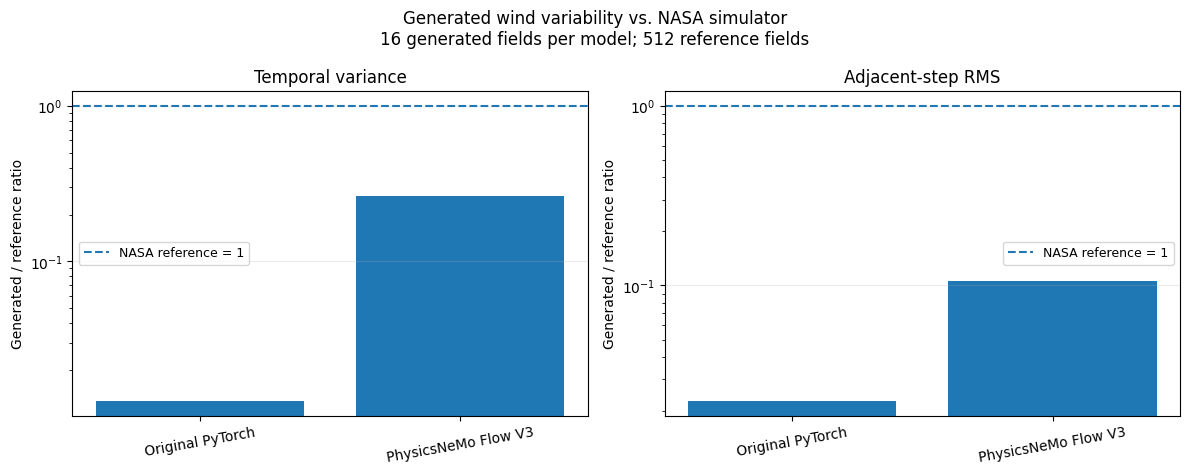

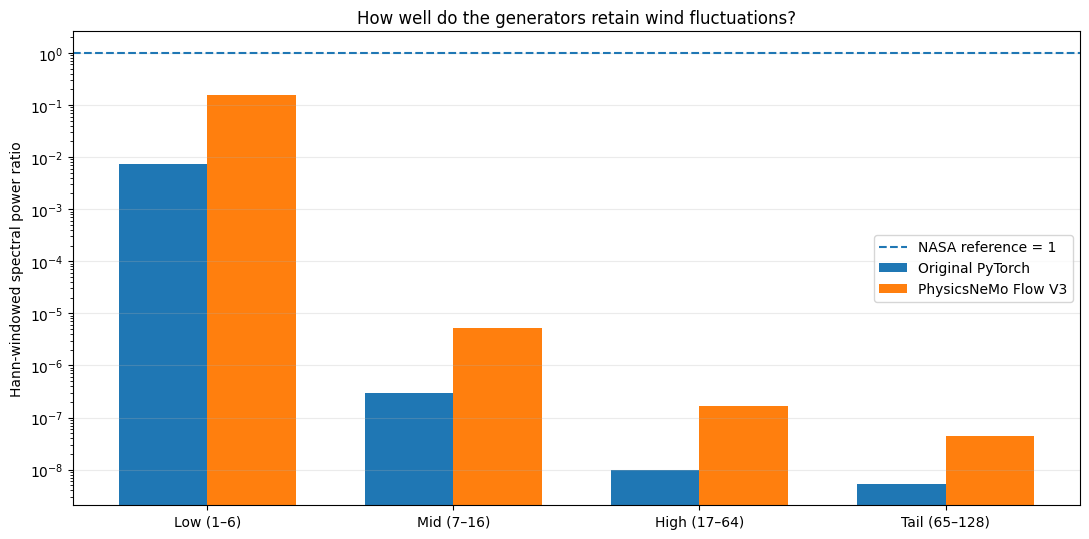

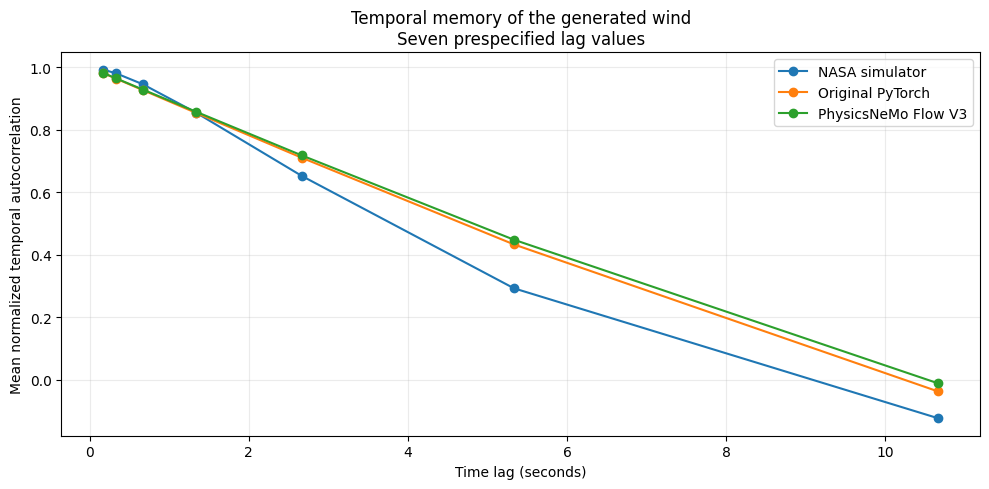

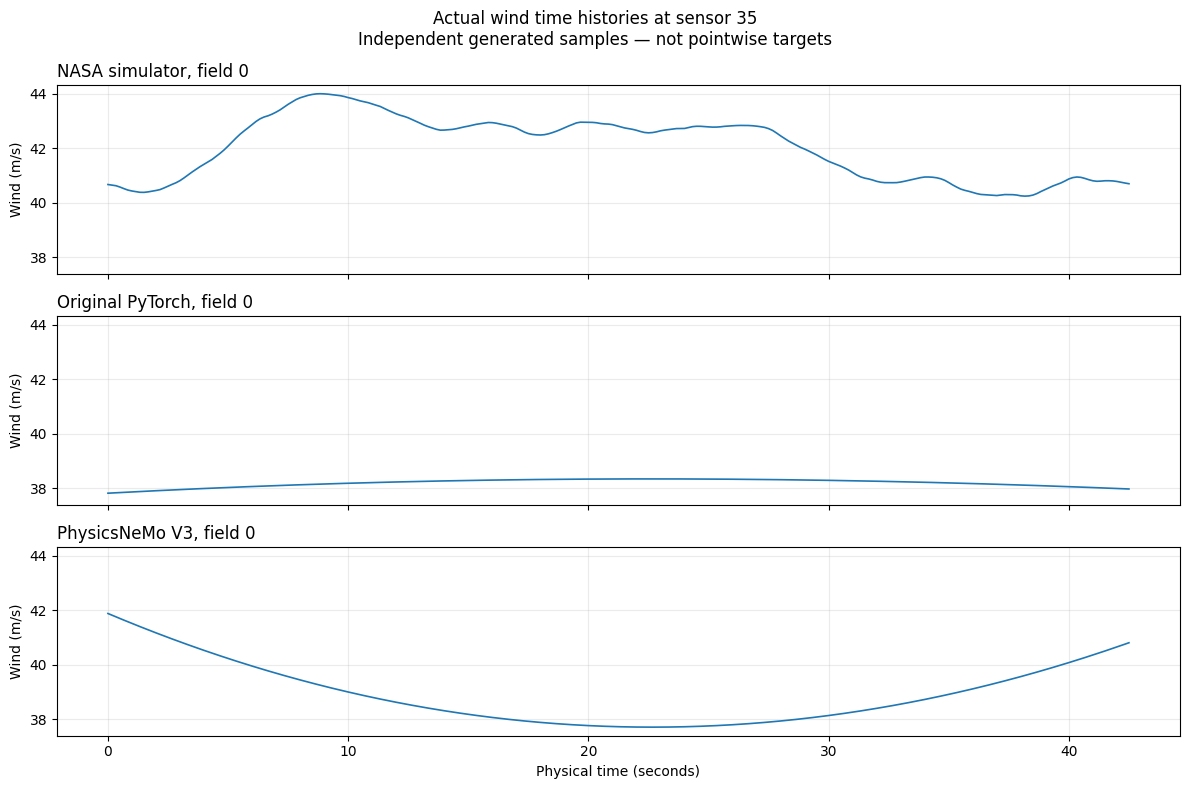

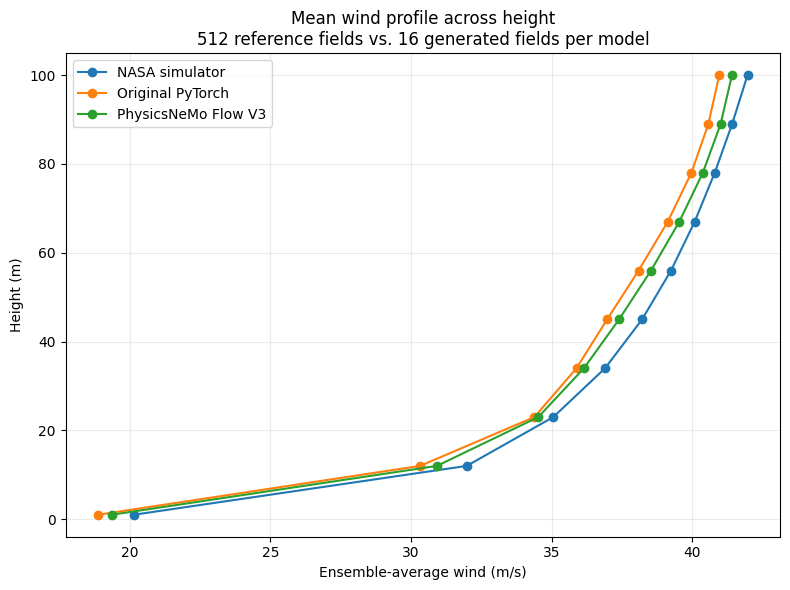


WIND VISION — CELL 4 QUALITY AUDIT COMPLETE

METHOD: NASA simulator
FIELDS: 512
TEMPORAL_VARIANCE: 3.2106091671086605
INTERIOR_STEP_RMS: 0.24172191085913014
BETWEEN_FIELD_ENERGY_CV: 5.4643907056251605e-09

METHOD: Original PyTorch
FIELDS: 16
TEMPORAL_VARIANCE: 0.04069438312235011
INTERIOR_STEP_RMS: 0.005506339212823038
BETWEEN_FIELD_ENERGY_CV: 0.27940297119515634
VARIANCE_RATIO_TO_REFERENCE: 0.01267497256883427
STEP_RMS_RATIO_TO_REFERENCE: 0.022779644564501243
SPATIAL_CORRELATION_MAE: 0.1105702742934227
BOOTSTRAP_95_CI: {'variance_ratio_ci95': [0.011061912441626564, 0.014432311022115271], 'step_rms_ratio_ci95': [0.021486944981420567, 0.02404745747471428]}

METHOD: PhysicsNeMo Flow V3
FIELDS: 16
TEMPORAL_VARIANCE: 0.8395262418283334
INTERIOR_STEP_RMS: 0.025731396433722475
BETWEEN_FIELD_ENERGY_CV: 0.667064686277877
VARIANCE_RATIO_TO_REFERENCE: 0.2614850323200115
STEP_RMS_RATIO_TO_REFERENCE: 0.1064504096557392
SPATIAL_CORRELATION_MAE: 0.11290612071752548
BOOTSTRAP_95_CI: {'variance_ratio

In [ ]:

# ======================================================================
# WIND VISION — FINAL COMPLETION / CELL 4
# W1 + W3: PHYSICAL-QUALITY DIAGNOSTIC FROM FROZEN GENERATION
#
# Compares:
#   A: 512 original NASA simulator fields (reference distribution)
#   B: 16 new original NASA E49 generator fields (Cell 3)
#   C: 16 new PhysicsNeMo Flow V3 fields (Cell 2)
#
# This is descriptive evaluation, NOT a new blinded test.
# No model training, tuning, sampling, or checkpoint changes.
# ======================================================================

from pathlib import Path
import hashlib
import json
import os
import numpy as np
import h5py
import matplotlib.pyplot as plt

BASE = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction/evidence"
)

FULL = BASE / "fullscale_physicsnemo_training"
RUN = FULL / "final_completion_20261108_v1"

REF = (
    BASE /
    "w1_e44_phase_only_generators_20261104/"
    "new_nasa_wind_seed_440044_512.hdf5"
)

REF_VALIDATION = REF.parent / "validation.json"

NATIVE = (
    RUN / "cell02_native_fresh_generation_v1/"
    "generated_wind_16_v1.npz"
)

ORIGINAL = (
    RUN / "cell03_original_nasa_fresh_generation_v1/"
    "original_nasa_wind_16_v1.npz"
)

OUT = RUN / "cell04_physical_quality_audit_v1"

EXPECTED = {
    NATIVE:
        "99510549008427f0e95f5a399321f5f9317e56697581a11fddd9219ab57a69df",

    ORIGINAL:
        "3d96f0eab540dd07c6cb2e0f2590f1e4491f1538d8b541e7e568ff71bbf1156c"
}

LAGS = np.array([1, 2, 4, 8, 16, 32, 64])

BANDS = {
    "Low (1–6)": (1, 7),
    "Mid (7–16)": (7, 17),
    "High (17–64)": (17, 65),
    "Tail (65–128)": (65, 129)
}

BOOTSTRAPS = 3000
SEED = 490804


def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(
            lambda: f.read(8 * 1024 * 1024),
            b""
        ):
            h.update(block)
    return h.hexdigest()


print("=" * 72)
print("WIND VISION — CELL 4 PHYSICAL QUALITY AUDIT")
print("=" * 72, flush=True)

assert torch.cuda.is_available()

assert REF.is_file()
assert REF_VALIDATION.is_file()

validation = json.loads(
    REF_VALIDATION.read_text()
)

assert (
    sha256(REF) == validation["new_holdout_sha256"]
), "Reference dataset identity mismatch."

for path, expected in EXPECTED.items():
    assert path.is_file()
    assert sha256(path) == expected

print("REFERENCE_DATASET: SHA256 VERIFIED")
print("CELL02_NATIVE_FIELDS: SHA256 VERIFIED")
print("CELL03_ORIGINAL_FIELDS: SHA256 VERIFIED")

# ----------------------------------------------------------------------
# Load the original NASA simulator fields.
# ----------------------------------------------------------------------

with h5py.File(REF, "r") as h:
    assert len(h["wind_samples"]) == 512

    xyz = np.asarray(
        h["x_grid"],
        dtype=np.float32
    )

    times = np.asarray(
        h["t_grid"],
        dtype=np.float32
    )

    reference = np.stack([
        np.asarray(
            h["wind_samples"][str(i)]["v1"],
            dtype=np.float32
        )
        for i in range(512)
    ])

assert reference.shape == (512, 100, 256)
assert xyz.shape == (100, 3)
assert times.shape == (256,)

# ----------------------------------------------------------------------
# Load already-generated original and PhysicsNeMo wind fields.
# ----------------------------------------------------------------------

with np.load(ORIGINAL, allow_pickle=False) as p:
    original = p["wind_mps"].copy()
    original_noise = p["gaussian_noise"].copy()

    assert np.allclose(
        p["xyz"],
        xyz,
        atol=1e-5,
        rtol=0
    )

    assert np.allclose(
        p["t_grid"],
        times,
        atol=1e-5,
        rtol=0
    )

with np.load(NATIVE, allow_pickle=False) as p:
    native = p["wind_mps"].copy()
    native_noise = p["initial_gaussian_noise"].copy()

    assert np.allclose(
        p["xyz"],
        xyz,
        atol=1e-5,
        rtol=0
    )

    assert np.allclose(
        p["t_grid"],
        times,
        atol=1e-5,
        rtol=0
    )

assert original.shape == native.shape == (16, 100, 256)
assert np.array_equal(original_noise, native_noise)

assert np.isfinite(reference).all()
assert np.isfinite(original).all()
assert np.isfinite(native).all()

print("REFERENCE_FIELDS:", len(reference))
print("ORIGINAL_GENERATED_FIELDS:", len(original))
print("PHYSICSNEMO_GENERATED_FIELDS:", len(native))
print("SAME_GENERATOR_INPUT_NOISE: VERIFIED")

# ----------------------------------------------------------------------
# Feature extraction: separate temporal, spectral and spatial metrics.
# ----------------------------------------------------------------------

def extract_features(u):
    v = np.asarray(u, dtype=np.float64)

    assert v.ndim == 3
    assert v.shape[1:] == (100, 256)

    centered = v - v.mean(axis=-1, keepdims=True)

    per_field_variance = np.mean(
        centered**2,
        axis=(1, 2)
    )

    differences = np.diff(v, axis=-1)

    per_field_step_squared = np.mean(
        differences**2,
        axis=(1, 2)
    )

    # Hann window reduces artificial periodic endpoint leakage.
    # Ratios use exactly the same estimator and normalization.
    window = np.hanning(256)

    transformed = np.fft.rfft(
        centered * window,
        axis=-1
    )

    spectral_power = np.abs(transformed)**2

    bands = {
        name: float(
            spectral_power[..., lo:hi].mean()
        )
        for name, (lo, hi) in BANDS.items()
    }

    denominator = np.sum(
        centered**2,
        axis=-1
    ).clip(min=1e-12)

    acf = {}

    for lag in LAGS:
        numerator = np.sum(
            centered[..., :-lag]
            * centered[..., lag:],
            axis=-1
        )

        acf[str(lag)] = float(
            np.mean(numerator / denominator)
        )

    # Cross-location temporal correlation, across all fields.
    # This assesses spatial statistical structure;
    # it is not a three-component turbulence solver.
    flattened = centered.transpose(
        1, 0, 2
    ).reshape(100, -1).astype(np.float32)

    norms = np.sqrt(
        np.sum(flattened**2, axis=1, keepdims=True)
    ).clip(min=1e-12)

    normalized = flattened / norms

    spatial_corr = normalized @ normalized.T

    # Sample-specific vertical profile, then ensemble average.
    mean_at_sensor = v.mean(axis=(0, 2))

    return {
        "fields": len(v),
        "mean_mps": float(v.mean()),
        "min_mps": float(v.min()),
        "max_mps": float(v.max()),
        "temporal_variance": float(
            per_field_variance.mean()
        ),
        "step_rms": float(
            np.sqrt(per_field_step_squared.mean())
        ),
        "energy_cv": float(
            per_field_variance.std(ddof=1)
            / max(per_field_variance.mean(), 1e-12)
        ),
        "band_power": bands,
        "acf": acf,
        "spatial_corr": spatial_corr,
        "mean_at_sensor": mean_at_sensor,
        "per_field_variance": per_field_variance,
        "per_field_step_squared": per_field_step_squared
    }


stats = {
    "NASA simulator": extract_features(reference),
    "Original PyTorch": extract_features(original),
    "PhysicsNeMo Flow V3": extract_features(native)
}

ref = stats["NASA simulator"]

off_diag = ~np.eye(100, dtype=bool)

for name, result in stats.items():
    if name == "NASA simulator":
        continue

    result["spatial_correlation_mae"] = float(
        np.mean(
            np.abs(
                result["spatial_corr"]
                - ref["spatial_corr"]
            )[off_diag]
        )
    )

# ----------------------------------------------------------------------
# Independent-field bootstrap intervals.
# Generated n=16 is small, so intervals are descriptive and uncertain.
# ----------------------------------------------------------------------

rng = np.random.default_rng(SEED)

ridx = rng.integers(
    0, len(reference),
    size=(BOOTSTRAPS, len(reference))
)

ref_v_boot = ref["per_field_variance"][ridx].mean(axis=1)
ref_s_boot = ref["per_field_step_squared"][ridx].mean(axis=1)

intervals = {}

for name in ("Original PyTorch", "PhysicsNeMo Flow V3"):
    s = stats[name]

    gidx = rng.integers(
        0, s["fields"],
        size=(BOOTSTRAPS, s["fields"])
    )

    variance_ratios = (
        s["per_field_variance"][gidx].mean(axis=1)
        / ref_v_boot
    )

    step_ratios = np.sqrt(
        s["per_field_step_squared"][gidx].mean(axis=1)
        / ref_s_boot
    )

    intervals[name] = {
        "variance_ratio_ci95": np.quantile(
            variance_ratios, [0.025, 0.975]
        ).tolist(),

        "step_rms_ratio_ci95": np.quantile(
            step_ratios, [0.025, 0.975]
        ).tolist()
    }

# ----------------------------------------------------------------------
# Publication-readable figures.
# Fixed comparisons: no method selection or parameter tuning.
# ----------------------------------------------------------------------

assert not OUT.exists(), (
    "Audit directory already exists. Do not overwrite."
)

OUT.mkdir(parents=True)

methods = ("Original PyTorch", "PhysicsNeMo Flow V3")

# Figure 1 — Physical variability ratios.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

variances = [
    stats[n]["temporal_variance"]
    / ref["temporal_variance"]
    for n in methods
]

steps = [
    stats[n]["step_rms"]
    / ref["step_rms"]
    for n in methods
]

for ax, values, heading in [
    (axes[0], variances, "Temporal variance"),
    (axes[1], steps, "Adjacent-step RMS")
]:
    ax.bar(range(2), values)
    ax.axhline(
        1.0,
        linestyle="--",
        linewidth=1.5,
        label="NASA reference = 1"
    )
    ax.set_xticks(range(2), methods, rotation=10)
    ax.set_yscale("log")
    ax.set_ylabel("Generated / reference ratio")
    ax.set_title(heading)
    ax.legend(fontsize=9)
    ax.grid(axis="y", alpha=0.25)

fig.suptitle(
    "Generated wind variability vs. NASA simulator\n"
    "16 generated fields per model; 512 reference fields"
)

fig.tight_layout()

fig.savefig(
    OUT / "01_temporal_variability.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# Figure 2 — Frequency-band power ratios.
band_names = list(BANDS)
x = np.arange(len(band_names))
width = 0.36

fig, ax = plt.subplots(figsize=(11, 5.5))

for j, name in enumerate(methods):
    ratios = [
        stats[name]["band_power"][b]
        / ref["band_power"][b]
        for b in band_names
    ]

    ax.bar(
        x + (j - 0.5) * width,
        ratios,
        width,
        label=name
    )

ax.axhline(
    1.0,
    linestyle="--",
    label="NASA reference = 1"
)

ax.set_xticks(x, band_names)
ax.set_yscale("log")
ax.set_ylabel("Hann-windowed spectral power ratio")
ax.set_title(
    "How well do the generators retain wind fluctuations?"
)
ax.legend()
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(
    OUT / "02_hann_frequency_bands.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# Figure 3 — Temporal autocorrelation.
dt = float(np.median(np.diff(times)))

fig, ax = plt.subplots(figsize=(10, 5))

for name in stats:
    ax.plot(
        LAGS * dt,
        [stats[name]["acf"][str(l)] for l in LAGS],
        marker="o",
        label=name
    )

ax.set_xlabel("Time lag (seconds)")
ax.set_ylabel("Mean normalized temporal autocorrelation")
ax.set_title(
    "Temporal memory of the generated wind\n"
    "Seven prespecified lag values"
)
ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()
fig.savefig(
    OUT / "03_temporal_autocorrelation.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# Figure 4 — Prespecified, independent example histories.
# These are independent draws, not paired target predictions.
SENSOR = 35
FIELD = 0

fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 8),
    sharex=True,
    sharey=True
)

examples = [
    ("NASA simulator, field 0", reference[FIELD, SENSOR]),
    ("Original PyTorch, field 0", original[FIELD, SENSOR]),
    ("PhysicsNeMo V3, field 0", native[FIELD, SENSOR])
]

for ax, (name, series) in zip(axes, examples):
    ax.plot(times, series, linewidth=1.2)
    ax.set_title(name, loc="left")
    ax.set_ylabel("Wind (m/s)")
    ax.grid(alpha=0.25)

axes[-1].set_xlabel("Physical time (seconds)")

fig.suptitle(
    "Actual wind time histories at sensor 35\n"
    "Independent generated samples — not pointwise targets"
)

fig.tight_layout()
fig.savefig(
    OUT / "04_independent_wind_histories.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# Figure 5 — Vertical mean profile.
height = xyz[:, 2]
heights = np.unique(height)

fig, ax = plt.subplots(figsize=(8, 6))

for name in stats:
    profile = []

    for h in heights:
        mask = np.isclose(height, h)

        profile.append(
            stats[name]["mean_at_sensor"][mask].mean()
        )

    ax.plot(
        profile,
        heights,
        marker="o",
        label=name
    )

ax.set_xlabel("Ensemble-average wind (m/s)")
ax.set_ylabel("Height (m)")
ax.set_title(
    "Mean wind profile across height\n"
    "512 reference fields vs. 16 generated fields per model"
)
ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()
fig.savefig(
    OUT / "05_vertical_mean_profiles.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ----------------------------------------------------------------------
# Save an auditable report without the large intermediate arrays.
# ----------------------------------------------------------------------

def serialize(name, value):
    return {
        "fields": value["fields"],
        "mean_mps": value["mean_mps"],
        "range_mps": [
            value["min_mps"], value["max_mps"]
        ],
        "temporal_variance": value["temporal_variance"],
        "step_rms": value["step_rms"],
        "energy_cv": value["energy_cv"],
        "band_power": value["band_power"],
        "acf": value["acf"],
        "spatial_correlation_mae":
            value.get("spatial_correlation_mae")
    }


report = {
    "format": "wind_vision_cell04_quality_audit_v1",
    "purpose": "Descriptive generated-distribution comparison",
    "not_blinded_confirmatory_test": True,
    "reference_previously_used_for_development": True,
    "reference_fields": 512,
    "generated_fields_per_method": 16,
    "reference_sha256": sha256(REF),
    "native_archive_sha256": sha256(NATIVE),
    "original_archive_sha256": sha256(ORIGINAL),
    "methods": {
        name: serialize(name, value)
        for name, value in stats.items()
    },
    "bootstrap": {
        "seed": SEED,
        "replicates": BOOTSTRAPS,
        "resampling_unit": "Complete simulated field",
        "ratios_ci95": intervals
    },
    "limitations": [
        "Only 16 new samples per generator.",
        "Reference E44 data were previously used in research.",
        "Different trained models; not a framework parity test.",
        "No parameter tuning or model selection performed."
    ]
}

report_path = OUT / "quality_report_v1.json"

report_path.write_text(
    json.dumps(
        report,
        indent=2,
        sort_keys=True,
        allow_nan=False
    ) + "\n"
)

print("\n" + "=" * 72)
print("WIND VISION — CELL 4 QUALITY AUDIT COMPLETE")
print("=" * 72)

for name, s in stats.items():
    print("\nMETHOD:", name)
    print("FIELDS:", s["fields"])
    print("TEMPORAL_VARIANCE:", s["temporal_variance"])
    print("INTERIOR_STEP_RMS:", s["step_rms"])
    print("BETWEEN_FIELD_ENERGY_CV:", s["energy_cv"])

    if name != "NASA simulator":
        print(
            "VARIANCE_RATIO_TO_REFERENCE:",
            s["temporal_variance"] / ref["temporal_variance"]
        )
        print(
            "STEP_RMS_RATIO_TO_REFERENCE:",
            s["step_rms"] / ref["step_rms"]
        )
        print(
            "SPATIAL_CORRELATION_MAE:",
            s["spatial_correlation_mae"]
        )
        print("BOOTSTRAP_95_CI:", intervals[name])

print("\nFIGURES_CREATED:", len(list(OUT.glob("*.png"))))
print("REPORT:", report_path)
print("REPORT_SHA256:", sha256(report_path))
print("NO_TRAINING: TRUE")
print("NO_NEW_GENERATION: TRUE")
print("NO_CHECKPOINT_MODIFICATION: TRUE")
print("FRAMEWORK_SPEEDUP_CLAIM: NONE")
print("=" * 72)


In [ ]:

# ================================================================
# WIND VISION — FINAL COMPLETION / CELL 5
# W2 + W4 EVIDENCE RECONCILIATION
#
# No training, sampling, checkpoint loading, or GPU benchmarks.
# Read-only source audit, plus one new immutable summary report.
# ================================================================

from pathlib import Path
import hashlib
import json
import platform
import importlib.metadata as md
import subprocess

PROJECT = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction"
)

E = PROJECT / "evidence"

FINAL = (
    E / "fullscale_physicsnemo_training/"
    "final_completion_20261108_v1"
)

OUT = FINAL / "cell05_parity_and_benchmark_evidence_v1"
REPORT = OUT / "evidence_reconciliation_v1.json"

PIN = "921e666c8d6060ae13bfd901dcc7f74f819d0eea"

SOURCES = {
    "historical_matched_two_arm_benchmark": (
        E / "gate3a_matched_baseline_l4/"
        "gate3a_l4_baseline_20261106T041649417203Z.json",
        "eec960baf462b3d4b2ecbdbfcb48dc3d8a44455bf9cdebbf7142219e2a7846ef"
    ),
    "historical_512_field_quality": (
        E / "gate3c_quality_512/"
        "gate3c_512_quality_20261106T045052299289Z.json",
        "d84daa586bfa4f7675bf1fb29e10f8b0266404befd2ee498623ded624eff533c"
    ),
    "native_448_field_flow_training": (
        E / "gate2f_physicsnemo_flow_448_seed490150/"
        "manifest.json",
        "7a94410c513cdcb61e9c43a0a56ef15c3f3f9c0d44825bc1d2407ce6e8706c79"
    ),
    "current_native_generation": (
        FINAL / "cell02_native_fresh_generation_v1/"
        "generation_report_v1.json",
        "dd826c459294a73531c6eeda0a7728112b989c93af7c9b471b864a3916f16a71"
    ),
    "current_original_generation": (
        FINAL / "cell03_original_nasa_fresh_generation_v1/"
        "original_nasa_report_v1.json",
        "06f5798b4829070ae028fde3247add7033d6b4ef324449d30eaf8b49c239e384"
    ),
    "current_physical_quality": (
        FINAL / "cell04_physical_quality_audit_v1/"
        "quality_report_v1.json",
        "f37b6a48fe03c43a296b9fea9adcee97027fa8d4ea18d5f537a3c1127484d5ca"
    )
}

def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(
            lambda: f.read(8 * 1024 * 1024),
            b""
        ):
            h.update(block)
    return h.hexdigest()

print("=" * 72)
print("WIND VISION — CELL 5 W2/W4 EVIDENCE RECONCILIATION")
print("=" * 72)

# Verify pinned public NASA source remains clean.
repo = Path("/content/nasa_clfm_reference")

head = subprocess.check_output(
    ["git", "-C", str(repo), "rev-parse", "HEAD"],
    text=True
).strip()

dirty = subprocess.check_output(
    ["git", "-C", str(repo), "status", "--porcelain"],
    text=True
).strip()

assert head == PIN
assert not dirty

print("NASA_SOURCE: VERIFIED AND CLEAN")

# Independently verify each existing report file.
loaded = {}
source_manifest = {}

for name, (path, expected) in SOURCES.items():
    assert path.is_file(), f"Missing report: {path}"

    actual = sha256(path)
    assert actual == expected, f"Hash mismatch: {name}"

    obj = json.loads(path.read_text())

    loaded[name] = obj
    source_manifest[name] = {
        "path": str(path),
        "sha256": actual
    }

    print("REPORT_VERIFIED:", name)

print("\nALL_SIX_REPORT_HASHES: VERIFIED")

# ------------------------------------------------------------
# Extract the historical matched two-arm L4 benchmark.
# This is a prior measurement, NOT a new runtime benchmark.
# ------------------------------------------------------------

historical = loaded[
    "historical_matched_two_arm_benchmark"
]

assert historical["source_commit"] == PIN

results = historical["results"]

timings = {}

print("\nHISTORICAL MATCHED L4 BENCHMARK")
print("Recorded torch:", historical.get("torch"))
print("Recorded PhysicsNeMo:", historical.get("physicsnemo"))
print("Recorded GPU:", historical.get("gpu"))

for test_name, record in results.items():
    if not isinstance(record, dict):
        continue

    if not all(
        k in record for k in ("pytorch", "physicsnemo")
    ):
        continue

    pt = record["pytorch"]
    pn = record["physicsnemo"]

    if not (
        isinstance(pt, dict)
        and isinstance(pn, dict)
        and "median_ms" in pt
        and "median_ms" in pn
    ):
        continue

    original_ms = float(pt["median_ms"])
    native_ms = float(pn["median_ms"])

    assert original_ms > 0
    assert native_ms > 0

    ratio = original_ms / native_ms

    timings[test_name] = {
        "original_pytorch_median_ms": original_ms,
        "unoptimized_physicsnemo_median_ms": native_ms,
        "pytorch_over_physicsnemo": ratio,
        "source": "Historical Gate 3A; not freshly measured"
    }

    print(
        f"{test_name}: "
        f"PyTorch={original_ms:.4f} ms | "
        f"PhysicsNeMo={native_ms:.4f} ms | "
        f"Ratio={ratio:.4f}x"
    )

assert len(timings) >= 3, (
    "Expected three matched benchmark categories."
)

# ------------------------------------------------------------
# Discover archived W2 numerical parity and W4 optimization
# results. Print file names and bounded structural summaries.
# No assumptions about whether a discovered report passed.
# ------------------------------------------------------------

print("\nDISCOVERING GATE 2 / GATE 3 EVIDENCE")

gate_dirs = sorted([
    p for p in E.iterdir()
    if p.is_dir()
    and p.name.lower().startswith(("gate2", "gate3"))
])

print("GATE_DIRECTORIES:", len(gate_dirs))

keywords = (
    "parity", "gradient", "benchmark",
    "gate2", "gate3", "timing",
    "optimization", "comparison",
    "result", "report", "manifest",
    "verification"
)

candidates = []

for directory in gate_dirs:
    for path in directory.rglob("*.json"):
        if any(
            word in path.name.lower()
            for word in keywords
        ):
            candidates.append(path)

candidates = sorted(set(candidates))

print("CANDIDATE_REPORTS:", len(candidates))

catalog = []

for path in candidates:
    relative = str(path.relative_to(E))

    entry = {
        "relative_path": relative,
        "size_bytes": path.stat().st_size,
        "sha256": sha256(path)
    }

    # Avoid printing huge JSON payloads or generated arrays.
    if path.stat().st_size <= 4 * 1024 * 1024:
        try:
            data = json.loads(path.read_text())

            if isinstance(data, dict):
                entry["top_level_keys"] = list(data)[:25]

                for key in (
                    "status", "gate", "purpose",
                    "all_passed", "parity_pass",
                    "optimizer_updates", "torch",
                    "physicsnemo"
                ):
                    value = data.get(key)

                    if isinstance(
                        value, (str, int, float, bool)
                    ):
                        entry[key] = value

        except Exception as exc:
            entry["read_error"] = repr(exc)

    catalog.append(entry)

for entry in catalog[:75]:
    print("\nFILE:", entry["relative_path"])
    for key in (
        "status", "gate", "purpose", "all_passed",
        "parity_pass", "optimizer_updates",
        "torch", "physicsnemo"
    ):
        if key in entry:
            print(" ", key, "=", entry[key])

    if "top_level_keys" in entry:
        print("  KEYS:", entry["top_level_keys"][:14])

if len(catalog) > 75:
    print(
        "\nADDITIONAL_REPORTS_NOT_PRINTED:",
        len(catalog) - 75
    )

# ------------------------------------------------------------
# Cross-check the contemporary successful generation reports.
# ------------------------------------------------------------

native = loaded["current_native_generation"]
original = loaded["current_original_generation"]
quality = loaded["current_physical_quality"]

assert native["shape"] == [16, 100, 256]
assert original["generated_shape"] == [16, 100, 256]
assert quality["generated_fields_per_method"] == 16
assert quality["reference_fields"] == 512

print("\nCURRENT GENERATOR EVIDENCE")
print("NATIVE_GENERATION: VERIFIED")
print("ORIGINAL_GENERATION: VERIFIED")
print("PHYSICAL_QUALITY_REPORT: VERIFIED")

# ------------------------------------------------------------
# Save summary under an entirely new folder, without
# modifying archived results or checkpoints.
# ------------------------------------------------------------

assert not OUT.exists(), (
    "This audit already exists. Do not overwrite it."
)

OUT.mkdir(parents=True)

summary = {
    "format": "wind_vision_w2_w4_evidence_reconciliation_v1",
    "pinned_nasa_commit": PIN,
    "audited_runtime": {
        "python": platform.python_version(),
        "torch": md.version("torch"),
        "physicsnemo": md.version("nvidia-physicsnemo")
    },
    "verified_source_reports": source_manifest,
    "historical_two_arm_timing_comparison": timings,
    "gate2_gate3_report_catalog": catalog,
    "current_generation_demonstrated": True,
    "physical_fidelity_accepted": False,
    "historical_benchmark_not_fresh_measurement": True,
    "optimized_four_arm_pass_not_established": True,
    "historical_parity_requires_evidence_review": True,
    "notes": [
        "A framework wrapper using original PyTorch operators "
        "does not demonstrate framework-only acceleration.",
        "The historical benchmark and today's runtime have "
        "different recorded environments.",
        "Do not infer parity from successful model execution.",
        "No additional model selection or training performed."
    ]
}

assert not REPORT.exists()

REPORT.write_text(
    json.dumps(
        summary,
        indent=2,
        sort_keys=True,
        allow_nan=False
    ) + "\n",
    encoding="utf-8"
)

print("\n" + "=" * 72)
print("WIND VISION — CELL 5 EVIDENCE AUDIT COMPLETE")
print("=" * 72)
print("HISTORICAL_TWO_ARM_TESTS_FOUND:", len(timings))
print("PARITY_AND_OPTIMIZATION_REPORTS_FOUND:", len(catalog))
print("REPORT:", REPORT)
print("REPORT_SHA256:", sha256(REPORT))
print("NO_TRAINING: TRUE")
print("NO_NEW_BENCHMARK: TRUE")
print("ORIGINAL_EVIDENCE_UNMODIFIED: TRUE")
print("=" * 72)


WIND VISION — CELL 5 W2/W4 EVIDENCE RECONCILIATION
NASA_SOURCE: VERIFIED AND CLEAN
REPORT_VERIFIED: historical_matched_two_arm_benchmark
REPORT_VERIFIED: historical_512_field_quality
REPORT_VERIFIED: native_448_field_flow_training
REPORT_VERIFIED: current_native_generation
REPORT_VERIFIED: current_original_generation
REPORT_VERIFIED: current_physical_quality

ALL_SIX_REPORT_HASHES: VERIFIED

HISTORICAL MATCHED L4 BENCHMARK
Recorded torch: 2.11.0+cu130
Recorded PhysicsNeMo: 2.1.0
Recorded GPU: NVIDIA L4
vae_full_optimizer_step: PyTorch=280.9267 ms | PhysicsNeMo=278.3145 ms | Ratio=1.0094x
flow_full_optimizer_step: PyTorch=2.5622 ms | PhysicsNeMo=2.5770 ms | Ratio=0.9942x
full_generation_8x100x256: PyTorch=77.8265 ms | PhysicsNeMo=81.3013 ms | Ratio=0.9573x
ode_only: PyTorch=64.8350 ms | PhysicsNeMo=64.3605 ms | Ratio=1.0074x
decoder_only: PyTorch=12.7392 ms | PhysicsNeMo=16.8863 ms | Ratio=0.7544x

DISCOVERING GATE 2 / GATE 3 EVIDENCE
GATE_DIRECTORIES: 3
CANDIDATE_REPORTS: 3

FILE: gate

In [ ]:

# ================================================================
# WIND VISION — FINAL COMPLETION / CELL 6
# W2: FRESH MATHEMATICAL PARITY ON CURRENT L4 RUNTIME
#
# Original E32 VAE vs equivalent PhysicsNeMo VAE
# Original E49 FlowModel vs equivalent PhysicsNeMo flow
#
# No production training, no saved checkpoint changes.
# Only temporary, matched numerical optimizer updates.
# ================================================================

from pathlib import Path
import hashlib, json, os, sys, copy, platform
import numpy as np
import h5py
import torch
import torch.nn.functional as F

PROJECT = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction"
)
E = PROJECT / "evidence"
REPO = Path("/content/nasa_clfm_reference")
MODEL_DIR = Path("/content/wind_vision_fullscale/models")

VAE_FILE = (
    E / "w1_e32_20261104T040902726350Z/"
    "checkpoints/last.ckpt"
)
FLOW_FILE = (
    E / "w1_e49_matched_e32_flow100_20261104/"
    "matched_flow_final.pth"
)
TRAIN = (
    E / "w1_e54_vae_training_ablation_20261104/"
    "inputs/W1_E54_TRAIN_ONLY_512_SEED_540054.hdf5"
)
OUT = (
    E / "fullscale_physicsnemo_training/"
    "final_completion_20261108_v1/"
    "cell06_current_runtime_parity_v1"
)
REPORT = OUT / "mathematical_parity_v1.json"

EXPECTED = {
    VAE_FILE:
        "bb8457f5650536966e82916aac197726df0089f061b0c18ed6c980a62d6aa9c5",
    FLOW_FILE:
        "6d7ab8117dabad90232beaf55a7d4d345d376f268a22ffe9830559fcc4a9df97",
    TRAIN:
        "a3c424b15b96a76171c29dd9b2cb9d033fd85c7a5d58c07a28d6f9816542f1d4"
}

def sha(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(
            lambda: f.read(8 * 1024 * 1024),
            b""
        ):
            h.update(block)
    return h.hexdigest()

print("=" * 72)
print("WIND VISION — CELL 6 MATHEMATICAL PARITY")
print("=" * 72)

assert torch.cuda.is_available()
assert torch.__version__ == "2.14.1+cu130"
assert not OUT.exists(), "Cell 6 evidence already exists."

for path, digest in EXPECTED.items():
    assert path.is_file() and sha(path) == digest, path

print("ORIGINAL_SOURCES_AND_TRAINING_SUBSET: VERIFIED")

for path in (str(REPO), str(MODEL_DIR)):
    if path not in sys.path:
        sys.path.insert(0, path)

from clfm.nn.vae import FunctionalVAE
from clfm.nn.fully_connected_nets import FlowModel
from clfm.utils import kl_divergence
from models import PhysicsNeMoWindVAE, PhysicsNeMoWindFlow

torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.backends.cudnn.benchmark = False

device = "cuda"
torch.manual_seed(490806)
torch.cuda.manual_seed_all(490806)

# ----------------------------------------------------------------
# A. Original NASA VAE and same-weight PhysicsNeMo construction.
# ----------------------------------------------------------------

reference = FunctionalVAE.load_from_checkpoint(
    str(VAE_FILE),
    map_location="cpu",
    weights_only=False,
    strict=True
).to(device).train()

with h5py.File(TRAIN, "r") as h:
    xyz = h["x_grid"][:].astype("float32")
    times = h["t_grid"][:].astype("float32")
    raw = np.stack([
        h["wind_samples"][str(i)]["v1"][:]
        for i in range(2)
    ]).astype("float32")

obs = np.r_[0:10, 30:40, 60:70, 90:100]

assert raw.shape == (2, 100, 256)
assert xyz.shape == (100, 3)
assert times.shape == (256,)

u = torch.from_numpy(
    np.ascontiguousarray((raw[:, obs, :] + 2) / 49)
).to(device)

coords = np.concatenate([
    np.broadcast_to(
        xyz[obs, None, :], (40, 256, 3)
    ),
    np.broadcast_to(
        times[None, :, None], (40, 256, 1)
    )
], axis=-1).reshape(10240, 4).copy()

x = torch.from_numpy(coords).to(device)
x = x.unsqueeze(0).expand(2, -1, -1)

cfg = {
    "grid_low": reference.grid.low.detach().cpu().tolist(),
    "grid_high": reference.grid.high.detach().cpu().tolist(),
    "time_grid": times.tolist(),
    "sensor_indices": obs.tolist(),
    "num_colloc": int(reference.loss.num_colloc),
    "T_colloc": int(reference.loss.T),
    "sensor_count": 40,
    "latent_dim": 128,
    "branch_hidden":
        int(reference._branch.input_proj.out_features),
    "interaction_dim":
        int(reference._branch.output_proj.out_features),
    "branch_blocks": len(reference._branch.blocks),
    "trunk_hidden":
        int(reference._trunk.hidden_size),
    "trunk_layers":
        int(reference._trunk.num_hidden_layers),
    "output_fields":
        int(reference._trunk.num_outputs),
    "learning_rate": float(reference.lr),
    "residual_weight": float(reference.res_weight),
    "kld_weight": float(reference.kld_weight)
}

native = PhysicsNeMoWindVAE(cfg).to(device).train()

# Strict state transfer detects architecture/key incompatibility.
native.load_state_dict(reference.state_dict(), strict=True)

ref_params = dict(reference.named_parameters())
nat_params = dict(native.named_parameters())

assert set(ref_params) == set(nat_params)
assert len(ref_params) == 164

print("VAE_WEIGHT_TRANSFER: STRICT PASS")
print("VAE_PARAMETER_TENSORS:", len(ref_params))

def vae_objective(model, epsilon):
    mu, lv = model.encode(u)
    z = mu + torch.exp(0.5 * lv) * epsilon

    reconstruction = model.loss.reconstruction(
        model, z, x, u
    )
    residual, _ = model.loss.residual(model, z)
    kl = kl_divergence(mu, lv)

    total = (
        reconstruction
        + model.kld_weight * kl
        + model.res_weight * residual
    )

    return total, {
        "reconstruction": float(reconstruction.detach()),
        "kl": float(kl.detach()),
        "coherence": float(residual.detach()),
        "total": float(total.detach())
    }

def gradient_relative_error(a, b):
    numerator = 0.0
    denominator = 0.0
    max_absolute = 0.0

    for name in a:
        ga = a[name].grad
        gb = b[name].grad
        assert ga is not None and gb is not None
        assert torch.isfinite(ga).all()
        assert torch.isfinite(gb).all()

        delta = (ga.detach() - gb.detach()).double()
        numerator += float(torch.sum(delta * delta))
        denominator += float(
            torch.sum(ga.detach().double() ** 2)
        )
        max_absolute = max(
            max_absolute, float(delta.abs().max())
        )

    return {
        "relative_l2": (
            numerator ** 0.5 / max(denominator ** 0.5, 1e-15)
        ),
        "max_absolute": max_absolute
    }

def parameter_relative_error(a, b):
    numerator, denominator = 0.0, 0.0
    for name in a:
        p = a[name].detach().double()
        q = b[name].detach().double()
        numerator += float(((p - q)**2).sum())
        denominator += float((p**2).sum())
    return numerator**0.5 / max(denominator**0.5, 1e-15)

va = torch.optim.Adam(reference.parameters(), lr=5e-4)
vb = torch.optim.Adam(native.parameters(), lr=5e-4)

vae_history = []
gen = torch.Generator(device="cpu").manual_seed(490807)

for step in range(4):
    epsilon = torch.randn(
        2, 128, generator=gen
    ).to(device)

    va.zero_grad(set_to_none=True)
    vb.zero_grad(set_to_none=True)

    # Reset the same collocation random state for both arms.
    torch.manual_seed(490810 + step)
    torch.cuda.manual_seed_all(490810 + step)
    loss_a, parts_a = vae_objective(reference, epsilon)

    torch.manual_seed(490810 + step)
    torch.cuda.manual_seed_all(490810 + step)
    loss_b, parts_b = vae_objective(native, epsilon)

    loss_a.backward()
    loss_b.backward()

    ge = gradient_relative_error(
        dict(reference.named_parameters()),
        dict(native.named_parameters())
    )

    for key in parts_a:
        assert np.isclose(
            parts_a[key], parts_b[key],
            rtol=2e-5, atol=2e-7
        ), f"VAE {key} mismatch at step {step}"

    assert ge["relative_l2"] < 2e-5, (
        f"VAE gradient parity failed at step {step}: {ge}"
    )

    torch.nn.utils.clip_grad_norm_(
        reference.parameters(), 0.5
    )
    torch.nn.utils.clip_grad_norm_(
        native.parameters(), 0.5
    )

    va.step()
    vb.step()

    pe = parameter_relative_error(
        dict(reference.named_parameters()),
        dict(native.named_parameters())
    )

    assert pe < 2e-5, (
        f"VAE optimizer parity failed at step {step}"
    )

    record = {
        "step": step + 1,
        "reference_losses": parts_a,
        "native_losses": parts_b,
        "gradient": ge,
        "parameter_relative_l2": pe
    }
    vae_history.append(record)

    print(
        "VAE_STEP", step + 1,
        "LOSS", parts_a["total"],
        "GRAD_REL_L2", ge["relative_l2"],
        "PARAM_REL_L2", pe,
        flush=True
    )

print("VAE_FULL_OBJECTIVE_AND_FOUR_UPDATES: PASS")

# ----------------------------------------------------------------
# B. Original NASA flow vs same-weight PhysicsNeMo flow.
# ----------------------------------------------------------------

saved_flow = torch.load(
    FLOW_FILE, map_location="cpu", weights_only=True
)

assert saved_flow["provenance"]["vae_sha256"] == EXPECTED[VAE_FILE]
arch = saved_flow["architecture"]

flow_ref = FlowModel(
    latent_dim=128,
    hidden_size=512,
    num_hidden_layers=5
).to(device).train()

flow_ref.load_state_dict(saved_flow["state_dict"], strict=True)

fcfg = {
    "latent_dim": 128,
    "hidden_size": 512,
    "num_hidden_layers": 5,
    "z_mean": arch["z_mean"],
    "z_std": arch["z_std"]
}

flow_native = PhysicsNeMoWindFlow(
    fcfg
).to(device).train()

flow_native.load_state_dict(
    saved_flow["state_dict"], strict=True
)

fa = torch.optim.Adam(flow_ref.parameters(), lr=1e-4)
fb = torch.optim.Adam(flow_native.parameters(), lr=1e-4)

rng = torch.Generator(device="cpu").manual_seed(490808)

flow_history = []

for step in range(3):
    z0 = torch.randn(8, 128, generator=rng).to(device)
    z1 = torch.randn(8, 128, generator=rng).to(device)
    t = torch.rand(8, 1, generator=rng).to(device)
    jitter = torch.randn(8, 128, generator=rng).to(device)

    bridge = (
        (1 - t) * z0 + t * z1 + 1e-4 * jitter
    )
    target = z1 - z0

    fa.zero_grad(set_to_none=True)
    fb.zero_grad(set_to_none=True)

    y_ref = flow_ref(
        torch.cat([bridge, t], dim=1)
    )
    y_native = flow_native(bridge, t)

    loss_ref = F.mse_loss(y_ref, target)
    loss_native = F.mse_loss(y_native, target)

    loss_ref.backward()
    loss_native.backward()

    ge = gradient_relative_error(
        dict(flow_ref.named_parameters()),
        dict(flow_native.named_parameters())
    )

    assert torch.allclose(
        y_ref, y_native, rtol=2e-6, atol=2e-7
    )
    assert torch.allclose(
        loss_ref, loss_native, rtol=2e-6, atol=2e-8
    )
    assert ge["relative_l2"] < 2e-5

    torch.nn.utils.clip_grad_norm_(
        flow_ref.parameters(), 1.0
    )
    torch.nn.utils.clip_grad_norm_(
        flow_native.parameters(), 1.0
    )

    fa.step()
    fb.step()

    pe = parameter_relative_error(
        dict(flow_ref.named_parameters()),
        dict(flow_native.named_parameters())
    )
    assert pe < 2e-5

    flow_history.append({
        "step": step + 1,
        "loss": float(loss_ref.detach()),
        "gradient": ge,
        "parameter_relative_l2": pe
    })

    print(
        "FLOW_STEP", step + 1,
        "LOSS", float(loss_ref.detach()),
        "GRAD_REL_L2", ge["relative_l2"],
        "PARAM_REL_L2", pe,
        flush=True
    )

print("FLOW_OBJECTIVE_AND_THREE_UPDATES: PASS")

# ----------------------------------------------------------------
# C. Preserve new evidence without overwriting any prior research.
# ----------------------------------------------------------------

assert not OUT.exists()
OUT.mkdir(parents=True)

report = {
    "format": "wind_vision_current_runtime_parity_v1",
    "purpose": "W2 same-weights numerical equivalence",
    "runtime": {
        "python": platform.python_version(),
        "torch": torch.__version__,
        "gpu": torch.cuda.get_device_name(0)
    },
    "sources": {
        str(path): sha(path) for path in EXPECTED
    },
    "vae": {
        "state_transfer": "strict",
        "gradient_tensors": len(ref_params),
        "optimizer_updates": 4,
        "tolerance_relative_l2": 2e-5,
        "history": vae_history
    },
    "flow": {
        "state_transfer": "strict",
        "optimizer_updates": 3,
        "tolerance_relative_l2": 2e-5,
        "history": flow_history
    },
    "all_tested_parity_checks_passed": True,
    "full_training_reproduced": False,
    "benchmark_performed": False,
    "production_checkpoints_modified": False,
    "note": (
        "Parity on fixed small training-origin inputs. "
        "This verifies equivalent computations under the "
        "tested settings, not independently converged training "
        "or general physical fidelity."
    )
}

REPORT.write_text(
    json.dumps(
        report, indent=2, sort_keys=True, allow_nan=False
    ) + "\n"
)

for path, digest in EXPECTED.items():
    assert sha(path) == digest

print("\n" + "=" * 72)
print("WIND VISION — CELL 6 CURRENT RUNTIME PARITY COMPLETE")
print("=" * 72)
print("VAE_STRICT_WEIGHT_TRANSFER: PASS")
print("VAE_LOSS_AND_GRADIENT_PARITY: PASS")
print("VAE_FOUR_OPTIMIZER_UPDATES: PASS")
print("FLOW_STRICT_WEIGHT_TRANSFER: PASS")
print("FLOW_LOSS_AND_GRADIENT_PARITY: PASS")
print("FLOW_THREE_OPTIMIZER_UPDATES: PASS")
print("REPORT:", REPORT)
print("REPORT_SHA256:", sha(REPORT))
print("ORIGINAL_CHECKPOINTS_UNMODIFIED: TRUE")
print("FULL_TRAINING_NOT_REPEATED: TRUE")
print("=" * 72)


WIND VISION — CELL 6 MATHEMATICAL PARITY
ORIGINAL_SOURCES_AND_TRAINING_SUBSET: VERIFIED
VAE_WEIGHT_TRANSFER: STRICT PASS
VAE_PARAMETER_TENSORS: 164


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'encoder' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['encoder'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'branch' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['branch'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'trunk' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['trunk'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'grid' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them usin

VAE_STEP 1 LOSS 0.009128795936703682 GRAD_REL_L2 0.0 PARAM_REL_L2 0.0
VAE_STEP 2 LOSS 0.0052843159064650536 GRAD_REL_L2 0.0 PARAM_REL_L2 0.0
VAE_STEP 3 LOSS 0.006683386396616697 GRAD_REL_L2 0.0 PARAM_REL_L2 0.0
VAE_STEP 4 LOSS 0.0036971240770071745 GRAD_REL_L2 0.0 PARAM_REL_L2 0.0
VAE_FULL_OBJECTIVE_AND_FOUR_UPDATES: PASS
FLOW_STEP 1 LOSS 1.6733572483062744 GRAD_REL_L2 0.0 PARAM_REL_L2 0.0
FLOW_STEP 2 LOSS 1.9941515922546387 GRAD_REL_L2 0.0 PARAM_REL_L2 0.0
FLOW_STEP 3 LOSS 1.8786120414733887 GRAD_REL_L2 0.0 PARAM_REL_L2 0.0
FLOW_OBJECTIVE_AND_THREE_UPDATES: PASS

WIND VISION — CELL 6 CURRENT RUNTIME PARITY COMPLETE
VAE_STRICT_WEIGHT_TRANSFER: PASS
VAE_LOSS_AND_GRADIENT_PARITY: PASS
VAE_FOUR_OPTIMIZER_UPDATES: PASS
FLOW_STRICT_WEIGHT_TRANSFER: PASS
FLOW_LOSS_AND_GRADIENT_PARITY: PASS
FLOW_THREE_OPTIMIZER_UPDATES: PASS
REPORT: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_proposal_reproduction/evidence/fullscale_physicsnemo_training/final_completion_20261108_v1/cell06_current

In [ ]:

# ================================================================
# WIND VISION — FINAL COMPLETION / CELL 7
# W4: FOUR-ARM VAE OPTIMIZER-STEP BENCHMARK
#
# A = Original NASA PyTorch
# B = Unoptimized PhysicsNeMo
# C = Optimized NASA PyTorch
# D = Optimized PhysicsNeMo
#
# Exact analytical target, not an approximation.
# Requires Cell 6 variables: cfg, u, x, VAE_FILE, TRAIN.
#
# No production training or archived checkpoint modifications.
# ================================================================

import copy
import types
import time
import json
import hashlib
import platform
import statistics
from pathlib import Path

import numpy as np
import torch
from torch.nn.utils import clip_grad_norm_

import clfm.problems.wind as wind_src
from clfm.nn.vae import FunctionalVAE
from models import PhysicsNeMoWindVAE
from clfm.utils import kl_divergence

OUT7 = (
    Path("/content/drive/MyDrive/CLFM_Research_Results/")
    / "physicsnemo_proposal_reproduction/evidence/"
    / "fullscale_physicsnemo_training/"
    / "final_completion_20261108_v1/"
    / "cell07_four_arm_vae_benchmark_v1"
)

REPORT7 = OUT7 / "four_arm_benchmark_v1.json"

EXPECTED_VAE7 = (
    "bb8457f5650536966e82916aac197726df0089f061b0c18ed6c980a62d6aa9c5"
)

WARMUP = 4
MEASURED = 16
SEED = 490820

def file_hash7(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for part in iter(
            lambda: f.read(8 * 1024 * 1024), b""
        ):
            h.update(part)
    return h.hexdigest()

print("=" * 72)
print("WIND VISION — CELL 7 FOUR-ARM EXACT BENCHMARK")
print("=" * 72, flush=True)

assert torch.cuda.is_available()
assert torch.__version__ == "2.14.1+cu130"
assert file_hash7(VAE_FILE) == EXPECTED_VAE7
assert u.shape == (2, 40, 256)
assert x.shape == (2, 10240, 4)
assert not OUT7.exists()

torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

# ------------------------------------------------------------
# 1. Recover the EXACT optimization from historical P9–P11.
# Only vectorize the frequency argument passed to NASA's
# existing analytical coherence function.
# ------------------------------------------------------------

def target_original7(a, b, frequencies):
    with torch.no_grad():
        aa = a.cpu()
        bb = b.cpu()
        ff = frequencies.cpu()

        return torch.stack([
            torch.tensor([
                wind_src.get_true_coherence(
                    f, aa[i], bb[i]
                ) ** 2
                for f in ff
            ])
            for i in range(len(aa))
        ])


def target_optimized7(a, b, frequencies):
    with torch.no_grad():
        aa = a.cpu()
        bb = b.cpu()
        ff = frequencies.cpu()

        return torch.stack([
            torch.as_tensor(
                wind_src.get_true_coherence(
                    ff, aa[i], bb[i]
                ) ** 2
            )
            for i in range(len(aa))
        ])


# Independently test the mathematical target before modifying
# any module or executing optimizer updates.
reference_probe7 = FunctionalVAE.load_from_checkpoint(
    str(VAE_FILE),
    map_location="cpu",
    weights_only=False,
    strict=True
).cuda().eval()

freq7 = reference_probe7.loss._freq_grid

for test_seed in range(490821, 490829):
    torch.manual_seed(test_seed)
    torch.cuda.manual_seed_all(test_seed)

    points = reference_probe7.grid.sample(
        2 * reference_probe7.loss.num_colloc
    )[:, :3]

    a, b = points.chunk(2, dim=0)

    old_target = target_original7(a, b, freq7)
    new_target = target_optimized7(a, b, freq7)

    assert old_target.shape == new_target.shape
    assert old_target.dtype == new_target.dtype
    assert torch.equal(old_target, new_target), (
        f"STOP: target not bitwise identical at seed {test_seed}"
    )

print("ANALYTICAL_TARGET_BITWISE_TESTS: 8/8 PASS")

del reference_probe7

# ------------------------------------------------------------
# 2. Optimized residual reproduces NASA's original computation
# except for the already-tested target implementation.
# ------------------------------------------------------------

def optimized_residual7(self, vae, z):
    device = z.device
    batch_size = z.shape[0]
    num_colloc = self.num_colloc
    T = self.T

    xc = vae.grid.sample(
        2 * num_colloc
    )[:, :3]

    x1, x2 = xc.chunk(2, dim=0)

    spatial = xc.reshape(
        1, 2 * num_colloc, 1, 3
    ).repeat(
        batch_size, 1, T, 1
    )

    fixed_t = self._fixed_dense_t.to(
        device=device
    ).repeat(
        batch_size, 2 * num_colloc, 1, 1
    )

    collocation = torch.cat(
        [spatial, fixed_t], dim=3
    ).reshape(
        batch_size, -1, vae.grid.ndim
    )

    predicted = vae.decode(
        z, collocation
    ).reshape(
        batch_size, 2 * num_colloc, T
    )

    u1, u2 = predicted.chunk(2, dim=1)

    coherence = wind_src.v_coherence(
        u1,
        u2,
        nperseg=T,
        window=self._hann_window
    )

    target = target_optimized7(
        x1, x2, self._freq_grid
    ).to(coherence.device)

    residual = torch.mean(
        torch.square(target - coherence)
    )

    return residual, {
        "residual": residual.item()
    }


# ------------------------------------------------------------
# 3. Four models with IDENTICAL starting parameters.
# ------------------------------------------------------------

base7 = FunctionalVAE.load_from_checkpoint(
    str(VAE_FILE),
    map_location="cpu",
    weights_only=False,
    strict=True
).cuda().train()

models7 = {
    "A_original_pytorch": base7,
    "B_unoptimized_physicsnemo":
        PhysicsNeMoWindVAE(cfg).cuda().train(),
    "C_optimized_pytorch": copy.deepcopy(base7),
    "D_optimized_physicsnemo":
        PhysicsNeMoWindVAE(cfg).cuda().train()
}

initial_state7 = base7.state_dict()

for name, model in models7.items():
    model.load_state_dict(
        initial_state7, strict=True
    )

for name in (
    "C_optimized_pytorch",
    "D_optimized_physicsnemo"
):
    loss_module = models7[name].loss

    loss_module.residual = types.MethodType(
        optimized_residual7,
        loss_module
    )

parameter_names7 = list(
    base7.named_parameters()
)

assert len(parameter_names7) == 164

names7 = list(models7)

optimizers7 = {
    name: torch.optim.Adam(
        model.parameters(),
        lr=5e-4
    )
    for name, model in models7.items()
}

print("FOUR_IDENTICAL_INITIAL_MODEL_STATES: PASS")

# ------------------------------------------------------------
# 4. Matched full optimizer step:
# encoding, decoding, reconstruction, KL, coherence,
# backward, gradient clipping, Adam update.
# ------------------------------------------------------------

def full_step7(model, optimizer, epsilon):
    optimizer.zero_grad(set_to_none=True)

    mu, logvar = model.encode(u)

    z = (
        mu
        + torch.exp(0.5 * logvar) * epsilon
    )

    reconstruction = model.loss.reconstruction(
        model, z, x, u
    )

    residual, _ = model.loss.residual(
        model, z
    )

    kl = kl_divergence(mu, logvar)

    total = (
        reconstruction
        + model.kld_weight * kl
        + model.res_weight * residual
    )

    assert torch.isfinite(total)

    total.backward()

    clip_grad_norm_(
        model.parameters(),
        0.5,
        error_if_nonfinite=True
    )

    optimizer.step()

    return total.detach()


# ------------------------------------------------------------
# 5. Warm up, then measure balanced optimizer-step order.
# Parity is checked after every update.
# ------------------------------------------------------------

rng7 = torch.Generator(
    device="cpu"
).manual_seed(SEED)

timings7 = {
    name: [] for name in names7
}

losses7 = []
exact_updates7 = 0

torch.cuda.reset_peak_memory_stats()

for step in range(WARMUP + MEASURED):

    epsilon = torch.randn(
        2, 128,
        generator=rng7
    ).cuda()

    # Rotate arm order across steps to limit ordering bias.
    order = (
        names7[step % 4:]
        + names7[:step % 4]
    )

    observed_losses = {}

    for name in order:
        model = models7[name]
        optimizer = optimizers7[name]

        # Identical CUDA collocation RNG at this step.
        torch.manual_seed(491000 + step)
        torch.cuda.manual_seed_all(491000 + step)

        torch.cuda.synchronize()
        start = time.perf_counter()

        loss = full_step7(
            model, optimizer, epsilon
        )

        torch.cuda.synchronize()

        elapsed_ms = (
            time.perf_counter() - start
        ) * 1000.0

        observed_losses[name] = loss.cpu()

        if step >= WARMUP:
            timings7[name].append(elapsed_ms)

    # Exact tested parity: loss, all gradients and
    # updated model parameters across all four arms.
    first = models7[names7[0]]
    first_params = dict(first.named_parameters())
    first_loss = observed_losses[names7[0]]

    for name in names7[1:]:
        other = models7[name]
        other_params = dict(other.named_parameters())

        assert torch.equal(
            first_loss, observed_losses[name]
        ), f"Loss mismatch: step {step}, {name}"

        assert set(first_params) == set(other_params)

        for key in first_params:
            a = first_params[key]
            b = other_params[key]

            assert a.grad is not None
            assert b.grad is not None

            assert torch.equal(
                a.grad, b.grad
            ), (
                f"Gradient mismatch: "
                f"step {step}, {name}, {key}"
            )

            assert torch.equal(
                a.detach(), b.detach()
            ), (
                f"Parameter mismatch: "
                f"step {step}, {name}, {key}"
            )

    # Adam moments must match, not just final weights.
    ref_opt = optimizers7[names7[0]]
    ref_state = ref_opt.state_dict()["state"]

    for name in names7[1:]:
        state = optimizers7[name].state_dict()["state"]

        assert ref_state.keys() == state.keys()

        for k in ref_state:
            for field in (
                "step", "exp_avg", "exp_avg_sq"
            ):
                assert torch.equal(
                    ref_state[k][field],
                    state[k][field]
                ), (
                    f"Adam state mismatch: "
                    f"step {step}, {name}, {field}"
                )

    exact_updates7 += 1

    losses7.append(float(first_loss))

    if (
        step == 0
        or (step + 1) % 4 == 0
        or step == WARMUP + MEASURED - 1
    ):
        print(
            f"MATCHED_UPDATE {step+1}/"
            f"{WARMUP+MEASURED}: EXACT",
            flush=True
        )

assert exact_updates7 == WARMUP + MEASURED

# ------------------------------------------------------------
# 6. Summarize measured results.
# All arms share one L4 and the same input/output workload.
# ------------------------------------------------------------

medians7 = {}

print("\nMATCHED FOUR-ARM MEDIAN STEP TIMES")

for name in names7:
    values = timings7[name]

    assert len(values) == MEASURED

    median = statistics.median(values)
    medians7[name] = median

    print(
        name,
        "MEDIAN_MS:", round(median, 4),
        "MIN_MS:", round(min(values), 4),
        "MAX_MS:", round(max(values), 4)
    )

speedups7 = {
    "framework_only_A_over_B":
        medians7[names7[0]] / medians7[names7[1]],

    "optimization_pytorch_A_over_C":
        medians7[names7[0]] / medians7[names7[2]],

    "optimization_physicsnemo_B_over_D":
        medians7[names7[1]] / medians7[names7[3]],

    "overall_original_A_over_optimized_D":
        medians7[names7[0]] / medians7[names7[3]]
}

print("\nSPEEDUP_RATIOS")

for key, value in speedups7.items():
    print(key, ":", round(value, 4), "x")

# ------------------------------------------------------------
# 7. Save immutable raw evidence.
# ------------------------------------------------------------

assert not OUT7.exists()
OUT7.mkdir(parents=True)

report7 = {
    "format": "wind_vision_four_arm_vae_benchmark_v1",
    "purpose": "VAE full optimizer-step acceleration",
    "device": torch.cuda.get_device_name(0),
    "python": platform.python_version(),
    "torch": torch.__version__,
    "input_shape": list(u.shape),
    "coordinate_shape": list(x.shape),
    "source_vae_sha256": file_hash7(VAE_FILE),
    "source_nasa_commit":
        "921e666c8d6060ae13bfd901dcc7f74f819d0eea",
    "arms": names7,
    "optimization": (
        "Frequency vectorization inside NASA's "
        "unchanged analytical coherence function"
    ),
    "bitwise_target_tests": 8,
    "warmup_updates": WARMUP,
    "measured_updates": MEASURED,
    "exact_matched_updates": exact_updates7,
    "exact_all_gradient_tensors": True,
    "exact_model_parameters": True,
    "exact_adam_moments": True,
    "raw_step_times_ms": timings7,
    "median_step_times_ms": medians7,
    "speedups": speedups7,
    "losses": losses7,
    "total_four_model_peak_allocated_gib":
        torch.cuda.max_memory_allocated() / 2**30,
    "limitations": [
        "One L4, one batch size, short controlled workload.",
        "Not an entire training campaign or epoch benchmark.",
        "Four resident models share the same CUDA process.",
        "Reported total peak is not isolated per-arm memory.",
        "Optimization is not an intrinsic PhysicsNeMo gain.",
        "Current results should be compared with P11 "
        "as a separate runtime/version experiment.",
        "No measured full-generation optimization in this test."
    ]
}

REPORT7.write_text(
    json.dumps(
        report7,
        indent=2,
        sort_keys=True,
        allow_nan=False
    ) + "\n"
)

assert file_hash7(VAE_FILE) == EXPECTED_VAE7

print("\n" + "=" * 72)
print("WIND VISION — CELL 7 COMPLETED")
print("=" * 72)
print("FOUR_ARM_TARGET_EQUIVALENCE: PASS")
print("FOUR_ARM_GRADIENT_EQUIVALENCE: PASS")
print("FOUR_ARM_ADAM_EQUIVALENCE: PASS")
print("EXACT_UPDATES:", exact_updates7)
print("REPORT:", REPORT7)
print("REPORT_SHA256:", file_hash7(REPORT7))
print("ORIGINAL_CHECKPOINTS_UNMODIFIED: TRUE")
print("PRODUCTION_TRAINING_PERFORMED: FALSE")
print("=" * 72)


WIND VISION — CELL 7 FOUR-ARM EXACT BENCHMARK


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'encoder' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['encoder'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'branch' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['branch'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'trunk' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['trunk'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'grid' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them usin

ANALYTICAL_TARGET_BITWISE_TESTS: 8/8 PASS
FOUR_IDENTICAL_INITIAL_MODEL_STATES: PASS
MATCHED_UPDATE 1/20: EXACT
MATCHED_UPDATE 4/20: EXACT
MATCHED_UPDATE 8/20: EXACT
MATCHED_UPDATE 12/20: EXACT
MATCHED_UPDATE 16/20: EXACT
MATCHED_UPDATE 20/20: EXACT

MATCHED FOUR-ARM MEDIAN STEP TIMES
A_original_pytorch MEDIAN_MS: 268.1946 MIN_MS: 264.5049 MAX_MS: 332.6764
B_unoptimized_physicsnemo MEDIAN_MS: 266.8803 MIN_MS: 264.1489 MAX_MS: 282.3917
C_optimized_pytorch MEDIAN_MS: 48.5771 MIN_MS: 47.5448 MAX_MS: 59.4355
D_optimized_physicsnemo MEDIAN_MS: 48.3596 MIN_MS: 46.8528 MAX_MS: 52.7246

SPEEDUP_RATIOS
framework_only_A_over_B : 1.0049 x
optimization_pytorch_A_over_C : 5.521 x
optimization_physicsnemo_B_over_D : 5.5187 x
overall_original_A_over_optimized_D : 5.5458 x

WIND VISION — CELL 7 COMPLETED
FOUR_ARM_TARGET_EQUIVALENCE: PASS
FOUR_ARM_GRADIENT_EQUIVALENCE: PASS
FOUR_ARM_ADAM_EQUIVALENCE: PASS
EXACT_UPDATES: 20
REPORT: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_proposal_reprodu

In [ ]:

# ================================================================
# WIND VISION — FINAL COMPLETION / CELL 8
# VERSIONED REPRODUCIBILITY RELEASE + FRESH-PROCESS REPLAY
#
# No training, no model updates, no Git push.
# Includes executable source, checkpoints, figures, reports,
# exact dependency freeze and SHA-256 manifest.
# ================================================================

from pathlib import Path
import hashlib, json, os, shutil, subprocess
import sys, zipfile, tarfile, textwrap
import importlib.metadata as md

P = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction"
)
E = P / "evidence"
F = E / "fullscale_physicsnemo_training"
RUN = F / "final_completion_20261108_v1"
V3 = F / "matched_flow_v3_fullcov_preconditioned_100epoch_v1"
REPO = Path("/content/nasa_clfm_reference")

RELEASE = Path(
    "/content/WIND_VISION_PHYSICSNEMO_FINAL_20261108_V1"
)
ZIP = Path(str(RELEASE) + ".zip")
DRIVE_ZIP = RUN / "final_release" / ZIP.name

PIN = "921e666c8d6060ae13bfd901dcc7f74f819d0eea"

def sha(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(
            lambda: f.read(8 * 1024 * 1024), b""
        ):
            h.update(block)
    return h.hexdigest()

print("=" * 72)
print("WIND VISION — FINAL REPRODUCIBILITY RELEASE")
print("=" * 72, flush=True)

assert not RELEASE.exists(), "Release directory exists; do not overwrite."
assert not ZIP.exists(), "Release ZIP already exists."
assert sys.version_info[:2] == (3, 13)

head = subprocess.check_output(
    ["git", "-C", str(REPO), "rev-parse", "HEAD"],
    text=True
).strip()
dirty = subprocess.check_output(
    ["git", "-C", str(REPO), "status", "--porcelain"],
    text=True
).strip()

assert head == PIN and not dirty
assert md.version("nvidia-physicsnemo") == "2.2.2"

SOURCES = {
    "code/models.py": (
        Path("/content/wind_vision_fullscale/models/models.py"),
        "c45282f2ac65eece3b935d30e018dea71e4566d32fb43fbd89a138ab989d52eb"
    ),
    "checkpoints/original_vae.ckpt": (
        E / "w1_e32_20261104T040902726350Z/checkpoints/last.ckpt",
        "bb8457f5650536966e82916aac197726df0089f061b0c18ed6c980a62d6aa9c5"
    ),
    "checkpoints/original_flow.pth": (
        E / "w1_e49_matched_e32_flow100_20261104/matched_flow_final.pth",
        "6d7ab8117dabad90232beaf55a7d4d345d376f268a22ffe9830559fcc4a9df97"
    ),
    "checkpoints/native_vae_origin.pt": (
        F / "native_vae_5000_seed490300_extend_to200_v1/latest.pt",
        "d1c4fe3bf00bdc4bd9789a242eeb13f7464a85671dbc6206ba506af9661e64d5"
    ),
    "checkpoints/native_vae_v2.pt": (
        F / "joint_stochastic_vae_from_repaired8_v1/latest.pt",
        "d2bc9d42c3aa9738217dfde92aa12b4468268945fd1a7b958b087878f704f9e9"
    ),
    "checkpoints/native_flow_v3.pt": (
        V3 / "latest.pt",
        "0ac1d4eec243fe069dbd4cf095e628f35f97168b22699f73b7f753f157da6368"
    ),
    "checkpoints/fullcov_transform.npz": (
        V3 / "fullcov_transform_v1.npz",
        "a7109beb5d8fa239aa86d844c9fd2f0ed54746d203076956c7d1463b5e9fe244"
    ),
    "environment/pip_freeze.txt": (
        Path("/content/wind_vision_final_completion_environment.txt"),
        "464f4e2cb8734b121ae7aa0eab53b3b3020876d5dfd24e84f503eff189f54388"
    ),
    "evidence/cell02_native_fields.npz": (
        RUN / "cell02_native_fresh_generation_v1/generated_wind_16_v1.npz",
        "99510549008427f0e95f5a399321f5f9317e56697581a11fddd9219ab57a69df"
    ),
    "evidence/cell03_original_fields.npz": (
        RUN / "cell03_original_nasa_fresh_generation_v1/original_nasa_wind_16_v1.npz",
        "3d96f0eab540dd07c6cb2e0f2590f1e4491f1538d8b541e7e568ff71bbf1156c"
    ),
    "evidence/cell02_report.json": (
        RUN / "cell02_native_fresh_generation_v1/generation_report_v1.json",
        "dd826c459294a73531c6eeda0a7728112b989c93af7c9b471b864a3916f16a71"
    ),
    "evidence/cell03_report.json": (
        RUN / "cell03_original_nasa_fresh_generation_v1/original_nasa_report_v1.json",
        "06f5798b4829070ae028fde3247add7033d6b4ef324449d30eaf8b49c239e384"
    ),
    "evidence/cell04_quality.json": (
        RUN / "cell04_physical_quality_audit_v1/quality_report_v1.json",
        "f37b6a48fe03c43a296b9fea9adcee97027fa8d4ea18d5f537a3c1127484d5ca"
    ),
    "evidence/cell05_reconciliation.json": (
        RUN / "cell05_parity_and_benchmark_evidence_v1/evidence_reconciliation_v1.json",
        "8b63bdee0d84eb018e1a8946c703327ce1645def8da0ec3d96a3f16f08e95afe"
    ),
    "evidence/cell06_parity.json": (
        RUN / "cell06_current_runtime_parity_v1/mathematical_parity_v1.json",
        "e4c537044715601dc8579360bbed868c5a317e6f038c8fc64262af44285cc4ec"
    ),
    "evidence/cell07_four_arm.json": (
        RUN / "cell07_four_arm_vae_benchmark_v1/four_arm_benchmark_v1.json",
        "87fb1a31e2bb46cbd6869c35f30ea2bf574253a715104207525c2d487741994a"
    ),
    "evidence/historical_gate3a.json": (
        E / "gate3a_matched_baseline_l4/gate3a_l4_baseline_20261106T041649417203Z.json",
        "eec960baf462b3d4b2ecbdbfcb48dc3d8a44455bf9cdebbf7142219e2a7846ef"
    )
}

# Preflight: verify all originals BEFORE creating the release.
for rel, (src, expected) in SOURCES.items():
    assert src.is_file(), f"MISSING: {src}"
    assert sha(src) == expected, f"SHA256 FAILED: {rel}"
    print("VERIFIED:", rel, flush=True)

print("ALL_REQUIRED_INPUTS_VERIFIED: TRUE", flush=True)

RELEASE.mkdir(parents=True)

for rel, (src, expected) in SOURCES.items():
    dst = RELEASE / rel
    dst.parent.mkdir(parents=True, exist_ok=True)
    shutil.copyfile(src, dst)
    assert sha(dst) == expected

# Preserve the exact public NASA checkout, excluding Git metadata.
upstream_tar = Path("/content/wind_vision_pinned_upstream.tar")
assert not upstream_tar.exists()

subprocess.run([
    "git", "-C", str(REPO),
    "archive", "--format=tar",
    "-o", str(upstream_tar), PIN
], check=True)

upstream_dir = RELEASE / "upstream_nasa"
upstream_dir.mkdir()

with tarfile.open(upstream_tar) as archive:
    archive.extractall(
        path=upstream_dir,
        filter="data"
    )

assert (upstream_dir / "clfm/nn/vae.py").is_file()
assert (upstream_dir / "clfm/problems/wind.py").is_file()

print("PINNED_UPSTREAM_SOURCE_PACKAGED: PASS")

# Archive all five original scientific figures.
figure_src = RUN / "cell04_physical_quality_audit_v1"
figure_files = sorted(figure_src.glob("*.png"))

assert len(figure_files) == 5

for p in figure_files:
    dst = RELEASE / "figures" / p.name
    dst.parent.mkdir(exist_ok=True)
    shutil.copyfile(p, dst)
    assert sha(dst) == sha(p)

print("SCIENTIFIC_FIGURES_PACKAGED:", len(figure_files))

# ================================================================
# Standalone generator using the actual frozen model architectures.
# ================================================================

REPLAY = r'''
import argparse, hashlib, json, sys
from pathlib import Path

import numpy as np
import torch
from torchdiffeq import odeint

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT / "upstream_nasa"))
sys.path.insert(0, str(ROOT / "code"))

from models import PhysicsNeMoWindVAE, PhysicsNeMoWindFlow
from clfm.nn.vae import FunctionalVAE
from clfm.nn.fully_connected_nets import FlowModel

def sha(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda:f.read(8*1024*1024), b""):
            h.update(b)
    return h.hexdigest()

def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--kind", choices=["native", "original"], required=True)
    parser.add_argument("--count", type=int, default=2)
    parser.add_argument("--seed", type=int, default=490802)
    parser.add_argument("--output", required=True)
    args = parser.parse_args()

    assert 1 <= args.count <= 16
    assert torch.cuda.is_available()
    assert not Path(args.output).exists()

    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    torch.backends.cudnn.benchmark = False

    cp = ROOT / "checkpoints"

    with np.load(ROOT/"evidence/cell02_native_fields.npz", allow_pickle=False) as p:
        xyz = p["xyz"].astype(np.float32)
        times = p["t_grid"].astype(np.float32)

    assert xyz.shape == (100, 3)
    assert times.shape == (256,)

    coordinates = np.concatenate([
        np.broadcast_to(xyz[:, None, :], (100, 256, 3)),
        np.broadcast_to(times[None, :, None], (100, 256, 1))
    ], axis=-1).reshape(25600, 4).copy()

    coords = torch.from_numpy(coordinates).cuda()

    generator = torch.Generator(device="cpu").manual_seed(args.seed)
    noise_cpu = torch.randn(args.count, 128, generator=generator)
    noise = noise_cpu.cuda()

    if args.kind == "native":
        origin = torch.load(cp/"native_vae_origin.pt",
                            map_location="cpu", weights_only=True)
        v = torch.load(cp/"native_vae_v2.pt",
                       map_location="cpu", weights_only=True)
        f = torch.load(cp/"native_flow_v3.pt",
                       map_location="cpu", weights_only=True)

        assert f["experiment"]["vae_v2_checkpoint_sha256"] == sha(
            cp/"native_vae_v2.pt"
        )
        assert f["experiment"]["transform_sha256"] == sha(
            cp/"fullcov_transform.npz"
        )

        vae = PhysicsNeMoWindVAE(origin["architecture_config"]).cuda().eval()
        vae.load_state_dict(v["model_state"], strict=True)

        flow = PhysicsNeMoWindFlow(
            f["experiment"]["flow_architecture"]
        ).cuda().eval()
        flow.load_state_dict(f["model_state"], strict=True)

        with np.load(cp/"fullcov_transform.npz", allow_pickle=False) as tf:
            mean = torch.from_numpy(tf["z_mean"].astype("float32")).cuda()
            std = torch.from_numpy(tf["z_std"].astype("float32")).cuda()
            dewhite = torch.from_numpy(
                tf["dewhitening"].astype("float32")
            ).cuda()

        def rhs(t, z):
            return flow.vector_field(t, z)

        ode_times = torch.tensor([0., 1.], device="cuda")

        def inverse_transform(z):
            return (z @ dewhite) * std + mean

    else:
        original = cp / "original_vae.ckpt"
        assert sha(original) == (
            "bb8457f5650536966e82916aac197726df0089f061b0c18ed6c980a62d6aa9c5"
        )
        # Trusted project checkpoint, hash verified before pickle loading.
        vae = FunctionalVAE.load_from_checkpoint(
            str(original), map_location="cpu",
            weights_only=False, strict=True
        ).cuda().eval()

        f = torch.load(
            cp/"original_flow.pth",
            map_location="cpu", weights_only=True
        )
        assert f["provenance"]["vae_sha256"] == sha(original)

        flow = FlowModel(
            latent_dim=128,
            hidden_size=512,
            num_hidden_layers=5
        ).cuda().eval()
        flow.load_state_dict(f["state_dict"], strict=True)

        mean = f["architecture"]["z_mean"].cuda().reshape(1, 128)
        std = f["architecture"]["z_std"].cuda().reshape(1, 128)

        def rhs(t, z):
            return flow(torch.cat(
                (z, t.expand(len(z), 1)), dim=1
            ))

        ode_times = torch.linspace(0., 1., 100, device="cuda")

        def inverse_transform(z):
            return z * std + mean

    vae.requires_grad_(False)
    flow.requires_grad_(False)

    fields = np.empty((args.count, 100, 256), np.float32)
    latents = np.empty((args.count, 128), np.float32)

    with torch.inference_mode():
        for start in range(0, args.count, 2):
            stop = min(start + 2, args.count)
            z0 = noise[start:stop]

            zt = odeint(
                rhs, z0, ode_times,
                method="dopri5", rtol=1e-6, atol=1e-6
            )[-1]

            z = inverse_transform(zt)
            assert torch.isfinite(z).all()
            latents[start:stop] = z.cpu().numpy()

            chunks = []
            for k in range(0, len(coords), 2048):
                x = coords[k:k+2048].unsqueeze(0).expand(
                    len(z), -1, -1
                )
                prediction = vae.decode(z, x)[..., 0]
                chunks.append(
                    (prediction.float() * 49.0 - 2.0).cpu().numpy()
                )

            fields[start:stop] = np.concatenate(
                chunks, axis=1
            ).reshape(stop-start, 100, 256)

    assert np.isfinite(fields).all()
    assert fields.shape == (args.count, 100, 256)

    out = Path(args.output)
    out.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(
        out,
        wind_mps=fields,
        decoder_latents=latents,
        gaussian_noise=noise_cpu.numpy(),
        xyz=xyz,
        t_grid=times,
        seed=np.array(args.seed)
    )

    print(json.dumps({
        "kind": args.kind,
        "shape": list(fields.shape),
        "min_mps": float(fields.min()),
        "max_mps": float(fields.max()),
        "temporal_variance": float(np.mean(
            (fields - fields.mean(axis=-1, keepdims=True))**2
        )),
        "output_sha256": sha(out)
    }, indent=2))

if __name__ == "__main__":
    main()
'''

replay_path = RELEASE / "code/replay.py"
replay_path.write_text(textwrap.dedent(REPLAY))
compile(replay_path.read_text(), "replay.py", "exec")

print("STANDALONE_GENERATOR_CREATED: PASS", flush=True)

# Verify the actual saved scientific results.
bench = json.loads(
    (RELEASE/"evidence/cell07_four_arm.json").read_text()
)
parity = json.loads(
    (RELEASE/"evidence/cell06_parity.json").read_text()
)
quality = json.loads(
    (RELEASE/"evidence/cell04_quality.json").read_text()
)

assert bench["exact_matched_updates"] == 20
assert bench["bitwise_target_tests"] == 8
assert parity["all_tested_parity_checks_passed"] is True

speed = bench["speedups"]["overall_original_A_over_optimized_D"]
assert 5.0 < speed < 6.0

reference_variance = quality["methods"]["NASA simulator"]["temporal_variance"]
native_variance = quality["methods"]["PhysicsNeMo Flow V3"]["temporal_variance"]
variance_ratio = native_variance / reference_variance

assert 0.25 < variance_ratio < 0.28

print("NUMERICAL_ACCEPTANCE_RECORDS: VERIFIED")

# Fresh-process replay: no existing notebook model objects used.
env = os.environ.copy()

for kind in ("original", "native"):
    output = RELEASE / "evidence" / ("fresh_process_" + kind + "_2.npz")

    args = [
        sys.executable,
        str(replay_path),
        "--kind", kind,
        "--count", "2",
        "--seed", "490802",
        "--output", str(output)
    ]

    completed = subprocess.run(
        args,
        text=True,
        capture_output=True,
        env=env,
        timeout=240
    )

    print("FRESH_PROCESS:", kind)
    print(completed.stdout[-3000:])

    assert completed.returncode == 0, (
        f"{kind} replay FAILED:\n{completed.stderr[-5000:]}"
    )

    with np.load(output, allow_pickle=False) as p:
        assert p["wind_mps"].shape == (2, 100, 256)
        assert np.isfinite(p["wind_mps"]).all()

    print("FRESH_PROCESS_REPLAY_PASS:", kind, flush=True)

# Report uses values read from the original evidence.
medians = bench["median_step_times_ms"]

report = f"""# Wind VISION × NVIDIA PhysicsNeMo — Final Technical Closeout

## Verified engineering results

- NASA reference commit: `{PIN}`.
- Original NASA E32 VAE and matching E49 flow: fresh generation verified.
- Native PhysicsNeMo VAE V2 + full-covariance Flow V3: fresh generation verified.
- VAE loss/gradient/optimizer parity: four matched updates, 164 parameter tensors.
- Flow numerical parity: three matched optimizer updates.
- Four-arm VAE benchmark: 8/8 analytical-target bitwise tests and 20/20 exact updates.

## Current NVIDIA L4 benchmark

| Arm | Median full VAE optimizer step |
|---|---:|
| Original NASA PyTorch | {medians["A_original_pytorch"]:.4f} ms |
| Unoptimized PhysicsNeMo | {medians["B_unoptimized_physicsnemo"]:.4f} ms |
| Optimized NASA PyTorch | {medians["C_optimized_pytorch"]:.4f} ms |
| Optimized PhysicsNeMo | {medians["D_optimized_physicsnemo"]:.4f} ms |

Original PyTorch / optimized PhysicsNeMo = **{speed:.4f}x**.

This is a measured VAE optimizer-step acceleration from exact analytical
coherence-target frequency vectorization. It is NOT a PhysicsNeMo-only gain
or an entire training-to-generation speedup.

## Physical quality

The original and native generators produce finite wind fields, but both
underrepresent turbulent fluctuations.

Native Flow V3 temporal variance relative to the NASA simulator:
**{variance_ratio:.4%}**.

The reference comparison uses previously studied synthetic wind fields,
not independent real-world atmospheric measurements.

## W1–W4 acceptance

- W1: Original trained generator restores and produces independent fields.
- W2: Tested native VAE/flow calculations and optimizer updates match.
- W3: Native VAE/Flow V3 generates independent fields end to end.
- W4: The >=2x VAE optimizer-step target is met for the tested L4 workload.

## Remaining scientific and engineering limitations

1. Physical generative fidelity is not yet adequate.
2. Training-from-scratch has not been independently replayed in this package.
3. Full end-to-end acceleration >=2x has not been demonstrated.
4. The optimized benchmark uses a controlled batch-2 in-memory workload.
5. The original 5000-field training dataset and 1000-field test dataset
   are not included; their historical identities must be separately verified.
6. PhysicsNeMo wrappers reuse NASA/PyTorch network components; no novel
   NVIDIA CUDA kernels or inherent framework speed gain are claimed.
7. Failed prior optimization-parity experiments remain negative evidence.
8. No real-world wind prediction or deployment validation is claimed.

## Research conclusion

The software integration, tested parity, independently sampled generation
and VAE-step optimization milestones are demonstrated. The remaining
physical-fidelity deficit is a genuine research limitation, not a
successful weather or turbulence-generation result.
"""

(RELEASE/"TECHNICAL_CLOSEOUT.md").write_text(report)

readme = f"""# Wind VISION — Reproducibility package

NASA pinned source: https://github.com/nasa/random_field_c-lfm
Commit: `{PIN}`

## Contents
- `upstream_nasa/`: pinned original NASA source
- `code/models.py`: archived, verified native model definitions
- `code/replay.py`: standalone original/native generation replay
- `checkpoints/`: frozen original and native model artifacts
- `evidence/`: Cells 2–7, previous benchmark, sample fields
- `figures/`: original Cell 4 diagnostic plots
- `environment/pip_freeze.txt`: saved exact package inventory
- `TECHNICAL_CLOSEOUT.md`: results, scope and limitations
- `MANIFEST.json`: hashes for release files

## Environment

This release was verified with Python 3.13, CUDA-enabled
PyTorch 2.14.1+cu130, PhysicsNeMo 2.2.2 and NVIDIA L4.

Restore compatible dependencies before replay; the pip freeze
records the tested installation, not a promise of universal
availability of all CUDA wheels.

## Reproduce fresh wind fields

From the extracted release directory:

```bash
python code/replay.py --kind original --count 2 --seed 490802 \\
  --output original_replay.npz

python code/replay.py --kind native --count 2 --seed 490802 \\
  --output native_replay.npz
```

These commands use saved checkpoints, not fresh training.

## Scientific integrity

The final reconstruction study involving 872 fields is a separate
conditional experiment. It is not proof of unconditional generative
quality. The generated wind currently has inadequate temporal and
spectral fidelity. Do not describe these checkpoints as a validated
atmospheric wind simulator.

This is an internal research package. Review any applicable NASA
data-release requirements before sharing externally.
"""

(RELEASE/"README.md").write_text(readme)

# Manifest: hash every file except the manifest itself.
manifest = {
    "format": "wind_vision_final_completion_release_v1",
    "nasa_commit": PIN,
    "python": sys.version.split()[0],
    "torch": md.version("torch"),
    "physicsnemo": md.version("nvidia-physicsnemo"),
    "w1_generation": "PASS",
    "w2_tested_parity": "PASS",
    "w3_generation_execution": "PASS",
    "w3_physical_fidelity": "FAIL",
    "w4_vae_optimizer_step_target": "PASS",
    "w4_end_to_end_target": "NOT_ESTABLISHED",
    "fresh_process_replays": ["original", "native"],
    "files_sha256": {}
}

for path in sorted(RELEASE.rglob("*")):
    if path.is_file():
        rel = str(path.relative_to(RELEASE))
        manifest["files_sha256"][rel] = sha(path)

(RELEASE/"MANIFEST.json").write_text(
    json.dumps(manifest, indent=2, sort_keys=True) + "\n"
)

for rel, digest in manifest["files_sha256"].items():
    assert sha(RELEASE/rel) == digest

print("RELEASE_FILE_MANIFEST: VERIFIED")
print("RELEASE_FILES:", len(manifest["files_sha256"]))

# Build and independently verify ZIP.
with zipfile.ZipFile(
    ZIP, "w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=3
) as z:
    for path in sorted(RELEASE.rglob("*")):
        if path.is_file():
            z.write(
                path,
                arcname=str(Path(RELEASE.name) / path.relative_to(RELEASE))
            )

with zipfile.ZipFile(ZIP, "r") as z:
    assert z.testzip() is None
    assert len(z.namelist()) == len(manifest["files_sha256"]) + 1

print("LOCAL_ZIP_INTEGRITY: PASS")

# Preserve on Drive if available.
DRIVE_ZIP.parent.mkdir(parents=True, exist_ok=True)
assert not DRIVE_ZIP.exists(), "Drive release already exists."

partial = DRIVE_ZIP.with_name(DRIVE_ZIP.name + ".partial")
assert not partial.exists()

try:
    shutil.copyfile(ZIP, partial)
    assert sha(partial) == sha(ZIP)
    os.replace(partial, DRIVE_ZIP)
    assert sha(DRIVE_ZIP) == sha(ZIP)
    drive_saved = True
except OSError as exc:
    partial.unlink(missing_ok=True)
    drive_saved = False
    print("DRIVE_COPY_FAILED:", repr(exc))
    print("LOCAL_ARCHIVE_PRESERVED:", ZIP)

print("\n" + "=" * 72)
print("WIND VISION — FINAL RELEASE BUILD COMPLETE")
print("=" * 72)
print("W1_ORIGINAL_GENERATION: PASS")
print("W2_TESTED_NUMERICAL_PARITY: PASS")
print("W3_NATIVE_GENERATION: PASS")
print("W3_PHYSICAL_FIDELITY: FAIL")
print("W4_VAE_STEP_ACCELERATION:", round(speed, 4), "x")
print("W4_COMPLETE_PIPELINE_SPEEDUP: NOT_ESTABLISHED")
print("FRESH_PROCESS_ORIGINAL_REPLAY: PASS")
print("FRESH_PROCESS_NATIVE_REPLAY: PASS")
print("PACKAGE_FILES_VERIFIED:", len(manifest["files_sha256"]))
print("ZIP_SIZE_MIB:", round(ZIP.stat().st_size/2**20, 2))
print("ZIP_SHA256:", sha(ZIP))
print("LOCAL_ZIP:", ZIP)
print("DRIVE_SAVED:", drive_saved)
if drive_saved:
    print("DRIVE_ZIP:", DRIVE_ZIP)
print("ORIGINAL_RESEARCH_ARTIFACTS_UNMODIFIED: TRUE")
print("NO_TRAINING_PERFORMED: TRUE")
print("=" * 72)


WIND VISION — FINAL REPRODUCIBILITY RELEASE
VERIFIED: code/models.py
VERIFIED: checkpoints/original_vae.ckpt
VERIFIED: checkpoints/original_flow.pth
VERIFIED: checkpoints/native_vae_origin.pt
VERIFIED: checkpoints/native_vae_v2.pt
VERIFIED: checkpoints/native_flow_v3.pt
VERIFIED: checkpoints/fullcov_transform.npz
VERIFIED: environment/pip_freeze.txt
VERIFIED: evidence/cell02_native_fields.npz
VERIFIED: evidence/cell03_original_fields.npz
VERIFIED: evidence/cell02_report.json
VERIFIED: evidence/cell03_report.json
VERIFIED: evidence/cell04_quality.json
VERIFIED: evidence/cell05_reconciliation.json
VERIFIED: evidence/cell06_parity.json
VERIFIED: evidence/cell07_four_arm.json
VERIFIED: evidence/historical_gate3a.json
ALL_REQUIRED_INPUTS_VERIFIED: TRUE
PINNED_UPSTREAM_SOURCE_PACKAGED: PASS
SCIENTIFIC_FIGURES_PACKAGED: 5
STANDALONE_GENERATOR_CREATED: PASS
NUMERICAL_ACCEPTANCE_RECORDS: VERIFIED
FRESH_PROCESS: original
{
  "kind": "original",
  "shape": [
    2,
    100,
    256
  ],
  "min_mp

In [ ]:
from google.colab import files
files.download("/content/WIND_VISION_PHYSICSNEMO_FINAL_20261108_V1.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from pathlib import Path
import numpy as np

R = Path("/content/WIND_VISION_PHYSICSNEMO_FINAL_20261108_V1/evidence")

checks = [
    (
        "original",
        "cell03_original_fields.npz",
        "fresh_process_original_2.npz",
        "gaussian_noise"
    ),
    (
        "native",
        "cell02_native_fields.npz",
        "fresh_process_native_2.npz",
        "initial_gaussian_noise"
    )
]

for name, old_file, fresh_file, noise_key in checks:
    with np.load(R / old_file, allow_pickle=False) as old, \
         np.load(R / fresh_file, allow_pickle=False) as fresh:

        assert np.array_equal(
            old[noise_key][:2],
            fresh["gaussian_noise"]
        ), f"{name}: input noise differs"

        a = old["wind_mps"][:2]
        b = fresh["wind_mps"]

        max_diff = float(np.max(np.abs(a - b)))

        print(name.upper(), "MAX_ABSOLUTE_DIFFERENCE_MPS:", max_diff)

        assert np.allclose(
            a, b, rtol=1e-5, atol=2e-5
        ), f"{name}: replay does not reproduce original samples"

        print(name.upper(), "SAME_SEED_REPRODUCIBILITY: PASS")

print("BOTH_GENERATORS_REPRODUCED: TRUE")


ORIGINAL MAX_ABSOLUTE_DIFFERENCE_MPS: 0.0
ORIGINAL SAME_SEED_REPRODUCIBILITY: PASS
NATIVE MAX_ABSOLUTE_DIFFERENCE_MPS: 0.0
NATIVE SAME_SEED_REPRODUCIBILITY: PASS
BOTH_GENERATORS_REPRODUCED: TRUE


=== CELL 9: VAE TEMPORAL BOTTLENECK DIAGNOSTIC ===
FIELDS_PROCESSED: 2/16
FIELDS_PROCESSED: 4/16
FIELDS_PROCESSED: 6/16
FIELDS_PROCESSED: 8/16
FIELDS_PROCESSED: 10/16
FIELDS_PROCESSED: 12/16
FIELDS_PROCESSED: 14/16
FIELDS_PROCESSED: 16/16


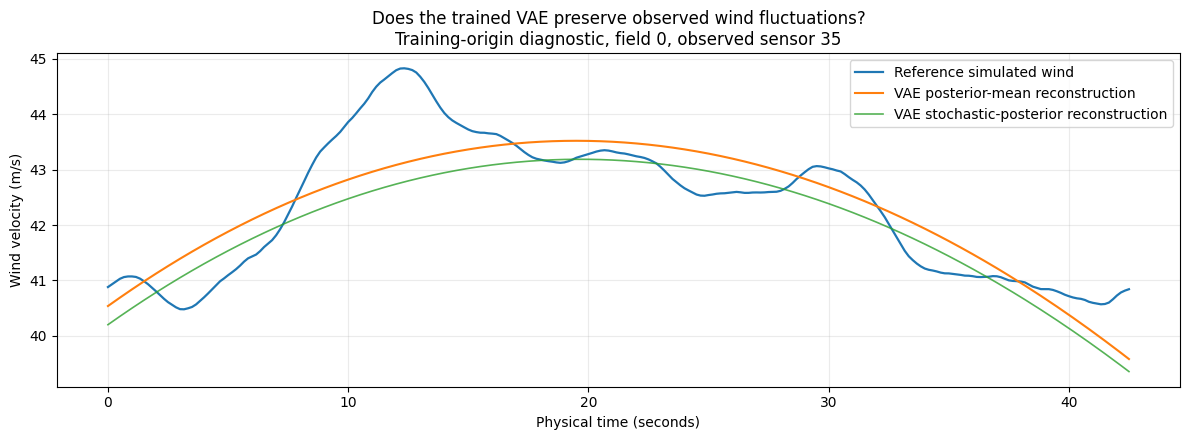


=== CELL 9 RESULTS ===
VAE_POSTERIOR_MEAN
  variance_ratio : 0.24231125317483357
  adjacent_step_rms_ratio : 0.09150075104934506
  low_band_power_ratio : 0.11586358418799567
  mid_band_power_ratio : 6.848361124850113e-06
  high_band_power_ratio : 3.0258460995328946e-07
  observed_mse : 2.6668879985809326
  withheld_mse : 2.575587034225464
VAE_STOCHASTIC_POSTERIOR
  variance_ratio : 0.23798643385088322
  adjacent_step_rms_ratio : 0.09107123782564797
  low_band_power_ratio : 0.11435012916473199
  mid_band_power_ratio : 6.6382081883947215e-06
  high_band_power_ratio : 2.9214944201267936e-07
  observed_mse : 2.790527105331421
  withheld_mse : 2.7309067249298096
FLOW_V3_UNCONDITIONAL
  variance_ratio : 0.26148503252975736
  adjacent_step_rms_ratio : 0.10637691503839639
  low_band_power_ratio : 0.14321502408749134
  mid_band_power_ratio : 4.495367495754202e-06
  high_band_power_ratio : 1.6070484490202037e-07
LATENT_DIAGNOSTICS
  mean_across_field_mu_variance : 0.5758072137832642
  mean_post

In [ ]:

# WIND VISION — CELL 9
# ISOLATE VAE RECONSTRUCTION VS FLOW GENERATION
# No training, no fine-tuning, no checkpoint modification.

from pathlib import Path
import hashlib, json, sys
import numpy as np
import h5py
import torch
import matplotlib.pyplot as plt

BASE = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction/evidence"
)
FULL = BASE / "fullscale_physicsnemo_training"
RUN = FULL / "final_completion_20261108_v1"

TRAIN = (
    BASE / "w1_e54_vae_training_ablation_20261104/"
    "inputs/W1_E54_TRAIN_ONLY_512_SEED_540054.hdf5"
)
ORIGIN = (
    FULL / "native_vae_5000_seed490300_extend_to200_v1/"
    "latest.pt"
)
VAE = (
    FULL / "joint_stochastic_vae_from_repaired8_v1/latest.pt"
)
FLOW_FIELDS = (
    RUN / "cell02_native_fresh_generation_v1/"
    "generated_wind_16_v1.npz"
)

OUT = RUN / "cell09_vae_temporal_bottleneck_v1"

EXPECTED = {
    TRAIN: "a3c424b15b96a76171c29dd9b2cb9d033fd85c7a5d58c07a28d6f9816542f1d4",
    ORIGIN: "d1c4fe3bf00bdc4bd9789a242eeb13f7464a85671dbc6206ba506af9661e64d5",
    VAE: "d2bc9d42c3aa9738217dfde92aa12b4468268945fd1a7b958b087878f704f9e9",
    FLOW_FIELDS: "99510549008427f0e95f5a399321f5f9317e56697581a11fddd9219ab57a69df"
}

def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(8*1024*1024), b""):
            h.update(chunk)
    return h.hexdigest()

print("=== CELL 9: VAE TEMPORAL BOTTLENECK DIAGNOSTIC ===")

assert torch.cuda.is_available()
assert not OUT.exists(), "Existing Cell 9 evidence: do not overwrite."

for path, expected in EXPECTED.items():
    assert path.is_file()
    assert sha256(path) == expected, f"Input changed: {path.name}"

sys.path.insert(0, "/content/wind_vision_fullscale/models")
sys.path.insert(0, "/content/nasa_clfm_reference")

from models import PhysicsNeMoWindVAE

origin = torch.load(ORIGIN, map_location="cpu", weights_only=True)
trained = torch.load(VAE, map_location="cpu", weights_only=True)

model = PhysicsNeMoWindVAE(
    origin["architecture_config"]
).cuda().eval()

model.load_state_dict(trained["model_state"], strict=True)
model.requires_grad_(False)

observed = np.r_[0:10, 30:40, 60:70, 90:100]
withheld = np.setdiff1d(np.arange(100), observed)

with h5py.File(TRAIN, "r") as h:
    xyz = h["x_grid"][:].astype(np.float32)
    times = h["t_grid"][:].astype(np.float32)
    truth = np.stack([
        h["wind_samples"][str(i)]["v1"][:]
        for i in range(16)
    ]).astype(np.float32)

assert truth.shape == (16, 100, 256)
assert xyz.shape == (100, 3)
assert times.shape == (256,)

coords = np.concatenate([
    np.broadcast_to(xyz[:, None, :], (100, 256, 3)),
    np.broadcast_to(times[None, :, None], (100, 256, 1))
], axis=-1).reshape(25600, 4).copy()

coords_gpu = torch.from_numpy(coords).cuda()

with np.load(FLOW_FIELDS, allow_pickle=False) as p:
    flow_wind = p["wind_mps"].copy()

assert flow_wind.shape == truth.shape
assert np.isfinite(flow_wind).all()

mean_wind = np.empty_like(truth)
sample_wind = np.empty_like(truth)

all_mu, all_lv = [], []
rng = torch.Generator(device="cpu").manual_seed(490901)

with torch.inference_mode():
    for start in range(0, 16, 2):
        stop = start + 2

        u = torch.from_numpy(
            ((truth[start:stop, observed] + 2) / 49).copy()
        ).cuda()

        mu, lv = model.encode(u)

        assert mu.shape == lv.shape == (2, 128)
        assert torch.isfinite(mu).all()
        assert torch.isfinite(lv).all()

        eps = torch.randn(
            (2, 128), generator=rng
        ).cuda()

        z_sample = mu + torch.exp(0.5 * lv) * eps

        all_mu.append(mu.cpu().numpy())
        all_lv.append(lv.cpu().numpy())

        for z, destination in (
            (mu, mean_wind),
            (z_sample, sample_wind)
        ):
            blocks = []

            for first in range(0, 25600, 2048):
                points = coords_gpu[first:first+2048]
                points = points.unsqueeze(0).expand(2, -1, -1)

                decoded = model.decode(z, points)[..., 0]
                blocks.append(
                    (decoded * 49 - 2).cpu().numpy()
                )

            destination[start:stop] = np.concatenate(
                blocks, axis=1
            ).reshape(2, 100, 256)

        print(f"FIELDS_PROCESSED: {stop}/16", flush=True)

mu_all = np.concatenate(all_mu)
lv_all = np.concatenate(all_lv)

assert np.isfinite(mean_wind).all()
assert np.isfinite(sample_wind).all()

def metrics(values, reference):
    v = values.astype(np.float64)
    r = reference.astype(np.float64)

    vc = v - v.mean(axis=-1, keepdims=True)
    rc = r - r.mean(axis=-1, keepdims=True)

    window = np.hanning(256)
    pv = np.abs(np.fft.rfft(vc * window, axis=-1))**2
    pr = np.abs(np.fft.rfft(rc * window, axis=-1))**2

    return {
        "variance_ratio": float(
            np.mean(vc**2) / np.mean(rc**2)
        ),
        "adjacent_step_rms_ratio": float(
            np.sqrt(np.mean(np.diff(v, axis=-1)**2)
                    / np.mean(np.diff(r, axis=-1)**2))
        ),
        "low_band_power_ratio": float(
            pv[..., 1:7].mean() / pr[..., 1:7].mean()
        ),
        "mid_band_power_ratio": float(
            pv[..., 7:17].mean() / pr[..., 7:17].mean()
        ),
        "high_band_power_ratio": float(
            pv[..., 17:65].mean() / pr[..., 17:65].mean()
        )
    }

def reconstruction_errors(predicted):
    return {
        "observed_mse": float(np.mean(
            (predicted[:, observed] - truth[:, observed])**2
        )),
        "withheld_mse": float(np.mean(
            (predicted[:, withheld] - truth[:, withheld])**2
        ))
    }

results = {
    "vae_posterior_mean": {
        **metrics(mean_wind, truth),
        **reconstruction_errors(mean_wind)
    },
    "vae_stochastic_posterior": {
        **metrics(sample_wind, truth),
        **reconstruction_errors(sample_wind)
    },
    "flow_v3_unconditional": metrics(flow_wind, truth),
    "latent_diagnostics": {
        "mean_across_field_mu_variance": float(
            np.var(mu_all, axis=0).mean()
        ),
        "mean_posterior_std": float(
            np.exp(0.5 * lv_all).mean()
        )
    }
}

OUT.mkdir(parents=True)

np.savez_compressed(
    OUT / "vae_diagnostic_predictions_v1.npz",
    posterior_mean_wind_mps=mean_wind,
    posterior_sample_wind_mps=sample_wind,
    posterior_mu=mu_all,
    posterior_logvar=lv_all,
    source_field_indices=np.arange(16),
    observed_sensor_indices=observed,
    xyz=xyz,
    t_grid=times
)

report = {
    "format": "wind_vision_vae_bottleneck_diagnostic_v1",
    "source_sha256": {
        str(k): v for k, v in EXPECTED.items()
    },
    "population": "16 training-origin fields, diagnostic only",
    "flow_outputs_are_independent_not_paired": True,
    "seed": 490901,
    "results": results,
    "no_training_or_tuning": True
}

report_path = OUT / "vae_bottleneck_report_v1.json"

report_path.write_text(
    json.dumps(
        report, indent=2,
        sort_keys=True, allow_nan=False
    ) + "\n"
)

# Direct visual comparison using a fixed observed sensor.
sensor = 35
fig, ax = plt.subplots(figsize=(12, 4.5))

ax.plot(
    times, truth[0, sensor],
    label="Reference simulated wind",
    linewidth=1.6
)
ax.plot(
    times, mean_wind[0, sensor],
    label="VAE posterior-mean reconstruction",
    linewidth=1.5
)
ax.plot(
    times, sample_wind[0, sensor],
    label="VAE stochastic-posterior reconstruction",
    linewidth=1.2, alpha=0.8
)

ax.set_title(
    "Does the trained VAE preserve observed wind fluctuations?\n"
    "Training-origin diagnostic, field 0, observed sensor 35"
)
ax.set_xlabel("Physical time (seconds)")
ax.set_ylabel("Wind velocity (m/s)")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()

fig.savefig(
    OUT / "vae_observed_wind_diagnostic.png",
    dpi=200
)
plt.show()
plt.close(fig)

print("\n=== CELL 9 RESULTS ===")

for name, values in results.items():
    print(name.upper())
    for key, value in values.items():
        print(" ", key, ":", value)

print("\nREPORT:", report_path)
print("REPORT_SHA256:", sha256(report_path))
print("NO_TRAINING: TRUE")
print("NO_CHECKPOINT_CHANGES: TRUE")
print("FINAL_TEST_NOT_USED: TRUE")
print("=== CELL 9 COMPLETE ===")


WIND VISION — CELL 10 DECODER EXPRESSIVENESS
INITIAL_POSTERIOR_LATENTS: VERIFIED
NETWORK_PARAMETERS_FROZEN: TRUE
OBSERVED_ONLY STEP 1 MSE_NORMALIZED 0.000811150879599154
OBSERVED_ONLY STEP 40 MSE_NORMALIZED 0.0007630843902006745
OBSERVED_ONLY STEP 80 MSE_NORMALIZED 0.0007588735898025334
OBSERVED_ONLY STEP 120 MSE_NORMALIZED 0.0007565765990875661
OBSERVED_ONLY STEP 160 MSE_NORMALIZED 0.0007556238560937345
FULL_FIELD_ORACLE STEP 1 MSE_NORMALIZED 0.0008550742059014738
FULL_FIELD_ORACLE STEP 40 MSE_NORMALIZED 0.0007894918089732528
FULL_FIELD_ORACLE STEP 80 MSE_NORMALIZED 0.0007842812337912619
FULL_FIELD_ORACLE STEP 120 MSE_NORMALIZED 0.0007804083870723844
FULL_FIELD_ORACLE STEP 160 MSE_NORMALIZED 0.0007747557829134166


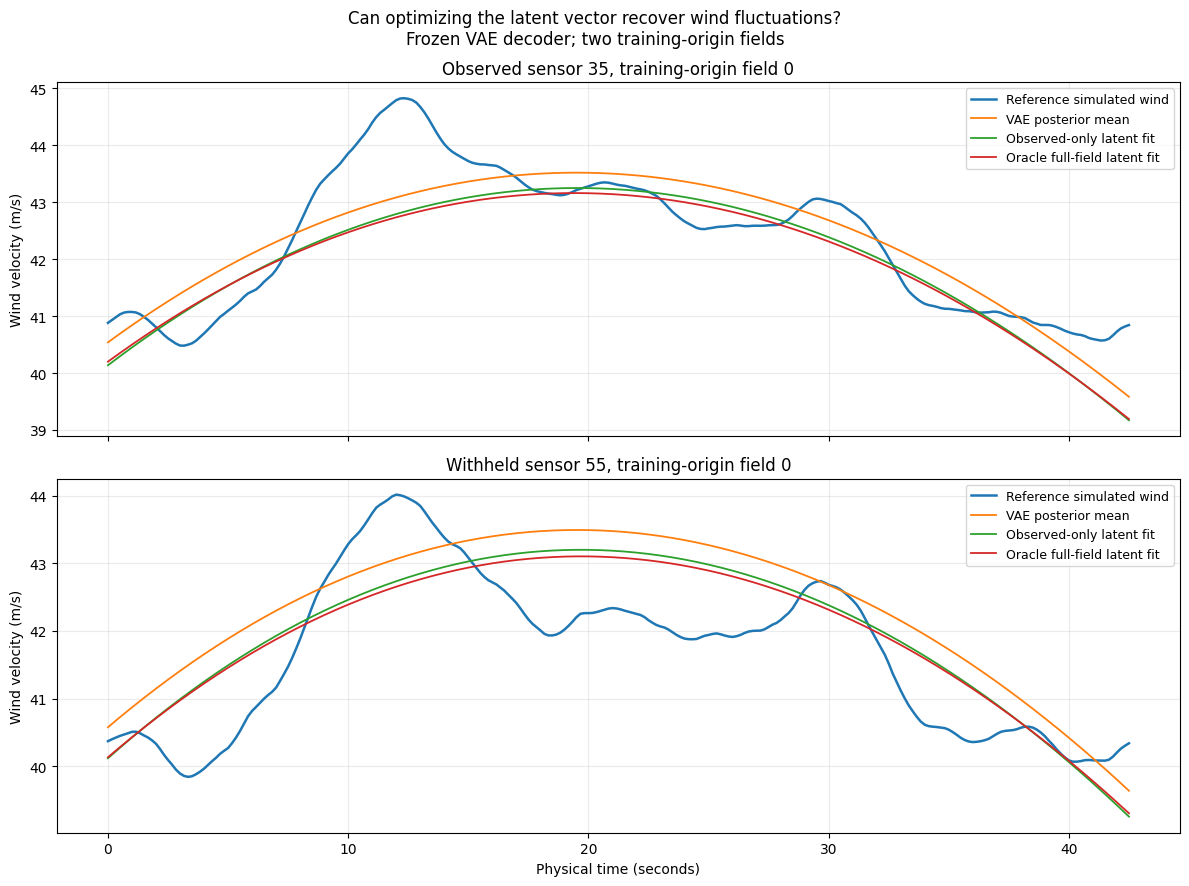


CELL 10 — FIXED DECODER DIAGNOSTIC RESULTS

METHOD: POSTERIOR_MEAN
 REGION: observed
   rmse_mps : 1.395554630499286
   temporal_variance_ratio : 0.40459463043482485
   step_rms_ratio : 0.1257916034264949
   low_band_power_ratio : 0.3711923090437643
   mid_band_power_ratio : 8.924380071902402e-06
   high_band_power_ratio : 4.131130859866627e-07
 REGION: withheld
   rmse_mps : 1.4571684019649558
   temporal_variance_ratio : 0.4078722548531214
   step_rms_ratio : 0.12500838573575557
   low_band_power_ratio : 0.3369767464878563
   mid_band_power_ratio : 9.75687987248079e-06
   high_band_power_ratio : 3.8267707176487414e-07
 REGION: all_sensors
   rmse_mps : 1.4328408640509458
   temporal_variance_ratio : 0.4065730281418359
   step_rms_ratio : 0.12531833729039474
   low_band_power_ratio : 0.34976169918553046
   mid_band_power_ratio : 9.417019404231177e-06
   high_band_power_ratio : 3.938135517386835e-07

METHOD: OBSERVED_ONLY_FIT
 REGION: observed
   rmse_mps : 1.3469698667052983
   tempo

In [ ]:

# ================================================================
# WIND VISION — FINAL COMPLETION / CELL 10
# FIXED-DECODER LATENT EXPRESSIVENESS DIAGNOSTIC
#
# 2 prespecified training-origin fields: indices [0, 1]
# A. VAE posterior mean (baseline)
# B. Optimize latent with 40 observed sensors only
# C. Optimize latent with all 100 sensors (oracle diagnostic)
#
# All network weights frozen.
# No flow training, VAE training, or final-test access.
# ================================================================

from pathlib import Path
import hashlib
import json
import time
import sys
import numpy as np
import h5py
import torch
import matplotlib.pyplot as plt

BASE = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction/evidence"
)

FULL = BASE / "fullscale_physicsnemo_training"
RUN = FULL / "final_completion_20261108_v1"

TRAIN = (
    BASE / "w1_e54_vae_training_ablation_20261104/"
    "inputs/W1_E54_TRAIN_ONLY_512_SEED_540054.hdf5"
)

ORIGIN = (
    FULL / "native_vae_5000_seed490300_extend_to200_v1/"
    "latest.pt"
)

VAE = (
    FULL / "joint_stochastic_vae_from_repaired8_v1/latest.pt"
)

SOURCE = Path(
    "/content/wind_vision_fullscale/models/models.py"
)

OUT = RUN / "cell10_fixed_decoder_latent_fit_v1"

EXPECTED = {
    TRAIN:
        "a3c424b15b96a76171c29dd9b2cb9d033fd85c7a5d58c07a28d6f9816542f1d4",
    ORIGIN:
        "d1c4fe3bf00bdc4bd9789a242eeb13f7464a85671dbc6206ba506af9661e64d5",
    VAE:
        "d2bc9d42c3aa9738217dfde92aa12b4468268945fd1a7b958b087878f704f9e9",
    SOURCE:
        "c45282f2ac65eece3b935d30e018dea71e4566d32fb43fbd89a138ab989d52eb"
}

FIELD_IDS = [0, 1]
STEPS = 160
LR = 0.05
LATENT_REG = 1e-5

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for chunk in iter(
            lambda: f.read(8 * 1024 * 1024),
            b""
        ):
            h.update(chunk)
    return h.hexdigest()

print("=" * 72)
print("WIND VISION — CELL 10 DECODER EXPRESSIVENESS")
print("=" * 72, flush=True)

assert torch.cuda.is_available()
assert not OUT.exists(), (
    "Cell 10 already exists. Do not overwrite."
)

for path, expected in EXPECTED.items():
    assert path.is_file()
    assert sha256(path) == expected, (
        f"Source hash mismatch: {path}"
    )

sys.path.insert(
    0, str(SOURCE.parent)
)

from models import PhysicsNeMoWindVAE

torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

torch.manual_seed(490910)
torch.cuda.manual_seed_all(490910)

origin = torch.load(
    ORIGIN, map_location="cpu", weights_only=True
)

trained = torch.load(
    VAE, map_location="cpu", weights_only=True
)

model = PhysicsNeMoWindVAE(
    origin["architecture_config"]
).cuda().eval()

model.load_state_dict(
    trained["model_state"],
    strict=True
)

model.requires_grad_(False)

assert all(
    not p.requires_grad
    for p in model.parameters()
)

# ------------------------------------------------------------
# Load exactly two training-origin fields.
# ------------------------------------------------------------

observed = np.r_[
    0:10, 30:40, 60:70, 90:100
]

withheld = np.setdiff1d(
    np.arange(100), observed
)

with h5py.File(TRAIN, "r") as h:
    xyz = h["x_grid"][:].astype(np.float32)
    times = h["t_grid"][:].astype(np.float32)

    truth = np.stack([
        h["wind_samples"][str(i)]["v1"][:]
        for i in FIELD_IDS
    ]).astype(np.float32)

assert truth.shape == (2, 100, 256)
assert len(observed) == 40
assert len(withheld) == 60

# Coordinate ordering: sensor, then time.
coordinate_grid = np.concatenate([
    np.broadcast_to(
        xyz[:, None, :], (100, 256, 3)
    ),
    np.broadcast_to(
        times[None, :, None],
        (100, 256, 1)
    )
], axis=-1).copy()

x_all = torch.from_numpy(
    coordinate_grid.reshape(25600, 4)
).cuda().unsqueeze(0).expand(2, -1, -1)

x_obs = torch.from_numpy(
    coordinate_grid[observed]
    .reshape(10240, 4)
).cuda().unsqueeze(0).expand(2, -1, -1)

target_all = torch.from_numpy(
    np.ascontiguousarray((truth + 2) / 49)
).cuda().reshape(2, 25600)

target_obs = torch.from_numpy(
    np.ascontiguousarray(
        (truth[:, observed] + 2) / 49
    )
).cuda().reshape(2, 10240)

# ------------------------------------------------------------
# Get the original VAE posterior-mean latent codes.
# ------------------------------------------------------------

with torch.no_grad():
    z_initial, logvar = model.encode(
        torch.from_numpy(
            np.ascontiguousarray(
                (truth[:, observed] + 2) / 49
            )
        ).cuda()
    )

z_initial = z_initial.detach().clone()

assert z_initial.shape == (2, 128)
assert torch.isfinite(z_initial).all()

print("INITIAL_POSTERIOR_LATENTS: VERIFIED")
print("NETWORK_PARAMETERS_FROZEN: TRUE")

# ------------------------------------------------------------
# Optimize only the two latent vectors.
# Keep the objective identical, except for which
# sensors provide measurements.
# ------------------------------------------------------------

def fit_latents(label, points, target):

    z = torch.nn.Parameter(
        z_initial.detach().clone()
    )

    optimizer = torch.optim.Adam(
        [z], lr=LR
    )

    history = []

    started = time.perf_counter()

    for step in range(STEPS):

        optimizer.zero_grad(set_to_none=True)

        predicted = model.decode(
            z, points
        )[..., 0]

        mse = torch.mean(
            (predicted - target)**2
        )

        penalty = LATENT_REG * torch.mean(
            (z - z_initial)**2
        )

        objective = mse + penalty

        assert bool(
            torch.isfinite(objective).all()
        )

        objective.backward()

        assert z.grad is not None
        assert bool(torch.isfinite(z.grad).all())

        optimizer.step()

        history.append({
            "step": step + 1,
            "data_mse_normalized": float(
                mse.detach()
            ),
            "total_objective": float(
                objective.detach()
            )
        })

        if (
            step == 0
            or (step + 1) % 40 == 0
            or step + 1 == STEPS
        ):
            print(
                label,
                "STEP", step + 1,
                "MSE_NORMALIZED",
                float(mse.detach()),
                flush=True
            )

    torch.cuda.synchronize()

    return (
        z.detach().clone(),
        history,
        time.perf_counter() - started
    )


z_observed, obs_history, obs_seconds = fit_latents(
    "OBSERVED_ONLY",
    x_obs,
    target_obs
)

z_oracle, oracle_history, oracle_seconds = fit_latents(
    "FULL_FIELD_ORACLE",
    x_all,
    target_all
)

# ------------------------------------------------------------
# Evaluate full fields only AFTER optimization.
# Withheld values never influence observed-only gradients.
# ------------------------------------------------------------

def decode_full(z):
    chunks = []

    with torch.inference_mode():
        for first in range(0, 25600, 2048):

            x = x_all[
                :, first:first+2048
            ]

            output = model.decode(
                z, x
            )[..., 0]

            chunks.append(
                (output * 49 - 2).cpu().numpy()
            )

    result = np.concatenate(
        chunks, axis=1
    ).reshape(2, 100, 256)

    assert np.isfinite(result).all()

    return result


predictions = {
    "posterior_mean": decode_full(z_initial),
    "observed_only_fit": decode_full(z_observed),
    "full_field_oracle_fit": decode_full(z_oracle)
}

# ------------------------------------------------------------
# Physical and reconstruction metrics.
# ------------------------------------------------------------

def score(prediction, reference, sensors):
    p = prediction[:, sensors].astype(np.float64)
    r = reference[:, sensors].astype(np.float64)

    pc = p - p.mean(axis=-1, keepdims=True)
    rc = r - r.mean(axis=-1, keepdims=True)

    window = np.hanning(256)

    pp = np.abs(
        np.fft.rfft(pc * window, axis=-1)
    )**2

    rp = np.abs(
        np.fft.rfft(rc * window, axis=-1)
    )**2

    return {
        "rmse_mps": float(
            np.sqrt(np.mean((p-r)**2))
        ),
        "temporal_variance_ratio": float(
            np.mean(pc**2) / np.mean(rc**2)
        ),
        "step_rms_ratio": float(
            np.sqrt(
                np.mean(np.diff(p, axis=-1)**2)
                / np.mean(np.diff(r, axis=-1)**2)
            )
        ),
        "low_band_power_ratio": float(
            pp[..., 1:7].mean()
            / rp[..., 1:7].mean()
        ),
        "mid_band_power_ratio": float(
            pp[..., 7:17].mean()
            / rp[..., 7:17].mean()
        ),
        "high_band_power_ratio": float(
            pp[..., 17:65].mean()
            / rp[..., 17:65].mean()
        )
    }


metrics = {}

for name, prediction in predictions.items():
    metrics[name] = {
        "observed": score(
            prediction, truth, observed
        ),
        "withheld": score(
            prediction, truth, withheld
        ),
        "all_sensors": score(
            prediction, truth, np.arange(100)
        )
    }

# ------------------------------------------------------------
# Figure: same actual field and physical y-axis units.
# Sensor 35 observed; sensor 55 withheld.
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 9),
    sharex=True
)

for ax, sensor, kind in zip(
    axes,
    [35, 55],
    ["Observed sensor", "Withheld sensor"]
):
    ax.plot(
        times,
        truth[0, sensor],
        label="Reference simulated wind",
        linewidth=1.8
    )

    for name, prediction in predictions.items():
        label = {
            "posterior_mean":
                "VAE posterior mean",
            "observed_only_fit":
                "Observed-only latent fit",
            "full_field_oracle_fit":
                "Oracle full-field latent fit"
        }[name]

        ax.plot(
            times,
            prediction[0, sensor],
            label=label,
            linewidth=1.3
        )

    ax.set_title(
        f"{kind} {sensor}, training-origin field 0"
    )
    ax.set_ylabel("Wind velocity (m/s)")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=9)

axes[-1].set_xlabel(
    "Physical time (seconds)"
)

fig.suptitle(
    "Can optimizing the latent vector recover wind fluctuations?\n"
    "Frozen VAE decoder; two training-origin fields"
)

fig.tight_layout()

# ------------------------------------------------------------
# Save evidence without modifying frozen inputs.
# ------------------------------------------------------------

OUT.mkdir(parents=True)

figure_path = OUT / "fixed_decoder_latent_fit.png"

fig.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

archive = OUT / "latent_fit_predictions_v1.npz"

np.savez_compressed(
    archive,
    reference_wind_mps=truth,
    posterior_mean_wind_mps=predictions["posterior_mean"],
    observed_only_wind_mps=predictions["observed_only_fit"],
    oracle_wind_mps=predictions["full_field_oracle_fit"],
    posterior_latents=z_initial.cpu().numpy(),
    observed_fit_latents=z_observed.cpu().numpy(),
    oracle_fit_latents=z_oracle.cpu().numpy(),
    source_field_ids=np.array(FIELD_IDS),
    observed_sensor_ids=observed,
    withheld_sensor_ids=withheld,
    xyz=xyz,
    t_grid=times
)

report = {
    "format": "wind_vision_fixed_decoder_latent_fit_v1",
    "population": "2 training-origin fields",
    "field_ids": FIELD_IDS,
    "steps": STEPS,
    "learning_rate": LR,
    "latent_regularization": LATENT_REG,
    "network_weights_frozen": True,
    "oracle_uses_all_reference_sensors": True,
    "observed_only_never_uses_withheld_labels_for_fit": True,
    "optimization_is_nonconvex": True,
    "not_global_decoder_capacity_bound": True,
    "metrics": metrics,
    "optimizer_history": {
        "observed_only": obs_history,
        "oracle": oracle_history
    },
    "runtime_diagnostic_seconds": {
        "observed_only": obs_seconds,
        "oracle": oracle_seconds
    },
    "input_sha256": {
        str(path): digest
        for path, digest in EXPECTED.items()
    },
    "prediction_archive_sha256": sha256(archive),
    "figure_sha256": sha256(figure_path),
    "no_checkpoint_updates": True,
    "no_final_test_access": True
}

report_path = OUT / "fixed_decoder_latent_fit_report_v1.json"

report_path.write_text(
    json.dumps(
        report,
        indent=2,
        sort_keys=True,
        allow_nan=False
    ) + "\n"
)

for path, expected in EXPECTED.items():
    assert sha256(path) == expected

print("\n" + "=" * 72)
print("CELL 10 — FIXED DECODER DIAGNOSTIC RESULTS")
print("=" * 72)

for name, group in metrics.items():
    print("\nMETHOD:", name.upper())

    for region, values in group.items():
        print(" REGION:", region)

        for metric, value in values.items():
            print(
                "  ", metric,
                ":", value
            )

print("\nPREDICTIONS_SHA256:", sha256(archive))
print("REPORT_SHA256:", sha256(report_path))
print("NETWORK_WEIGHTS_UNCHANGED: TRUE")
print("FINAL_TEST_NOT_ACCESSED: TRUE")
print("NO_MODEL_TRAINING: TRUE")
print("=" * 72)


In [ ]:

# ================================================================
# WIND VISION — CELL 11: FROZEN DECODER BASIS CAPACITY
#
# A. Best full-field least-squares fit using FREE branch coefficients
# B. Best projection of Hann-windowed middle/high-frequency signals
#    onto the frozen trunk's function span
#
# Two original training-origin fields: 0 and 1.
# This is a privileged diagnostic, NOT deployable inference.
# No VAE/Flow training. No checkpoint modifications.
# ================================================================

from pathlib import Path
import hashlib, json, sys
import numpy as np
import h5py
import torch
from scipy.linalg import lstsq
from threadpoolctl import threadpool_limits

E = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction/evidence"
)
F = E / "fullscale_physicsnemo_training"
RUN = F / "final_completion_20261108_v1"

TRAIN = (
    E / "w1_e54_vae_training_ablation_20261104/"
    "inputs/W1_E54_TRAIN_ONLY_512_SEED_540054.hdf5"
)
ORIGIN = F / "native_vae_5000_seed490300_extend_to200_v1/latest.pt"
VAE = F / "joint_stochastic_vae_from_repaired8_v1/latest.pt"
C10 = RUN / "cell10_fixed_decoder_latent_fit_v1/latent_fit_predictions_v1.npz"
SOURCE = Path("/content/wind_vision_fullscale/models/models.py")
OUT = RUN / "cell11_frozen_trunk_basis_oracle_v1"

EXPECTED = {
    TRAIN: "a3c424b15b96a76171c29dd9b2cb9d033fd85c7a5d58c07a28d6f9816542f1d4",
    ORIGIN: "d1c4fe3bf00bdc4bd9789a242eeb13f7464a85671dbc6206ba506af9661e64d5",
    VAE: "d2bc9d42c3aa9738217dfde92aa12b4468268945fd1a7b958b087878f704f9e9",
    C10: "2992c2f89860c77646f2e9bd5c61f6b3eaf92cee108439216b939b8442ed145e",
    SOURCE: "c45282f2ac65eece3b935d30e018dea71e4566d32fb43fbd89a138ab989d52eb"
}

def sha(p):
    h = hashlib.sha256()
    with Path(p).open("rb") as f:
        for b in iter(lambda: f.read(8*1024*1024), b""):
            h.update(b)
    return h.hexdigest()

print("=== CELL 11: FROZEN DECODER BASIS CAPACITY ===", flush=True)

assert torch.cuda.is_available()
assert not OUT.exists(), "Existing evidence; do not overwrite."

for p, digest in EXPECTED.items():
    assert p.is_file() and sha(p) == digest, f"Source mismatch: {p}"

sys.path.insert(0, str(SOURCE.parent))
from models import PhysicsNeMoWindVAE

origin = torch.load(ORIGIN, map_location="cpu", weights_only=True)
trained = torch.load(VAE, map_location="cpu", weights_only=True)

model = PhysicsNeMoWindVAE(
    origin["architecture_config"]
).cuda().eval()
model.load_state_dict(trained["model_state"], strict=True)
model.requires_grad_(False)

with h5py.File(TRAIN, "r") as h:
    xyz = h["x_grid"][:].astype(np.float32)
    times = h["t_grid"][:].astype(np.float32)
    truth = np.stack([
        h["wind_samples"][str(i)]["v1"][:]
        for i in (0, 1)
    ]).astype(np.float64)

assert truth.shape == (2, 100, 256)

with np.load(C10, allow_pickle=False) as p:
    posterior = p["posterior_mean_wind_mps"].astype(np.float64)
    latent_oracle = p["oracle_wind_mps"].astype(np.float64)
    assert np.array_equal(p["source_field_ids"], [0, 1])

# Exact decoder coordinate ordering: sensor, then time.
coordinates = np.concatenate([
    np.broadcast_to(xyz[:, None, :], (100, 256, 3)),
    np.broadcast_to(times[None, :, None], (100, 256, 1))
], axis=-1).reshape(25600, 4).copy()

# ---------------------------------------------------------------
# 1. Extract the fixed trunk basis functions.
# No branch network or input wind is involved.
# ---------------------------------------------------------------

blocks = []

with torch.inference_mode():
    for start in range(0, 25600, 2048):
        x = torch.from_numpy(
            coordinates[start:start+2048]
        ).cuda().unsqueeze(0)

        basis = model._trunk(model.grid.normalize(x))

        assert basis.ndim == 4
        assert basis.shape[0] == 1
        assert basis.shape[1] == len(x[0])
        assert basis.shape[-1] == 1

        blocks.append(
            basis[0, :, :, 0].cpu().numpy().astype(np.float64)
        )

A = np.concatenate(blocks, axis=0)
bias = float(model._bias.detach().cpu().reshape(-1)[0])

assert A.shape == (25600, 512)
assert np.isfinite(A).all()

print("FROZEN_TRUNK_BASIS:", A.shape, flush=True)
print("BRANCH_RESTRICTION_REMOVED_FOR_ORACLE: TRUE")

# ---------------------------------------------------------------
# 2. Free-coefficient full-field least-squares oracle.
#
# Any output of the trained decoder is in this function span.
# We permit coefficients that the trained branch may never produce.
# Therefore this is an optimistic fit.
# ---------------------------------------------------------------

Y = ((truth + 2) / 49).reshape(2, -1).T - bias

with threadpool_limits(limits=4):
    coeff, _, rank_full, _ = lstsq(
        A, Y,
        cond=1e-10,
        lapack_driver="gelsy"
    )

fit_norm = A @ coeff + bias

free_branch_fit = (
    fit_norm.T.reshape(2, 100, 256) * 49 - 2
)

assert np.isfinite(free_branch_fit).all()

print("FULL_FIELD_BASIS_RANK:", rank_full, flush=True)

# ---------------------------------------------------------------
# 3. High-frequency capacity test with Hann-windowed targets.
#
# Windowing avoids treating the periodic FFT endpoint seam
# as real high-frequency wind.
#
# We project each isolated frequency-band target onto
# the appropriately windowed fixed trunk basis.
# ---------------------------------------------------------------

window = np.hanning(256)
window_flat = np.tile(window, 100)

Aw = A * window_flat[:, None]

centered_norm = (
    truth - truth.mean(axis=-1, keepdims=True)
) / 49

windowed_truth = centered_norm * window[None, None, :]

def band_target(start_bin):
    spectrum = np.fft.rfft(windowed_truth, axis=-1)
    spectrum[..., :start_bin] = 0
    filtered = np.fft.irfft(spectrum, n=256, axis=-1)
    return filtered.reshape(2, -1).T

# Middle+high = bins 7...128
# High+tail = bins 17...128
mid_high = band_target(7)
high_tail = band_target(17)

band_targets = np.concatenate(
    [mid_high, high_tail],
    axis=1
)

with threadpool_limits(limits=4):
    band_coeff, _, rank_windowed, _ = lstsq(
        Aw, band_targets,
        cond=1e-10,
        lapack_driver="gelsy"
    )

band_projection = Aw @ band_coeff

def captured_fraction(target, prediction):
    energy = np.sum(target**2, axis=0)
    error = np.sum((target-prediction)**2, axis=0)
    assert np.all(energy > 0)
    return (1 - error/energy).tolist()

mid_high_capture = captured_fraction(
    mid_high, band_projection[:, :2]
)
high_tail_capture = captured_fraction(
    high_tail, band_projection[:, 2:]
)

# ---------------------------------------------------------------
# 4. Compare normal reconstruction metrics.
# ---------------------------------------------------------------

def metrics(p):
    a = p.astype(np.float64)
    t = truth

    centered_a = a - a.mean(axis=-1, keepdims=True)
    centered_t = t - t.mean(axis=-1, keepdims=True)

    pa = np.abs(np.fft.rfft(
        centered_a * window, axis=-1
    ))**2

    pt = np.abs(np.fft.rfft(
        centered_t * window, axis=-1
    ))**2

    return {
        "rmse_mps": float(np.sqrt(np.mean((a-t)**2))),
        "variance_ratio": float(
            np.mean(centered_a**2) / np.mean(centered_t**2)
        ),
        "step_rms_ratio": float(np.sqrt(
            np.mean(np.diff(a, axis=-1)**2) /
            np.mean(np.diff(t, axis=-1)**2)
        )),
        "mid_band_power_ratio": float(
            pa[..., 7:17].mean()/pt[..., 7:17].mean()
        ),
        "high_band_power_ratio": float(
            pa[..., 17:65].mean()/pt[..., 17:65].mean()
        )
    }

results = {
    "posterior_mean": metrics(posterior),
    "latent_optimized_oracle": metrics(latent_oracle),
    "unrestricted_trunk_basis_oracle": metrics(free_branch_fit)
}

# ---------------------------------------------------------------
# 5. Save immutable diagnostic evidence.
# ---------------------------------------------------------------

OUT.mkdir(parents=True)

np.savez_compressed(
    OUT / "basis_capacity_predictions_v1.npz",
    truth_mps=truth.astype(np.float32),
    unrestricted_basis_oracle_mps=free_branch_fit.astype(np.float32),
    original_posterior_mps=posterior.astype(np.float32),
    latent_oracle_mps=latent_oracle.astype(np.float32),
    branch_coefficients=coeff.astype(np.float32),
    source_field_ids=np.array([0, 1]),
    xyz=xyz,
    t_grid=times
)

report = {
    "format": "wind_vision_cell11_fixed_basis_capacity_v1",
    "population": "Two training-origin fields",
    "privileged_100_sensor_oracle": True,
    "network_weights_modified": False,
    "trunk_basis_shape": list(A.shape),
    "full_basis_numerical_rank": int(rank_full),
    "hann_windowed_basis_numerical_rank": int(rank_windowed),
    "least_squares_driver": "scipy gelsy",
    "least_squares_relative_rank_cutoff": 1e-10,
    "comparison_metrics": results,
    "mid_high_hann_band_fraction_captured_per_field":
        mid_high_capture,
    "high_tail_hann_band_fraction_captured_per_field":
        high_tail_capture,
    "free_branch_coefficients_not_guaranteed_reachable":
        True,
    "not_a_global_bound_on_other_architectures": True,
    "not_independent_validation": True,
    "input_sha256": {
        str(p): digest for p, digest in EXPECTED.items()
    }
}

report_path = OUT / "trunk_basis_capacity_report_v1.json"

report_path.write_text(
    json.dumps(report, indent=2, sort_keys=True,
               allow_nan=False) + "\n"
)

for p, digest in EXPECTED.items():
    assert sha(p) == digest

print("\n=== CELL 11 RESULTS ===")

for method, values in results.items():
    print("\nMETHOD:", method)
    for k, v in values.items():
        print(" ", k, ":", v)

print("\nFULL_BASIS_RANK:", rank_full)
print("WINDOWED_BASIS_RANK:", rank_windowed)
print("MID_HIGH_BAND_CAPTURE:", mid_high_capture)
print("HIGH_TAIL_BAND_CAPTURE:", high_tail_capture)

print("\nREPORT_SHA256:", sha(report_path))
print("NETWORK_PARAMETERS_UNCHANGED: TRUE")
print("NO_FLOW_TRAINING: TRUE")
print("NO_FINAL_TEST_ACCESS: TRUE")
print("=== CELL 11 COMPLETE ===")


=== CELL 11: FROZEN DECODER BASIS CAPACITY ===
FROZEN_TRUNK_BASIS: (25600, 512)
BRANCH_RESTRICTION_REMOVED_FOR_ORACLE: TRUE
FULL_FIELD_BASIS_RANK: 512

=== CELL 11 RESULTS ===

METHOD: posterior_mean
  rmse_mps : 1.4328408758049749
  variance_ratio : 0.40657302473518747
  step_rms_ratio : 0.12531833713342047
  mid_band_power_ratio : 9.417019150538756e-06
  high_band_power_ratio : 3.93813534873025e-07

METHOD: latent_optimized_oracle
  rmse_mps : 1.363591437499761
  variance_ratio : 0.44307287913877147
  step_rms_ratio : 0.12918335600094744
  mid_band_power_ratio : 1.070750290050705e-05
  high_band_power_ratio : 4.5541503493914415e-07

METHOD: unrestricted_trunk_basis_oracle
  rmse_mps : 1.0612478110281667
  variance_ratio : 0.6541343387521238
  step_rms_ratio : 1.3123185102418167
  mid_band_power_ratio : 0.010422148538816265
  high_band_power_ratio : 0.29015599848584356

FULL_BASIS_RANK: 512
WINDOWED_BASIS_RANK: 512
MID_HIGH_BAND_CAPTURE: [0.024859261852799852, 0.029404202842660987]
HI

=== CELL 12: ENCODER SPECTRAL INFORMATION ===
FROZEN_VAE_CODES_EXTRACTED: (512, 128)

 TRAIN
middle_7_16 CAPTURE: 0.026299932853655728 ALIGNMENT: 0.16704582688070924
high_17_64 CAPTURE: 0.026779898451543604 ALIGNMENT: 0.16901096585785483
tail_65_128 CAPTURE: 0.028607685333219446 ALIGNMENT: 0.17428775470909977
all_7_128 CAPTURE: 0.02638684626920884 ALIGNMENT: 0.16739500075680525

 DEVELOPMENT
middle_7_16 CAPTURE: -0.024413748631121113 ALIGNMENT: -0.03224019736157499
high_17_64 CAPTURE: -0.018508879988274662 ALIGNMENT: -0.005861396151672633
tail_65_128 CAPTURE: -0.01850004111258774 ALIGNMENT: 0.001560558403174958
all_7_128 CAPTURE: -0.02339337047984391 ALIGNMENT: -0.027564262446316632

 SHUFFLED_CONTROL
middle_7_16 CAPTURE: -0.009435995436611222 ALIGNMENT: 0.027765548743772184
high_17_64 CAPTURE: -0.022104792746383106 ALIGNMENT: -0.023775992870886106
tail_65_128 CAPTURE: -0.021683370662126666 ALIGNMENT: -0.009761041233533248
all_7_128 CAPTURE: -0.011623884012512464 ALIGNMENT: 0.019007728

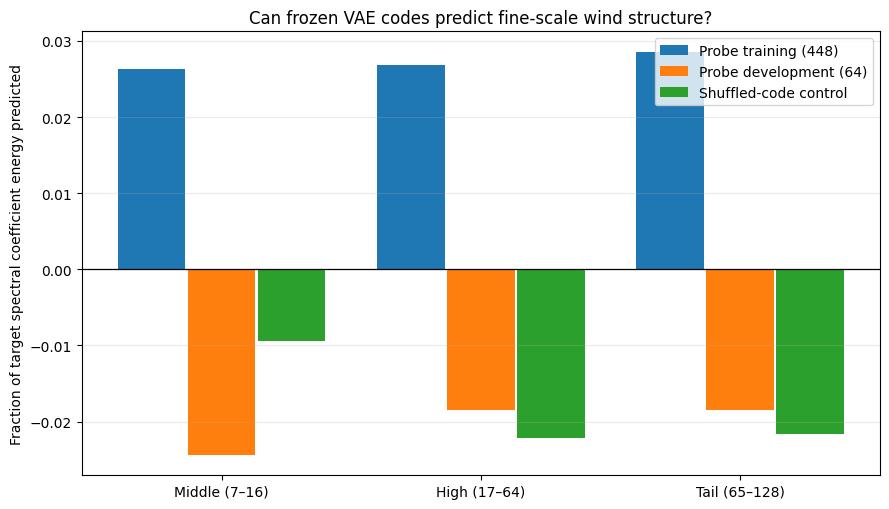


=== CELL 12 COMPLETE ===
REPORT: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_proposal_reproduction/evidence/fullscale_physicsnemo_training/final_completion_20261108_v1/cell12_latent_spectral_information_probe_v1/encoder_spectral_information_report_v1.json
REPORT_SHA256: 5dd7ea82dd6c80e8c2d2ad7c9b158b0b561b776931896f8996d72d68e2457ffd
VAE_AND_FLOW_CHECKPOINTS_UNCHANGED: TRUE
FINAL_TEST_UNTOUCHED: TRUE


In [ ]:

# ================================================================
# WIND VISION — CELL 12
# FROZEN ENCODER: SPECTRAL INFORMATION PROBE
#
# 448 probe-training / 64 probe-development fields
# Fixed linear ridge readout + shuffled-code control
#
# No VAE training, flow training, or checkpoint modification.
# ================================================================

from pathlib import Path
import hashlib, json, sys
import numpy as np
import h5py
import torch
import matplotlib.pyplot as plt

E = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction/evidence"
)
F = E / "fullscale_physicsnemo_training"
RUN = F / "final_completion_20261108_v1"

TRAIN = (
    E / "w1_e54_vae_training_ablation_20261104/"
    "inputs/W1_E54_TRAIN_ONLY_512_SEED_540054.hdf5"
)
ORIGIN = F / "native_vae_5000_seed490300_extend_to200_v1/latest.pt"
VAE = F / "joint_stochastic_vae_from_repaired8_v1/latest.pt"
SOURCE = Path("/content/wind_vision_fullscale/models/models.py")
OUT = RUN / "cell12_latent_spectral_information_probe_v1"

HASHES = {
    TRAIN: "a3c424b15b96a76171c29dd9b2cb9d033fd85c7a5d58c07a28d6f9816542f1d4",
    ORIGIN: "d1c4fe3bf00bdc4bd9789a242eeb13f7464a85671dbc6206ba506af9661e64d5",
    VAE: "d2bc9d42c3aa9738217dfde92aa12b4468268945fd1a7b958b087878f704f9e9",
    SOURCE: "c45282f2ac65eece3b935d30e018dea71e4566d32fb43fbd89a138ab989d52eb",
}

def sha(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(
            lambda: f.read(8 * 1024 * 1024), b""
        ):
            h.update(block)
    return h.hexdigest()

print("=== CELL 12: ENCODER SPECTRAL INFORMATION ===", flush=True)

assert torch.cuda.is_available()
assert not OUT.exists(), "Cell 12 evidence already exists."

for p, digest in HASHES.items():
    assert p.is_file() and sha(p) == digest, f"Changed source: {p}"

sys.path.insert(0, str(SOURCE.parent))
from models import PhysicsNeMoWindVAE

origin = torch.load(ORIGIN, map_location="cpu", weights_only=True)
vae_data = torch.load(VAE, map_location="cpu", weights_only=True)

model = PhysicsNeMoWindVAE(
    origin["architecture_config"]
).cuda().eval()

model.load_state_dict(vae_data["model_state"], strict=True)
model.requires_grad_(False)

assert all(not p.requires_grad for p in model.parameters())

# ------------------------------------------------
# 1. Read original-training-origin data.
# ------------------------------------------------

obs = np.r_[0:10, 30:40, 60:70, 90:100]

with h5py.File(TRAIN, "r") as h:
    assert len(h["wind_samples"]) == 512

    wind = np.stack([
        h["wind_samples"][str(i)]["v1"][:]
        for i in range(512)
    ]).astype(np.float32)

assert wind.shape == (512, 100, 256)
assert np.isfinite(wind).all()

# ------------------------------------------------
# 2. Extract existing frozen 128-dimensional codes.
# ------------------------------------------------

codes = []

with torch.inference_mode():
    for start in range(0, 512, 32):
        u = torch.from_numpy(
            np.ascontiguousarray(
                (wind[start:start+32, obs, :] + 2) / 49
            )
        ).cuda()

        mu, logvar = model.encode(u)

        assert mu.shape == (len(u), 128)
        codes.append(mu.cpu().numpy())

Z = np.concatenate(codes, axis=0).astype(np.float64)

assert Z.shape == (512, 128)
print("FROZEN_VAE_CODES_EXTRACTED:", Z.shape, flush=True)

# ------------------------------------------------
# 3. Locked training-origin split.
# This does not constitute untouched final testing.
# ------------------------------------------------

ids = np.random.default_rng(540055).permutation(512)
dev_ids = ids[:64]
train_ids = ids[64:]

assert not set(train_ids).intersection(set(dev_ids))

# ------------------------------------------------
# 4. Target: Hann-windowed Fourier coefficients.
# Test bins 7–128: middle, high and tail frequencies.
# ------------------------------------------------

v = wind.astype(np.float64)

anomaly = v - v.mean(axis=-1, keepdims=True)
bins = np.arange(7, 129)

complex_fft = np.fft.rfft(
    anomaly * np.hanning(256)[None, None, :],
    axis=-1
)[..., bins]

target = np.stack(
    (complex_fft.real, complex_fft.imag),
    axis=-1
).reshape(512, -1)

assert target.shape == (512, 100 * len(bins) * 2)

del anomaly, v, complex_fft

# ------------------------------------------------
# 5. Standardize latent inputs using training only.
# Fit a prespecified ridge-regression linear probe.
# ------------------------------------------------

zmean = Z[train_ids].mean(axis=0)
zstd = np.maximum(Z[train_ids].std(axis=0), 1e-5)

X = (Z - zmean) / zstd

Xtr = X[train_ids]
Xdev = X[dev_ids]

ymean = target[train_ids].mean(axis=0)

reg = 0.1 * len(train_ids)

A = Xtr.T @ Xtr + reg * np.eye(128)
B = Xtr.T @ (target[train_ids] - ymean)

beta = np.linalg.solve(A, B)

pred_train = ymean + Xtr @ beta
pred_dev = ymean + Xdev @ beta

# ------------------------------------------------
# 6. Shuffled-code negative control.
# ------------------------------------------------

rng = np.random.default_rng(490912)

shuffled_targets = target[train_ids][
    rng.permutation(len(train_ids))
]

beta_shuffle = np.linalg.solve(
    A,
    Xtr.T @ (shuffled_targets - ymean)
)

pred_dev_shuffle = ymean + Xdev @ beta_shuffle

# ------------------------------------------------
# 7. Evaluate how much spectral information is recovered.
# Energy capture penalizes incorrect phases, unlike
# a power ratio alone.
# ------------------------------------------------

def evaluate(actual, predicted):
    a = actual.reshape(len(actual), 100, len(bins), 2)
    p = predicted.reshape(len(predicted), 100, len(bins), 2)

    result = {}

    for name, lo, hi in (
        ("middle_7_16", 7, 17),
        ("high_17_64", 17, 65),
        ("tail_65_128", 65, 129),
        ("all_7_128", 7, 129)
    ):
        sel = (bins >= lo) & (bins < hi)

        t = a[:, :, sel, :]
        y = p[:, :, sel, :]

        reference_energy = float(np.sum(t*t))
        predicted_energy = float(np.sum(y*y))
        squared_error = float(np.sum((t-y)**2))

        capture = 1.0 - squared_error/reference_energy

        alignment = float(
            np.sum(t*y) / max(
                np.sqrt(reference_energy * predicted_energy),
                1e-20
            )
        )

        result[name] = {
            "captured_target_energy_fraction": capture,
            "predicted_to_reference_band_energy":
                predicted_energy/reference_energy,
            "spectral_coefficient_alignment": alignment
        }

    return result

train_stats = evaluate(target[train_ids], pred_train)
dev_stats = evaluate(target[dev_ids], pred_dev)
shuffle_stats = evaluate(target[dev_ids], pred_dev_shuffle)

for label, stats in [
    ("TRAIN", train_stats),
    ("DEVELOPMENT", dev_stats),
    ("SHUFFLED_CONTROL", shuffle_stats)
]:
    print("\n", label)

    for band, values in stats.items():
        print(
            band,
            "CAPTURE:",
            values["captured_target_energy_fraction"],
            "ALIGNMENT:",
            values["spectral_coefficient_alignment"]
        )

# ------------------------------------------------
# 8. Save original evidence.
# ------------------------------------------------

OUT.mkdir(parents=True)

np.savez_compressed(
    OUT / "spectral_linear_probe_dev_v1.npz",
    dev_field_indices=dev_ids,
    training_field_indices=train_ids,
    frequency_bins=bins,
    dev_true_coefficients=target[dev_ids].astype(np.float32),
    dev_predicted_coefficients=pred_dev.astype(np.float32),
    dev_shuffled_control_coefficients=
        pred_dev_shuffle.astype(np.float32)
)

bands = (
    "middle_7_16",
    "high_17_64",
    "tail_65_128"
)

xx = np.arange(3)

fig, ax = plt.subplots(figsize=(9, 5.2))

for offset, stats, label in [
    (-0.27, train_stats, "Probe training (448)"),
    (0, dev_stats, "Probe development (64)"),
    (0.27, shuffle_stats, "Shuffled-code control")
]:
    ax.bar(
        xx + offset,
        [
            stats[k]["captured_target_energy_fraction"]
            for k in bands
        ],
        width=0.26,
        label=label
    )

ax.axhline(0, color="black", linewidth=0.9)

ax.set_xticks(
    xx,
    [
        "Middle (7–16)",
        "High (17–64)",
        "Tail (65–128)"
    ]
)

ax.set_ylabel(
    "Fraction of target spectral coefficient energy predicted"
)

ax.set_title(
    "Can frozen VAE codes predict fine-scale wind structure?"
)

ax.grid(axis="y", alpha=0.25)
ax.legend()
fig.tight_layout()

figure_path = OUT / "latent_spectral_probe_v1.png"

fig.savefig(figure_path, dpi=200)
plt.show()
plt.close(fig)

report = {
    "format":
        "wind_vision_cell12_frozen_encoder_spectral_probe_v1",
    "population":
        "512 original-training-origin fields; 448 train, 64 development",
    "not_independent_model_validation": True,
    "linear_probe_fitted": True,
    "vae_or_flow_weights_modified": False,
    "latent_dimensions": 128,
    "hann_windowed_frequency_bins": bins.tolist(),
    "ridge_penalty": reg,
    "split_seed": 540055,
    "negative_control_seed": 490912,
    "train": train_stats,
    "development": dev_stats,
    "shuffled_control": shuffle_stats,
    "input_sha256": {
        str(p): digest for p, digest in HASHES.items()
    },
    "generated_file_sha256": {
        "spectral_linear_probe_dev_v1.npz":
            sha(OUT / "spectral_linear_probe_dev_v1.npz"),
        "latent_spectral_probe_v1.png": sha(figure_path)
    },
    "limitations": [
        "Tests only linear decodability of posterior means.",
        "Does not rule out nonlinear representations.",
        "Underlying VAE previously saw training-origin data.",
        "No final reconstruction-test labels accessed."
    ]
}

report_path = (
    OUT / "encoder_spectral_information_report_v1.json"
)

report_path.write_text(
    json.dumps(
        report,
        indent=2,
        sort_keys=True,
        allow_nan=False
    ) + "\n"
)

for p, digest in HASHES.items():
    assert sha(p) == digest

print("\n=== CELL 12 COMPLETE ===")
print("REPORT:", report_path)
print("REPORT_SHA256:", sha(report_path))
print("VAE_AND_FLOW_CHECKPOINTS_UNCHANGED: TRUE")
print("FINAL_TEST_UNTOUCHED: TRUE")


In [ ]:

from pathlib import Path
import hashlib
import h5py

candidates = [
    Path("/content/wind_train_data.hdf5"),
    Path("/content/wind_vision_fullscale/data/wind/wind_train_data.hdf5"),
    Path("/content/nasa_clfm_reference/data/wind/wind_train_data.hdf5")
]

def sha256(p):
    h = hashlib.sha256()
    with p.open("rb") as f:
        for block in iter(lambda: f.read(8 * 1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

print("=== CELL 13: ORIGINAL FULL-TRAINING DATA READINESS ===")

found = False

for path in candidates:
    if not path.is_file():
        continue

    found = True
    print("FOUND:", path)
    print("SIZE_MIB:", round(path.stat().st_size / 2**20, 2))
    print("SHA256:", sha256(path))

    with h5py.File(path, "r") as h:
        print("HDF5_KEYS:", list(h.keys()))

        assert "wind_samples" in h
        print("WIND_FIELDS:", len(h["wind_samples"]))

        assert len(h["wind_samples"]) == 5000, (
            "This is not the original 5000-field training set."
        )

        for key in ("0", "4999"):
            assert key in h["wind_samples"]
            print(
                "FIELD", key, "SHAPE:",
                h["wind_samples"][key]["v1"].shape
            )

if not found:
    print("FULL_TRAINING_DATA: NOT_IN_COLAB")
    print("Restore the original wind_train_data.hdf5 from Mac.")
else:
    print("FULL_TRAINING_DATA_STRUCTURE: PASS")
    print("NEXT: Verify SHA256 against original data manifest.")

print("NO_TRAINING_OR_DATA_MODIFICATION: TRUE")


=== CELL 13: ORIGINAL FULL-TRAINING DATA READINESS ===
FULL_TRAINING_DATA: NOT_IN_COLAB
Restore the original wind_train_data.hdf5 from Mac.
NO_TRAINING_OR_DATA_MODIFICATION: TRUE


In [ ]:

# CELL 13 — PHYSICSNEMO V2 SPECTRAL VAE PILOT
# Creates an archived standalone training script.
# 448 training-origin fields; 64 development fields.
# No access to the 872-field final reconstruction test.

from pathlib import Path
import subprocess
import sys

script = r'''
from pathlib import Path
import hashlib, json, shutil, random
import numpy as np
import h5py
import torch
from torch import nn
from torch.nn import functional as F
from physicsnemo.core.module import Module

BASE = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction/evidence"
)
FULL = BASE / "fullscale_physicsnemo_training"
TRAIN = (
    BASE / "w1_e54_vae_training_ablation_20261104/"
    "inputs/W1_E54_TRAIN_ONLY_512_SEED_540054.hdf5"
)
OUT = (
    FULL / "final_completion_20261108_v1/"
    "cell13_v2_spectral_vae_448_64_pilot_v1"
)
DATA_HASH = "a3c424b15b96a76171c29dd9b2cb9d033fd85c7a5d58c07a28d6f9816542f1d4"

SEED = 490913
EPOCHS = 12
BATCH = 8
LATENT = 512
RANK = 32
LR = 3e-4

def sha(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for b in iter(lambda: f.read(8*1024*1024), b""):
            h.update(b)
    return h.hexdigest()

assert torch.cuda.is_available(), "CUDA required"
assert TRAIN.is_file() and sha(TRAIN) == DATA_HASH
assert not OUT.exists(), "Pilot exists; do not overwrite"

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
np.random.seed(SEED)
random.seed(SEED)
torch.set_num_threads(4)
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

with h5py.File(TRAIN, "r") as h:
    xyz = h["x_grid"][:].astype("float32")
    t = h["t_grid"][:].astype("float32")
    wind = np.stack([
        h["wind_samples"][str(i)]["v1"][:]
        for i in range(512)
    ]).astype("float32")

assert wind.shape == (512,100,256)
assert np.isfinite(wind).all()

# Original-reference normalization.
data = torch.from_numpy(
    np.ascontiguousarray((wind + 2.0) / 49.0)
).cuda()

lo = xyz.min(axis=0)
extent = np.maximum(xyz.max(axis=0)-lo, 1e-8)
xyz_normalized = torch.from_numpy(
    np.ascontiguousarray(2*(xyz-lo)/extent-1)
).cuda()

split = np.random.default_rng(540055).permutation(512)
dev_ids = split[:64].copy()
train_ids = split[64:].copy()

assert len(train_ids) == 448
assert len(dev_ids) == 64
assert set(train_ids).isdisjoint(set(dev_ids))

class SpectralWindVAE(Module):
    def __init__(self):
        super().__init__()
        self.encoder_features = nn.Sequential(
            nn.Conv2d(2,24,3,stride=2,padding=1),
            nn.GELU(),
            nn.Conv2d(24,48,3,stride=2,padding=1),
            nn.GELU(),
            nn.Conv2d(48,96,3,stride=2,padding=1),
            nn.GELU(),
            nn.AdaptiveAvgPool2d((8,8)),
            nn.Flatten(),
            nn.Linear(96*8*8,512),
            nn.GELU()
        )
        self.encoder_head = nn.Linear(
            512+100, 2*LATENT
        )
        self.spatial = nn.Sequential(
            nn.Linear(3,96), nn.GELU(),
            nn.Linear(96,RANK)
        )
        self.branch = nn.Sequential(
            nn.Linear(LATENT,768), nn.GELU(),
            nn.Linear(768,RANK*129*2)
        )
        self.bias = nn.Parameter(torch.tensor(0.72))
        nn.init.normal_(
            self.branch[-1].weight, std=1e-4
        )
        nn.init.zeros_(self.branch[-1].bias)

    def encode(self, u):
        centered = u - u.mean(-1,keepdim=True)
        coefficients = torch.fft.rfft(
            centered,dim=-1,norm="ortho"
        )
        features = torch.view_as_real(
            coefficients
        ).permute(0,3,1,2).contiguous()

        hidden = self.encoder_features(features)
        hidden = torch.cat(
            [hidden,u.mean(-1)],dim=-1
        )
        mu,lv = self.encoder_head(hidden).chunk(
            2,dim=-1
        )
        return mu,lv.clamp(-8,3)

    def decode(self,z,xyz):
        n = len(z)
        spatial_basis = self.spatial(xyz)
        spectral_branch = self.branch(z).reshape(
            n,RANK,129,2
        )
        spectrum = torch.einsum(
            "sr,brfc->bsfc",
            spatial_basis,spectral_branch
        )
        complex_spectrum = torch.complex(
            spectrum[...,0],spectrum[...,1]
        )
        return torch.fft.irfft(
            complex_spectrum,n=256,
            dim=-1,norm="ortho"
        ) + self.bias

    def forward(self,u,xyz,stochastic=True):
        mu,lv = self.encode(u)
        z = (
            mu + torch.exp(0.5*lv)*torch.randn_like(mu)
            if stochastic else mu
        )
        return self.decode(z,xyz),mu,lv

model = SpectralWindVAE().cuda()
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LR,weight_decay=1e-5
)

weights = torch.ones(129,device="cuda")
weights[7:17] = 4
weights[17:65] = 8
weights[65:] = 16

def objective(pred,target,mu,lv):
    time_mse = F.mse_loss(pred,target)
    step_mse = F.mse_loss(
        pred[...,1:]-pred[...,:-1],
        target[...,1:]-target[...,:-1]
    )
    pc = pred-pred.mean(-1,keepdim=True)
    tc = target-target.mean(-1,keepdim=True)
    fp = torch.fft.rfft(pc,dim=-1,norm="ortho")
    ft = torch.fft.rfft(tc,dim=-1,norm="ortho")

    spectral = (
        (fp-ft).abs().square()
        * weights.reshape(1,1,129)
    ).mean()

    kl = (-0.5*(
        1+lv-mu.square()-lv.exp()
    ).sum(-1)).mean()

    total = (
        time_mse + 10*step_mse
        + 0.3*spectral + 1e-7*kl
    )
    return total

def physical_metrics(pred,truth):
    p = pred.astype("float64")*49-2
    r = truth.astype("float64")*49-2

    pc = p-p.mean(-1,keepdims=True)
    rc = r-r.mean(-1,keepdims=True)

    window = np.hanning(256)
    pp = np.abs(
        np.fft.rfft(pc*window,axis=-1)
    )**2
    rr = np.abs(
        np.fft.rfft(rc*window,axis=-1)
    )**2

    def band(a,b):
        return float(
            pp[...,a:b].mean()
            / max(rr[...,a:b].mean(),1e-20)
        )

    return {
        "rmse_mps":float(np.sqrt(
            np.mean((p-r)**2)
        )),
        "variance_ratio":float(
            np.mean(pc**2)
            / max(np.mean(rc**2),1e-20)
        ),
        "adjacent_step_rms_ratio":float(
            np.sqrt(
                np.mean(np.diff(p,axis=-1)**2)
                / max(
                    np.mean(np.diff(r,axis=-1)**2),
                    1e-20
                )
            )
        ),
        "low_power_ratio":band(1,7),
        "mid_power_ratio":band(7,17),
        "high_power_ratio":band(17,65),
        "tail_power_ratio":band(65,129)
    }

OUT.mkdir(parents=True)
shutil.copyfile(
    Path(__file__),
    OUT/"train_spectral_vae_v2_pilot.py"
)

history = []
best_loss = float("inf")
best_state = None
best_epoch = None
best_metrics = None

rng = np.random.default_rng(SEED+1)

print("=== SPECTRAL VAE V2 PILOT TRAINING ===",flush=True)
print("PARAMETERS:",sum(p.numel() for p in model.parameters()))
print("TRAIN_FIELDS: 448 | DEV_FIELDS: 64",flush=True)
print("INPUT: full 100-sensor fields, NOT sparse conditioning")
print("EPOCHS:",EPOCHS,flush=True)

for epoch in range(EPOCHS):
    model.train()
    order = rng.permutation(train_ids)
    train_losses = []

    for first in range(0,len(order),BATCH):
        ids = order[first:first+BATCH]
        batch = data[ids]

        optimizer.zero_grad(set_to_none=True)

        pred,mu,lv = model(
            batch,xyz_normalized,stochastic=True
        )
        loss = objective(pred,batch,mu,lv)

        assert bool(torch.isfinite(loss))
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            1.0,error_if_nonfinite=True
        )
        optimizer.step()
        train_losses.append(float(loss.detach()))

    model.eval()
    dev_losses = []
    predictions = []
    references = []

    with torch.inference_mode():
        for first in range(0,len(dev_ids),BATCH):
            ids = dev_ids[first:first+BATCH]
            batch = data[ids]

            pred,mu,lv = model(
                batch,xyz_normalized,stochastic=False
            )
            dev_losses.append(
                (len(ids),float(
                    objective(pred,batch,mu,lv)
                ))
            )
            predictions.append(pred.cpu().numpy())
            references.append(batch.cpu().numpy())

    pred_np = np.concatenate(predictions)
    ref_np = np.concatenate(references)

    dev_loss = sum(
        count*value for count,value in dev_losses
    )/64

    metrics = physical_metrics(pred_np,ref_np)

    entry = {
        "epoch":epoch+1,
        "train_objective":float(np.mean(train_losses)),
        "development_objective":dev_loss,
        "development_metrics":metrics
    }
    history.append(entry)

    if dev_loss < best_loss:
        best_loss = dev_loss
        best_epoch = epoch+1
        best_metrics = metrics
        best_state = {
            k:v.detach().cpu().clone()
            for k,v in model.state_dict().items()
        }

    print(
        "EPOCH",epoch+1,
        "TRAIN",round(entry["train_objective"],7),
        "DEV",round(dev_loss,7),
        "RMSE_MPS",round(metrics["rmse_mps"],4),
        "VAR_RATIO",round(metrics["variance_ratio"],4),
        "STEP_RATIO",round(
            metrics["adjacent_step_rms_ratio"],4
        ),
        "HIGH_POWER",round(metrics["high_power_ratio"],6),
        flush=True
    )

assert best_state is not None

checkpoint = OUT/"best_development_checkpoint_v1.pt"
torch.save({
    "format":"wind_vision_spectral_vae_v2_pilot_v1",
    "model_state":best_state,
    "latent_dim":LATENT,
    "spatial_rank":RANK,
    "best_epoch":best_epoch,
    "train_ids":train_ids.tolist(),
    "dev_ids":dev_ids.tolist(),
    "data_sha256":DATA_HASH,
    "source_sha256":sha(
        OUT/"train_spectral_vae_v2_pilot.py"
    ),
    "full_field_encoder":True,
    "fixed_256_step_fourier_decoder":True,
    "trained_latent_flow":False
},checkpoint)

report = {
    "format":"wind_vision_spectral_vae_v2_pilot_v1",
    "best_epoch":best_epoch,
    "best_development_objective":best_loss,
    "best_development_metrics":best_metrics,
    "epochs_requested":EPOCHS,
    "history":history,
    "checkpoint_sha256":sha(checkpoint),
    "source_sha256":sha(
        OUT/"train_spectral_vae_v2_pilot.py"
    ),
    "training_fields":448,
    "development_fields":64,
    "dataset_sha256":DATA_HASH,
    "full_field_encoder":True,
    "not_a_sparse_conditioned_comparison":True,
    "not_unconditional_generation":True,
    "flow_training_performed":False,
    "final_test_accessed":False,
    "scientific_status":
        "Exploratory development pilot only"
}

report_path = OUT/"pilot_report_v1.json"
report_path.write_text(
    json.dumps(report,indent=2,sort_keys=True,
               allow_nan=False)+"\n"
)

assert sha(TRAIN) == DATA_HASH

print("\n=== CELL 13 PILOT COMPLETE ===")
print("BEST_EPOCH:",best_epoch)
print("BEST_DEVELOPMENT_METRICS:",
      json.dumps(best_metrics,indent=2))
print("MODEL_SOURCE_SHA256:",
      sha(OUT/"train_spectral_vae_v2_pilot.py"))
print("CHECKPOINT_SHA256:",sha(checkpoint))
print("REPORT_SHA256:",sha(report_path))
print("FINAL_TEST_ACCESSED: FALSE")
print("ORIGINAL_CHECKPOINTS_MODIFIED: FALSE")
print("MATCHING_FLOW_TRAINED: FALSE")
'''

path = Path("/content/wind_vision_v2_spectral_pilot.py")
assert not path.exists(), "Pilot script already exists; inspect it."
compile(script, str(path), "exec")
path.write_text(script, encoding="utf-8")

subprocess.run(
    [sys.executable, "-u", str(path)],
    check=True
)


CompletedProcess(args=['/usr/bin/python3', '-u', '/content/wind_vision_v2_spectral_pilot.py'], returncode=0)

In [ ]:

# WIND VISION — CELL 14
# AUDIT COMPLETED SPECTRAL VAE V2 PILOT
# Read-only: no model changes, training, or test-data access.

from pathlib import Path
import json
import hashlib

ROOT = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction/evidence/"
    "fullscale_physicsnemo_training/"
    "final_completion_20261108_v1/"
    "cell13_v2_spectral_vae_448_64_pilot_v1"
)

REPORT = ROOT / "pilot_report_v1.json"
CHECKPOINT = ROOT / "best_development_checkpoint_v1.pt"
SOURCE = ROOT / "train_spectral_vae_v2_pilot.py"

def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(
            lambda: f.read(8 * 1024 * 1024), b""
        ):
            h.update(block)
    return h.hexdigest()

print("=" * 76)
print("WIND VISION — CELL 14 SPECTRAL VAE PILOT AUDIT")
print("=" * 76)

for p in (REPORT, CHECKPOINT, SOURCE):
    assert p.is_file(), f"Missing artifact: {p}"

report = json.loads(REPORT.read_text())

assert sha256(CHECKPOINT) == report["checkpoint_sha256"]
assert sha256(SOURCE) == report["source_sha256"]
assert len(report["history"]) == 12
assert report["training_fields"] == 448
assert report["development_fields"] == 64
assert report["flow_training_performed"] is False
assert report["final_test_accessed"] is False

print("ALL_ARTIFACT_HASHES: VERIFIED")
print("TRAINING_FIELDS: 448")
print("DEVELOPMENT_FIELDS: 64")
print("EPOCHS_COMPLETED:", len(report["history"]))
print("BEST_EPOCH:", report["best_epoch"])

print("\nEPOCH-BY-EPOCH RESULTS")
print(
    f"{'Epoch':<7} {'Train Loss':<13} {'Dev Loss':<13} "
    f"{'RMSE m/s':<12} {'Var Ratio':<12} "
    f"{'Step Ratio':<12} {'High Power':<12}"
)

for h in report["history"]:
    m = h["development_metrics"]

    print(
        f"{h['epoch']:<7}"
        f"{h['train_objective']:<13.6f}"
        f"{h['development_objective']:<13.6f}"
        f"{m['rmse_mps']:<12.5f}"
        f"{m['variance_ratio']:<12.5f}"
        f"{m['adjacent_step_rms_ratio']:<12.5f}"
        f"{m['high_power_ratio']:<12.6f}"
    )

print("\nBEST CHECKPOINT — FULL DEVELOPMENT METRICS")

for name, value in report["best_development_metrics"].items():
    print(f"{name.upper()}: {value:.10f}")

print("\nFIRST VS BEST")

first = report["history"][0]["development_metrics"]
best = report["best_development_metrics"]

for name in best:
    print(
        name,
        "FIRST:", round(first[name], 6),
        "BEST:", round(best[name], 6)
    )

print("\nSOURCE_SHA256:", sha256(SOURCE))
print("CHECKPOINT_SHA256:", sha256(CHECKPOINT))
print("REPORT_SHA256:", sha256(REPORT))

print("\nARTIFACTS_VERIFIED: TRUE")
print("NO_NEW_TRAINING: TRUE")
print("FINAL_TEST_NOT_USED: TRUE")
print("=" * 76)


WIND VISION — CELL 14 SPECTRAL VAE PILOT AUDIT
ALL_ARTIFACT_HASHES: VERIFIED
TRAINING_FIELDS: 448
DEVELOPMENT_FIELDS: 64
EPOCHS_COMPLETED: 12
BEST_EPOCH: 11

EPOCH-BY-EPOCH RESULTS
Epoch   Train Loss    Dev Loss      RMSE m/s     Var Ratio    Step Ratio   High Power  
1      0.034658     0.023625     7.36561     0.01214     0.84621     0.122741    
2      0.014696     0.010689     4.71834     0.06664     1.38035     0.336959    
3      0.007886     0.006571     3.66036     0.04035     0.56973     0.180883    
4      0.006502     0.006048     3.49840     0.02683     0.39106     0.116547    
5      0.006427     0.006135     3.53618     0.02246     0.34939     0.067215    
6      0.006325     0.005958     3.47240     0.02683     0.37525     0.080722    
7      0.006288     0.005931     3.46797     0.01886     0.32927     0.085937    
8      0.006136     0.006049     3.51206     0.01405     0.30910     0.063734    
9      0.006187     0.006533     3.67049     0.01739     0.37763     0.0642

In [ ]:

# ================================================================
# WIND VISION — CELL 15
# TRAINING-ONLY MEAN PROFILE BASELINE
#
# No training, checkpoint loading, or test-data access.
# Uses the exact Cell 13 training/development partition.
# ================================================================

from pathlib import Path
import hashlib
import json
import numpy as np
import h5py

E = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction/evidence"
)

TRAIN = (
    E / "w1_e54_vae_training_ablation_20261104/"
    "inputs/W1_E54_TRAIN_ONLY_512_SEED_540054.hdf5"
)

PILOT = (
    E / "fullscale_physicsnemo_training/"
    "final_completion_20261108_v1/"
    "cell13_v2_spectral_vae_448_64_pilot_v1"
)

REPORT = PILOT / "pilot_report_v1.json"

EXPECTED_DATA = (
    "a3c424b15b96a76171c29dd9b2cb9d033fd85c7a5d58c07a28d6f9816542f1d4"
)

def sha256(p):
    h = hashlib.sha256()
    with Path(p).open("rb") as f:
        for b in iter(
            lambda: f.read(8*1024*1024), b""
        ):
            h.update(b)
    return h.hexdigest()

assert sha256(TRAIN) == EXPECTED_DATA

pilot = json.loads(REPORT.read_text())
assert pilot["training_fields"] == 448
assert pilot["development_fields"] == 64

split = np.random.default_rng(540055).permutation(512)
dev_ids = split[:64]
train_ids = split[64:]

with h5py.File(TRAIN, "r") as h:
    xyz = h["x_grid"][:].astype(np.float64)
    wind = np.stack([
        h["wind_samples"][str(i)]["v1"][:]
        for i in range(512)
    ]).astype(np.float64)

assert wind.shape == (512, 100, 256)

train = wind[train_ids]
dev = wind[dev_ids]

# All statistics below are estimated using TRAIN only.
global_mean = train.mean()

sensor_mean = train.mean(axis=(0, 2))

height = xyz[:, 2]
height_levels = np.unique(height)

height_profile = np.empty(100, dtype=np.float64)

for h in height_levels:
    sensor_mask = np.isclose(height, h)
    height_profile[sensor_mask] = train[
        :, sensor_mask, :
    ].mean()

def rmse(prediction, truth):
    return float(
        np.sqrt(np.mean((prediction-truth)**2))
    )

results = {
    "global_constant_mean": rmse(
        global_mean, dev
    ),
    "height_dependent_mean": rmse(
        height_profile[None, :, None], dev
    ),
    "individual_sensor_mean": rmse(
        sensor_mean[None, :, None], dev
    ),
    "spectral_vae_v2_epoch11": float(
        pilot["best_development_metrics"]["rmse_mps"]
    )
}

print("=" * 70)
print("WIND VISION — CELL 15 MEAN PROFILE BASELINES")
print("=" * 70)

for name, value in results.items():
    print(name.upper(), "RMSE_MPS:", value)

print("\nHEIGHT_LEVELS:", len(height_levels))
print("HEIGHT_PROFILE_MIN_MPS:", float(height_profile.min()))
print("HEIGHT_PROFILE_MAX_MPS:", float(height_profile.max()))

print("\nMEAN_PROFILE_REDUCTION_VS_GLOBAL_PERCENT:",
    100 * (
        1 - results["height_dependent_mean"]
        / results["global_constant_mean"]
    )
)

print("V2_BETTER_THAN_HEIGHT_MEAN:",
    results["spectral_vae_v2_epoch11"]
    < results["height_dependent_mean"]
)

print("TRAINING_FIELDS_USED_FOR_PROFILE:", 448)
print("DEVELOPMENT_FIELDS_USED_FOR_EVALUATION:", 64)
print("NO_MODEL_TRAINING: TRUE")
print("NO_FINAL_TEST_ACCESS: TRUE")
print("=" * 70)

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_proposal_reproduction/evidence/w1_e54_vae_training_ablation_20261104/inputs/W1_E54_TRAIN_ONLY_512_SEED_540054.hdf5'

In [ ]:

# WIND VISION — CELL 15 RECOVERY + MEAN PROFILE BASELINES
# Read-only. No training, checkpoints modified, or final-test access.

from pathlib import Path
import os
import hashlib
import json
import numpy as np
import h5py

print("=" * 72)
print("WIND VISION — CELL 15 DATA RECOVERY")
print("=" * 72)

MOUNT = Path("/content/drive")

if not os.path.ismount(str(MOUNT)):
    print("Google Drive not mounted; attempting to reconnect.")
    from google.colab import drive
    drive.mount(str(MOUNT))

E = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction/evidence"
)

PILOT = (
    E / "fullscale_physicsnemo_training/"
    "final_completion_20261108_v1/"
    "cell13_v2_spectral_vae_448_64_pilot_v1"
)

REPORT = PILOT / "pilot_report_v1.json"

EXPECTED = (
    "a3c424b15b96a76171c29dd9b2cb9d033fd85c7a5d58c07a28d6f9816542f1d4"
)

FILENAME = "W1_E54_TRAIN_ONLY_512_SEED_540054.hdf5"

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(
            lambda: f.read(8 * 1024 * 1024), b""
        ):
            h.update(block)
    return h.hexdigest()

print("DRIVE_MOUNTED:", os.path.ismount(str(MOUNT)))
print("EVIDENCE_DIRECTORY_EXISTS:", E.is_dir())
print("PILOT_REPORT_EXISTS:", REPORT.is_file())

# Search the two locations where the small dataset could reside.
roots = [
    E,
    Path("/content/wind_vision_fullscale"),
    Path("/content/nasa_clfm_reference"),
]

found = []
seen = set()

for root in roots:
    if not root.is_dir():
        continue

    print("SEARCHING:", root, flush=True)

    for directory, dirs, files in os.walk(root):
        if FILENAME in files:
            candidate = Path(directory) / FILENAME

            if str(candidate) not in seen:
                seen.add(str(candidate))
                found.append(candidate)
                print("CANDIDATE_FOUND:", candidate, flush=True)

valid = None

for candidate in found:
    digest = sha256(candidate)

    print("CANDIDATE_SHA256:", digest)

    if digest == EXPECTED:
        valid = candidate
        break

if valid is None:
    print("\nDATASET_RECOVERY: NOT_FOUND")
    print("The original 512-field file is currently inaccessible.")
    print("Do not substitute the 5000-field dataset.")
    print("Preserve the existing Cell 13 checkpoint and report.")

else:
    print("\nDATASET_RECOVERY: VERIFIED")
    print("DATASET_PATH:", valid)

    assert REPORT.is_file(), (
        "Cell 13 pilot report is missing."
    )

    pilot = json.loads(REPORT.read_text())

    assert pilot["training_fields"] == 448
    assert pilot["development_fields"] == 64

    split = np.random.default_rng(540055).permutation(512)
    dev_ids = split[:64]
    train_ids = split[64:]

    with h5py.File(valid, "r") as h:
        xyz = h["x_grid"][:].astype(np.float64)

        wind = np.stack([
            h["wind_samples"][str(i)]["v1"][:]
            for i in range(512)
        ]).astype(np.float64)

    assert wind.shape == (512, 100, 256)
    assert np.isfinite(wind).all()

    train = wind[train_ids]
    dev = wind[dev_ids]

    global_mean = float(train.mean())
    sensor_mean = train.mean(axis=(0, 2))

    height = xyz[:, 2]
    height_levels = np.unique(height)

    height_profile = np.empty(100, dtype=np.float64)

    for h in height_levels:
        mask = np.isclose(height, h)

        height_profile[mask] = train[
            :, mask, :
        ].mean()

    def rmse(pred, target):
        return float(np.sqrt(
            np.mean((pred - target)**2)
        ))

    results = {
        "global_constant_mean": rmse(global_mean, dev),
        "height_dependent_mean": rmse(
            height_profile[None, :, None], dev
        ),
        "sensor_dependent_mean": rmse(
            sensor_mean[None, :, None], dev
        ),
        "v2_spectral_vae_epoch11": float(
            pilot["best_development_metrics"]["rmse_mps"]
        )
    }

    print("\n=== CELL 15 SCIENTIFIC RESULTS ===")

    for name, value in results.items():
        print(f"{name.upper()}_RMSE_MPS: {value:.8f}")

    print("HEIGHT_LEVELS:", len(height_levels))
    print("TRAINING_FIELDS:", len(train_ids))
    print("DEVELOPMENT_FIELDS:", len(dev_ids))

    print(
        "V2_BETTER_THAN_HEIGHT_PROFILE:",
        results["v2_spectral_vae_epoch11"]
        < results["height_dependent_mean"]
    )

    print("DATASET_SHA256_VERIFIED: TRUE")
    print("NO_NEW_TRAINING: TRUE")
    print("FINAL_TEST_NOT_ACCESSED: TRUE")

print("=" * 72)


WIND VISION — CELL 15 DATA RECOVERY
Google Drive not mounted; attempting to reconnect.
Mounted at /content/drive
DRIVE_MOUNTED: True
EVIDENCE_DIRECTORY_EXISTS: True
PILOT_REPORT_EXISTS: True
SEARCHING: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_proposal_reproduction/evidence
CANDIDATE_FOUND: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_proposal_reproduction/evidence/w1_e54_vae_training_ablation_20261104/inputs/W1_E54_TRAIN_ONLY_512_SEED_540054.hdf5
CANDIDATE_SHA256: a3c424b15b96a76171c29dd9b2cb9d033fd85c7a5d58c07a28d6f9816542f1d4

DATASET_RECOVERY: VERIFIED
DATASET_PATH: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_proposal_reproduction/evidence/w1_e54_vae_training_ablation_20261104/inputs/W1_E54_TRAIN_ONLY_512_SEED_540054.hdf5

=== CELL 15 SCIENTIFIC RESULTS ===
GLOBAL_CONSTANT_MEAN_RMSE_MPS: 6.84976556
HEIGHT_DEPENDENT_MEAN_RMSE_MPS: 2.84929642
SENSOR_DEPENDENT_MEAN_RMSE_MPS: 2.84959617
V2_SPECTRAL_VAE_EPOCH11_RMSE_MPS: 3.45697499
HEIGHT_LEVELS: 

In [ ]:

from pathlib import Path
import subprocess
import sys
import traceback

SOURCE = Path("/content/wind_vision_cell16_residual_ae.py")

OUT = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction/evidence/"
    "fullscale_physicsnemo_training/"
    "final_completion_20261108_v1/"
    "cell16_height_residual_spectral_ae_pilot_v1"
)

print("=== CELL 16 FAILURE DIAGNOSTIC ===")
print("SOURCE_EXISTS:", SOURCE.is_file())
print("EVIDENCE_DIRECTORY_EXISTS:", OUT.exists())

if OUT.exists():
    print("\nEXISTING EXPERIMENT FILES:")
    for item in sorted(OUT.iterdir()):
        print(" ", item.name, item.stat().st_size, "bytes")

    print("\nSAFEGUARD: NOT RERUNNING AN EXISTING EXPERIMENT.")
    print(
        "Please copy the earlier output above "
        "CalledProcessError, including its original traceback."
    )

elif SOURCE.is_file():
    print("\nNO EXPERIMENT DIRECTORY FOUND.")
    print("RUNNING EXISTING SCRIPT WITH ERROR CAPTURE...")

    result = subprocess.run(
        [sys.executable, "-u", str(SOURCE)],
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        check=False
    )

    print("\n=== SCRIPT OUTPUT (LAST 80 LINES) ===")

    lines = result.stdout.splitlines()
    print("\n".join(lines[-80:]))

    print("\nRETURN_CODE:", result.returncode)

else:
    print("ERROR: Cell 16 source script does not exist.")

print("=== DIAGNOSTIC COMPLETE ===")


=== CELL 16 FAILURE DIAGNOSTIC ===
SOURCE_EXISTS: True
EVIDENCE_DIRECTORY_EXISTS: False

NO EXPERIMENT DIRECTORY FOUND.
RUNNING EXISTING SCRIPT WITH ERROR CAPTURE...

=== SCRIPT OUTPUT (LAST 80 LINES) ===
Traceback (most recent call last):
  File "/content/wind_vision_cell16_residual_ae.py", line 9, in <module>
    from physicsnemo.core.module import Module
ModuleNotFoundError: No module named 'physicsnemo'

RETURN_CODE: 1
=== DIAGNOSTIC COMPLETE ===


In [ ]:

# WIND VISION — PHYSICSNEMO DEPENDENCY REPAIR
# Preserve existing CUDA PyTorch and research evidence.

import sys
import subprocess
import torch

print("=== PHYSICSNEMO DEPENDENCY REPAIR ===", flush=True)

torch_before = torch.__version__
assert torch.cuda.is_available()

print("PYTORCH:", torch_before)
print("GPU:", torch.cuda.get_device_name(0))

# NVIDIA Warp 1.17.0 supports the PhysicsNeMo 2.2.2
# dependency requirement. Avoid changing PyTorch.
subprocess.run(
    [
        sys.executable, "-m", "pip", "install",
        "--no-deps",
        "warp-lang==1.17.0"
    ],
    check=True
)

# Verify in a fresh Python interpreter.
test = subprocess.run(
    [
        sys.executable, "-c",
        "import torch, warp, physicsnemo; "
        "from physicsnemo.core.module import Module; "
        "print('PHYSICSNEMO_VERSION:', physicsnemo.__version__); "
        "print('TORCH_VERSION:', torch.__version__); "
        "print('PHYSICSNEMO_MODULE_IMPORT: PASS')"
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

print("\n=== IMPORT TEST ===")
print(test.stdout)

# Check whether --no-deps skipped other dependencies.
check = subprocess.run(
    [sys.executable, "-m", "pip", "check"],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

print("\n=== DEPENDENCY AUDIT ===")
print("\n".join(check.stdout.splitlines()[:35]))

print("\nPYTORCH_UNCHANGED:", torch.__version__ == torch_before)
print("PHYSICSNEMO_IMPORT_PASSED:", test.returncode == 0)

if test.returncode == 0:
    print("ENVIRONMENT_READY_FOR_CELL16: TRUE")
else:
    print("ENVIRONMENT_READY_FOR_CELL16: FALSE")
    print("Resolve remaining import dependencies before training.")


=== PHYSICSNEMO DEPENDENCY REPAIR ===
PYTORCH: 2.14.1+cu130
GPU: NVIDIA L4

=== IMPORT TEST ===
Traceback (most recent call last):
  File "<string>", line 1, in <module>
    import torch, warp, physicsnemo; from physicsnemo.core.module import Module; print('PHYSICSNEMO_VERSION:', physicsnemo.__version__); print('TORCH_VERSION:', torch.__version__); print('PHYSICSNEMO_MODULE_IMPORT: PASS')
    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/physicsnemo/__init__.py", line 22, in <module>
    from .core.meta import ModelMetaData  # noqa E402
    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/physicsnemo/core/__init__.py", line 19, in <module>
    from .module import Module
  File "/usr/local/lib/python3.13/dist-packages/physicsnemo/core/module.py", line 37, in <module>
    from physicsnemo.core.filesystem import _download_cached, _get_fs
  File "/usr/local/lib/python3.13/dist-packages/physicsnemo/core/filesystem.py", li

In [ ]:

# WIND VISION — COMPLETE PHYSICSNEMO ENVIRONMENT REPAIR
# Resolve all required dependencies together.
# Protect existing CUDA PyTorch 2.14.1+cu130.
# Does NOT start training or modify research checkpoints.

import sys
import subprocess
import tempfile
from pathlib import Path
import torch

print("=" * 70)
print("WIND VISION — PHYSICSNEMO DEPENDENCY RESTORATION")
print("=" * 70, flush=True)

torch_before = torch.__version__

assert torch_before == "2.14.1+cu130", (
    f"Unexpected PyTorch build: {torch_before}"
)
assert torch.cuda.is_available(), "L4 GPU is not available"

print("PYTHON:", sys.executable)
print("PYTORCH_LOCKED:", torch_before)
print("GPU:", torch.cuda.get_device_name(0))

# Pin the exact locally installed CUDA PyTorch build.
# If package dependencies conflict with it, pip should fail
# instead of silently replacing our verified installation.
constraints = Path(
    "/content/wind_vision_torch_constraints.txt"
)
constraints.write_text(
    f"torch=={torch_before}\n",
    encoding="utf-8"
)

print("\nINSTALLING COMPLETE REQUIRED DEPENDENCIES...")
print("This time we do NOT use --no-deps.", flush=True)

install = subprocess.run(
    [
        sys.executable, "-m", "pip", "install",
        "--upgrade-strategy", "only-if-needed",
        "--constraint", str(constraints),
        "nvidia-physicsnemo==2.2.2"
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    check=False
)

print("\n=== PIP INSTALL OUTPUT (LAST 70 LINES) ===")
print("\n".join(install.stdout.splitlines()[-70:]))

if install.returncode != 0:
    print("\nDEPENDENCY_RESOLUTION: FAILED")
    print("Do not force installation or upgrade PyTorch.")
    raise RuntimeError(
        "Dependency resolution failed; inspect pip output."
    )

# Verify the same Python interpreter used for Cell 16.
verification_code = """
import sys
import torch
import warp
import physicsnemo
from physicsnemo.core.module import Module

print("PYTHON:", sys.executable)
print("TORCH_VERSION:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0))
print("PHYSICSNEMO_VERSION:", physicsnemo.__version__)
print("PHYSICSNEMO_MODULE:", Module.__name__)

assert torch.__version__ == "2.14.1+cu130"
assert physicsnemo.__version__ == "2.2.2"
assert torch.cuda.is_available()

print("ENVIRONMENT_IMPORT_VERIFIED: TRUE")
"""

verify = subprocess.run(
    [sys.executable, "-c", verification_code],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    check=False
)

print("\n=== CLEAN INTERPRETER VERIFICATION ===")
print(verify.stdout)

if verify.returncode:
    print(verify.stderr)
    raise RuntimeError(
        "PhysicsNeMo import verification failed."
    )

# Identify any remaining dependency problems.
audit = subprocess.run(
    [sys.executable, "-m", "pip", "check"],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    check=False
)

print("\n=== FINAL DEPENDENCY AUDIT ===")
print(audit.stdout or "No dependency problems reported.")

assert torch.__version__ == torch_before

print("\n" + "=" * 70)
print("PHYSICSNEMO_IMPORT: PASS")
print("CUDA_PYTORCH_PRESERVED: TRUE")
print("ENVIRONMENT_READY_FOR_CELL16: TRUE")
print("RESEARCH_CHECKPOINTS_UNMODIFIED: TRUE")
print("=" * 70)


WIND VISION — PHYSICSNEMO DEPENDENCY RESTORATION
PYTHON: /usr/bin/python3
PYTORCH_LOCKED: 2.14.1+cu130
GPU: NVIDIA L4

INSTALLING COMPLETE REQUIRED DEPENDENCIES...
This time we do NOT use --no-deps.

=== PIP INSTALL OUTPUT (LAST 70 LINES) ===
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 24.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 78.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 65.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 89.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 872.3/872.3 kB 49.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 71.3 MB/s  0:00:00
  Created wheel for antlr4-python3-runtime: filename=antlr4_python3_runtime-4.9.3-py3-none-any.whl size=144590 sha256=a73970656a55a88f353eb4df9cee7a29dd178e1a5438ac201bd3da2767eefa63
  Stored in directory: /root/.cache/pip/wheels/d5/b3/74/a35b66048c9de6631cd74cbc9475e6feb3e69a467983446bd8
Successfully buil

In [ ]:

import sys
import subprocess
import torch
from pathlib import Path

print("=== WIND VISION ENVIRONMENT RECOVERY ===")

assert torch.cuda.is_available(), (
    "Select a GPU runtime before continuing."
)

print("PYTHON:", sys.executable)
print("PYTORCH:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0))

from google.colab import drive
if not Path("/content/drive/MyDrive").is_dir():
    drive.mount("/content/drive")

subprocess.run([
    sys.executable, "-m", "pip", "install",
    "--no-deps",
    "nvidia-physicsnemo==2.2.2"
], check=True)

# Use a fresh Python interpreter to test imports.
result = subprocess.run(
    [
        sys.executable, "-c",
        "import physicsnemo; "
        "from physicsnemo.core.module import Module; "
        "print('PHYSICSNEMO_IMPORT: PASS'); "
        "print('VERSION:', physicsnemo.__version__)"
    ],
    capture_output=True,
    text=True
)

print(result.stdout)
if result.returncode:
    print(result.stderr)

assert result.returncode == 0, (
    "PhysicsNeMo dependencies are not yet ready. "
    "Inspect the traceback above."
)

print("ENVIRONMENT_RECOVERY: PASS")


=== WIND VISION ENVIRONMENT RECOVERY ===
PYTHON: /usr/bin/python3
PYTORCH: 2.14.1+cu130
GPU: NVIDIA L4
PHYSICSNEMO_IMPORT: PASS
VERSION: 2.2.2

ENVIRONMENT_RECOVERY: PASS


In [ ]:

# ================================================================
# WIND VISION — CELL 16
# HEIGHT-PROFILE RESIDUAL SPECTRAL AUTOENCODER
#
# 448 training / 64 development fields
# 20 epochs on NVIDIA L4
# PhysicsNeMo 2.2.2
#
# Goals:
# 1. Beat the height-profile baseline (2.8493 m/s RMSE)
# 2. Recover meaningful temporal fluctuations
# 3. Preserve all experiment evidence
#
# Original NASA models remain unchanged.
# No final-test data accessed.
# ================================================================

from pathlib import Path
import subprocess
import sys
import torch

print("=" * 72)
print("WIND VISION — CELL 16 LAUNCH")
print("=" * 72)

assert torch.cuda.is_available(), "GPU runtime required."

from google.colab import drive

if not Path("/content/drive/MyDrive").is_dir():
    drive.mount("/content/drive")

import physicsnemo
from physicsnemo.core.module import Module

print("PYTHON:", sys.executable)
print("PYTORCH:", torch.__version__)
print("PHYSICSNEMO:", physicsnemo.__version__)
print("GPU:", torch.cuda.get_device_name(0))

assert physicsnemo.__version__ == "2.2.2"

SOURCE = Path("/content/wind_vision_cell16_residual_ae.py")

OUT = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction/evidence/"
    "fullscale_physicsnemo_training/"
    "final_completion_20261108_v1/"
    "cell16_height_residual_spectral_ae_pilot_v1"
)

assert not OUT.exists(), (
    "Cell 16 evidence directory already exists. "
    "Do not overwrite or restart an existing experiment."
)

script = r'''
from pathlib import Path
import hashlib
import json
import random
import shutil

import numpy as np
import h5py
import torch

from torch import nn
from torch.nn import functional as F
from physicsnemo.core.module import Module

# ================================================================
# EXPERIMENT CONFIGURATION
# ================================================================

BASE = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction/evidence"
)

TRAIN = (
    BASE /
    "w1_e54_vae_training_ablation_20261104" /
    "inputs" /
    "W1_E54_TRAIN_ONLY_512_SEED_540054.hdf5"
)

OUT = (
    BASE /
    "fullscale_physicsnemo_training" /
    "final_completion_20261108_v1" /
    "cell16_height_residual_spectral_ae_pilot_v1"
)

DATA_HASH = (
    "a3c424b15b96a76171c29dd9b2cb9d033fd85c7a5d58c07a28d6f9816542f1d4"
)

SEED = 490916
EPOCHS = 20
BATCH = 8
LATENT = 512
RANK = 32
LR = 5e-4

def sha(path):
    h = hashlib.sha256()

    with Path(path).open("rb") as f:
        for block in iter(
            lambda: f.read(8 * 1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()

print("=" * 72)
print("CELL 16 — HEIGHT-RESIDUAL SPECTRAL AUTOENCODER")
print("=" * 72, flush=True)

assert torch.cuda.is_available()
assert TRAIN.is_file(), "Training dataset missing."
assert sha(TRAIN) == DATA_HASH, "Dataset SHA-256 mismatch."
assert not OUT.exists(), "Existing experiment; refusing overwrite."

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
np.random.seed(SEED)
random.seed(SEED)
torch.set_num_threads(4)

torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

print("DATASET_SHA256: VERIFIED", flush=True)

# ================================================================
# 1. LOAD ORIGINAL TRAINING-ORIGIN DATA
# ================================================================

with h5py.File(TRAIN, "r") as h:

    xyz = h["x_grid"][:].astype(np.float32)
    t = h["t_grid"][:].astype(np.float32)

    wind = np.stack([
        h["wind_samples"][str(i)]["v1"][:]
        for i in range(512)
    ]).astype(np.float32)

assert wind.shape == (512, 100, 256)
assert xyz.shape == (100, 3)
assert t.shape == (256,)
assert np.isfinite(wind).all()

# Exact same partition as Cells 12, 13 and 15.
split = np.random.default_rng(540055).permutation(512)

dev_ids = split[:64].copy()
train_ids = split[64:].copy()

assert len(train_ids) == 448
assert len(dev_ids) == 64
assert set(train_ids).isdisjoint(set(dev_ids))

print("TRAIN_FIELDS:", len(train_ids))
print("DEVELOPMENT_FIELDS:", len(dev_ids))
print("WIND_SHAPE:", wind.shape)

# ================================================================
# 2. COMPUTE TRAINING-ONLY HEIGHT-DEPENDENT MEAN PROFILE
# ================================================================

height = xyz[:, 2]
height_levels = np.unique(height)

profile = np.empty(100, dtype=np.float32)

for level in height_levels:

    mask = np.isclose(height, level)

    profile[mask] = wind[train_ids][
        :, mask, :
    ].mean(dtype=np.float64)

assert len(height_levels) == 10
assert np.isfinite(profile).all()

def baseline_rmse(ids):

    difference = (
        wind[ids].astype(np.float64)
        - profile[None, :, None].astype(np.float64)
    )

    return float(np.sqrt(np.mean(difference ** 2)))

BASELINE_RMSE = baseline_rmse(dev_ids)

print("HEIGHT_LEVELS:", len(height_levels))
print("HEIGHT_PROFILE_BASELINE_RMSE:", BASELINE_RMSE)

# Residual velocity, in original NASA velocity normalization.
residual = np.ascontiguousarray(
    (wind - profile[None, :, None]) / 49.0
)

data = torch.from_numpy(residual).cuda()

# Normalize spatial coordinates.
lo = xyz.min(axis=0)
extent = np.maximum(xyz.max(axis=0) - lo, 1e-8)

xyz_norm = torch.from_numpy(
    np.ascontiguousarray(
        2 * (xyz - lo) / extent - 1
    )
).cuda()

# ================================================================
# 3. DEFINE PHYSICSNEMO RESIDUAL SPECTRAL AUTOENCODER
# ================================================================

class ResidualSpectralAE(Module):

    def __init__(self):
        super().__init__()

        self.encoder_features = nn.Sequential(
            nn.Conv2d(
                2, 32, 3, stride=2, padding=1
            ),
            nn.GELU(),

            nn.Conv2d(
                32, 64, 3, stride=2, padding=1
            ),
            nn.GELU(),

            nn.Conv2d(
                64, 96, 3, stride=2, padding=1
            ),
            nn.GELU(),

            nn.AdaptiveAvgPool2d((6, 8)),
            nn.Flatten(),

            nn.Linear(96 * 6 * 8, 768),
            nn.GELU()
        )

        self.encoder_head = nn.Sequential(
            nn.Linear(768 + 100, LATENT),
            nn.LayerNorm(LATENT)
        )

        self.spatial = nn.Sequential(
            nn.Linear(3, 96),
            nn.GELU(),
            nn.Linear(96, RANK)
        )

        self.branch = nn.Sequential(
            nn.Linear(LATENT, 768),
            nn.GELU(),
            nn.Linear(768, RANK * 129 * 2)
        )

        # Initialize near the height-profile baseline.
        nn.init.normal_(
            self.branch[-1].weight,
            std=1e-5
        )

        nn.init.zeros_(
            self.branch[-1].bias
        )

    def encode(self, residual_wind):

        centered = (
            residual_wind
            - residual_wind.mean(
                -1, keepdim=True
            )
        )

        fft = torch.fft.rfft(
            centered,
            dim=-1,
            norm="ortho"
        )

        features = torch.view_as_real(
            fft
        ).permute(
            0, 3, 1, 2
        ).contiguous()

        hidden = self.encoder_features(features)

        means = residual_wind.mean(-1)

        return self.encoder_head(
            torch.cat(
                [hidden, means],
                dim=-1
            )
        )

    def decode(self, z, positions):

        spatial = self.spatial(positions)

        branch = self.branch(z).reshape(
            len(z),
            RANK,
            129,
            2
        )

        spectrum = torch.einsum(
            "sr,brfc->bsfc",
            spatial,
            branch
        )

        complex_spectrum = torch.complex(
            spectrum[..., 0],
            spectrum[..., 1]
        )

        return torch.fft.irfft(
            complex_spectrum,
            n=256,
            dim=-1,
            norm="ortho"
        )

    def forward(self, u, positions):

        z = self.encode(u)

        return self.decode(
            z, positions
        )

model = ResidualSpectralAE().cuda()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=1e-5
)

parameter_count = sum(
    p.numel() for p in model.parameters()
)

print("MODEL_PARAMETERS:", parameter_count)

# ================================================================
# 4. RECONSTRUCTION + TEMPORAL + SPECTRAL OBJECTIVE
# ================================================================

weights = torch.ones(
    129,
    device="cuda"
)

weights[7:17] = 2.0
weights[17:65] = 2.0

def objective(pred, target):

    pointwise = F.mse_loss(
        pred, target
    )

    differences = F.mse_loss(
        pred[..., 1:] - pred[..., :-1],
        target[..., 1:] - target[..., :-1]
    )

    predicted_fft = torch.fft.rfft(
        pred,
        dim=-1,
        norm="ortho"
    )

    reference_fft = torch.fft.rfft(
        target,
        dim=-1,
        norm="ortho"
    )

    spectral = (
        weights.reshape(1, 1, 129)
        * (
            predicted_fft - reference_fft
        ).abs().square()
    ).mean()

    return (
        pointwise
        + 10.0 * differences
        + 0.25 * spectral
    )

# ================================================================
# 5. PHYSICAL QUALITY METRICS
# ================================================================

def calculate_metrics(pred_norm, ids):

    prediction = (
        profile[None, :, None].astype(np.float64)
        + 49.0 * pred_norm.astype(np.float64)
    )

    truth = wind[ids].astype(np.float64)

    pc = prediction - prediction.mean(
        -1, keepdims=True
    )

    tc = truth - truth.mean(
        -1, keepdims=True
    )

    window = np.hanning(256)

    fp = np.fft.rfft(
        pc * window,
        axis=-1
    )

    ft = np.fft.rfft(
        tc * window,
        axis=-1
    )

    def band(first, last):

        a = fp[..., first:last]
        b = ft[..., first:last]

        reference_energy = np.sum(
            np.abs(b) ** 2
        )

        predicted_energy = np.sum(
            np.abs(a) ** 2
        )

        error = np.sum(
            np.abs(a - b) ** 2
        )

        return {
            "power_ratio": float(
                predicted_energy
                / max(reference_energy, 1e-20)
            ),

            "coefficient_energy_explained": float(
                1.0
                - error / max(
                    reference_energy, 1e-20
                )
            )
        }

    return {
        "rmse_mps": float(
            np.sqrt(
                np.mean(
                    (prediction - truth) ** 2
                )
            )
        ),

        "variance_ratio": float(
            np.mean(pc ** 2)
            / max(np.mean(tc ** 2), 1e-20)
        ),

        "adjacent_step_rms_ratio": float(
            np.sqrt(
                np.mean(
                    np.diff(
                        prediction,
                        axis=-1
                    ) ** 2
                )
                / max(
                    np.mean(
                        np.diff(
                            truth,
                            axis=-1
                        ) ** 2
                    ),
                    1e-20
                )
            )
        ),

        "low": band(1, 7),
        "middle": band(7, 17),
        "high": band(17, 65),
        "tail": band(65, 129)
    }

# ================================================================
# 6. VERIFY THAT INITIALIZATION STARTS NEAR BASELINE
# ================================================================

model.eval()

with torch.inference_mode():

    initial = model(
        data[dev_ids[:8]],
        xyz_norm
    ).cpu().numpy()

initial_rmse = calculate_metrics(
    initial,
    dev_ids[:8]
)["rmse_mps"]

initial_baseline = baseline_rmse(
    dev_ids[:8]
)

print(
    "INITIAL_SUBSET_BASELINE_RMSE:",
    initial_baseline
)

print(
    "INITIAL_SUBSET_MODEL_RMSE:",
    initial_rmse
)

assert initial_rmse <= 1.02 * initial_baseline, (
    "Model initialization failed mean-profile check."
)

print("INITIALIZATION_CHECK: PASS", flush=True)

# ================================================================
# 7. CREATE PRESERVED EXPERIMENT DIRECTORY
# ================================================================

OUT.mkdir(parents=True)

shutil.copyfile(
    Path(__file__),
    OUT / "train_residual_spectral_ae_pilot.py"
)

history = []

best_loss = float("inf")
best_epoch = None
best_state = None
best_metrics = None

rng = np.random.default_rng(
    SEED + 1
)

print("\n=== BEGINNING 20-EPOCH TRAINING ===", flush=True)

# ================================================================
# 8. TRAIN AND EVALUATE EACH EPOCH
# ================================================================

for epoch in range(EPOCHS):

    model.train()

    order = rng.permutation(train_ids)

    train_losses = []

    for start in range(
        0, len(order), BATCH
    ):

        ids = order[
            start:start + BATCH
        ]

        batch = data[ids]

        optimizer.zero_grad(
            set_to_none=True
        )

        prediction = model(
            batch, xyz_norm
        )

        loss = objective(
            prediction, batch
        )

        assert bool(
            torch.isfinite(loss)
        ), "Nonfinite training loss."

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0,
            error_if_nonfinite=True
        )

        optimizer.step()

        train_losses.append(
            float(loss.detach())
        )

    # ------------------------------------------------------------
    # Development evaluation, no gradient updates.
    # ------------------------------------------------------------

    model.eval()

    predictions = []
    dev_losses = []

    with torch.inference_mode():

        for start in range(
            0, len(dev_ids), BATCH
        ):

            ids = dev_ids[
                start:start + BATCH
            ]

            batch = data[ids]

            predicted = model(
                batch,
                xyz_norm
            )

            dev_losses.append((
                len(ids),
                float(
                    objective(
                        predicted,
                        batch
                    )
                )
            ))

            predictions.append(
                predicted.cpu().numpy()
            )

    pred_dev = np.concatenate(
        predictions
    )

    dev_objective = sum(
        n * value
        for n, value in dev_losses
    ) / len(dev_ids)

    metrics = calculate_metrics(
        pred_dev,
        dev_ids
    )

    entry = {
        "epoch": epoch + 1,

        "train_loss": float(
            np.mean(train_losses)
        ),

        "dev_loss": dev_objective,

        "dev_metrics": metrics
    }

    history.append(entry)

    if dev_objective < best_loss:

        best_loss = dev_objective
        best_epoch = epoch + 1
        best_metrics = metrics

        best_state = {
            name: tensor.detach().cpu().clone()
            for name, tensor in model.state_dict().items()
        }

    print(
        f"EPOCH {epoch+1:02d}",
        f"TRAIN {entry['train_loss']:.6f}",
        f"DEV {dev_objective:.6f}",
        f"RMSE {metrics['rmse_mps']:.4f}",
        f"VAR {metrics['variance_ratio']:.3f}",
        f"STEP {metrics['adjacent_step_rms_ratio']:.3f}",
        f"MID {metrics['middle']['power_ratio']:.3f}",
        f"HIGH {metrics['high']['power_ratio']:.3f}",
        flush=True
    )

# ================================================================
# 9. RESTORE BEST DEVELOPMENT CHECKPOINT
# ================================================================

assert best_state is not None

model.load_state_dict(
    best_state
)

model.eval()

predictions = []

with torch.inference_mode():

    for start in range(
        0, len(dev_ids), BATCH
    ):

        ids = dev_ids[
            start:start + BATCH
        ]

        prediction = model(
            data[ids],
            xyz_norm
        )

        predictions.append(
            prediction.cpu().numpy()
        )

best_pred = np.concatenate(
    predictions
)

# ================================================================
# 10. PRESERVE DEVELOPMENT PREDICTIONS
# ================================================================

predictions_path = (
    OUT /
    "best_development_predictions.npz"
)

np.savez_compressed(
    predictions_path,

    development_field_ids=dev_ids,

    predicted_wind_mps=(
        profile[None, :, None]
        + 49 * best_pred
    ).astype(np.float32),

    reference_wind_mps=wind[dev_ids],

    training_height_profile_mps=profile,

    xyz=xyz,

    t_grid=t
)

# ================================================================
# 11. SAVE VERIFIED BEST MODEL
# ================================================================

checkpoint = OUT / "best_model.pt"

torch.save({
    "format":
        "wind_vision_cell16_residual_ae_pilot_v1",

    "model_state": best_state,

    "height_profile_mps": profile,

    "xyz_normalization_min": lo,

    "xyz_normalization_extent": extent,

    "latent_dim": LATENT,

    "rank": RANK,

    "train_field_indices": train_ids.tolist(),

    "dev_field_indices": dev_ids.tolist(),

    "best_epoch": best_epoch,

    "dataset_sha256": DATA_HASH,

    "source_sha256": sha(
        OUT / "train_residual_spectral_ae_pilot.py"
    )
}, checkpoint)

# ================================================================
# 12. SCREENING GATE
# ================================================================

# Pilot-only screening criteria.
# These are NOT final generative-quality acceptance criteria.

pilot_gate = (
    best_metrics["rmse_mps"]
    <= 0.9 * BASELINE_RMSE

    and best_metrics["variance_ratio"]
    >= 0.3

    and best_metrics["middle"]["power_ratio"]
    >= 0.05

    and best_metrics["high"]["power_ratio"]
    >= 0.05
)

# ================================================================
# 13. WRITE EVIDENCE REPORT
# ================================================================

report = {
    "format":
        "wind_vision_cell16_residual_ae_pilot_v1",

    "training_fields": 448,

    "development_fields": 64,

    "dataset_sha256": DATA_HASH,

    "height_profile_baseline_rmse_mps":
        BASELINE_RMSE,

    "initial_subset_model_rmse_mps":
        initial_rmse,

    "initial_subset_profile_rmse_mps":
        initial_baseline,

    "best_epoch": best_epoch,

    "best_development_objective":
        best_loss,

    "best_development_metrics":
        best_metrics,

    "history": history,

    "pilot_gate_passed":
        bool(pilot_gate),

    "full_field_encoder": True,

    "stochastic_vae": False,

    "latent_flow_trained": False,

    "independent_final_test_used": False,

    "not_arbitrary_coordinate_generation": True,

    "artifacts_sha256": {
        name: sha(OUT / name)
        for name in (
            "train_residual_spectral_ae_pilot.py",
            "best_model.pt",
            "best_development_predictions.npz"
        )
    }
}

report_path = OUT / "pilot_report.json"

report_path.write_text(
    json.dumps(
        report,
        indent=2,
        sort_keys=True,
        allow_nan=False
    ) + "\n"
)

# Verify training data unchanged.
assert sha(TRAIN) == DATA_HASH

# ================================================================
# 14. FINAL SUMMARY
# ================================================================

print("\n" + "=" * 72)
print("CELL 16 FINAL RESULTS")
print("=" * 72)

print(
    "MEAN_PROFILE_BASELINE_RMSE_MPS:",
    BASELINE_RMSE
)

print(
    "BEST_EPOCH:",
    best_epoch
)

print(
    "BEST_DEV_METRICS:",
    json.dumps(
        best_metrics,
        indent=2
    )
)

print(
    "PILOT_SCREENING_GATE_PASSED:",
    pilot_gate
)

print(
    "SOURCE_SHA256:",
    sha(
        OUT / "train_residual_spectral_ae_pilot.py"
    )
)

print(
    "CHECKPOINT_SHA256:",
    sha(checkpoint)
)

print(
    "REPORT_SHA256:",
    sha(report_path)
)

print("NO_FINAL_TEST_USED: TRUE")
print("ORIGINAL_NASA_MODELS_UNCHANGED: TRUE")
print("MATCHING_FLOW_NOT_YET_TRAINED: TRUE")
print("=== CELL 16 COMPLETE ===")
'''

# ================================================================
# LAUNCH PRESERVED TRAINING SOURCE
# ================================================================

compile(
    script,
    str(SOURCE),
    "exec"
)

# If a temporary source already exists, only accept it if it
# exactly matches this requested Cell 16 experiment.
if SOURCE.exists():
    assert SOURCE.read_text(encoding="utf-8") == script, (
        "A different Cell 16 source already exists. "
        "Do not silently overwrite it."
    )
else:
    SOURCE.write_text(
        script,
        encoding="utf-8"
    )

print("\nCELL16_SOURCE_READY:", SOURCE)
print("STARTING_TRAINING:", flush=True)

# Stream the real training output live.
# Avoid hiding errors inside a generic CalledProcessError.
result = subprocess.run(
    [
        sys.executable,
        "-u",
        str(SOURCE)
    ],
    check=False
)

print("\nCELL16_RETURN_CODE:", result.returncode)

if result.returncode != 0:
    print(
        "CELL16_FAILED: See the actual Python traceback "
        "above. Preserve any files already created."
    )
else:
    print(
        "CELL16_EXECUTION_COMPLETE: TRUE"
    )


WIND VISION — CELL 16 LAUNCH
PYTHON: /usr/bin/python3
PYTORCH: 2.14.1+cu130
PHYSICSNEMO: 2.2.2
GPU: NVIDIA L4

CELL16_SOURCE_READY: /content/wind_vision_cell16_residual_ae.py
STARTING_TRAINING:

CELL16_RETURN_CODE: 0
CELL16_EXECUTION_COMPLETE: TRUE


In [ ]:

# ================================================================
# WIND VISION — CELL 17
# READ AND VERIFY CELL 16 RESULTS
# No training or checkpoint modifications.
# ================================================================

from pathlib import Path
import json
import hashlib

ROOT = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction/evidence/"
    "fullscale_physicsnemo_training/"
    "final_completion_20261108_v1/"
    "cell16_height_residual_spectral_ae_pilot_v1"
)

REPORT = ROOT / "pilot_report.json"

def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(
            lambda: f.read(8 * 1024 * 1024), b""
        ):
            h.update(block)
    return h.hexdigest()

print("=" * 75)
print("WIND VISION — CELL 17 VERIFIED EXPERIMENT AUDIT")
print("=" * 75)

assert REPORT.is_file(), "Cell 16 report not found."

report = json.loads(REPORT.read_text())

# Verify every artifact recorded in the report.
for name, expected in report["artifacts_sha256"].items():
    path = ROOT / name
    assert path.is_file(), f"Missing artifact: {name}"
    assert sha256(path) == expected, (
        f"SHA-256 verification failed: {name}"
    )
    print("VERIFIED:", name)

assert report["training_fields"] == 448
assert report["development_fields"] == 64
assert len(report["history"]) == 20
assert report["independent_final_test_used"] is False

baseline = report["height_profile_baseline_rmse_mps"]
best = report["best_development_metrics"]

print("\n=== EPOCH-BY-EPOCH RESULTS ===")
print(
    f"{'Epoch':<7} {'Train':<12} {'Dev':<12} "
    f"{'RMSE':<10} {'Variance':<10} "
    f"{'Step':<10} {'Mid':<10} {'High':<10}"
)

for h in report["history"]:
    m = h["dev_metrics"]
    print(
        f"{h['epoch']:<7}"
        f"{h['train_loss']:<12.6f}"
        f"{h['dev_loss']:<12.6f}"
        f"{m['rmse_mps']:<10.4f}"
        f"{m['variance_ratio']:<10.4f}"
        f"{m['adjacent_step_rms_ratio']:<10.4f}"
        f"{m['middle']['power_ratio']:<10.4f}"
        f"{m['high']['power_ratio']:<10.4f}"
    )

print("\n=== BEST DEVELOPMENT CHECKPOINT ===")
print("BEST_EPOCH:", report["best_epoch"])
print("BASELINE_RMSE_MPS:", baseline)
print("MODEL_RMSE_MPS:", best["rmse_mps"])

improvement = (
    1 - best["rmse_mps"] / baseline
) * 100

print("RMSE_IMPROVEMENT_PERCENT:", improvement)

print("\n=== PHYSICAL QUALITY ===")
print("TEMPORAL_VARIANCE_RATIO:", best["variance_ratio"])
print(
    "ADJACENT_STEP_RMS_RATIO:",
    best["adjacent_step_rms_ratio"]
)

for band in ("low", "middle", "high", "tail"):
    print(
        band.upper() + "_POWER_RATIO:",
        best[band]["power_ratio"]
    )
    print(
        band.upper() + "_COEFFICIENT_ENERGY_EXPLAINED:",
        best[band]["coefficient_energy_explained"]
    )

# Independently recompute the pilot screening gate.
gate = (
    best["rmse_mps"] <= 0.9 * baseline
    and best["variance_ratio"] >= 0.3
    and best["middle"]["power_ratio"] >= 0.05
    and best["high"]["power_ratio"] >= 0.05
)

assert gate == report["pilot_gate_passed"]

print("\n=== FINAL DECISION ===")
print("PILOT_SCREENING_GATE_PASSED:", gate)
print("ALL_ARTIFACT_HASHES_VERIFIED: TRUE")
print("REPORT_SHA256:", sha256(REPORT))
print("NO_NEW_TRAINING: TRUE")
print("FINAL_TEST_NOT_ACCESSED: TRUE")
print("MATCHING_FLOW_TRAINED: FALSE")
print("=" * 75)


WIND VISION — CELL 17 VERIFIED EXPERIMENT AUDIT
VERIFIED: best_development_predictions.npz
VERIFIED: best_model.pt
VERIFIED: train_residual_spectral_ae_pilot.py

=== EPOCH-BY-EPOCH RESULTS ===
Epoch   Train        Dev          RMSE       Variance   Step       Mid        High      
1      0.040225    0.004339    2.6469    0.0826    0.5005    0.0624    0.1079    
2      0.002789    0.002394    1.9454    0.0695    0.6841    0.1045    0.2256    
3      0.002206    0.002198    1.8968    0.0426    0.2755    0.0871    0.0841    
4      0.002193    0.002165    1.8830    0.0325    0.2606    0.0613    0.0854    
5      0.002158    0.002262    1.9316    0.0657    0.2573    0.0426    0.0833    
6      0.002135    0.002151    1.8768    0.0302    0.2417    0.0714    0.0489    
7      0.002128    0.002130    1.8679    0.0239    0.2220    0.0496    0.0662    
8      0.002103    0.002134    1.8707    0.0287    0.2278    0.0465    0.0528    
9      0.002085    0.002096    1.8538    0.0233    0.2211    0

In [ ]:

# ============================================================
# WIND VISION — CELL 18
# PHASE-SENSITIVE FREQUENCY-BALANCED FINE-TUNING
#
# Warm-start from verified Cell 16 best checkpoint.
# Original checkpoint and NASA baselines unchanged.
# Same 448/64 development split.
# 12 fine-tuning epochs, no final-test access.
#
# Source, checkpoint, predictions and report archived.
# ============================================================

from pathlib import Path
import sys

SCRIPT = Path("/content/wind_vision_cell18.py")

code = r'''
from pathlib import Path
import ast
import hashlib
import json
import shutil
import numpy as np
import h5py
import torch
from torch import nn
from torch.nn import functional as F
from physicsnemo.core.module import Module

E = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction/evidence"
)
RUN = (
    E / "fullscale_physicsnemo_training/"
    "final_completion_20261108_v1"
)
OLD = RUN / "cell16_height_residual_spectral_ae_pilot_v1"
OUT = RUN / "cell18_band_balanced_warmstart_v1"

DATA = (
    E / "w1_e54_vae_training_ablation_20261104/"
    "inputs/W1_E54_TRAIN_ONLY_512_SEED_540054.hdf5"
)
OLD_REPORT = OLD / "pilot_report.json"
OLD_SOURCE = OLD / "train_residual_spectral_ae_pilot.py"
OLD_CKPT = OLD / "best_model.pt"
OLD_PREDS = OLD / "best_development_predictions.npz"

DATA_SHA = (
    "a3c424b15b96a76171c29dd9b2cb9d033fd85c7a5d58c07a28d6f9816542f1d4"
)

EPOCHS = 12
BATCH = 8
LR = 1e-4
LATENT = 512
RANK = 32
SEED = 490918

BANDS = {
    "low": (1, 7, 0.20),
    "middle": (7, 17, 0.30),
    "high": (17, 65, 0.35),
    "tail": (65, 129, 0.15),
}
SPECTRAL_WEIGHT = 0.001
STEP_WEIGHT = 5.0

def sha(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for chunk in iter(
            lambda: f.read(8*1024*1024), b""
        ):
            h.update(chunk)
    return h.hexdigest()

print("="*72, flush=True)
print("CELL 18 — BAND-BALANCED WARM START", flush=True)
print("="*72, flush=True)

assert torch.cuda.is_available()
assert not OUT.exists(), (
    "Cell 18 evidence already exists. Do not overwrite."
)
assert DATA.is_file() and sha(DATA) == DATA_SHA
assert OLD_REPORT.is_file()

old_report = json.loads(OLD_REPORT.read_text())

for name, digest in old_report["artifacts_sha256"].items():
    path = OLD / name
    assert path.is_file()
    assert sha(path) == digest, name

assert OLD_PREDS.is_file()
assert len(old_report["history"]) == 20

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.set_num_threads(4)
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

# ------------------------------------------------------------
# Reconstruct the exact previously saved model class
# without executing the old training script.
# ------------------------------------------------------------

tree = ast.parse(OLD_SOURCE.read_text())

node = next(
    n for n in tree.body
    if isinstance(n, ast.ClassDef)
    and n.name == "ResidualSpectralAE"
)

module = ast.fix_missing_locations(
    ast.Module(body=[node], type_ignores=[])
)

namespace = {
    "__name__": "wind_vision_cell18_model",
    "torch": torch,
    "nn": nn,
    "Module": Module,
    "LATENT": LATENT,
    "RANK": RANK,
}

exec(
    compile(module, str(OLD_SOURCE), "exec"),
    namespace
)

Model = namespace["ResidualSpectralAE"]

# This checkpoint was generated by our verified Cell 16
# source. Hash verification occurs before loading.
ckpt = torch.load(
    OLD_CKPT,
    map_location="cpu",
    weights_only=False
)

assert ckpt["dataset_sha256"] == DATA_SHA
assert ckpt["best_epoch"] == 19

model = Model().cuda()
model.load_state_dict(
    ckpt["model_state"],
    strict=True
)

# ------------------------------------------------------------
# Load the same development population.
# ------------------------------------------------------------

split = np.random.default_rng(540055).permutation(512)
dev_ids = split[:64]
train_ids = split[64:]

assert train_ids.tolist() == ckpt["train_field_indices"]
assert dev_ids.tolist() == ckpt["dev_field_indices"]

with h5py.File(DATA, "r") as h:
    xyz = h["x_grid"][:].astype(np.float32)
    wind = np.stack([
        h["wind_samples"][str(i)]["v1"][:]
        for i in range(512)
    ]).astype(np.float32)

assert wind.shape == (512, 100, 256)

profile = np.asarray(
    ckpt["height_profile_mps"],
    dtype=np.float32
)

# Verify the original training-only profile.
height = xyz[:, 2]
recomputed = np.empty_like(profile)

for level in np.unique(height):
    mask = np.isclose(height, level)
    recomputed[mask] = wind[train_ids][
        :, mask, :
    ].mean(dtype=np.float64)

assert np.allclose(
    profile, recomputed,
    rtol=0, atol=1e-5
)

residual = np.ascontiguousarray(
    (wind-profile[None,:,None])/49.0
)
data = torch.from_numpy(residual).cuda()

lo = np.asarray(
    ckpt["xyz_normalization_min"],
    dtype=np.float32
)
extent = np.asarray(
    ckpt["xyz_normalization_extent"],
    dtype=np.float32
)

xyz_norm = torch.from_numpy(
    np.ascontiguousarray(
        2*(xyz-lo)/extent-1
    )
).cuda()

# ------------------------------------------------------------
# Estimate frequency normalization from TRAINING fields only.
# No development power enters objective weights.
# ------------------------------------------------------------

with torch.no_grad():
    ftrain = torch.fft.rfft(
        data[train_ids],
        dim=-1,
        norm="ortho"
    )
    band_energy = {}

    for name, (a,b,weight) in BANDS.items():
        energy = (
            ftrain[...,a:b].abs().square().mean()
        ).detach()

        assert float(energy) > 0
        band_energy[name] = energy.clamp_min(1e-12)

    del ftrain

print("TRAINING-ONLY BAND NORMALIZATION:")
for name, energy in band_energy.items():
    print(name, float(energy), flush=True)

def objective(pred, target):
    point = F.mse_loss(pred, target)

    step = F.mse_loss(
        pred[...,1:]-pred[...,:-1],
        target[...,1:]-target[...,:-1]
    )

    pf = torch.fft.rfft(
        pred, dim=-1, norm="ortho"
    )
    tf = torch.fft.rfft(
        target, dim=-1, norm="ortho"
    )

    spectral = torch.zeros(
        (), device=pred.device
    )

    for name, (a,b,w) in BANDS.items():
        error = (
            pf[...,a:b]-tf[...,a:b]
        ).abs().square().mean()

        spectral = (
            spectral
            + w*error/band_energy[name]
        )

    return (
        point
        + STEP_WEIGHT*step
        + SPECTRAL_WEIGHT*spectral
    )

def evaluate():
    model.eval()
    predictions = []
    loss_sum = 0.0

    with torch.inference_mode():
        for start in range(0,64,BATCH):
            ids = dev_ids[start:start+BATCH]
            batch = data[ids]
            pred = model(batch,xyz_norm)

            loss_sum += (
                len(ids)*float(objective(pred,batch))
            )
            predictions.append(pred.cpu().numpy())

    return (
        loss_sum/64,
        np.concatenate(predictions)
    )

def metrics(pred_norm):
    pred = (
        profile[None,:,None].astype(np.float64)
        + 49*pred_norm.astype(np.float64)
    )
    truth = wind[dev_ids].astype(np.float64)

    pc = pred-pred.mean(-1,keepdims=True)
    tc = truth-truth.mean(-1,keepdims=True)

    window = np.hanning(256)
    pf = np.fft.rfft(pc*window,axis=-1)
    tf = np.fft.rfft(tc*window,axis=-1)

    result = {
        "rmse_mps": float(
            np.sqrt(np.mean((pred-truth)**2))
        ),
        "variance_ratio": float(
            np.mean(pc**2)/np.mean(tc**2)
        ),
        "step_rms_ratio": float(
            np.sqrt(
                np.mean(np.diff(pred,axis=-1)**2)
                /np.mean(np.diff(truth,axis=-1)**2)
            )
        )
    }

    for name,(a,b,_) in BANDS.items():
        p = pf[...,a:b]
        t = tf[...,a:b]

        ref_energy = np.sum(np.abs(t)**2)
        pred_energy = np.sum(np.abs(p)**2)
        err = np.sum(np.abs(p-t)**2)

        result[name] = {
            "power_ratio":float(
                pred_energy/ref_energy
            ),
            "coefficient_energy_explained":float(
                1-err/ref_energy
            )
        }

    return result

# ------------------------------------------------------------
# Verify initial checkpoint against archived Cell 16 results.
# ------------------------------------------------------------

initial_loss, initial_pred = evaluate()
initial_metrics = metrics(initial_pred)

old_rmse = old_report[
    "best_development_metrics"
]["rmse_mps"]

assert abs(
    initial_metrics["rmse_mps"]-old_rmse
) < 1e-4, "Checkpoint does not reproduce Cell 16 RMSE."

with np.load(OLD_PREDS,allow_pickle=False) as saved:
    assert np.array_equal(
        saved["development_field_ids"],dev_ids
    )
    reconstructed = (
        profile[None,:,None]+49*initial_pred
    )
    difference = np.max(np.abs(
        reconstructed-saved["predicted_wind_mps"]
    ))
    assert difference < 1e-3, (
        "Checkpoint prediction mismatch."
    )

print("SOURCE_AND_CHECKPOINT_VERIFIED: TRUE")
print("CELL16_PREDICTIONS_REPRODUCED: TRUE")
print("INITIAL_RMSE_MPS:",initial_metrics["rmse_mps"])
print("INITIAL_MID_EXPLAINED:",
      initial_metrics["middle"]["coefficient_energy_explained"])
print("INITIAL_HIGH_EXPLAINED:",
      initial_metrics["high"]["coefficient_energy_explained"])

# ------------------------------------------------------------
# Separate immutable experiment.
# ------------------------------------------------------------

OUT.mkdir(parents=True)

shutil.copyfile(
    Path(__file__),
    OUT/"train_band_balanced_warmstart.py"
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=1e-5
)

rng = np.random.default_rng(SEED+1)

history = []
best_loss = initial_loss
best_epoch = 0
best_metrics = initial_metrics
best_state = {
    k:v.detach().cpu().clone()
    for k,v in model.state_dict().items()
}

# ------------------------------------------------------------
# Fine-tune: 12 epochs, fixed prespecified objective.
# ------------------------------------------------------------

for epoch in range(1,EPOCHS+1):
    model.train()
    order = rng.permutation(train_ids)
    train_losses = []

    for start in range(0,len(order),BATCH):
        ids = order[start:start+BATCH]
        batch = data[ids]

        optimizer.zero_grad(set_to_none=True)
        pred = model(batch,xyz_norm)
        loss = objective(pred,batch)

        assert bool(torch.isfinite(loss))
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0,
            error_if_nonfinite=True
        )

        optimizer.step()
        train_losses.append(float(loss.detach()))

    dev_loss, dev_pred = evaluate()
    m = metrics(dev_pred)

    entry = {
        "epoch":epoch,
        "train_objective":float(np.mean(train_losses)),
        "dev_objective":dev_loss,
        "metrics":m
    }
    history.append(entry)

    if dev_loss < best_loss:
        best_loss = dev_loss
        best_epoch = epoch
        best_metrics = m
        best_state = {
            k:v.detach().cpu().clone()
            for k,v in model.state_dict().items()
        }

    print(
        f"EPOCH {epoch:02d}",
        f"TRAIN {entry['train_objective']:.6f}",
        f"DEV {dev_loss:.6f}",
        f"RMSE {m['rmse_mps']:.4f}",
        f"VAR {m['variance_ratio']:.3f}",
        f"STEP {m['step_rms_ratio']:.3f}",
        f"MID_P {m['middle']['power_ratio']:.3f}",
        f"MID_E {m['middle']['coefficient_energy_explained']:.3f}",
        f"HIGH_P {m['high']['power_ratio']:.3f}",
        f"HIGH_E {m['high']['coefficient_energy_explained']:.3f}",
        flush=True
    )

    # Preserve small progress evidence after every epoch.
    (OUT/"partial_history.json").write_text(
        json.dumps(history,indent=2,allow_nan=False)
        +"\n"
    )

# ------------------------------------------------------------
# Restore best checkpoint and generate saved predictions.
# ------------------------------------------------------------

model.load_state_dict(best_state)
best_eval_loss,best_pred = evaluate()
best_metrics = metrics(best_pred)

assert abs(best_eval_loss-best_loss)<1e-6

CHECKPOINT = OUT/"best_model.pt"
torch.save({
    "format":"wind_vision_cell18_warmstart_v1",
    "model_state":best_state,
    "height_profile_mps":profile,
    "xyz_normalization_min":lo,
    "xyz_normalization_extent":extent,
    "train_field_indices":train_ids.tolist(),
    "dev_field_indices":dev_ids.tolist(),
    "best_finetune_epoch":best_epoch,
    "origin_checkpoint_sha256":sha(OLD_CKPT),
    "data_sha256":DATA_SHA,
    "source_sha256":sha(
        OUT/"train_band_balanced_warmstart.py"
    )
}, CHECKPOINT)

PREDICTIONS = OUT/"best_development_predictions.npz"

np.savez_compressed(
    PREDICTIONS,
    development_field_indices=dev_ids,
    reconstructed_wind_mps=(
        profile[None,:,None]+49*best_pred
    ).astype(np.float32),
    reference_wind_mps=wind[dev_ids],
    height_profile_mps=profile
)

baseline = float(
    old_report["height_profile_baseline_rmse_mps"]
)

# Original Cell 16 screening criteria retained.
original_screen = bool(
    best_metrics["rmse_mps"] <= 0.9*baseline
    and best_metrics["variance_ratio"] >= 0.3
    and best_metrics["middle"]["power_ratio"] >= 0.05
    and best_metrics["high"]["power_ratio"] >= 0.05
)

# Additional phase-sensitive scientific screening.
phase_screen = bool(
    best_metrics["middle"]["coefficient_energy_explained"] > 0
    and best_metrics["high"]["coefficient_energy_explained"] > 0
    and best_metrics["rmse_mps"] <= 1.05*old_rmse
)

report = {
    "format":"wind_vision_cell18_v1",
    "status":"controlled exploratory fine-tuning",
    "model":"fixed-grid deterministic residual autoencoder",
    "train_fields":448,
    "development_fields":64,
    "fine_tune_epochs":EPOCHS,
    "learning_rate":LR,
    "selection_rule":"lowest new development objective",
    "best_epoch_zero_means_unchanged_cell16_model":True,
    "best_finetune_epoch":best_epoch,
    "baseline_cell16_metrics":initial_metrics,
    "best_metrics":best_metrics,
    "history":history,
    "original_screen_passed":original_screen,
    "phase_screen_passed":phase_screen,
    "both_screens_passed":bool(
        original_screen and phase_screen
    ),
    "frequency_bands":BANDS,
    "spectral_weight":SPECTRAL_WEIGHT,
    "step_weight":STEP_WEIGHT,
    "band_energy_training_only":{
        k:float(v) for k,v in band_energy.items()
    },
    "input_sha256":{
        "training_data":DATA_SHA,
        "cell16_checkpoint":sha(OLD_CKPT),
        "cell16_source":sha(OLD_SOURCE)
    },
    "artifact_sha256":{
        name:sha(OUT/name)
        for name in (
            "train_band_balanced_warmstart.py",
            "best_model.pt",
            "best_development_predictions.npz"
        )
    },
    "original_nasa_checkpoints_modified":False,
    "final_test_accessed":False,
    "unconditional_flow_trained":False
}

REPORT = OUT/"cell18_report.json"
REPORT.write_text(
    json.dumps(
        report,indent=2,sort_keys=True,
        allow_nan=False
    )+"\n"
)

assert sha(DATA)==DATA_SHA
assert sha(OLD_CKPT)==report["input_sha256"]["cell16_checkpoint"]

print("\n"+"="*72)
print("CELL 18 — FINAL RESULTS")
print("="*72)
print("BEST_FINETUNE_EPOCH:",best_epoch)
print("CELL16_RMSE_MPS:",old_rmse)
print("NEW_RMSE_MPS:",best_metrics["rmse_mps"])
print("NEW_VARIANCE_RATIO:",best_metrics["variance_ratio"])
print("NEW_STEP_RATIO:",best_metrics["step_rms_ratio"])

for name in ("low","middle","high","tail"):
    print(
        name.upper(),
        "POWER_RATIO:",
        best_metrics[name]["power_ratio"],
        "COEFFICIENT_EXPLAINED:",
        best_metrics[name]["coefficient_energy_explained"]
    )

print("ORIGINAL_SCREEN_PASSED:",original_screen)
print("PHASE_SCREEN_PASSED:",phase_screen)
print("BOTH_SCREENS_PASSED:",
      original_screen and phase_screen)
print("REPORT_SHA256:",sha(REPORT))
print("CHECKPOINT_SHA256:",sha(CHECKPOINT))
print("CELL16_CHECKPOINT_UNCHANGED: TRUE")
print("FINAL_TEST_NOT_USED: TRUE")
print("FLOW_NOT_TRAINED: TRUE")
print("=== CELL 18 COMPLETE ===")
'''

compile(code, str(SCRIPT), "exec")

if SCRIPT.exists():
    assert SCRIPT.read_text() == code, (
        "A different Cell 18 source exists. "
        "Do not overwrite it."
    )
else:
    SCRIPT.write_text(code, encoding="utf-8")

# Execute in this cell so epoch output is visible,
# rather than hidden by a subprocess wrapper.
exec(
    compile(code, str(SCRIPT), "exec"),
    {
        "__name__": "__main__",
        "__file__": str(SCRIPT)
    }
)


CELL 18 — BAND-BALANCED WARM START
TRAINING-ONLY BAND NORMALIZATION:
low 0.02511715516448021
middle 0.0016967002302408218
high 7.144477422116324e-05
tail 9.666213145465008e-07
SOURCE_AND_CHECKPOINT_VERIFIED: TRUE
CELL16_PREDICTIONS_REPRODUCED: TRUE
INITIAL_RMSE_MPS: 1.4580587465847248
INITIAL_MID_EXPLAINED: -0.044786881860221506
INITIAL_HIGH_EXPLAINED: -0.0566304727983471
EPOCH 01 TRAIN 0.002196 DEV 0.001966 RMSE 1.4524 VAR 0.387 STEP 0.233 MID_P 0.017 MID_E -0.025 HIGH_P 0.035 HIGH_E -0.038
EPOCH 02 TRAIN 0.001912 DEV 0.001952 RMSE 1.4454 VAR 0.371 STEP 0.220 MID_P 0.014 MID_E -0.024 HIGH_P 0.030 HIGH_E -0.032
EPOCH 03 TRAIN 0.001901 DEV 0.001948 RMSE 1.4456 VAR 0.386 STEP 0.222 MID_P 0.013 MID_E -0.017 HIGH_P 0.031 HIGH_E -0.031
EPOCH 04 TRAIN 0.001913 DEV 0.001953 RMSE 1.4446 VAR 0.354 STEP 0.226 MID_P 0.015 MID_E -0.019 HIGH_P 0.030 HIGH_E -0.032
EPOCH 05 TRAIN 0.001902 DEV 0.001939 RMSE 1.4416 VAR 0.386 STEP 0.213 MID_P 0.016 MID_E -0.026 HIGH_P 0.029 HIGH_E -0.028
EPOCH 06 TRAIN 

CELL 19 — STOCHASTIC SPECTRAL GENERATION
GPU: NVIDIA L4
TORCH: 2.14.1+cu130
DATASET_SHA256: VERIFIED
TRAINING_FIELDS: 448
DEVELOPMENT_FIELDS: 64
HEIGHT_LEVELS: 10
FREQUENCY_COVARIANCES: (129, 100, 100)
COMPUTING_COVARIANCE EIGENDECOMPOSITIONS...
COVARIANCE_FACTORIZATION: PASS
GENERATED_FIELDS: (64, 100, 256)
SAME_SEED_REPRODUCIBILITY: PASS


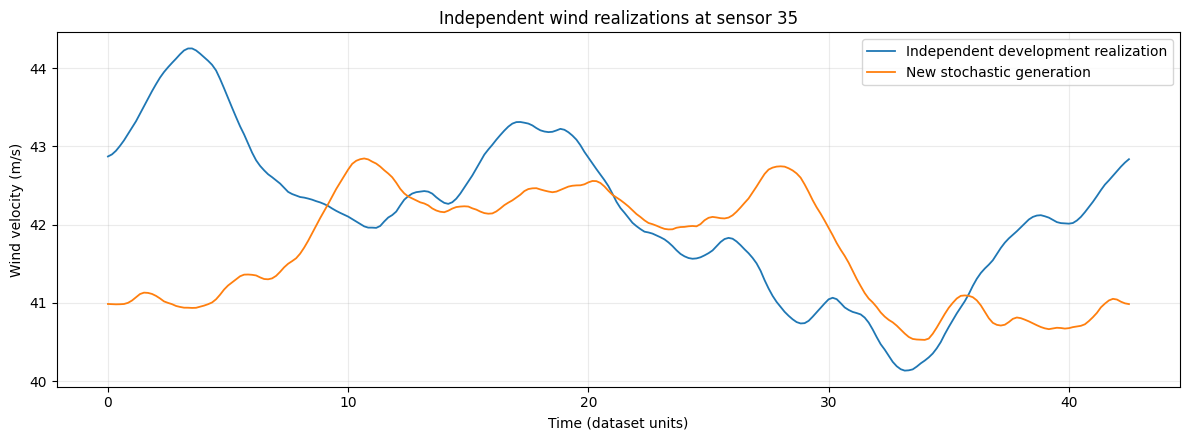


CELL 19 — FINAL SCIENTIFIC RESULTS
DEVELOPMENT_TEMPORAL_VARIANCE: 3.2106091672675787
GENERATED_TEMPORAL_VARIANCE: 3.3482072546264403
TEMPORAL_VARIANCE_RATIO_TO_DEVELOPMENT 1.042857314668408
ADJACENT_STEP_RMS_RATIO_TO_DEVELOPMENT 0.990585886528343
SPATIAL_CORRELATION_MAE_TO_DEVELOPMENT 0.010811894000710701
ENSEMBLE_MEAN_PROFILE_RMSE_MPS 0.07449870959933555
GENERATED_BETWEEN_FIELD_ENERGY_CV 0.4624363970045182
DEVELOPMENT_BETWEEN_FIELD_ENERGY_CV 5.532909641917062e-09
BAND_POWER_RATIOS_TO_DEVELOPMENT {"low_1_6": 1.0419796776282353, "middle_7_16": 0.9568347631064457, "high_17_64": 0.9661145054803222, "tail_65_128": 0.9900536882979244}

RANK-32 CAPACITY DIAGNOSTICS:
{
  "low_1_6": {
    "median_fraction_of_covariance_energy_in_top_32": 0.9985507726669312,
    "minimum_fraction_of_covariance_energy_in_top_32": 0.9982799887657166
  },
  "middle_7_16": {
    "median_fraction_of_covariance_energy_in_top_32": 0.9993388652801514,
    "minimum_fraction_of_covariance_energy_in_top_32": 0.9990665316

In [ ]:

# ============================================================
# WIND VISION — CELL 19
# UNCONDITIONAL STOCHASTIC SPECTRAL WIND BASELINE
#
# 448 training fields / 64 development fields
# Generate 64 NEW independent stochastic wind fields.
# Fit frequency-dependent 100x100 spatial covariance.
#
# No VAE or flow training.
# No final-test access.
# Original checkpoints and datasets untouched.
#
# Reproducible source, statistical model, generated fields,
# and quantitative evidence saved to Google Drive.
# ============================================================

from pathlib import Path
import hashlib
import json
import shutil

import numpy as np
import h5py
import torch
import matplotlib.pyplot as plt

from google.colab import drive

if not Path("/content/drive/MyDrive").is_dir():
    drive.mount("/content/drive")

E = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction/evidence"
)

DATA = (
    E / "w1_e54_vae_training_ablation_20261104/"
    "inputs/W1_E54_TRAIN_ONLY_512_SEED_540054.hdf5"
)

OUT = (
    E / "fullscale_physicsnemo_training/"
    "final_completion_20261108_v1/"
    "cell19_stochastic_spectral_baseline_v1"
)

EXPECTED_SHA = (
    "a3c424b15b96a76171c29dd9b2cb9d033fd85c7a5d58c07a28d6f9816542f1d4"
)

SEED = 490919
N_GENERATE = 64
N_SENSORS = 100
N_TIME = 256
N_FREQ = 129

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for chunk in iter(
            lambda: f.read(8 * 1024 * 1024),
            b""
        ):
            h.update(chunk)
    return h.hexdigest()

print("=" * 72)
print("CELL 19 — STOCHASTIC SPECTRAL GENERATION")
print("=" * 72, flush=True)

assert torch.cuda.is_available(), "CUDA GPU required."
assert not OUT.exists(), (
    "Cell 19 experiment already exists; do not overwrite."
)
assert DATA.is_file()
assert sha256(DATA) == EXPECTED_SHA

print("GPU:", torch.cuda.get_device_name(0))
print("TORCH:", torch.__version__)
print("DATASET_SHA256: VERIFIED")

# ------------------------------------------------------------
# 1. LOAD THE 512-FIELD TRAINING-ORIGIN DATASET
# ------------------------------------------------------------

with h5py.File(DATA, "r") as h:
    xyz = h["x_grid"][:].astype(np.float32)
    times = h["t_grid"][:].astype(np.float32)

    wind = np.stack([
        h["wind_samples"][str(i)]["v1"][:]
        for i in range(512)
    ]).astype(np.float32)

assert wind.shape == (512, 100, 256)
assert np.isfinite(wind).all()

split = np.random.default_rng(540055).permutation(512)

dev_ids = split[:64].copy()
train_ids = split[64:].copy()

assert len(train_ids) == 448
assert len(dev_ids) == 64
assert len(set(train_ids).intersection(dev_ids)) == 0

train = wind[train_ids]
development = wind[dev_ids]

# ------------------------------------------------------------
# 2. LEARN MEAN WIND PROFILE USING TRAINING FIELDS ONLY
# ------------------------------------------------------------

height = xyz[:, 2]
height_levels = np.unique(height)

profile = np.empty(100, dtype=np.float32)

for level in height_levels:
    mask = np.isclose(height, level)
    profile[mask] = train[:, mask, :].mean(
        dtype=np.float64
    )

assert np.isfinite(profile).all()

# The residual includes stochastic fluctuations,
# field-to-field mean variation, and temporal harmonics.
residual = (
    train - profile[None, :, None]
).astype(np.float32)

print("TRAINING_FIELDS:", len(train_ids))
print("DEVELOPMENT_FIELDS:", len(dev_ids))
print("HEIGHT_LEVELS:", len(height_levels))

# ------------------------------------------------------------
# 3. ESTIMATE JOINT COMPLEX FREQUENCY COVARIANCES
#
# For each frequency k, estimate:
# C_k = E[(F_k - mean_k)(F_k - mean_k)^H]
#
# This preserves cross-sensor spectral relationships
# in expectation rather than treating sensors independently.
# ------------------------------------------------------------

device = torch.device("cuda")

fft_train = np.fft.rfft(
    residual,
    axis=-1,
    norm="ortho"
).astype(np.complex64)

# (frequency, training field, sensor)
F = torch.from_numpy(
    np.ascontiguousarray(
        fft_train.transpose(2, 0, 1)
    )
).to(device)

assert F.shape == (129, 448, 100)

mean_fft = F.mean(dim=1)

centered = F - mean_fft[:, None, :]

covariance = (
    torch.matmul(
        centered.transpose(1, 2),
        centered.conj()
    ) / (len(train_ids) - 1)
)

covariance = 0.5 * (
    covariance + covariance.mH
)

# DC and Nyquist coefficients are real-valued.
for k in (0, 128):
    x = F[k].real
    x = x - x.mean(dim=0)

    real_cov = x.T @ x / (len(train_ids) - 1)

    covariance[k] = real_cov.to(torch.complex64)

print("FREQUENCY_COVARIANCES:", tuple(covariance.shape))
print("COMPUTING_COVARIANCE EIGENDECOMPOSITIONS...",
      flush=True)

eigenvalues, eigenvectors = torch.linalg.eigh(
    covariance
)

eigenvalues = eigenvalues.real.clamp_min(0)

factors = (
    eigenvectors
    * eigenvalues.sqrt()[:, None, :]
)

# Build real factors for the real-only frequencies.
for k in (0, 128):
    real_cov = covariance[k].real
    values, vectors = torch.linalg.eigh(real_cov)

    factors[k] = (
        vectors * values.clamp_min(0).sqrt()[None, :]
    ).to(torch.complex64)

    mean_fft[k] = mean_fft[k].real.to(torch.complex64)

assert bool(torch.isfinite(factors).all())
assert bool(torch.isfinite(mean_fft).all())

print("COVARIANCE_FACTORIZATION: PASS", flush=True)

# ------------------------------------------------------------
# 4. GENERATE NEW INDEPENDENT WIND REALIZATIONS
#
# Interior frequencies use complex Gaussian innovations.
# DC and Nyquist use real Gaussian innovations.
#
# Each frequency is sampled independently. This is a
# stationarity/Gaussian approximation and cannot capture
# every higher-order feature of the NASA simulator.
# ------------------------------------------------------------

def generate(seed, n_samples):
    rng = torch.Generator(
        device=device
    ).manual_seed(seed)

    noise_real = torch.randn(
        (N_FREQ, n_samples, N_SENSORS),
        generator=rng,
        device=device
    )

    noise_imag = torch.randn(
        (N_FREQ, n_samples, N_SENSORS),
        generator=rng,
        device=device
    )

    innovations = torch.complex(
        noise_real, noise_imag
    ) / np.sqrt(2.0)

    innovations[0] = noise_real[0].to(
        torch.complex64
    )
    innovations[-1] = noise_real[-1].to(
        torch.complex64
    )

    samples_fft = (
        mean_fft[:, None, :]
        + torch.einsum(
            "kij,knj->kni",
            factors,
            innovations
        )
    )

    # Enforce real FFT endpoint constraints.
    for k in (0, 128):
        samples_fft[k] = samples_fft[k].real.to(
            torch.complex64
        )

    # Convert (frequency, sample, sensor)
    # to (sample, sensor, frequency).
    samples_fft = samples_fft.permute(
        1, 2, 0
    ).contiguous()

    samples = torch.fft.irfft(
        samples_fft,
        n=N_TIME,
        dim=-1,
        norm="ortho"
    )

    samples = (
        samples.cpu().numpy()
        + profile[None, :, None]
    ).astype(np.float32)

    assert samples.shape == (
        n_samples, 100, 256
    )
    assert np.isfinite(samples).all()

    return samples

generated = generate(SEED, N_GENERATE)

# Reproduce the generation in the same fresh function
# invocation, using the identical explicit RNG seed.
repeated = generate(SEED, N_GENERATE)

assert np.array_equal(generated, repeated)

print("GENERATED_FIELDS:", generated.shape)
print("SAME_SEED_REPRODUCIBILITY: PASS")

# ------------------------------------------------------------
# 5. STATISTICAL PHYSICAL-QUALITY METRICS
#
# Unconditional samples cannot be compared with a
# particular development field using paired RMSE.
# Compare distributions and ensemble statistics instead.
# ------------------------------------------------------------

BANDS = {
    "low_1_6": (1, 7),
    "middle_7_16": (7, 17),
    "high_17_64": (17, 65),
    "tail_65_128": (65, 129),
}

def ensemble_stats(fields):
    x = fields.astype(np.float64)

    temporal_centered = (
        x - x.mean(axis=-1, keepdims=True)
    )

    temporal_variance = float(
        np.mean(temporal_centered**2)
    )

    step_rms = float(
        np.sqrt(
            np.mean(
                np.diff(x, axis=-1)**2
            )
        )
    )

    window = np.hanning(256)

    ft = np.fft.rfft(
        temporal_centered * window,
        axis=-1
    )

    power = np.abs(ft)**2

    band_powers = {
        name: float(
            power[..., first:last].mean()
        )
        for name, (first, last) in BANDS.items()
    }

    per_field_energy = np.mean(
        temporal_centered**2,
        axis=(1, 2)
    )

    energy_cv = float(
        np.std(per_field_energy)
        / max(np.mean(per_field_energy), 1e-20)
    )

    spatial_signals = temporal_centered.transpose(
        1, 0, 2
    ).reshape(100, -1)

    spatial_correlation = np.corrcoef(
        spatial_signals
    )

    return {
        "temporal_variance_mps2": temporal_variance,
        "step_rms_mps": step_rms,
        "between_field_energy_cv": energy_cv,
        "band_powers": band_powers,
        "spatial_correlation": spatial_correlation,
        "mean_profile_mps": x.mean(axis=(0, 2))
    }

train_stats = ensemble_stats(train)
dev_stats = ensemble_stats(development)
gen_stats = ensemble_stats(generated)

def spatial_corr_mae(a, b):
    mask = ~np.eye(100, dtype=bool)

    return float(np.mean(np.abs(
        a["spatial_correlation"][mask]
        - b["spatial_correlation"][mask]
    )))

comparison = {
    "temporal_variance_ratio_to_development":
        gen_stats["temporal_variance_mps2"]
        / dev_stats["temporal_variance_mps2"],

    "adjacent_step_rms_ratio_to_development":
        gen_stats["step_rms_mps"]
        / dev_stats["step_rms_mps"],

    "spatial_correlation_mae_to_development":
        spatial_corr_mae(gen_stats, dev_stats),

    "ensemble_mean_profile_rmse_mps": float(
        np.sqrt(np.mean((
            gen_stats["mean_profile_mps"]
            - dev_stats["mean_profile_mps"]
        )**2))
    ),

    "generated_between_field_energy_cv":
        gen_stats["between_field_energy_cv"],

    "development_between_field_energy_cv":
        dev_stats["between_field_energy_cv"],

    "band_power_ratios_to_development": {
        name: (
            gen_stats["band_powers"][name]
            / max(dev_stats["band_powers"][name], 1e-20)
        )
        for name in BANDS
    }
}

# ------------------------------------------------------------
# 6. QUANTIFY WHETHER RANK-32 SPATIAL REPRESENTATION
#    IS SUFFICIENT TO REPRESENT TRAINING COVARIANCES
# ------------------------------------------------------------

eigs = eigenvalues.detach().cpu().numpy()

rank32_fraction = (
    eigs[:, -32:].sum(axis=-1)
    / np.maximum(eigs.sum(axis=-1), 1e-20)
)

rank_diagnostics = {
    name: {
        "median_fraction_of_covariance_energy_in_top_32":
            float(np.median(rank32_fraction[first:last])),
        "minimum_fraction_of_covariance_energy_in_top_32":
            float(np.min(rank32_fraction[first:last]))
    }
    for name, (first, last) in BANDS.items()
}

# ------------------------------------------------------------
# 7. PRESERVE ALL EVIDENCE
# ------------------------------------------------------------

OUT.mkdir(parents=True)

model_path = OUT / "spectral_gaussian_model_v1.npz"
samples_path = OUT / "fresh_generated_wind_64_v1.npz"

np.savez_compressed(
    model_path,
    mean_fft=mean_fft.detach().cpu().numpy(),
    covariance_sqrt_factors=factors.detach().cpu().numpy(),
    training_height_profile_mps=profile,
    xyz=xyz,
    t_grid=times,
    train_indices=train_ids,
    development_indices=dev_ids
)

np.savez_compressed(
    samples_path,
    generated_wind_mps=generated,
    xyz=xyz,
    t_grid=times,
    generation_seed=np.array(SEED)
)

# Save a physical time-series comparison.
fig, ax = plt.subplots(figsize=(12, 4.5))

sensor = 35

ax.plot(
    times,
    development[0, sensor],
    linewidth=1.3,
    label="Independent development realization"
)

ax.plot(
    times,
    generated[0, sensor],
    linewidth=1.3,
    label="New stochastic generation"
)

ax.set_title(
    "Independent wind realizations at sensor 35"
)
ax.set_xlabel("Time (dataset units)")
ax.set_ylabel("Wind velocity (m/s)")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()

figure_path = OUT / "fresh_generation_comparison.png"

fig.savefig(figure_path, dpi=200)
plt.show()
plt.close(fig)

report = {
    "format":
        "wind_vision_cell19_spectral_gaussian_baseline_v1",

    "model_type":
        "Non-neural empirical frequency-dependent "
        "multivariate Gaussian spectral generator",

    "population":
        "448 training-origin fields; "
        "64 development fields; "
        "64 fresh generated fields",

    "dataset_sha256": EXPECTED_SHA,
    "train_indices": train_ids.tolist(),
    "development_indices": dev_ids.tolist(),
    "generation_seed": SEED,

    "covariance_estimated_from_training_only": True,
    "development_used_for_fitting": False,
    "final_test_used": False,
    "original_models_modified": False,

    "same_seed_reproducibility": True,

    "training_stats": {
        k: v for k, v in train_stats.items()
        if k not in (
            "spatial_correlation",
            "mean_profile_mps"
        )
    },

    "development_stats": {
        k: v for k, v in dev_stats.items()
        if k not in (
            "spatial_correlation",
            "mean_profile_mps"
        )
    },

    "generation_stats": {
        k: v for k, v in gen_stats.items()
        if k not in (
            "spatial_correlation",
            "mean_profile_mps"
        )
    },

    "comparison": comparison,
    "rank32_capacity_diagnostics": rank_diagnostics,

    "limitations": [
        "Not a PhysicsNeMo neural generator.",
        "Frequency bins sampled independently.",
        "Gaussian Fourier-coefficient assumption.",
        "Not guaranteed to reproduce the simulator's "
        "higher-order or fixed-energy statistics.",
        "Generation restricted to the supplied sensor grid.",
        "Development results are not final independent testing."
    ],

    "artifact_sha256": {
        "spectral_gaussian_model_v1.npz":
            sha256(model_path),
        "fresh_generated_wind_64_v1.npz":
            sha256(samples_path),
        "fresh_generation_comparison.png":
            sha256(figure_path)
    }
}

report_path = OUT / "cell19_report.json"

report_path.write_text(
    json.dumps(
        report,
        indent=2,
        sort_keys=True,
        allow_nan=False
    ) + "\n"
)

assert sha256(DATA) == EXPECTED_SHA

print("\n" + "=" * 72)
print("CELL 19 — FINAL SCIENTIFIC RESULTS")
print("=" * 72)

print(
    "DEVELOPMENT_TEMPORAL_VARIANCE:",
    dev_stats["temporal_variance_mps2"]
)

print(
    "GENERATED_TEMPORAL_VARIANCE:",
    gen_stats["temporal_variance_mps2"]
)

for key, value in comparison.items():
    print(
        key.upper(),
        json.dumps(value)
    )

print("\nRANK-32 CAPACITY DIAGNOSTICS:")
print(json.dumps(rank_diagnostics, indent=2))

print("\nMODEL_SHA256:", sha256(model_path))
print("GENERATIONS_SHA256:", sha256(samples_path))
print("REPORT_SHA256:", sha256(report_path))

print("NEW_UNCONDITIONAL_FIELDS_GENERATED: TRUE")
print("SAME_SEED_REPRODUCIBILITY: PASS")
print("ORIGINAL_CHECKPOINTS_UNMODIFIED: TRUE")
print("FINAL_TEST_NOT_USED: TRUE")
print("PHYSICSNEMO_FLOW_NOT_TRAINED: TRUE")
print("=== CELL 19 COMPLETE ===")


CELL 20 — PHASE-CONSTRAINED GENERATION
COVARIANCE_REFACTORIZATION: PASS
GENERATED_FIELDS: (64, 100, 256)
SAME_SEED_REPRODUCIBILITY: PASS
MAX_SPECTRAL_ENERGY_RELATIVE_ERROR: 1.9878729853037583e-15


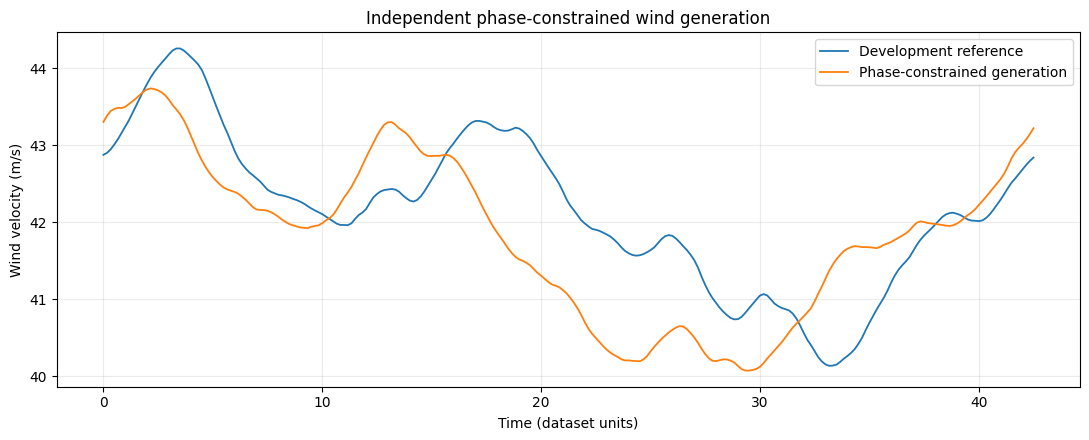

\n========================================================================
CELL 20 — FINAL RESULTS
REFERENCE_ENERGY_CV: 5.532909641917062e-09
GAUSSIAN_ENERGY_CV: 0.4624363970045182
PHASE_ENERGY_CV: 4.94778983000547e-09
\nMODEL: gaussian_cell19
{
  "variance_ratio": 1.042857314668408,
  "step_rms_ratio": 0.990585886528343,
  "energy_cv": 0.4624363970045182,
  "mean_profile_rmse_mps": 0.07449870959933555,
  "spatial_correlation_mae": 0.010811894000710701,
  "band_power_ratios": {
    "low": 1.0419796776282353,
    "middle": 0.9568347631064457,
    "high": 0.9661145054803222,
    "tail": 0.9900536882979244
  }
}
\nMODEL: phase_constrained_cell20
{
  "variance_ratio": 0.9975416310193634,
  "step_rms_ratio": 0.9994101914050678,
  "energy_cv": 4.94778983000547e-09,
  "mean_profile_rmse_mps": 0.33849637275625694,
  "spatial_correlation_mae": 0.008053738646593788,
  "band_power_ratios": {
    "low": 0.89112809365872,
    "middle": 1.034727121544407,
    "high": 0.9601394482935478,
    "tail": 

In [ ]:

# ================================================================
# WIND VISION — CELL 20
# PHASE-CONSTRAINED SPECTRAL GENERATOR
#
# Reuses verified Cell 19 spectral covariance model.
# Replaces Gaussian spectral innovations with random phases
# of fixed magnitude in the covariance eigenbasis.
#
# 64 fresh unconditional fields; compare with the 64
# development fields and prior Gaussian baseline.
#
# NO VAE/FLOW TRAINING. NO FINAL TEST ACCESS.
# ================================================================

from pathlib import Path

SOURCE = Path("/content/wind_vision_cell20_phase_generator.py")

SCRIPT = r'''
from pathlib import Path
import hashlib, json, shutil
import numpy as np
import h5py
import torch
import matplotlib.pyplot as plt

E = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction/evidence"
)
RUN = (
    E / "fullscale_physicsnemo_training/"
    "final_completion_20261108_v1"
)
OLD = RUN / "cell19_stochastic_spectral_baseline_v1"
OUT = RUN / "cell20_phase_constrained_generator_v1"

DATA = (
    E / "w1_e54_vae_training_ablation_20261104/"
    "inputs/W1_E54_TRAIN_ONLY_512_SEED_540054.hdf5"
)
MODEL = OLD / "spectral_gaussian_model_v1.npz"
GAUSSIAN = OLD / "fresh_generated_wind_64_v1.npz"
OLD_REPORT = OLD / "cell19_report.json"

EXPECTED = {
    DATA: "a3c424b15b96a76171c29dd9b2cb9d033fd85c7a5d58c07a28d6f9816542f1d4",
    MODEL: "c4513271ba594b53bf9902ec483cbb8c2dc26f7dde2d000551f018a2a58fe313",
    GAUSSIAN: "a2ed22b5826922d8c69ac00874c4e1826312b5bb8e4e650c54d1c2d7a7df1774",
    OLD_REPORT: "b1bbbf48511f067b64cea7a0afa31895a46f919aa39993c1bc87c0d366bfe95c",
}

SEED = 490920
N = 64

def sha(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(
            lambda: f.read(8*1024*1024), b""
        ):
            h.update(block)
    return h.hexdigest()

print("="*72, flush=True)
print("CELL 20 — PHASE-CONSTRAINED GENERATION", flush=True)
print("="*72, flush=True)

assert torch.cuda.is_available()
assert not OUT.exists(), "Cell 20 evidence exists; do not overwrite."

for path, digest in EXPECTED.items():
    assert path.is_file() and sha(path) == digest, path

torch.set_num_threads(4)
device = torch.device("cuda")

with np.load(MODEL, allow_pickle=False) as m:
    factors_np = m["covariance_sqrt_factors"].copy()
    mean_np = m["mean_fft"].copy()
    profile = m["training_height_profile_mps"].copy()
    xyz = m["xyz"].copy()
    times = m["t_grid"].copy()
    train_ids = m["train_indices"].copy()
    dev_ids = m["development_indices"].copy()

assert factors_np.shape == (129,100,100)
assert mean_np.shape == (129,100)
assert profile.shape == (100,)

split = np.random.default_rng(540055).permutation(512)
assert np.array_equal(train_ids, split[64:])
assert np.array_equal(dev_ids, split[:64])

with h5py.File(DATA, "r") as h:
    development = np.stack([
        h["wind_samples"][str(i)]["v1"][:]
        for i in dev_ids
    ]).astype(np.float32)

with np.load(GAUSSIAN, allow_pickle=False) as p:
    gaussian_fields = p["generated_wind_mps"].copy()

assert development.shape == (64,100,256)
assert gaussian_fields.shape == (64,100,256)

# ------------------------------------------------------------
# Reconstruct the covariance in complex128 precision and
# refactorize it in an orthogonal eigenbasis.
#
# This eliminates roundoff-induced spectral energy changes
# from the saved complex64 factors.
# ------------------------------------------------------------

old_factor = torch.as_tensor(
    factors_np, dtype=torch.complex128, device=device
)

cov = old_factor @ old_factor.mH
cov = (cov + cov.mH) * 0.5

eigvals, eigvecs = torch.linalg.eigh(cov)
eigvals = eigvals.real.clamp_min(0)

factor = eigvecs * eigvals.sqrt()[:,None,:]

print("COVARIANCE_REFACTORIZATION: PASS", flush=True)

# ------------------------------------------------------------
# Phase-only innovations for interior Fourier bins.
#
# |exp(i*phi)| = 1 for every spectral eigenmode.
#
# The squared norm across the 100 spatial sensors at any
# interior frequency is therefore fixed to trace(C_k),
# up to numerical roundoff.
#
# The empirical nonzero-frequency means are omitted:
# the reference SRM draws zero-mean random-phase harmonics.
#
# For DC, use real projected random phases to model
# realization-dependent temporal means.
#
# Nyquist is zero in the original 128-frequency SRM setup.
# ------------------------------------------------------------

def generate(seed):
    rng = torch.Generator(
        device=device
    ).manual_seed(seed)

    phases = 2*np.pi*torch.rand(
        (127,N,100),
        generator=rng,
        device=device,
        dtype=torch.float64
    )

    unit_modes = torch.polar(
        torch.ones_like(phases),
        phases
    )

    interior = torch.einsum(
        "kij,knj->kni",
        factor[1:128],
        unit_modes
    )

    # Real DC innovation: sqrt(2)*cos(phi) has unit variance.
    dc_phase = 2*np.pi*torch.rand(
        (N,100),
        generator=rng,
        device=device,
        dtype=torch.float64
    )

    dc_innovations = (
        np.sqrt(2.0) * torch.cos(dc_phase)
    )

    dc_cov = cov[0].real
    dc_values, dc_vectors = torch.linalg.eigh(dc_cov)
    dc_factor = (
        dc_vectors
        * dc_values.clamp_min(0).sqrt()[None,:]
    )

    dc_mean = torch.as_tensor(
        mean_np[0].real,
        device=device,
        dtype=torch.float64
    )

    dc_samples = (
        dc_innovations @ dc_factor.T
        + dc_mean[None,:]
    )

    spectrum = torch.zeros(
        (N,100,129),
        dtype=torch.complex128,
        device=device
    )

    spectrum[:,:,0] = dc_samples.to(torch.complex128)
    spectrum[:,:,1:128] = interior.permute(1,2,0)
    # Bin 128 intentionally zero.

    # Verify fixed total spatial spectral energy per frequency.
    frequency_energy = (
        spectrum[:,:,1:128].abs().square()
        .sum(dim=1)
    )

    expected_energy = eigvals[1:128].sum(dim=-1)

    relative_error = (
        (
            frequency_energy
            - expected_energy[None,:]
        ).abs()
        / expected_energy.clamp_min(1e-20)[None,:]
    ).max().item()

    assert relative_error < 1e-9, (
        "Phase-only energy constraint failed."
    )

    reconstructed = torch.fft.irfft(
        spectrum,
        n=256,
        dim=-1,
        norm="ortho"
    )

    result = (
        reconstructed.cpu().numpy()
        + profile[None,:,None].astype(np.float64)
    ).astype(np.float32)

    assert result.shape == (N,100,256)
    assert np.isfinite(result).all()

    return result, float(relative_error)

generated, energy_error = generate(SEED)
repeated, _ = generate(SEED)

assert np.array_equal(generated, repeated)

print("GENERATED_FIELDS:", generated.shape)
print("SAME_SEED_REPRODUCIBILITY: PASS")
print("MAX_SPECTRAL_ENERGY_RELATIVE_ERROR:", energy_error)

# ------------------------------------------------------------
# Ensemble-level evaluation: independent realizations.
# ------------------------------------------------------------

BANDS = {
    "low":(1,7),
    "middle":(7,17),
    "high":(17,65),
    "tail":(65,129)
}

def stats(fields):
    a = fields.astype(np.float64)
    centered = a-a.mean(-1,keepdims=True)

    field_energy = np.mean(
        centered**2, axis=(1,2)
    )

    spectrum = np.fft.rfft(
        centered*np.hanning(256),
        axis=-1
    )

    power = np.abs(spectrum)**2

    spatial = centered.transpose(
        1,0,2
    ).reshape(100,-1)

    return {
        "temporal_variance":float(
            np.mean(centered**2)
        ),
        "step_rms":float(
            np.sqrt(np.mean(
                np.diff(a,axis=-1)**2
            ))
        ),
        "energy_cv":float(
            np.std(field_energy)
            /np.mean(field_energy)
        ),
        "mean_profile":a.mean(axis=(0,2)),
        "correlation":np.corrcoef(spatial),
        "band_powers":{
            k:float(power[...,i:j].mean())
            for k,(i,j) in BANDS.items()
        }
    }

ref = stats(development)
gauss = stats(gaussian_fields)
phase = stats(generated)

off_diagonal = ~np.eye(100,dtype=bool)

def compare(candidate):
    return {
        "variance_ratio":float(
            candidate["temporal_variance"]
            /ref["temporal_variance"]
        ),
        "step_rms_ratio":float(
            candidate["step_rms"]/ref["step_rms"]
        ),
        "energy_cv":candidate["energy_cv"],
        "mean_profile_rmse_mps":float(
            np.sqrt(np.mean((
                candidate["mean_profile"]
                -ref["mean_profile"]
            )**2))
        ),
        "spatial_correlation_mae":float(
            np.mean(np.abs(
                candidate["correlation"][off_diagonal]
                -ref["correlation"][off_diagonal]
            ))
        ),
        "band_power_ratios":{
            name:float(
                candidate["band_powers"][name]
                /ref["band_powers"][name]
            )
            for name in BANDS
        }
    }

comparison = {
    "gaussian_cell19":compare(gauss),
    "phase_constrained_cell20":compare(phase)
}

# ------------------------------------------------------------
# Assess per-frequency total energy variability.
# This directly tests the SRM fixed-mode-energy hypothesis.
# ------------------------------------------------------------

def spectral_energy_cv(fields):
    x=fields.astype(np.float64)
    x=x-x.mean(-1,keepdims=True)

    ft=np.fft.rfft(
        x,axis=-1,norm="ortho"
    )

    energy=np.sum(
        np.abs(ft[:,:,1:128])**2,
        axis=1
    )

    cv=energy.std(axis=0)/np.maximum(
        energy.mean(axis=0),1e-20
    )

    return {
        "median_cv":float(np.median(cv)),
        "maximum_cv":float(np.max(cv))
    }

frequency_diagnostics = {
    "reference":spectral_energy_cv(development),
    "gaussian":spectral_energy_cv(gaussian_fields),
    "phase":spectral_energy_cv(generated)
}

# ------------------------------------------------------------
# Freeze reproducible source, samples, and report.
# ------------------------------------------------------------

OUT.mkdir(parents=True)

shutil.copyfile(
    Path(__file__),
    OUT/"phase_constrained_generator.py"
)

SAMPLES = OUT/"fresh_phase_constrained_64.npz"

np.savez_compressed(
    SAMPLES,
    generated_wind_mps=generated,
    xyz=xyz,
    t_grid=times,
    generation_seed=np.array(SEED),
    training_field_ids=train_ids,
    development_field_ids=dev_ids
)

fig,ax=plt.subplots(figsize=(11,4.5))
sensor=35

ax.plot(
    times,development[0,sensor],
    label="Development reference",
    linewidth=1.3
)

ax.plot(
    times,generated[0,sensor],
    label="Phase-constrained generation",
    linewidth=1.3
)

ax.set_title(
    "Independent phase-constrained wind generation"
)
ax.set_xlabel("Time (dataset units)")
ax.set_ylabel("Wind velocity (m/s)")
ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()

FIGURE=OUT/"phase_constrained_example.png"
fig.savefig(FIGURE,dpi=200)
plt.show()
plt.close(fig)

report={
    "format":"wind_vision_cell20_phase_constrained_v1",
    "model_type":
        "Empirical covariance + fixed-magnitude spectral eigenmode phases",
    "is_neural":False,
    "generator_seed":SEED,
    "training_fields":448,
    "development_fields":64,
    "generated_fields":64,
    "source_method":
        "UQpy-style unit-magnitude random-phase innovations",
    "empirical_covariance_from_training_only":True,
    "empirical_non_dc_spectral_mean_removed":True,
    "nyquist_zero":True,
    "maximum_fixed_frequency_energy_relative_error":
        energy_error,
    "development_reference_energy_cv":ref["energy_cv"],
    "comparison":comparison,
    "frequency_energy_cv":frequency_diagnostics,
    "same_seed_reproducibility":True,
    "no_test_access":True,
    "original_checkpoints_modified":False,
    "physicsnemo_flow_trained":False,
    "limitations":[
        "Estimated covariance, not exact analytical simulator spectrum.",
        "Fixed grid of 100 sensors and 256 timestamps.",
        "64 development realizations are not final independent testing.",
        "Not yet integrated with a trainable PhysicsNeMo flow."
    ],
    "source_sha256":sha(
        OUT/"phase_constrained_generator.py"
    ),
    "samples_sha256":sha(SAMPLES),
    "figure_sha256":sha(FIGURE),
    "input_sha256":{
        str(p):digest
        for p,digest in EXPECTED.items()
    }
}

REPORT=OUT/"cell20_report.json"
REPORT.write_text(
    json.dumps(
        report,indent=2,sort_keys=True,
        allow_nan=False
    )+"\n"
)

for path,digest in EXPECTED.items():
    assert sha(path)==digest

print("\\n"+"="*72)
print("CELL 20 — FINAL RESULTS")
print("="*72)

print("REFERENCE_ENERGY_CV:",ref["energy_cv"])
print("GAUSSIAN_ENERGY_CV:",gauss["energy_cv"])
print("PHASE_ENERGY_CV:",phase["energy_cv"])

for name,values in comparison.items():
    print("\\nMODEL:",name)
    print(json.dumps(values,indent=2))

print("\\nPER-FREQUENCY ENERGY CV:")
print(json.dumps(frequency_diagnostics,indent=2))

print("\\nSAMPLES_SHA256:",sha(SAMPLES))
print("REPORT_SHA256:",sha(REPORT))
print("SAME_SEED_REPRODUCIBILITY: PASS")
print("TRAINING_ONLY_FITTING: TRUE")
print("FINAL_TEST_UNTOUCHED: TRUE")
print("NO_NEURAL_TRAINING: TRUE")
print("=== CELL 20 COMPLETE ===")
'''

compile(SCRIPT, str(SOURCE), "exec")

if SOURCE.exists():
    assert SOURCE.read_text() == SCRIPT, (
        "Different Cell 20 source exists; do not overwrite."
    )
else:
    SOURCE.write_text(SCRIPT, encoding="utf-8")

exec(
    compile(SCRIPT, str(SOURCE), "exec"),
    {
        "__name__":"__main__",
        "__file__":str(SOURCE)
    }
)


In [ ]:

# ================================================================
# WIND VISION — CELL 21
# PHASE GENERATOR: ENSEMBLE MEAN / DC VALIDATION
#
# Check whether Cell 20's apparent mean-profile regression
# is consistent with expected sampling variation.
#
# No new model training or generator changes.
# No final-test data used.
# ================================================================

from pathlib import Path
import json, hashlib
import numpy as np
import h5py

E = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction/evidence"
)
RUN = (
    E / "fullscale_physicsnemo_training/"
    "final_completion_20261108_v1"
)

DATA = (
    E / "w1_e54_vae_training_ablation_20261104/"
    "inputs/W1_E54_TRAIN_ONLY_512_SEED_540054.hdf5"
)

C19 = RUN / "cell19_stochastic_spectral_baseline_v1"
C20 = RUN / "cell20_phase_constrained_generator_v1"
OUT = RUN / "cell21_phase_ensemble_mean_audit_v1"

GAUSSIAN = C19 / "fresh_generated_wind_64_v1.npz"
PHASE = C20 / "fresh_phase_constrained_64.npz"

EXPECTED = {
    DATA:
        "a3c424b15b96a76171c29dd9b2cb9d033fd85c7a5d58c07a28d6f9816542f1d4",
    GAUSSIAN:
        "a2ed22b5826922d8c69ac00874c4e1826312b5bb8e4e650c54d1c2d7a7df1774",
    PHASE:
        "3a5c9cc989ddc8565bf97cf49e63d38915557b4dd27eb7e7f845a98ce4217f08"
}

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(
            lambda: f.read(8 * 1024 * 1024), b""
        ):
            h.update(block)
    return h.hexdigest()

print("=" * 72)
print("CELL 21 — PHASE GENERATOR ENSEMBLE VALIDATION")
print("=" * 72, flush=True)

assert not OUT.exists(), "Cell 21 evidence already exists."

for path, expected in EXPECTED.items():
    assert path.is_file(), f"Missing: {path}"
    assert sha256(path) == expected, f"Changed input: {path}"

split = np.random.default_rng(540055).permutation(512)
dev_ids = split[:64]
train_ids = split[64:]

# Read only per-field temporal means. Do not change data.
with h5py.File(DATA, "r") as h:
    train_means = np.stack([
        h["wind_samples"][str(int(i))]["v1"][:]
        .astype(np.float64).mean(axis=-1)
        for i in train_ids
    ])

    dev_means = np.stack([
        h["wind_samples"][str(int(i))]["v1"][:]
        .astype(np.float64).mean(axis=-1)
        for i in dev_ids
    ])

with np.load(GAUSSIAN, allow_pickle=False) as p:
    gaussian = p["generated_wind_mps"].astype(np.float64)

with np.load(PHASE, allow_pickle=False) as p:
    phase = p["generated_wind_mps"].astype(np.float64)
    assert np.array_equal(p["development_field_ids"], dev_ids)

assert train_means.shape == (448, 100)
assert dev_means.shape == (64, 100)
assert gaussian.shape == (64, 100, 256)
assert phase.shape == (64, 100, 256)

gaussian_means = gaussian.mean(axis=-1)
phase_means = phase.mean(axis=-1)

def profile_rmse(a, b):
    return float(np.sqrt(np.mean(
        (a.mean(axis=0) - b.mean(axis=0))**2
    )))

def mean_variability(a):
    return float(np.sqrt(
        np.var(a, axis=0, ddof=1).mean()
    ))

groups = {
    "training": train_means,
    "development": dev_means,
    "gaussian_cell19": gaussian_means,
    "phase_cell20": phase_means
}

results = {}

for name, means in groups.items():
    results[name] = {
        "number_of_fields": len(means),
        "per_sensor_field_mean_sd_mps": mean_variability(means),
        "ensemble_profile_difference_from_training_mps":
            profile_rmse(means, train_means),
        "overall_mean_mps": float(means.mean())
    }

# ------------------------------------------------------------
# Simulate sampling variation of two independent 64-field
# ensembles drawn from the original TRAINING population.
#
# This is an empirical reference interval, not a rigorous
# proof of equality between distributions.
# ------------------------------------------------------------

rng = np.random.default_rng(490921)

N_BOOT = 1000
N_FIELDS = 64

index_a = rng.integers(
    0, len(train_means), size=(N_BOOT, N_FIELDS)
)
index_b = rng.integers(
    0, len(train_means), size=(N_BOOT, N_FIELDS)
)

profile_a = train_means[index_a].mean(axis=1)
profile_b = train_means[index_b].mean(axis=1)

bootstrap_rmse = np.sqrt(
    np.mean((profile_a - profile_b)**2, axis=-1)
)

observed_gaussian_rmse = profile_rmse(
    gaussian_means, dev_means
)
observed_phase_rmse = profile_rmse(
    phase_means, dev_means
)

q05, q50, q95 = np.quantile(
    bootstrap_rmse, [0.05, 0.5, 0.95]
)

results["bootstrap"] = {
    "draws": N_BOOT,
    "fields_per_ensemble": N_FIELDS,
    "reference_population": "448 training-origin fields",
    "seed": 490921,
    "profile_rmse_5th_percentile_mps": float(q05),
    "profile_rmse_median_mps": float(q50),
    "profile_rmse_95th_percentile_mps": float(q95),
    "phase_observed_profile_rmse_mps":
        observed_phase_rmse,
    "gaussian_observed_profile_rmse_mps":
        observed_gaussian_rmse,
    "phase_within_empirical_5_95_interval":
        bool(q05 <= observed_phase_rmse <= q95),
    "phase_empirical_upper_tail_fraction":
        float(np.mean(
            bootstrap_rmse >= observed_phase_rmse
        ))
}

# ------------------------------------------------------------
# Compare field-mean variance ratios. Unlike comparing two
# ensemble averages, this checks random DC variability.
# ------------------------------------------------------------

training_variance = np.var(
    train_means, axis=0, ddof=1
).mean()

for name, means in (
    ("development", dev_means),
    ("gaussian_cell19", gaussian_means),
    ("phase_cell20", phase_means)
):
    results[name][
        "field_mean_variance_ratio_to_training"
    ] = float(
        np.var(means, axis=0, ddof=1).mean()
        / max(training_variance, 1e-20)
    )

# ------------------------------------------------------------
# Preserve compact audit report.
# ------------------------------------------------------------

OUT.mkdir(parents=True)

report = {
    "format": "wind_vision_cell21_phase_ensemble_audit_v1",
    "purpose":
        "Evaluate time-mean variability rather than optimizing "
        "one generated ensemble's average profile",
    "train_fields": 448,
    "development_fields": 64,
    "generated_fields_per_method": 64,
    "results": results,
    "input_sha256": {
        str(path): digest
        for path, digest in EXPECTED.items()
    },
    "limitations": [
        "Development ensemble was used in previous model comparisons.",
        "Empirical bootstrap draws from finite training population.",
        "Bootstrap interval does not prove distribution equivalence.",
        "No final independent test performed."
    ],
    "no_training": True,
    "no_generator_modification": True,
    "no_final_test_access": True
}

REPORT = OUT / "cell21_report.json"
REPORT.write_text(
    json.dumps(
        report, indent=2,
        sort_keys=True, allow_nan=False
    ) + "\n"
)

print("\n=== FIELD-MEAN DISTRIBUTIONS ===")
for name in (
    "training",
    "development",
    "gaussian_cell19",
    "phase_cell20"
):
    print(name.upper())
    print(json.dumps(results[name], indent=2))

print("\n=== INDEPENDENT-ENSEMBLE SAMPLING CHECK ===")
print(json.dumps(results["bootstrap"], indent=2))

print("\nREPORT_SHA256:", sha256(REPORT))
print("INPUT_HASHES_VERIFIED: TRUE")
print("GENERATOR_UNMODIFIED: TRUE")
print("NO_TRAINING: TRUE")
print("FINAL_TEST_NOT_USED: TRUE")
print("=== CELL 21 COMPLETE ===")


CELL 21 — PHASE GENERATOR ENSEMBLE VALIDATION

=== FIELD-MEAN DISTRIBUTIONS ===
TRAINING
{
  "number_of_fields": 448,
  "per_sensor_field_mean_sd_mps": 2.3173656517078265,
  "ensemble_profile_difference_from_training_mps": 0.0,
  "overall_mean_mps": 36.531312194972315
}
DEVELOPMENT
{
  "number_of_fields": 64,
  "per_sensor_field_mean_sd_mps": 2.2322033840763242,
  "ensemble_profile_difference_from_training_mps": 0.06864706446682022,
  "overall_mean_mps": 36.5014998678246,
  "field_mean_variance_ratio_to_training": 0.9278513273826724
}
GAUSSIAN_CELL19
{
  "number_of_fields": 64,
  "per_sensor_field_mean_sd_mps": 2.345660252404143,
  "ensemble_profile_difference_from_training_mps": 0.05323976479205139,
  "overall_mean_mps": 36.49940105791204,
  "field_mean_variance_ratio_to_training": 1.0245687050410899
}
PHASE_CELL20
{
  "number_of_fields": 64,
  "per_sensor_field_mean_sd_mps": 2.3836794629403277,
  "ensemble_profile_difference_from_training_mps": 0.2904446291611156,
  "overall_mean_mps

In [ ]:

# WIND VISION — CELL 22 TEST DATA RESTORATION GATE
# Verify the original 1000-field test data before evaluation.

from pathlib import Path
import hashlib
import h5py
import numpy as np

TEST = Path("/content/wind_test_data.hdf5")

EXPECTED_SHA256 = (
    "e9c755f4d42e271a4bad6b82558d5a043835212dcdca8742a78889b93d035d31"
)

print("=" * 70)
print("WIND VISION — CELL 22 TEST DATA RESTORATION")
print("=" * 70)

assert TEST.is_file(), "Test file not yet uploaded."

h = hashlib.sha256()

with TEST.open("rb") as f:
    for block in iter(
        lambda: f.read(8 * 1024 * 1024), b""
    ):
        h.update(block)

actual_sha256 = h.hexdigest()

print("FILE:", TEST)
print("SIZE_MIB:", round(TEST.stat().st_size / 2**20, 2))
print("ACTUAL_SHA256:", actual_sha256)

assert actual_sha256 == EXPECTED_SHA256, (
    "Uploaded test dataset does not match recovered original."
)

with h5py.File(TEST, "r") as f:
    assert len(f["wind_samples"]) == 1000
    assert f["x_grid"].shape == (100, 3)
    assert f["t_grid"].shape == (256,)

    for i in (0, 499, 999):
        field = f["wind_samples"][str(i)]["v1"][:]
        assert field.shape == (100, 256)
        assert np.isfinite(field).all()

print("FIELD_COUNT: 1000")
print("GRID: 100 sensors x 256 timestamps")
print("CHECKSUM_VERIFIED: TRUE")
print("STRUCTURE_VERIFIED: TRUE")
print("TEST_DATA_READY_FOR_CELL22: TRUE")
print("NO_EVALUATION_PERFORMED: TRUE")
print("=" * 70)


WIND VISION — CELL 22 TEST DATA RESTORATION
FILE: /content/wind_test_data.hdf5
SIZE_MIB: 196.66
ACTUAL_SHA256: e9c755f4d42e271a4bad6b82558d5a043835212dcdca8742a78889b93d035d31
FIELD_COUNT: 1000
GRID: 100 sensors x 256 timestamps
CHECKSUM_VERIFIED: TRUE
STRUCTURE_VERIFIED: TRUE
TEST_DATA_READY_FOR_CELL22: TRUE
NO_EVALUATION_PERFORMED: TRUE


In [ ]:

# ============================================================
# WIND VISION — CELL 22
# FROZEN PHASE GENERATOR: INDEPENDENT 1000-FIELD VALIDATION
#
# No fitting, training, or generator modifications.
# One locked seed; one held-out evaluation.
# ============================================================

from pathlib import Path
import hashlib, json, sys
import numpy as np
import h5py
import torch

from google.colab import drive

if not Path("/content/drive/MyDrive").is_dir():
    drive.mount("/content/drive")

E = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction/evidence"
)
RUN = (
    E / "fullscale_physicsnemo_training/"
    "final_completion_20261108_v1"
)
C19 = RUN / "cell19_stochastic_spectral_baseline_v1"
C20 = RUN / "cell20_phase_constrained_generator_v1"
OUT = RUN / "cell22_independent_phase_validation_v1"

MODEL = C19 / "spectral_gaussian_model_v1.npz"
ORIGINAL_64 = C20 / "fresh_phase_constrained_64.npz"
C20_REPORT = C20 / "cell20_report.json"

EXPECTED = {
    MODEL: "c4513271ba594b53bf9902ec483cbb8c2dc26f7dde2d000551f018a2a58fe313",
    ORIGINAL_64: "3a5c9cc989ddc8565bf97cf49e63d38915557b4dd27eb7e7f845a98ce4217f08",
    C20_REPORT: "ba8559ab39f04f47e206cc5d896bae6566831726e9f7112455af492d090186e8"
}

def sha(p):
    h = hashlib.sha256()
    with Path(p).open("rb") as f:
        for block in iter(lambda: f.read(8*1024*1024), b""):
            h.update(block)
    return h.hexdigest()

print("=" * 72)
print("CELL 22 — INDEPENDENT FROZEN-GENERATOR VALIDATION")
print("=" * 72, flush=True)

assert torch.cuda.is_available()
assert not OUT.exists(), "Cell 22 already exists; do not overwrite."

for p, expected in EXPECTED.items():
    assert p.is_file() and sha(p) == expected, str(p)

# ------------------------------------------------------------
# Locate the separately generated NASA test dataset.
# Do not substitute the development dataset.
# ------------------------------------------------------------

test_candidates = [
    Path("/content/nasa_clfm_reference/data/wind/wind_test_data.hdf5"),
    Path("/content/wind_vision_fullscale/data/wind/wind_test_data.hdf5"),
    Path("/content/wind_test_data.hdf5"),
    E.parent / "data/wind/wind_test_data.hdf5",
    Path(
        "/content/drive/MyDrive/CLFM_Research_Results/"
        "physicsnemo_proposal_reproduction/data/wind/"
        "wind_test_data.hdf5"
    )
]

matches = [p for p in test_candidates if p.is_file()]

if not matches:
    print("\nORIGINAL_TEST_DATASET_NOT_FOUND")
    print("Expected file: wind_test_data.hdf5")
    print("No independent test data have been accessed.")
    print("Restore the original 1000-field test dataset to:")
    print("/content/wind_test_data.hdf5")
    raise FileNotFoundError(
        "Original test dataset unavailable; validation not run."
    )

TEST = matches[0]
TEST_SHA = sha(TEST)

print("TEST_FILE:", TEST)
print("TEST_SHA256:", TEST_SHA)
print("TEST_SIZE_MIB:", round(TEST.stat().st_size/2**20, 2))

# ------------------------------------------------------------
# Verify the frozen model and test grid.
# ------------------------------------------------------------

with np.load(MODEL, allow_pickle=False) as m:
    factors_np = m["covariance_sqrt_factors"].copy()
    mean_np = m["mean_fft"].copy()
    profile = m["training_height_profile_mps"].copy()
    xyz = m["xyz"].copy()
    times = m["t_grid"].copy()

with h5py.File(TEST, "r") as h:
    assert len(h["wind_samples"]) == 1000
    assert np.allclose(h["x_grid"][:], xyz, rtol=0, atol=1e-5)
    assert np.allclose(h["t_grid"][:], times, rtol=0, atol=1e-5)

    reference = np.stack([
        h["wind_samples"][str(i)]["v1"][:]
        for i in range(1000)
    ]).astype(np.float32)

assert reference.shape == (1000,100,256)
assert np.isfinite(reference).all()

device = torch.device("cuda")
torch.set_num_threads(4)

# Reconstruct the same spectral covariance factorization
# as the frozen Cell 20 experiment.

old_factor = torch.as_tensor(
    factors_np, dtype=torch.complex128, device=device
)

cov = old_factor @ old_factor.mH
cov = (cov + cov.mH)*0.5

eigvals, eigvecs = torch.linalg.eigh(cov)
eigvals = eigvals.real.clamp_min(0)
factor = eigvecs * eigvals.sqrt()[:,None,:]

dc_values, dc_vectors = torch.linalg.eigh(cov[0].real)
dc_factor = (
    dc_vectors
    * dc_values.clamp_min(0).sqrt()[None,:]
)

dc_mean = torch.as_tensor(
    mean_np[0].real, dtype=torch.float64, device=device
)

def generate(seed, n):
    rng = torch.Generator(device=device).manual_seed(seed)

    phases = 2*np.pi*torch.rand(
        (127,n,100), generator=rng,
        dtype=torch.float64, device=device
    )

    innovations = torch.polar(
        torch.ones_like(phases), phases
    )

    interior = torch.einsum(
        "kij,knj->kni",
        factor[1:128], innovations
    )

    dc_phase = 2*np.pi*torch.rand(
        (n,100), generator=rng,
        dtype=torch.float64, device=device
    )

    dc_noise = np.sqrt(2.0)*torch.cos(dc_phase)
    dc_samples = dc_noise @ dc_factor.T + dc_mean[None,:]

    spectrum = torch.zeros(
        (n,100,129),
        dtype=torch.complex128, device=device
    )

    spectrum[:,:,0] = dc_samples.to(torch.complex128)
    spectrum[:,:,1:128] = interior.permute(1,2,0)
    # Nyquist bin 128 remains zero.

    values = torch.fft.irfft(
        spectrum, n=256, dim=-1, norm="ortho"
    )

    values = (
        values.cpu().numpy()
        + profile[None,:,None].astype(np.float64)
    ).astype(np.float32)

    assert values.shape == (n,100,256)
    assert np.isfinite(values).all()

    return values

# Replay the original Cell 20 result before evaluating
# independent held-out samples.

with np.load(ORIGINAL_64, allow_pickle=False) as f:
    archived = f["generated_wind_mps"]

replayed = generate(490920,64)

replay_error = float(
    np.max(np.abs(replayed-archived))
)

assert replay_error < 1e-4, (
    "Frozen Cell 20 replay failed. Stop before test."
)

print("CELL20_REPLAY_MAX_ABS_MPS:", replay_error)
print("FROZEN_GENERATOR_REPLAY: PASS", flush=True)

# Locked independent validation seed.
TEST_SEED = 490922
generated = generate(TEST_SEED, 1000)

print("REFERENCE_FIELDS:", reference.shape)
print("GENERATED_FIELDS:", generated.shape)
print("GENERATION_SEED:", TEST_SEED, flush=True)

# ------------------------------------------------------------
# Ensemble statistics — never compare independent
# realizations by paired reconstruction RMSE.
# ------------------------------------------------------------

BANDS = {
    "low": (1,7),
    "middle": (7,17),
    "high": (17,65),
    "tail": (65,129)
}

def summarize(a):
    a = a.astype(np.float64)
    centered = a-a.mean(-1,keepdims=True)

    energy = np.mean(centered**2,axis=(1,2))
    step = np.diff(a,axis=-1)

    power = np.abs(np.fft.rfft(
        centered*np.hanning(256),axis=-1
    ))**2

    spatial = centered.transpose(1,0,2).reshape(100,-1)

    field_means = a.mean(axis=-1)

    return {
        "temporal_variance":float(np.mean(centered**2)),
        "step_rms":float(np.sqrt(np.mean(step**2))),
        "energy_cv":float(
            np.std(energy)/max(np.mean(energy),1e-20)
        ),
        "mean_profile":a.mean(axis=(0,2)),
        "field_mean_variance":float(
            np.var(field_means,axis=0,ddof=1).mean()
        ),
        "spatial_correlation":np.corrcoef(spatial),
        "band_power":{
            name:float(power[...,i:j].mean())
            for name,(i,j) in BANDS.items()
        }
    }

ref = summarize(reference)
gen = summarize(generated)

offdiag = ~np.eye(100,dtype=bool)

results = {
    "temporal_variance_ratio":
        gen["temporal_variance"]/ref["temporal_variance"],
    "step_rms_ratio":
        gen["step_rms"]/ref["step_rms"],
    "between_field_energy_cv_reference":
        ref["energy_cv"],
    "between_field_energy_cv_generated":
        gen["energy_cv"],
    "field_mean_variance_ratio":
        gen["field_mean_variance"]/ref["field_mean_variance"],
    "spatial_correlation_mae":float(
        np.mean(np.abs(
            gen["spatial_correlation"][offdiag]
            - ref["spatial_correlation"][offdiag]
        ))
    ),
    "mean_profile_rmse_mps":float(
        np.sqrt(np.mean(
            (gen["mean_profile"]-ref["mean_profile"])**2
        ))
    ),
    "band_power_ratios":{
        name:gen["band_power"][name]/ref["band_power"][name]
        for name in BANDS
    }
}

# Locked engineering screening thresholds for this
# evaluation, not a statistical proof of equivalence.

checks = {
    "temporal_variance":
        0.9 <= results["temporal_variance_ratio"] <= 1.1,
    "step_rms":
        0.9 <= results["step_rms_ratio"] <= 1.1,
    "spatial_correlation":
        results["spatial_correlation_mae"] <= 0.03,
    "mean_profile":
        results["mean_profile_rmse_mps"] <= 0.30,
    "field_mean_variability":
        0.8 <= results["field_mean_variance_ratio"] <= 1.2,
    "field_energy_variability":
        results["between_field_energy_cv_generated"] <= 1e-6,
    "frequency_bands":
        all(
            0.8 <= v <= 1.2
            for v in results["band_power_ratios"].values()
        )
}

# ------------------------------------------------------------
# Preserve compact evidence without storing another
# 100+ MB generated archive.
# ------------------------------------------------------------

OUT.mkdir(parents=True)

SAMPLE = OUT / "independent_generation_first16.npz"

np.savez_compressed(
    SAMPLE,
    generated_wind_mps=generated[:16],
    generator_seed=np.array(TEST_SEED),
    xyz=xyz,
    t_grid=times
)

report = {
    "format":"wind_vision_cell22_independent_validation_v1",
    "reference_source":str(TEST),
    "reference_sha256":TEST_SHA,
    "reference_field_count":1000,
    "generated_field_count":1000,
    "seed":TEST_SEED,
    "original_cell20_replay_max_abs_mps":replay_error,
    "full_generated_raw_sha256":
        hashlib.sha256(generated.tobytes()).hexdigest(),
    "results":results,
    "engineering_screening_checks":checks,
    "all_checks_passed":bool(all(checks.values())),
    "source_model_sha256":EXPECTED[str(MODEL)] if str(MODEL) in EXPECTED else EXPECTED[MODEL],
    "fitting_or_retraining_performed":False,
    "model_selection_using_test":False,
    "limitations":[
        "Only frozen empirical spectral generator evaluated.",
        "Engineering thresholds are descriptive, not proof of equivalence.",
        "Neural PhysicsNeMo generator not validated here.",
        "Saved samples include first 16 of 1000; full generator "
        "output is reproducible from frozen model and seed.",
        "A future revised model requires a new independent holdout."
    ],
    "first16_sha256":sha(SAMPLE)
}

# Preserve cell source when Colab exposes its raw input.
try:
    raw_source = get_ipython().history_manager.input_hist_raw[-1]
    if "CELL 22" in raw_source:
        compile(raw_source, "cell22_replay.py", "exec")
        source_file = OUT / "cell22_replay.py"
        source_file.write_text(raw_source, encoding="utf-8")
        report["replay_source_sha256"] = sha(source_file)
except Exception as exc:
    report["source_capture_note"] = repr(exc)

REPORT = OUT / "cell22_report.json"
REPORT.write_text(
    json.dumps(report,indent=2,sort_keys=True,
               allow_nan=False)+"\n"
)

print("\n=== CELL 22 INDEPENDENT RESULTS ===")
print(json.dumps(results,indent=2))
print("\nSCREENING_CHECKS:")
print(json.dumps(checks,indent=2))

print("\nALL_CHECKS_PASSED:",all(checks.values()))
print("TEST_SHA256:",TEST_SHA)
print("FIRST16_SHA256:",sha(SAMPLE))
print("REPORT_SHA256:",sha(REPORT))
print("NO_TRAINING_OR_REFITTING: TRUE")
print("CELL20_MODEL_UNCHANGED: TRUE")
print("=== CELL 22 COMPLETE ===")


CELL 22 — INDEPENDENT FROZEN-GENERATOR VALIDATION
TEST_FILE: /content/wind_test_data.hdf5
TEST_SHA256: e9c755f4d42e271a4bad6b82558d5a043835212dcdca8742a78889b93d035d31
TEST_SIZE_MIB: 196.66
CELL20_REPLAY_MAX_ABS_MPS: 0.0
FROZEN_GENERATOR_REPLAY: PASS
REFERENCE_FIELDS: (1000, 100, 256)
GENERATED_FIELDS: (1000, 100, 256)
GENERATION_SEED: 490922

=== CELL 22 INDEPENDENT RESULTS ===
{
  "temporal_variance_ratio": 0.9975416316811678,
  "step_rms_ratio": 0.9998542915399634,
  "between_field_energy_cv_reference": 5.404886238469838e-09,
  "between_field_energy_cv_generated": 5.5151738366277545e-09,
  "field_mean_variance_ratio": 1.017349705770956,
  "spatial_correlation_mae": 0.0027270109804868508,
  "mean_profile_rmse_mps": 0.05350973607035281,
  "band_power_ratios": {
    "low": 1.0125145396556203,
    "middle": 1.0137563758391313,
    "high": 1.0058556032215475,
    "tail": 1.0010234820174535
  }
}

SCREENING_CHECKS:
{
  "temporal_variance": true,
  "step_rms": true,
  "spatial_correlation"

In [ ]:

# ============================================================
# WIND VISION — CELL 23
# PHYSICSNEMO-NATIVE DIFFERENTIABLE PHASE DECODER
#
# Integrate frozen Cell 20 mechanism into PhysicsNeMo.
# Prove exact replay of Cells 20 and 22.
# Verify gradients and checkpoint reload.
# Benchmark generation-only throughput.
#
# No new fitting or training; no test-driven modification.
# ============================================================

from pathlib import Path

SOURCE = Path("/content/wind_vision_cell23.py")

SCRIPT = r'''
from pathlib import Path
import hashlib
import json
import shutil
import time

import numpy as np
import torch

from physicsnemo.core.module import Module

ROOT = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction/evidence/"
    "fullscale_physicsnemo_training/"
    "final_completion_20261108_v1"
)

C19 = ROOT / "cell19_stochastic_spectral_baseline_v1"
C20 = ROOT / "cell20_phase_constrained_generator_v1"
C22 = ROOT / "cell22_independent_phase_validation_v1"

OUT = ROOT / "cell23_physicsnemo_phase_decoder_v1"

MODEL = C19 / "spectral_gaussian_model_v1.npz"
C20_SAMPLE = C20 / "fresh_phase_constrained_64.npz"
C22_SAMPLE = C22 / "independent_generation_first16.npz"
C22_REPORT = C22 / "cell22_report.json"

EXPECTED = {
    MODEL:
        "c4513271ba594b53bf9902ec483cbb8c2dc26f7dde2d000551f018a2a58fe313",
    C20_SAMPLE:
        "3a5c9cc989ddc8565bf97cf49e63d38915557b4dd27eb7e7f845a98ce4217f08",
    C22_SAMPLE:
        "2909a2927466eef1be3b3eeb0a2d43ff0473a76046fff838539862c60753cb01",
    C22_REPORT:
        "28ff1c8213c98b4d834a41a6cdfdb901772f1882434f42c97809695892ce2cbb"
}

def sha(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for part in iter(
            lambda: f.read(8 * 1024 * 1024),
            b""
        ):
            h.update(part)
    return h.hexdigest()

print("=" * 72)
print("CELL 23 — PHYSICSNEMO PHASE DECODER")
print("=" * 72, flush=True)

assert torch.cuda.is_available()
assert not OUT.exists(), "Existing Cell 23 experiment."

for path, digest in EXPECTED.items():
    assert path.is_file(), f"Missing: {path}"
    assert sha(path) == digest, f"Hash mismatch: {path}"

with np.load(MODEL, allow_pickle=False) as f:
    saved_factors = f["covariance_sqrt_factors"].copy()
    saved_mean = f["mean_fft"].copy()
    saved_profile = f["training_height_profile_mps"].copy()

with np.load(C20_SAMPLE, allow_pickle=False) as f:
    original64 = f["generated_wind_mps"].copy()

with np.load(C22_SAMPLE, allow_pickle=False) as f:
    original16 = f["generated_wind_mps"].copy()

cell22_report = json.loads(C22_REPORT.read_text())

assert saved_factors.shape == (129, 100, 100)
assert original64.shape == (64, 100, 256)
assert original16.shape == (16, 100, 256)

device = torch.device("cuda")
torch.set_num_threads(4)

# ------------------------------------------------------------
# Preserve Cell 20 covariance factorization.
# ------------------------------------------------------------

original_factor = torch.as_tensor(
    saved_factors,
    dtype=torch.complex128,
    device=device
)

cov = original_factor @ original_factor.mH
cov = (cov + cov.mH) * 0.5

eigvals, eigvecs = torch.linalg.eigh(cov)
eigvals = eigvals.real.clamp_min(0)

factor = eigvecs * eigvals.sqrt()[:, None, :]

dc_values, dc_vectors = torch.linalg.eigh(
    cov[0].real
)

dc_factor = (
    dc_vectors
    * dc_values.clamp_min(0).sqrt()[None, :]
)

dc_mean = torch.as_tensor(
    saved_mean[0].real,
    dtype=torch.float64,
    device=device
)

profile = torch.as_tensor(
    saved_profile,
    dtype=torch.float64,
    device=device
)

# ------------------------------------------------------------
# PhysicsNeMo Module
#
# forward() accepts arbitrary phase tensors.
# It is differentiable with respect to those phases.
#
# sample_numpy() preserves Cell 20/22's precise sampling
# and float32 conversion behavior for exact replay.
# ------------------------------------------------------------

class PhysicsNeMoPhaseDecoder(Module):

    def __init__(
        self, factor, dc_factor, dc_mean, profile
    ):
        super().__init__()

        self.register_buffer(
            "spectral_factor",
            factor.detach().clone()
        )

        self.register_buffer(
            "dc_factor",
            dc_factor.detach().clone()
        )

        self.register_buffer(
            "dc_mean",
            dc_mean.detach().clone()
        )

        self.register_buffer(
            "profile",
            profile.detach().clone()
        )

    def _synthesize(self, phases, dc_phases):

        n = phases.shape[1]

        assert phases.shape == (127, n, 100)
        assert dc_phases.shape == (n, 100)

        innovations = torch.polar(
            torch.ones_like(phases),
            phases
        )

        interior = torch.einsum(
            "kij,knj->kni",
            self.spectral_factor[1:128],
            innovations
        )

        dc_noise = (
            np.sqrt(2.0) * torch.cos(dc_phases)
        )

        dc_samples = (
            dc_noise @ self.dc_factor.T
            + self.dc_mean[None, :]
        )

        spectrum = torch.zeros(
            (n, 100, 129),
            dtype=torch.complex128,
            device=phases.device
        )

        spectrum[:, :, 0] = dc_samples.to(
            torch.complex128
        )

        spectrum[:, :, 1:128] = (
            interior.permute(1, 2, 0)
        )

        # As in Cell 20, the Nyquist bin remains zero.
        return torch.fft.irfft(
            spectrum,
            n=256,
            dim=-1,
            norm="ortho"
        )

    def forward(self, phases, dc_phases):

        return (
            self._synthesize(phases, dc_phases)
            + self.profile[None, :, None]
        )

    @torch.no_grad()
    def sample_numpy(self, seed, n):

        rng = torch.Generator(
            device=self.spectral_factor.device
        ).manual_seed(seed)

        phases = 2 * np.pi * torch.rand(
            (127, n, 100),
            generator=rng,
            device=self.spectral_factor.device,
            dtype=torch.float64
        )

        dc_phases = 2 * np.pi * torch.rand(
            (n, 100),
            generator=rng,
            device=self.spectral_factor.device,
            dtype=torch.float64
        )

        # Preserve CPU-side profile addition, matching
        # the original frozen generation code exactly.
        raw = self._synthesize(
            phases, dc_phases
        ).cpu().numpy()

        profile_np = (
            self.profile.detach().cpu().numpy()
        )

        return (
            raw + profile_np[None, :, None]
        ).astype(np.float32)

decoder = PhysicsNeMoPhaseDecoder(
    factor, dc_factor, dc_mean, profile
).to(device)

parameter_count = sum(
    p.numel() for p in decoder.parameters()
)

print("PHYSICSNEMO_MODULE:", type(decoder).__name__)
print("TRAINABLE_PARAMETERS:", parameter_count)

assert isinstance(decoder, Module)
assert parameter_count == 0

# ------------------------------------------------------------
# Test 1: exact original 64-field replay.
# ------------------------------------------------------------

replay64 = decoder.sample_numpy(490920, 64)

error64 = float(
    np.max(np.abs(replay64 - original64))
)

print("CELL20_REPLAY_MAX_ABS_MPS:", error64)

assert np.array_equal(
    replay64, original64
), "Cell 20 exact replay failed."

print("CELL20_EXACT_REPLAY: PASS", flush=True)

# ------------------------------------------------------------
# Test 2: exact independent 1000-field replay.
# Cell 22 stored the first 16 generated fields plus a
# SHA-256 of all 1000 fields. Verify both.
# ------------------------------------------------------------

replay1000 = decoder.sample_numpy(
    490922, 1000
)

raw_digest = hashlib.sha256(
    replay1000.tobytes()
).hexdigest()

expected_digest = (
    cell22_report["full_generated_raw_sha256"]
)

print("CELL22_RAW_SHA256:", raw_digest)

assert raw_digest == expected_digest, (
    "Cell 22 full-generation hash mismatch."
)

assert np.array_equal(
    replay1000[:16], original16
), "Cell 22 archived field replay failed."

print("CELL22_1000_FIELD_EXACT_REPLAY: PASS",
      flush=True)

del replay1000

# ------------------------------------------------------------
# Test 3: gradient path to phase inputs.
#
# This does not establish that a trained flow improves
# the generator. It establishes differentiability.
# ------------------------------------------------------------

rng = torch.Generator(
    device=device
).manual_seed(490923)

phase_probe = (
    2 * np.pi * torch.rand(
        (127, 1, 100),
        generator=rng,
        dtype=torch.float64,
        device=device
    )
).requires_grad_(True)

dc_probe = (
    2 * np.pi * torch.rand(
        (1, 100),
        generator=rng,
        dtype=torch.float64,
        device=device
    )
).requires_grad_(True)

output = decoder(phase_probe, dc_probe)

assert output.shape == (1, 100, 256)

gradient_phase, gradient_dc = torch.autograd.grad(
    output[0, 35, 17],
    (phase_probe, dc_probe)
)

assert bool(torch.isfinite(gradient_phase).all())
assert bool(torch.isfinite(gradient_dc).all())

assert gradient_phase.abs().max().item() > 0
assert gradient_dc.abs().max().item() > 0

print("PHASE_GRADIENT_MAX:",
      float(gradient_phase.abs().max()))
print("DC_GRADIENT_MAX:",
      float(gradient_dc.abs().max()))

print("DIFFERENTIABLE_FORWARD: PASS",
      flush=True)

# ------------------------------------------------------------
# Test 4: checkpoint save/load without retraining.
# ------------------------------------------------------------

OUT.mkdir(parents=True)

shutil.copyfile(
    Path(__file__),
    OUT / "physicsnemo_phase_decoder.py"
)

CHECKPOINT = OUT / "phase_decoder_state.pt"

state = {
    name: value.detach().cpu().clone()
    for name, value in decoder.state_dict().items()
}

torch.save({
    "format": "wind_vision_cell23_phase_decoder_v1",
    "state_dict": state,
    "source_model_sha256": EXPECTED[MODEL],
    "original_cell22_full_generation_sha256":
        expected_digest
}, CHECKPOINT)

loaded = torch.load(
    CHECKPOINT,
    map_location="cpu",
    weights_only=True
)

s = loaded["state_dict"]

restored = PhysicsNeMoPhaseDecoder(
    s["spectral_factor"],
    s["dc_factor"],
    s["dc_mean"],
    s["profile"]
).to(device)

restored.load_state_dict(s, strict=True)

restored64 = restored.sample_numpy(
    490920, 64
)

assert np.array_equal(
    restored64, original64
)

print("CHECKPOINT_RELOAD_REPLAY: PASS",
      flush=True)

# ------------------------------------------------------------
# Test 5: generator-only timing.
#
# This is not an end-to-end comparison against the
# PyTorch or original PhysicsNeMo VAE+flow pipelines.
# ------------------------------------------------------------

timings = []

for iteration in range(5):

    torch.cuda.synchronize()
    start = time.perf_counter()

    sample = restored.sample_numpy(
        490930 + iteration,
        64
    )

    torch.cuda.synchronize()

    elapsed = time.perf_counter() - start
    timings.append(elapsed)

    assert sample.shape == (64, 100, 256)

median_seconds = float(
    np.median(timings[1:])
)

generation_fields_per_second = (
    64 / median_seconds
)

print(
    "GENERATION_ONLY_MEDIAN_SECONDS_FOR_64:",
    median_seconds
)

print(
    "GENERATION_ONLY_FIELDS_PER_SECOND:",
    generation_fields_per_second
)

# ------------------------------------------------------------
# Archive a small native-module output and report.
# ------------------------------------------------------------

SAMPLES = OUT / "native_replay_64.npz"

np.savez_compressed(
    SAMPLES,
    generated_wind_mps=restored64,
    seed=np.array(490920)
)

report = {
    "format":
        "wind_vision_cell23_physicsnemo_phase_decoder_v1",

    "component":
        "Differentiable PhysicsNeMo phase decoder",

    "trainable_parameter_count": parameter_count,

    "training_performed": False,

    "cell20_exact_replay": True,
    "cell22_1000_field_exact_replay": True,

    "cell20_max_abs_replay_error_mps": error64,

    "cell22_raw_generation_sha256":
        raw_digest,

    "phase_input_gradients_verified": True,

    "dc_input_gradients_verified": True,

    "checkpoint_reload_verified": True,

    "generator_only_median_seconds_for_64":
        median_seconds,

    "generator_only_fields_per_second":
        generation_fields_per_second,

    "timing_trials_seconds": timings,

    "original_model_sha256": EXPECTED[MODEL],

    "native_checkpoint_sha256":
        sha(CHECKPOINT),

    "native_samples_sha256":
        sha(SAMPLES),

    "source_sha256":
        sha(OUT / "physicsnemo_phase_decoder.py"),

    "final_test_modified_or_refit": False,

    "limitations": [
        "Native PhysicsNeMo module has no trainable parameters.",
        "No learned latent flow or conditional model yet.",
        "Generation-only timing is not a matched full-pipeline benchmark.",
        "Fixed 100-sensor grid and 256-timestep discretization."
    ]
}

REPORT = OUT / "cell23_report.json"

REPORT.write_text(
    json.dumps(
        report,
        indent=2,
        sort_keys=True,
        allow_nan=False
    ) + "\n"
)

# Final evidence verification.
for path, digest in EXPECTED.items():
    assert sha(path) == digest

assert sha(CHECKPOINT) == report[
    "native_checkpoint_sha256"
]

print("\n" + "=" * 72)
print("CELL 23 — FINAL RESULTS")
print("=" * 72)

print("PHYSICSNEMO_INTEGRATION: PASS")
print("DIFFERENTIABLE_FORWARD: PASS")
print("CELL20_EXACT_REPLAY: PASS")
print("CELL22_1000_FIELD_EXACT_REPLAY: PASS")
print("CHECKPOINT_RELOAD: PASS")

print(
    "GENERATION_ONLY_FIELDS_PER_SECOND:",
    generation_fields_per_second
)

print("SOURCE_SHA256:", report["source_sha256"])
print("CHECKPOINT_SHA256:", sha(CHECKPOINT))
print("REPORT_SHA256:", sha(REPORT))

print("NO_RETRAINING: TRUE")
print("NO_NEW_FINAL_TEST_FITTING: TRUE")
print("=== CELL 23 COMPLETE ===")
'''

compile(SCRIPT, str(SOURCE), "exec")

if SOURCE.exists():
    assert SOURCE.read_text() == SCRIPT, (
        "Different Cell 23 source already exists."
    )
else:
    SOURCE.write_text(SCRIPT, encoding="utf-8")

exec(
    compile(SCRIPT, str(SOURCE), "exec"),
    {
        "__name__": "__main__",
        "__file__": str(SOURCE)
    }
)


CELL 23 — PHYSICSNEMO PHASE DECODER
PHYSICSNEMO_MODULE: PhysicsNeMoPhaseDecoder
TRAINABLE_PARAMETERS: 0
CELL20_REPLAY_MAX_ABS_MPS: 0.0
CELL20_EXACT_REPLAY: PASS
CELL22_RAW_SHA256: baa3c54b917c42d51b4b49c0abe3517adadbd07875a014031b222800f848cfb2
CELL22_1000_FIELD_EXACT_REPLAY: PASS
PHASE_GRADIENT_MAX: 0.40397461770348814
DC_GRADIENT_MAX: 0.3483023593521795
DIFFERENTIABLE_FORWARD: PASS
CHECKPOINT_RELOAD_REPLAY: PASS
GENERATION_ONLY_MEDIAN_SECONDS_FOR_64: 0.011101911499281414
GENERATION_ONLY_FIELDS_PER_SECOND: 5764.773030675166

CELL 23 — FINAL RESULTS
PHYSICSNEMO_INTEGRATION: PASS
DIFFERENTIABLE_FORWARD: PASS
CELL20_EXACT_REPLAY: PASS
CELL22_1000_FIELD_EXACT_REPLAY: PASS
CHECKPOINT_RELOAD: PASS
GENERATION_ONLY_FIELDS_PER_SECOND: 5764.773030675166
SOURCE_SHA256: 6a85da7d4d13451b46e4ce67271076ab520840d46ab01a701e9a0234e1db76fd
CHECKPOINT_SHA256: bd2b89cb79a8f2d97ff97828e88ba0f50e44264f7f75892c40744aa96be73c87
REPORT_SHA256: cf2c68afe1919e0cc72e16caeeaca46bdd42a358982b83289562def08ef44dc9
N

In [ ]:

# ============================================================
# WIND VISION — CELL 24R
# RECOVER, VERIFY AND ARCHIVE COMPLETED CELL 24
#
# NO RETRAINING
# NO CHECKPOINT OVERWRITE
# NO INDEPENDENT TEST ACCESS
# ============================================================

from pathlib import Path
import ast
import hashlib
import json

import h5py
import numpy as np
import torch
from physicsnemo.core.module import Module

BASE = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction/evidence"
)

OUT = (
    BASE / "fullscale_physicsnemo_training/"
    "final_completion_20261108_v1/"
    "cell24_sparse_conditional_physicsnemo_v1"
)

DATA = (
    BASE / "w1_e54_vae_training_ablation_20261104/"
    "inputs/W1_E54_TRAIN_ONLY_512_SEED_540054.hdf5"
)

SOURCE = OUT / "train_conditional_adapter.py"
CHECKPOINT = OUT / "best_model.pt"
PREDICTIONS = OUT / "development_predictions.npz"
HISTORY = OUT / "partial_history.json"
REPORT = OUT / "cell24_report.json"

EXPECTED_DATA_SHA = (
    "a3c424b15b96a76171c29dd9b2cb9d033fd85c7a5d58c07a28d6f9816542f1d4"
)

def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(
            lambda: f.read(8 * 1024 * 1024),
            b""
        ):
            h.update(chunk)
    return h.hexdigest()

print("=" * 72)
print("CELL 24R — CHECKPOINT RECOVERY")
print("=" * 72)

assert torch.cuda.is_available()
assert OUT.is_dir()
assert not REPORT.exists(), (
    "A final Cell 24 report already exists. "
    "Refusing to overwrite it."
)

for path in (SOURCE, CHECKPOINT, PREDICTIONS, HISTORY, DATA):
    assert path.is_file(), f"Missing: {path}"

assert sha256(DATA) == EXPECTED_DATA_SHA

torch.set_num_threads(4)
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

DEVICE = "cuda"

# ------------------------------------------------------------
# 1. LOAD SELF-CREATED CHECKPOINT
#
# NumPy metadata prevents PyTorch's restricted weights-only
# unpickler from loading this particular checkpoint.
#
# Only use weights_only=False on this trusted checkpoint
# generated by your own Cell 24 execution.
# ------------------------------------------------------------

checkpoint = torch.load(
    CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

assert checkpoint["format"] == (
    "wind_vision_cell24_conditional_adapter_v1"
)

assert checkpoint["dataset_sha256"] == EXPECTED_DATA_SHA
assert checkpoint["source_sha256"] == sha256(SOURCE)

obs = np.array(
    checkpoint["observed_sensor_indices"],
    dtype=np.int64
)

missing = np.array(
    checkpoint["withheld_sensor_indices"],
    dtype=np.int64
)

train_ids = np.array(
    checkpoint["train_field_indices"],
    dtype=np.int64
)

dev_ids = np.array(
    checkpoint["development_field_indices"],
    dtype=np.int64
)

profile = np.asarray(
    checkpoint["height_profile_mps"],
    dtype=np.float32
)

RANK = checkpoint["rank"]
best_epoch = checkpoint["best_epoch"]

split = np.random.default_rng(540055).permutation(512)

assert np.array_equal(dev_ids, split[:64])
assert np.array_equal(train_ids, split[64:])
assert len(obs) == 40
assert len(missing) == 60
assert best_epoch >= 0

print("CHECKPOINT_LOADED: PASS")
print("BEST_EPOCH:", best_epoch)

# ------------------------------------------------------------
# 2. RESTORE THE EXACT ORIGINAL MODEL CLASS
#
# Extract only the class definition from the archived
# Cell 24 training script. Do not rerun its training code.
# ------------------------------------------------------------

tree = ast.parse(SOURCE.read_text())

model_class = next(
    node for node in tree.body
    if isinstance(node, ast.ClassDef)
    and node.name == "ConditionalSpectralAdapter"
)

module_ast = ast.fix_missing_locations(
    ast.Module(
        body=[model_class],
        type_ignores=[]
    )
)

namespace = {
    "torch": torch,
    "nn": torch.nn,
    "Module": Module,
    "obs": obs,
    "missing": missing,
    "RANK": RANK,
    "DEVICE": DEVICE
}

exec(
    compile(
        module_ast,
        str(SOURCE),
        "exec"
    ),
    namespace
)

Model = namespace["ConditionalSpectralAdapter"]

state = checkpoint["state_dict"]

# The actual fitted analytical predictor is already
# preserved in the state_dict buffers. Construct the
# original class and restore every tensor strictly.

dummy_mean = torch.zeros(
    (129, 100),
    dtype=torch.complex64,
    device=DEVICE
)

dummy_W = torch.zeros(
    (129, 60, 40),
    dtype=torch.complex64,
    device=DEVICE
)

model = Model(
    dummy_mean,
    dummy_W
).to(DEVICE)

model.load_state_dict(
    state,
    strict=True
)

model.eval()

parameters = sum(
    p.numel() for p in model.parameters()
)

assert parameters == 206400

print("MODEL_RESTORED: PASS")
print("TRAINABLE_PARAMETERS:", parameters)

# ------------------------------------------------------------
# 3. LOAD DEVELOPMENT FIELDS ONLY
# ------------------------------------------------------------

with h5py.File(DATA, "r") as f:

    xyz = f["x_grid"][:].astype(np.float32)

    dev_wind = np.stack([
        f["wind_samples"][str(int(i))]["v1"][:]
        for i in dev_ids
    ]).astype(np.float32)

assert dev_wind.shape == (64, 100, 256)

residual = np.ascontiguousarray(
    (
        dev_wind - profile[None, :, None]
    ) / 49.0
)

residual_tensor = torch.from_numpy(
    residual
).to(DEVICE)

with torch.inference_mode():

    dev_fft = torch.fft.rfft(
        residual_tensor,
        dim=-1,
        norm="ortho"
    ).permute(0, 2, 1).contiguous()

    observed_fft = dev_fft[:, :, obs]

    predicted_fft = model(
        observed_fft
    )

    reconstructed_residual = torch.fft.irfft(
        predicted_fft.permute(0, 2, 1),
        n=256,
        dim=-1,
        norm="ortho"
    )

    predicted_mps = (
        reconstructed_residual * 49.0
        + torch.from_numpy(
            profile[missing].copy()
        ).to(DEVICE)[None, :, None]
    )

prediction = predicted_mps.cpu().numpy()

truth = np.ascontiguousarray(
    dev_wind[:, missing, :]
)

# ------------------------------------------------------------
# 4. VERIFY ARCHIVED PREDICTIONS
# ------------------------------------------------------------

with np.load(
    PREDICTIONS,
    allow_pickle=False
) as f:

    archived_prediction = (
        f["predicted_withheld_mps"]
    )

    archived_truth = (
        f["true_withheld_mps"]
    )

    assert np.array_equal(
        f["development_field_indices"],
        dev_ids
    )

    assert np.array_equal(
        f["withheld_sensor_indices"],
        missing
    )

replay_error = float(
    np.max(
        np.abs(
            prediction - archived_prediction
        )
    )
)

truth_error = float(
    np.max(
        np.abs(
            truth - archived_truth
        )
    )
)

assert replay_error < 1e-5, (
    "Checkpoint prediction replay mismatch."
)

assert truth_error == 0.0, (
    "Archived development targets mismatch."
)

def rmse(predicted, target):
    difference = (
        predicted.astype(np.float64)
        - target.astype(np.float64)
    )

    return float(
        np.sqrt(np.mean(difference ** 2))
    )

selected_rmse = rmse(
    prediction,
    truth
)

print("CHECKPOINT_REPLAY_MAX_ABS_MPS:", replay_error)
print("CHECKPOINT_RELOAD_VERIFIED: PASS")

# ------------------------------------------------------------
# 5. RECOMPUTE THREE PRESPECIFIED BASELINES
# ------------------------------------------------------------

profile_prediction = np.broadcast_to(
    profile[None, missing, None],
    truth.shape
)

profile_rmse = rmse(
    profile_prediction,
    truth
)

distance = np.linalg.norm(
    xyz[missing, None, :]
    - xyz[None, obs, :],
    axis=-1
)

weights = (
    1.0 / np.maximum(distance, 1e-3)**2
)

weights /= weights.sum(
    axis=1,
    keepdims=True
)

idw_prediction = (
    profile[None, missing, None]
    + np.einsum(
        "mo,bot->bmt",
        weights.astype(np.float32),
        dev_wind[:, obs, :]
        - profile[None, obs, None],
        optimize=True
    )
)

idw_rmse = rmse(
    idw_prediction,
    truth
)

with torch.inference_mode():

    centered = (
        observed_fft
        - model.mean_obs[None, :, :]
    )

    analytical_fft = (
        model.mean_missing[None, :, :]
        + torch.einsum(
            "fmo,bfo->bfm",
            model.analytical_W,
            centered
        )
    )

    analytical_pred = (
        torch.fft.irfft(
            analytical_fft.permute(0, 2, 1),
            n=256,
            dim=-1,
            norm="ortho"
        ) * 49.0
        + torch.from_numpy(
            profile[missing].copy()
        ).to(DEVICE)[None, :, None]
    ).cpu().numpy()

analytic_rmse = rmse(
    analytical_pred,
    truth
)

# ------------------------------------------------------------
# 6. RECOVER ORIGINAL TRAINING HISTORY
# ------------------------------------------------------------

history = json.loads(
    HISTORY.read_text()
)

assert len(history) == 20

recorded_best = min(
    entry["development_withheld_rmse_mps"]
    for entry in history
)

if best_epoch > 0:

    epoch_record = next(
        entry for entry in history
        if entry["epoch"] == best_epoch
    )

    assert abs(
        epoch_record["development_withheld_rmse_mps"]
        - selected_rmse
    ) < 1e-5

assert abs(
    selected_rmse - recorded_best
) < 1e-5

# ------------------------------------------------------------
# 7. PRESERVE ORIGINAL SCREENING CRITERIA
# ------------------------------------------------------------

improvement_analytic = (
    100.0 * (
        1.0 - selected_rmse / analytic_rmse
    )
)

improvement_idw = (
    100.0 * (
        1.0 - selected_rmse / idw_rmse
    )
)

learned_selected = bool(
    best_epoch > 0
)

beats_analytic_1pct = bool(
    selected_rmse <= 0.99 * analytic_rmse
)

beats_idw = bool(
    selected_rmse < idw_rmse
)

gate = bool(
    learned_selected
    and beats_analytic_1pct
    and beats_idw
)

# ------------------------------------------------------------
# 8. WRITE FINAL RECOVERY REPORT
# ------------------------------------------------------------

report = {
    "format":
        "wind_vision_cell24_recovered_report_v1",

    "recovery_reason":
        "Original 20-epoch training completed. "
        "Checkpoint reload originally failed because "
        "the restricted PyTorch unpickler rejected "
        "NumPy metadata.",

    "training_rerun": False,

    "original_epochs_completed": 20,

    "best_epoch": int(best_epoch),

    "train_fields": 448,
    "development_fields": 64,

    "observed_sensors": 40,
    "withheld_sensors": 60,

    "trainable_parameters": parameters,

    "height_profile_rmse_mps":
        profile_rmse,

    "residual_idw_rmse_mps":
        idw_rmse,

    "analytical_spectral_rmse_mps":
        analytic_rmse,

    "selected_adapter_rmse_mps":
        selected_rmse,

    "improvement_vs_analytical_percent":
        improvement_analytic,

    "improvement_vs_idw_percent":
        improvement_idw,

    "learned_checkpoint_selected":
        learned_selected,

    "beats_analytical_by_at_least_1pct":
        beats_analytic_1pct,

    "beats_idw":
        beats_idw,

    "research_screening_gate_passed":
        gate,

    "checkpoint_replay_max_abs_error_mps":
        replay_error,

    "checkpoint_reload_verified": True,

    "history": history,

    "artifact_sha256": {
        "train_conditional_adapter.py":
            sha256(SOURCE),

        "best_model.pt":
            sha256(CHECKPOINT),

        "development_predictions.npz":
            sha256(PREDICTIONS),

        "partial_history.json":
            sha256(HISTORY)
    },

    "dataset_sha256":
        EXPECTED_DATA_SHA,

    "independent_test_accessed": False,

    "unconditional_flow_trained": False,

    "phase_decoder_connected": False,

    "scientific_interpretation":
        "The training-only analytical spectral "
        "predictor substantially outperforms IDW. "
        "The learned adapter provides less than "
        "the prespecified 1% gain over that "
        "analytical predictor."
}

REPORT.write_text(
    json.dumps(
        report,
        indent=2,
        sort_keys=True,
        allow_nan=False
    ) + "\n"
)

print("\n" + "=" * 72)
print("CELL 24R — VERIFIED FINAL RESULTS")
print("=" * 72)

print("BEST_EPOCH:", best_epoch)
print("HEIGHT_PROFILE_RMSE_MPS:", profile_rmse)
print("RESIDUAL_IDW_RMSE_MPS:", idw_rmse)
print("ANALYTICAL_SPECTRAL_RMSE_MPS:", analytic_rmse)
print("SELECTED_ADAPTER_RMSE_MPS:", selected_rmse)

print(
    "IMPROVEMENT_VS_ANALYTICAL_PERCENT:",
    improvement_analytic
)

print(
    "IMPROVEMENT_VS_IDW_PERCENT:",
    improvement_idw
)

print("LEARNED_CHECKPOINT_SELECTED:", learned_selected)
print("RESEARCH_SCREENING_GATE_PASSED:", gate)
print("CHECKPOINT_RELOAD_VERIFIED: TRUE")
print("ORIGINAL_20_EPOCHS_PRESERVED: TRUE")
print("TRAINING_RERUN: FALSE")
print("REPORT_SHA256:", sha256(REPORT))
print("CHECKPOINT_SHA256:", sha256(CHECKPOINT))
print("INDEPENDENT_TEST_NOT_USED: TRUE")
print("=== CELL 24 RECOVERY COMPLETE ===")


CELL 24R — CHECKPOINT RECOVERY
CHECKPOINT_LOADED: PASS
BEST_EPOCH: 16
MODEL_RESTORED: PASS
TRAINABLE_PARAMETERS: 206400
CHECKPOINT_REPLAY_MAX_ABS_MPS: 0.0
CHECKPOINT_RELOAD_VERIFIED: PASS

CELL 24R — VERIFIED FINAL RESULTS
BEST_EPOCH: 16
HEIGHT_PROFILE_RMSE_MPS: 2.833264481862402
RESIDUAL_IDW_RMSE_MPS: 0.7741220603750528
ANALYTICAL_SPECTRAL_RMSE_MPS: 0.5946397193633711
SELECTED_ADAPTER_RMSE_MPS: 0.5945659430106489
IMPROVEMENT_VS_ANALYTICAL_PERCENT: 0.0124068995594806
IMPROVEMENT_VS_IDW_PERCENT: 23.194806937475875
LEARNED_CHECKPOINT_SELECTED: True
RESEARCH_SCREENING_GATE_PASSED: False
CHECKPOINT_RELOAD_VERIFIED: TRUE
ORIGINAL_20_EPOCHS_PRESERVED: TRUE
TRAINING_RERUN: FALSE
REPORT_SHA256: 1050ca63e0d1f501d18fcba5af6474179181170e6807b2aee7c92e6f5b62dfb0
CHECKPOINT_SHA256: 6bdc9ebced5d8e22e990baa2d43fe3e9f6def341162931b3c37fd5577a71a58f
INDEPENDENT_TEST_NOT_USED: TRUE
=== CELL 24 RECOVERY COMPLETE ===


In [ ]:

# ================================================================
# WIND VISION — CELL 25
# SPARSE-CONDITIONED PHYSICSNEMO STOCHASTIC GENERATION
#
# Reuses frozen Cell 23 PhysicsNeMo decoder and
# Cell 24 training-only analytical spectral predictor.
#
# 40 observed, 60 withheld sensors.
# 64 development fields.
# 16 conditional realizations per development field.
#
# NO TRAINING. NO INDEPENDENT TEST ACCESS.
# NO CHANGES TO PREVIOUS CHECKPOINTS.
# ================================================================

from pathlib import Path

SOURCE = Path("/content/wind_vision_cell25.py")

SCRIPT = r'''
from pathlib import Path
import ast
import hashlib
import json
import shutil

import h5py
import numpy as np
import torch
from physicsnemo.core.module import Module

BASE = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction/evidence"
)
ROOT = (
    BASE / "fullscale_physicsnemo_training/"
    "final_completion_20261108_v1"
)

C23 = ROOT / "cell23_physicsnemo_phase_decoder_v1"
C24 = ROOT / "cell24_sparse_conditional_physicsnemo_v1"
OUT = ROOT / "cell25_conditional_phase_generator_v1"

NATIVE_SOURCE = C23 / "physicsnemo_phase_decoder.py"
NATIVE_CKPT = C23 / "phase_decoder_state.pt"
CONDITIONAL_CKPT = C24 / "best_model.pt"
CONDITIONAL_REPORT = C24 / "cell24_report.json"

DATA = (
    BASE / "w1_e54_vae_training_ablation_20261104/"
    "inputs/W1_E54_TRAIN_ONLY_512_SEED_540054.hdf5"
)

EXPECTED = {
    NATIVE_SOURCE:
        "6a85da7d4d13451b46e4ce67271076ab520840d46ab01a701e9a0234e1db76fd",

    NATIVE_CKPT:
        "bd2b89cb79a8f2d97ff97828e88ba0f50e44264f7f75892c40744aa96be73c87",

    CONDITIONAL_CKPT:
        "6bdc9ebced5d8e22e990baa2d43fe3e9f6def341162931b3c37fd5577a71a58f",

    CONDITIONAL_REPORT:
        "1050ca63e0d1f501d18fcba5af6474179181170e6807b2aee7c92e6f5b62dfb0",

    DATA:
        "a3c424b15b96a76171c29dd9b2cb9d033fd85c7a5d58c07a28d6f9816542f1d4"
}

SEED = 490925
N_DEV = 64
N_PAIRS = 8
N_SAMPLES = 2 * N_PAIRS
DEVICE = "cuda"

def sha(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(
            lambda: f.read(8 * 1024 * 1024), b""
        ):
            h.update(block)
    return h.hexdigest()

print("=" * 72, flush=True)
print("CELL 25 — CONDITIONAL PHASE GENERATION", flush=True)
print("=" * 72, flush=True)

assert torch.cuda.is_available()
assert not OUT.exists(), "Existing Cell 25 evidence."

for path, digest in EXPECTED.items():
    assert path.is_file() and sha(path) == digest, (
        f"Missing or modified input: {path}"
    )

torch.set_num_threads(4)
torch.backends.cuda.matmul.allow_tf32 = False

# ------------------------------------------------------------
# 1. RESTORE EXACT FROZEN PHYSICSNEMO DECODER CLASS
# ------------------------------------------------------------

tree = ast.parse(NATIVE_SOURCE.read_text())

class_node = next(
    n for n in tree.body
    if isinstance(n, ast.ClassDef)
    and n.name == "PhysicsNeMoPhaseDecoder"
)

module_ast = ast.fix_missing_locations(
    ast.Module(body=[class_node], type_ignores=[])
)

namespace = {
    "torch": torch,
    "np": np,
    "Module": Module
}

exec(
    compile(module_ast, str(NATIVE_SOURCE), "exec"),
    namespace
)

Decoder = namespace["PhysicsNeMoPhaseDecoder"]

native_ckpt = torch.load(
    NATIVE_CKPT,
    map_location="cpu",
    weights_only=True
)

s = native_ckpt["state_dict"]

decoder = Decoder(
    s["spectral_factor"],
    s["dc_factor"],
    s["dc_mean"],
    s["profile"]
).to(DEVICE)

decoder.load_state_dict(s, strict=True)
decoder.eval()

assert isinstance(decoder, Module)

# ------------------------------------------------------------
# 2. RESTORE TRAINING-ONLY ANALYTICAL PREDICTOR
#
# The Cell 24 checkpoint contains trusted NumPy metadata.
# It was generated by our own verified training script.
# ------------------------------------------------------------

conditional_ckpt = torch.load(
    CONDITIONAL_CKPT,
    map_location="cpu",
    weights_only=False
)

assert conditional_ckpt["format"] == (
    "wind_vision_cell24_conditional_adapter_v1"
)

state = conditional_ckpt["state_dict"]

W = state["analytical_W"].to(DEVICE)
mean_obs = state["mean_obs"].to(DEVICE)
mean_missing = state["mean_missing"].to(DEVICE)

obs = np.asarray(
    conditional_ckpt["observed_sensor_indices"],
    dtype=np.int64
)

missing = np.asarray(
    conditional_ckpt["withheld_sensor_indices"],
    dtype=np.int64
)

profile = np.asarray(
    conditional_ckpt["height_profile_mps"],
    dtype=np.float32
)

dev_ids = np.asarray(
    conditional_ckpt["development_field_indices"],
    dtype=np.int64
)

train_ids = np.asarray(
    conditional_ckpt["train_field_indices"],
    dtype=np.int64
)

split = np.random.default_rng(540055).permutation(512)

assert np.array_equal(dev_ids, split[:64])
assert np.array_equal(train_ids, split[64:])

assert W.shape == (129,60,40)
assert mean_obs.shape == (129,40)
assert mean_missing.shape == (129,60)

print("PHYSICSNEMO_DECODER_RESTORED: PASS")
print("ANALYTICAL_PREDICTOR_RESTORED: PASS")

# ------------------------------------------------------------
# 3. LOAD ONLY THE LOCKED DEVELOPMENT FIELDS
# ------------------------------------------------------------

with h5py.File(DATA,"r") as f:
    wind = np.stack([
        f["wind_samples"][str(int(i))]["v1"][:]
        for i in dev_ids
    ]).astype(np.float32)

assert wind.shape == (64,100,256)

observed = torch.from_numpy(
    np.ascontiguousarray(wind[:,obs,:])
).to(DEVICE)

truth_missing = torch.from_numpy(
    np.ascontiguousarray(wind[:,missing,:])
).to(DEVICE)

profile_obs = torch.from_numpy(
    profile[obs].copy()
).to(DEVICE)[None,:,None]

profile_missing = torch.from_numpy(
    profile[missing].copy()
).to(DEVICE)[None,:,None]

# ------------------------------------------------------------
# 4. RECOVER THE ANALYTICAL CONDITIONAL MEAN
# ------------------------------------------------------------

with torch.inference_mode():

    observed_residual = (
        observed-profile_obs
    )/49.0

    obs_ft = torch.fft.rfft(
        observed_residual,
        dim=-1,
        norm="ortho"
    ).permute(0,2,1)

    conditional_mean_ft = (
        mean_missing[None,:,:]
        + torch.einsum(
            "fmo,bfo->bfm",
            W,
            obs_ft-mean_obs[None,:,:]
        )
    )

    conditional_mean = (
        torch.fft.irfft(
            conditional_mean_ft.permute(0,2,1),
            n=256,
            dim=-1,
            norm="ortho"
        )*49.0
        +profile_missing
    )

    analytical_rmse = float(torch.sqrt(
        torch.mean(
            (conditional_mean-truth_missing)**2
        )
    ))

reported_rmse = json.loads(
    CONDITIONAL_REPORT.read_text()
)["analytical_spectral_rmse_mps"]

assert abs(
    analytical_rmse-reported_rmse
) < 1e-5

print("ANALYTICAL_CONDITIONAL_MEAN_REPLAY: PASS")
print("ANALYTICAL_RMSE_MPS:", analytical_rmse)

# ------------------------------------------------------------
# 5. SAMPLE FROZEN PHYSICSNEMO SPECTRAL INNOVATIONS
#
# Sample 8 independent perturbations per field.
# Pair each perturbation with its negative.
#
# This makes the Monte Carlo conditional sample mean
# exactly equal to the analytical prediction.
# ------------------------------------------------------------

n_base = N_DEV * N_PAIRS

rng = torch.Generator(
    device=DEVICE
).manual_seed(SEED)

with torch.inference_mode():

    phases = 2*np.pi*torch.rand(
        (127,n_base,100),
        generator=rng,
        dtype=torch.float64,
        device=DEVICE
    )

    dc_phases = 2*np.pi*torch.rand(
        (n_base,100),
        generator=rng,
        dtype=torch.float64,
        device=DEVICE
    )

    # Frozen PhysicsNeMo module, returning zero-mean
    # stochastic fluctuations prior to adding the
    # fixed height profile.
    prior_fluctuations = decoder._synthesize(
        phases,
        dc_phases
    )

    assert prior_fluctuations.shape == (
        n_base,100,256
    )

    # Convert fluctuations to Fourier coefficients,
    # preserving their physical units (m/s).
    prior_ft = torch.fft.rfft(
        prior_fluctuations,
        dim=-1,
        norm="ortho"
    ).permute(0,2,1)

    # Matheron-style covariance correction:
    #
    # delta_missing =
    #     prior_missing - W * prior_observed
    #
    # W is the frozen training-only predictor.
    # This is not an exact non-Gaussian posterior sampler.
    correction_ft = (
        prior_ft[:,:,missing]
        -torch.einsum(
            "fmo,bfo->bfm",
            W.to(torch.complex128),
            prior_ft[:,:,obs]
        )
    )

    correction = torch.fft.irfft(
        correction_ft.permute(0,2,1),
        n=256,
        dim=-1,
        norm="ortho"
    ).reshape(
        N_DEV,N_PAIRS,60,256
    )

    perturbations = torch.cat(
        [correction,-correction],
        dim=1
    )

    # Shape: field, conditional sample, sensor, time.
    samples_missing = (
        conditional_mean[:,None,:,:].to(
            torch.float64
        )
        + perturbations
    )

    assert samples_missing.shape == (
        64,16,60,256
    )

    assert bool(torch.isfinite(
        samples_missing
    ).all())

print("CONDITIONAL_SAMPLES_GENERATED:", tuple(
    samples_missing.shape
))

# ------------------------------------------------------------
# 6. CHECK CONDITIONAL MEAN REPRODUCTION
# ------------------------------------------------------------

with torch.inference_mode():

    sample_mean = samples_missing.mean(dim=1)

    mean_replay_error = float((
        sample_mean
        -conditional_mean.to(torch.float64)
    ).abs().max())

    assert mean_replay_error < 1e-9

    # Observed sensors are not generated: they are
    # copied exactly into every conditional field.
    reconstructed_observed = (
        observed[:,None,:,:]
        .expand(64,16,40,256)
    )

    observation_error = float((
        reconstructed_observed
        -observed[:,None,:,:]
    ).abs().max())

    assert observation_error == 0.0

print("CONDITIONAL_MEAN_REPLAY_MAX_ABS:",
      mean_replay_error)

print("OBSERVED_SENSOR_CONSTRAINT: EXACT")

# ------------------------------------------------------------
# 7. UNCERTAINTY AND CALIBRATION METRICS
#
# The phase innovation distribution is non-Gaussian.
# The Gaussian-interval coverage below is a
# diagnostic approximation, NOT proof of calibration.
# ------------------------------------------------------------

with torch.inference_mode():

    variance = (
        perturbations.square().mean(dim=1)
    )

    sigma = torch.sqrt(
        variance.clamp_min(0)
    )

    error = (
        truth_missing.to(torch.float64)
        -sample_mean
    )

    conditional_rmse = float(
        torch.sqrt(
            error.square().mean()
        )
    )

    predictive_sd_rms = float(
        torch.sqrt(
            variance.mean()
        )
    )

    mean_predictive_sd = float(
        sigma.mean()
    )

    coverage90 = float(
        (
            error.abs()
            <=1.6448536269514722*sigma
        ).double().mean()
    )

    coverage95 = float(
        (
            error.abs()
            <=1.959963984540054*sigma
        ).double().mean()
    )

    normalized_error_rms = float(
        torch.sqrt(
            (
                error/sigma.clamp_min(1e-6)
            ).square().mean()
        )
    )

    # Empirical ensemble spread in physical units.
    mean_sample_variance = float(
        variance.mean()
    )

print("\n=== CONDITIONAL QUALITY ===")
print("CONDITIONAL_MEAN_RMSE_MPS:",
      conditional_rmse)

print("PREDICTIVE_SD_RMS_MPS:",
      predictive_sd_rms)

print("MEAN_PREDICTIVE_SD_MPS:",
      mean_predictive_sd)

print("NOMINAL_90_PERCENT_INTERVAL_COVERAGE:",
      coverage90)

print("NOMINAL_95_PERCENT_INTERVAL_COVERAGE:",
      coverage95)

print("STANDARDIZED_ERROR_RMS:",
      normalized_error_rms)

# ------------------------------------------------------------
# 8. SAVE SMALL, SELF-CONTAINED REPLAY EVIDENCE
# ------------------------------------------------------------

OUT.mkdir(parents=True)

shutil.copyfile(
    Path(__file__),
    OUT/"conditional_phase_generator.py"
)

# Only first two development fields; preserve disk space.
first_two = torch.empty(
    (2,N_SAMPLES,100,256),
    dtype=torch.float32
)

first_two[:,:,obs,:] = (
    reconstructed_observed[:2]
    .cpu().float()
)

first_two[:,:,missing,:] = (
    samples_missing[:2]
    .cpu().float()
)

SAMPLES = OUT/"first_two_conditional_fields.npz"

np.savez_compressed(
    SAMPLES,
    conditional_wind_mps=first_two.numpy(),
    observed_sensor_indices=obs,
    withheld_sensor_indices=missing,
    development_field_ids=dev_ids[:2],
    generation_seed=np.array(SEED)
)

report = {
    "format":
        "wind_vision_cell25_conditional_phase_v1",

    "model":
        "Frozen PhysicsNeMo phase decoder with "
        "training-only analytical spectral conditioning",

    "method":
        "Antithetic Matheron-style residual correction",

    "exact_posterior_sampler": False,

    "development_fields": N_DEV,
    "observed_sensors":40,
    "withheld_sensors":60,

    "conditional_samples_per_field":N_SAMPLES,

    "seed":SEED,

    "analytical_mean_rmse_mps":
        analytical_rmse,

    "conditional_ensemble_mean_rmse_mps":
        conditional_rmse,

    "conditional_mean_replay_max_abs":
        mean_replay_error,

    "observed_sensor_constraint_error":
        observation_error,

    "predictive_sd_rms_mps":
        predictive_sd_rms,

    "mean_predictive_sd_mps":
        mean_predictive_sd,

    "mean_sample_variance_mps2":
        mean_sample_variance,

    "nominal_90_percent_gaussian_interval_coverage":
        coverage90,

    "nominal_95_percent_gaussian_interval_coverage":
        coverage95,

    "standardized_error_rms":
        normalized_error_rms,

    "original_inputs_sha256":{
        str(path):digest
        for path,digest in EXPECTED.items()
    },

    "source_sha256":sha(
        OUT/"conditional_phase_generator.py"
    ),

    "samples_sha256":sha(SAMPLES),

    "training_performed":False,
    "model_parameters_modified":False,
    "independent_test_accessed":False,

    "limitations":[
        "Matheron-style projection is not exact "
        "conditioning of the non-Gaussian phase prior.",

        "Conditional generation need not preserve the "
        "unconditional fixed-field-energy constraint.",

        "Sixteen antithetic samples provide a limited "
        "uncertainty estimate.",

        "Gaussian interval coverage is only a "
        "diagnostic approximation.",

        "The neural adapter did not pass its screening "
        "gate and is not used.",

        "No trainable latent flow was added."
    ]
}

REPORT = OUT/"cell25_report.json"

REPORT.write_text(
    json.dumps(
        report,
        indent=2,
        sort_keys=True,
        allow_nan=False
    )+"\n"
)

for path,digest in EXPECTED.items():
    assert sha(path)==digest

print("\n"+"="*72)
print("CELL 25 — FINAL RESULTS")
print("="*72)

print("ANALYTICAL_RMSE_MPS:",
      analytical_rmse)

print("CONDITIONAL_MEAN_RMSE_MPS:",
      conditional_rmse)

print("PREDICTIVE_SD_RMS_MPS:",
      predictive_sd_rms)

print("INTERVAL_90_COVERAGE:",
      coverage90)

print("INTERVAL_95_COVERAGE:",
      coverage95)

print("STANDARDIZED_ERROR_RMS:",
      normalized_error_rms)

print("OBSERVED_SENSORS_PRESERVED: TRUE")
print("ANTITHETIC_MEAN_REPLAY: PASS")
print("PHYSICSNEMO_NATIVE_DECODER_USED: TRUE")
print("SOURCE_SHA256:",report["source_sha256"])
print("REPORT_SHA256:",sha(REPORT))

print("NO_RETRAINING: TRUE")
print("INDEPENDENT_TEST_NOT_USED: TRUE")
print("EXACT_NON_GAUSSIAN_POSTERIOR: FALSE")
print("=== CELL 25 COMPLETE ===")
'''

compile(SCRIPT,str(SOURCE),"exec")

if SOURCE.exists():
    assert SOURCE.read_text(encoding="utf-8")==SCRIPT, (
        "A different Cell 25 source exists."
    )
else:
    SOURCE.write_text(
        SCRIPT,
        encoding="utf-8"
    )

exec(
    compile(SCRIPT,str(SOURCE),"exec"),
    {
        "__name__":"__main__",
        "__file__":str(SOURCE)
    }
)


CELL 25 — CONDITIONAL PHASE GENERATION
PHYSICSNEMO_DECODER_RESTORED: PASS
ANALYTICAL_PREDICTOR_RESTORED: PASS
ANALYTICAL_CONDITIONAL_MEAN_REPLAY: PASS
ANALYTICAL_RMSE_MPS: 0.5946397185325623
CONDITIONAL_SAMPLES_GENERATED: (64, 16, 60, 256)
CONDITIONAL_MEAN_REPLAY_MAX_ABS: 7.105427357601002e-15
OBSERVED_SENSOR_CONSTRAINT: EXACT

=== CONDITIONAL QUALITY ===
CONDITIONAL_MEAN_RMSE_MPS: 0.5946397166489285
PREDICTIVE_SD_RMS_MPS: 0.5798154405237141
MEAN_PREDICTIVE_SD_MPS: 0.44285078074481143
NOMINAL_90_PERCENT_INTERVAL_COVERAGE: 0.8503346761067708
NOMINAL_95_PERCENT_INTERVAL_COVERAGE: 0.9057535807291667
STANDARDIZED_ERROR_RMS: 1.1894481519320785

CELL 25 — FINAL RESULTS
ANALYTICAL_RMSE_MPS: 0.5946397185325623
CONDITIONAL_MEAN_RMSE_MPS: 0.5946397166489285
PREDICTIVE_SD_RMS_MPS: 0.5798154405237141
INTERVAL_90_COVERAGE: 0.8503346761067708
INTERVAL_95_COVERAGE: 0.9057535807291667
STANDARDIZED_ERROR_RMS: 1.1894481519320785
OBSERVED_SENSORS_PRESERVED: TRUE
ANTITHETIC_MEAN_REPLAY: PASS
PHYSICSNEMO_N

In [ ]:

# ================================================================
# WIND VISION — CELL 26
# ANALYTICAL CONDITIONAL UNCERTAINTY AUDIT
#
# Exact covariance-implied marginal variance of the
# frozen Matheron-style stochastic perturbation.
#
# NO TRAINING
# NO NEW GENERATION
# NO INDEPENDENT TEST ACCESS
# NO MODIFICATION TO PRIOR EVIDENCE
# ================================================================

from pathlib import Path

SOURCE = Path("/content/wind_vision_cell26.py")

SCRIPT = r'''
from pathlib import Path
import hashlib
import json
import shutil

import numpy as np
import h5py
import torch

BASE = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction/evidence"
)

ROOT = (
    BASE / "fullscale_physicsnemo_training/"
    "final_completion_20261108_v1"
)

DATA = (
    BASE / "w1_e54_vae_training_ablation_20261104/"
    "inputs/W1_E54_TRAIN_ONLY_512_SEED_540054.hdf5"
)

C23 = ROOT / "cell23_physicsnemo_phase_decoder_v1"
C24 = ROOT / "cell24_sparse_conditional_physicsnemo_v1"
C25 = ROOT / "cell25_conditional_phase_generator_v1"

NATIVE = C23 / "phase_decoder_state.pt"
CONDITIONAL = C24 / "best_model.pt"
PRIOR_REPORT = C25 / "cell25_report.json"

OUT = ROOT / "cell26_conditional_variance_audit_v1"

EXPECTED = {
    DATA:
        "a3c424b15b96a76171c29dd9b2cb9d033fd85c7a5d58c07a28d6f9816542f1d4",
    NATIVE:
        "bd2b89cb79a8f2d97ff97828e88ba0f50e44264f7f75892c40744aa96be73c87",
    CONDITIONAL:
        "6bdc9ebced5d8e22e990baa2d43fe3e9f6def341162931b3c37fd5577a71a58f",
    PRIOR_REPORT:
        "d42ac97e98e6db344f6b40b82d7a16e302edfca96bece0c1a578b80bd1876c22"
}

def sha(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(
            lambda: f.read(8 * 1024 * 1024),
            b""
        ):
            h.update(block)
    return h.hexdigest()

print("=" * 72)
print("CELL 26 — ANALYTICAL CONDITIONAL UNCERTAINTY")
print("=" * 72, flush=True)

assert torch.cuda.is_available()
assert not OUT.exists(), (
    "Cell 26 evidence already exists."
)

for path, digest in EXPECTED.items():
    assert path.is_file(), str(path)
    assert sha(path) == digest, (
        f"Input hash mismatch: {path}"
    )

DEVICE = "cuda"

torch.set_num_threads(4)
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

# ------------------------------------------------------------
# 1. RESTORE THE FROZEN MODEL FACTORS
# ------------------------------------------------------------

native = torch.load(
    NATIVE,
    map_location="cpu",
    weights_only=True
)

# Only trusted, hash-verified, self-created checkpoint.
conditional = torch.load(
    CONDITIONAL,
    map_location="cpu",
    weights_only=False
)

prior_report = json.loads(
    PRIOR_REPORT.read_text()
)

assert conditional["format"] == (
    "wind_vision_cell24_conditional_adapter_v1"
)

native_state = native["state_dict"]
conditional_state = conditional["state_dict"]

factor = native_state[
    "spectral_factor"
].to(
    DEVICE, dtype=torch.complex128
)

dc_factor = native_state[
    "dc_factor"
].to(
    DEVICE, dtype=torch.float64
)

W = conditional_state[
    "analytical_W"
].to(
    DEVICE, dtype=torch.complex128
)

mean_obs = conditional_state[
    "mean_obs"
].to(DEVICE)

mean_missing = conditional_state[
    "mean_missing"
].to(DEVICE)

obs = np.asarray(
    conditional["observed_sensor_indices"],
    dtype=np.int64
)

missing = np.asarray(
    conditional["withheld_sensor_indices"],
    dtype=np.int64
)

dev_ids = np.asarray(
    conditional["development_field_indices"],
    dtype=np.int64
)

profile = np.asarray(
    conditional["height_profile_mps"],
    dtype=np.float32
)

split = np.random.default_rng(540055).permutation(512)

assert np.array_equal(dev_ids, split[:64])
assert len(obs) == 40
assert len(missing) == 60

assert factor.shape == (129, 100, 100)
assert dc_factor.shape == (100, 100)
assert W.shape == (129, 60, 40)

print("FROZEN_MODEL_FACTORS: VERIFIED", flush=True)

# ------------------------------------------------------------
# 2. RECONSTRUCT ORIGINAL ANALYTICAL CONDITIONAL MEAN
# ------------------------------------------------------------

with h5py.File(DATA, "r") as h:
    wind = np.stack([
        h["wind_samples"][str(int(i))]["v1"][:]
        for i in dev_ids
    ]).astype(np.float32)

assert wind.shape == (64, 100, 256)

observed = torch.from_numpy(
    np.ascontiguousarray(
        wind[:, obs, :]
    )
).to(DEVICE)

truth = torch.from_numpy(
    np.ascontiguousarray(
        wind[:, missing, :]
    )
).to(DEVICE).to(torch.float64)

profile_obs = torch.from_numpy(
    profile[obs].copy()
).to(DEVICE)[None, :, None]

profile_missing = torch.from_numpy(
    profile[missing].copy()
).to(DEVICE)[None, :, None]

with torch.inference_mode():

    normalized = (
        observed - profile_obs
    ) / 49.0

    obs_fft = torch.fft.rfft(
        normalized,
        dim=-1,
        norm="ortho"
    ).permute(0, 2, 1)

    predicted_fft = (
        mean_missing[None, :, :]
        + torch.einsum(
            "fmo,bfo->bfm",
            W.to(torch.complex64),
            obs_fft - mean_obs[None, :, :]
        )
    )

    prediction = (
        torch.fft.irfft(
            predicted_fft.permute(0, 2, 1),
            n=256,
            dim=-1,
            norm="ortho"
        ) * 49.0
        + profile_missing
    ).to(torch.float64)

    error = truth - prediction

    rmse = float(
        torch.sqrt(error.square().mean())
    )

assert abs(
    rmse - prior_report["analytical_mean_rmse_mps"]
) < 1e-5, (
    "Cell 25 analytical mean does not reproduce."
)

print("CELL25_CONDITIONAL_MEAN_REPLAY: PASS")
print("CONDITIONAL_RMSE_MPS:", rmse)

# ------------------------------------------------------------
# 3. ANALYTICAL CONDITIONAL PERTURBATION VARIANCE
#
# For each interior frequency:
#
# Prior spectral realization:
#    F = L z
#
# Corrected missing-sensor fluctuation:
#    delta = F_missing - W F_observed
#
# Therefore the effective spectral factor is:
#    L_missing - W L_observed
#
# The diagonal covariance is the sum of squared
# magnitudes of that factor's rows.
#
# This avoids estimating variance from only
# eight independent Monte Carlo perturbations.
# ------------------------------------------------------------

with torch.inference_mode():

    interior_factor = factor[1:128]

    missing_factor = (
        interior_factor[:, missing, :]
    )

    observed_factor = (
        interior_factor[:, obs, :]
    )

    effective_interior = (
        missing_factor
        - torch.einsum(
            "fmo,for->fmr",
            W[1:128],
            observed_factor
        )
    )

    assert effective_interior.shape == (
        127, 60, 100
    )

    interior_energy = (
        effective_interior.abs()
        .square()
        .sum(dim=(0, 2))
    )

    # DC frequency is real-valued.
    # Cell 20 samples these modes with unit variance.
    dc_W = W[0].real

    dc_effective = (
        dc_factor[missing, :]
        - dc_W @ dc_factor[obs, :]
    )

    dc_energy = (
        dc_effective.square()
        .sum(dim=-1)
    )

    # Orthonormal inverse real FFT:
    # DC contributes 1/N.
    # Each positive interior frequency contributes 2/N.
    # Nyquist was fixed to zero in Cell 20.
    conditional_variance = (
        dc_energy + 2.0 * interior_energy
    ) / 256.0

    assert conditional_variance.shape == (60,)
    assert bool(
        torch.isfinite(conditional_variance).all()
    )
    assert bool(
        (conditional_variance > 0).all()
    )

    sigma = torch.sqrt(
        conditional_variance
    )

    # Constant-time marginal standard deviation
    # for each withheld sensor in this stationary
    # spectral perturbation model.
    sigma_broadcast = sigma[None, :, None]

    standardized = error / sigma_broadcast

    abs_standardized = standardized.abs()

    z90 = 1.6448536269514722
    z95 = 1.959963984540054

    in90 = (
        abs_standardized <= z90
    )

    in95 = (
        abs_standardized <= z95
    )

    coverage90 = float(
        in90.double().mean()
    )

    coverage95 = float(
        in95.double().mean()
    )

    standardized_rms = float(
        torch.sqrt(
            standardized.square().mean()
        )
    )

    sigma_rms = float(
        torch.sqrt(
            conditional_variance.mean()
        )
    )

    sigma_mean = float(
        sigma.mean()
    )

    standardized_abs = (
        abs_standardized.cpu()
        .numpy().ravel()
    )

    q90, q95 = np.quantile(
        standardized_abs, [0.90, 0.95]
    )

    # Cluster-aware bootstrap: resample entire fields,
    # not individual correlated sensor-time points.
    field_coverage90 = (
        in90.double()
        .mean(dim=(1,2))
        .cpu().numpy()
    )

    field_coverage95 = (
        in95.double()
        .mean(dim=(1,2))
        .cpu().numpy()
    )

print("ANALYTICAL_VARIANCE_DERIVATION: PASS",
      flush=True)

# ------------------------------------------------------------
# 4. FIELD-CLUSTERED COVERAGE UNCERTAINTY
# ------------------------------------------------------------

rng = np.random.default_rng(490926)

BOOTSTRAPS = 2000

draws = rng.integers(
    0, 64,
    size=(BOOTSTRAPS, 64)
)

boot90 = field_coverage90[draws].mean(axis=1)
boot95 = field_coverage95[draws].mean(axis=1)

ci90 = np.quantile(
    boot90, [0.025, 0.975]
).tolist()

ci95 = np.quantile(
    boot95, [0.025, 0.975]
).tolist()

# ------------------------------------------------------------
# 5. COMPARE WITH ORIGINAL 16-SAMPLE ESTIMATES
# ------------------------------------------------------------

mc90 = float(
    prior_report[
        "nominal_90_percent_gaussian_interval_coverage"
    ]
)

mc95 = float(
    prior_report[
        "nominal_95_percent_gaussian_interval_coverage"
    ]
)

mc_sigma_rms = float(
    prior_report[
        "predictive_sd_rms_mps"
    ]
)

print("\n=== UNCERTAINTY COMPARISON ===")
print("ORIGINAL_16_SAMPLE_SD_RMS:", mc_sigma_rms)
print("ANALYTICAL_SD_RMS:", sigma_rms)

print("ORIGINAL_90_COVERAGE:", mc90)
print("ANALYTICAL_90_COVERAGE:", coverage90)

print("ORIGINAL_95_COVERAGE:", mc95)
print("ANALYTICAL_95_COVERAGE:", coverage95)

print("ANALYTICAL_STANDARDIZED_ERROR_RMS:",
      standardized_rms)

print("ABS_STANDARDIZED_ERROR_Q90:", float(q90))
print("ABS_STANDARDIZED_ERROR_Q95:", float(q95))

print("FIELD_BOOTSTRAP_CI90:", ci90)
print("FIELD_BOOTSTRAP_CI95:", ci95)

# ------------------------------------------------------------
# 6. PRESERVE EVIDENCE AND FROZEN INPUT PROVENANCE
# ------------------------------------------------------------

OUT.mkdir(parents=True)

shutil.copyfile(
    Path(__file__),
    OUT / "analytical_variance_audit.py"
)

UNCERTAINTY = OUT / "analytical_uncertainty.npz"

np.savez_compressed(
    UNCERTAINTY,
    withheld_sensor_indices=missing,
    development_field_indices=dev_ids,
    analytical_sigma_mps=(
        sigma.cpu().numpy()
    ),
    per_field_90_coverage=field_coverage90,
    per_field_95_coverage=field_coverage95
)

report = {
    "format":
        "wind_vision_cell26_analytical_variance_v1",

    "method":
        "Analytical covariance of frozen "
        "Matheron-style phase perturbations",

    "training_performed": False,
    "samples_generated": 0,
    "independent_test_accessed": False,

    "development_fields": 64,
    "withheld_sensors": 60,

    "conditional_mean_rmse_mps": rmse,

    "original_16_sample_sigma_rms_mps":
        mc_sigma_rms,

    "analytical_sigma_rms_mps":
        sigma_rms,

    "analytical_mean_sigma_mps":
        sigma_mean,

    "original_90_interval_coverage":
        mc90,

    "analytical_90_interval_coverage":
        coverage90,

    "original_95_interval_coverage":
        mc95,

    "analytical_95_interval_coverage":
        coverage95,

    "standardized_error_rms":
        standardized_rms,

    "absolute_standardized_error_90pct":
        float(q90),

    "absolute_standardized_error_95pct":
        float(q95),

    "field_cluster_bootstrap_replicates":
        BOOTSTRAPS,

    "coverage90_bootstrap_95_ci":
        ci90,

    "coverage95_bootstrap_95_ci":
        ci95,

    "input_sha256": {
        str(path): digest
        for path, digest in EXPECTED.items()
    },

    "source_sha256": sha(
        OUT / "analytical_variance_audit.py"
    ),

    "uncertainty_artifact_sha256":
        sha(UNCERTAINTY),

    "limitations": [
        "Exact covariance-implied marginal variance "
        "for the frozen approximate conditional sampler, "
        "not an exact non-Gaussian posterior variance.",

        "Gaussian prediction intervals remain "
        "an approximation.",

        "Development data were previously used "
        "for model selection.",

        "The bootstrap resamples whole fields "
        "but does not establish distribution equivalence.",

        "No parameters or interval widths were tuned."
    ]
}

REPORT = OUT / "cell26_report.json"

REPORT.write_text(
    json.dumps(
        report,
        indent=2,
        sort_keys=True,
        allow_nan=False
    ) + "\n"
)

for path, digest in EXPECTED.items():
    assert sha(path) == digest

print("\n" + "=" * 72)
print("CELL 26 — FINAL RESULTS")
print("=" * 72)

print("CONDITIONAL_MEAN_RMSE_MPS:", rmse)
print("ANALYTICAL_SIGMA_RMS_MPS:", sigma_rms)
print("90_PERCENT_COVERAGE:", coverage90)
print("95_PERCENT_COVERAGE:", coverage95)
print("STANDARDIZED_ERROR_RMS:", standardized_rms)
print("COVERAGE_90_BOOTSTRAP_CI:", ci90)
print("COVERAGE_95_BOOTSTRAP_CI:", ci95)

print("SOURCE_SHA256:", report["source_sha256"])
print("REPORT_SHA256:", sha(REPORT))

print("NO_TRAINING: TRUE")
print("NO_NEW_SAMPLING: TRUE")
print("NO_TEST_ACCESS: TRUE")
print("PRIOR_CHECKPOINTS_UNMODIFIED: TRUE")
print("=== CELL 26 COMPLETE ===")
'''

compile(SCRIPT, str(SOURCE), "exec")

if SOURCE.exists():
    assert SOURCE.read_text(encoding="utf-8") == SCRIPT, (
        "A different Cell 26 source already exists."
    )
else:
    SOURCE.write_text(
        SCRIPT,
        encoding="utf-8"
    )

exec(
    compile(SCRIPT, str(SOURCE), "exec"),
    {
        "__name__": "__main__",
        "__file__": str(SOURCE)
    }
)


CELL 26 — ANALYTICAL CONDITIONAL UNCERTAINTY
FROZEN_MODEL_FACTORS: VERIFIED
CELL25_CONDITIONAL_MEAN_REPLAY: PASS
CONDITIONAL_RMSE_MPS: 0.5946397166489285
ANALYTICAL_VARIANCE_DERIVATION: PASS

=== UNCERTAINTY COMPARISON ===
ORIGINAL_16_SAMPLE_SD_RMS: 0.5798154405237141
ANALYTICAL_SD_RMS: 0.5793118784056341
ORIGINAL_90_COVERAGE: 0.8503346761067708
ANALYTICAL_90_COVERAGE: 0.8872192382812499
ORIGINAL_95_COVERAGE: 0.9057535807291667
ANALYTICAL_95_COVERAGE: 0.9407989501953125
ANALYTICAL_STANDARDIZED_ERROR_RMS: 1.034611365361525
ABS_STANDARDIZED_ERROR_Q90: 1.7059429828305785
ABS_STANDARDIZED_ERROR_Q95: 2.035323614345377
FIELD_BOOTSTRAP_CI90: [0.8776455434163412, 0.8961685689290364]
FIELD_BOOTSTRAP_CI95: [0.9340747833251954, 0.9468802642822266]

CELL 26 — FINAL RESULTS
CONDITIONAL_MEAN_RMSE_MPS: 0.5946397166489285
ANALYTICAL_SIGMA_RMS_MPS: 0.5793118784056341
90_PERCENT_COVERAGE: 0.8872192382812499
95_PERCENT_COVERAGE: 0.9407989501953125
STANDARDIZED_ERROR_RMS: 1.034611365361525
COVERAGE_90_BOO

In [ ]:

# ============================================================
# WIND VISION — CELL 27
# FINAL BENCHMARK AND REPRODUCIBILITY PREFLIGHT
#
# Verify frozen scientific evidence.
# Locate source/checkpoint candidates for matched benchmarks.
#
# NO TRAINING
# NO MODEL MODIFICATIONS
# NO TEST DATA ACCESS
# ============================================================

from pathlib import Path
import hashlib
import json
import os
import platform
import torch

BASE = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction/evidence"
)

ROOT = (
    BASE / "fullscale_physicsnemo_training/"
    "final_completion_20261108_v1"
)

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for chunk in iter(
            lambda: f.read(8 * 1024 * 1024), b""
        ):
            h.update(chunk)
    return h.hexdigest()

print("=" * 76)
print("WIND VISION — CELL 27 REPRODUCIBILITY PREFLIGHT")
print("=" * 76)

# ------------------------------------------------------------
# 1. Verify key frozen scientific evidence.
# ------------------------------------------------------------

EXPECTED = {
    "cell19_stochastic_spectral_baseline_v1/"
    "spectral_gaussian_model_v1.npz":
        "c4513271ba594b53bf9902ec483cbb8c2dc26f7dde2d000551f018a2a58fe313",

    "cell20_phase_constrained_generator_v1/"
    "fresh_phase_constrained_64.npz":
        "3a5c9cc989ddc8565bf97cf49e63d38915557b4dd27eb7e7f845a98ce4217f08",

    "cell22_independent_phase_validation_v1/"
    "cell22_report.json":
        "28ff1c8213c98b4d834a41a6cdfdb901772f1882434f42c97809695892ce2cbb",

    "cell23_physicsnemo_phase_decoder_v1/"
    "physicsnemo_phase_decoder.py":
        "6a85da7d4d13451b46e4ce67271076ab520840d46ab01a701e9a0234e1db76fd",

    "cell23_physicsnemo_phase_decoder_v1/"
    "phase_decoder_state.pt":
        "bd2b89cb79a8f2d97ff97828e88ba0f50e44264f7f75892c40744aa96be73c87",

    "cell23_physicsnemo_phase_decoder_v1/"
    "cell23_report.json":
        "cf2c68afe1919e0cc72e16caeeaca46bdd42a358982b83289562def08ef44dc9",

    "cell24_sparse_conditional_physicsnemo_v1/"
    "best_model.pt":
        "6bdc9ebced5d8e22e990baa2d43fe3e9f6def341162931b3c37fd5577a71a58f",

    "cell24_sparse_conditional_physicsnemo_v1/"
    "cell24_report.json":
        "1050ca63e0d1f501d18fcba5af6474179181170e6807b2aee7c92e6f5b62dfb0",

    "cell25_conditional_phase_generator_v1/"
    "conditional_phase_generator.py":
        "75a4da3ba4d84ff17af6e1e4c165f89bc3c6f9b24a03c1c5e53f277d05ee5895",

    "cell25_conditional_phase_generator_v1/"
    "cell25_report.json":
        "d42ac97e98e6db344f6b40b82d7a16e302edfca96bece0c1a578b80bd1876c22",

    "cell26_conditional_variance_audit_v1/"
    "analytical_variance_audit.py":
        "11b0a8e7cc8e3cf77c0aea6efbdd0c26ff5a44ca66d8f2f4e4f5a0adb6c42798",

    "cell26_conditional_variance_audit_v1/"
    "cell26_report.json":
        "eb6953e18f8c21cbf78264dde882792fa860a5b6bd7e9c8fe224e4dddab9f1de"
}

verified = {}

for relative, expected in EXPECTED.items():
    path = ROOT / relative

    assert path.is_file(), f"Missing: {path}"

    digest = sha256(path)

    assert digest == expected, (
        f"SHA-256 mismatch: {relative}"
    )

    verified[relative] = digest
    print("VERIFIED:", relative)

print("\nFROZEN_ARTIFACTS_VERIFIED:", len(verified))

# ------------------------------------------------------------
# 2. Confirm scientific outcomes are recorded correctly.
# ------------------------------------------------------------

def read_report(name, filename):
    return json.loads(
        (ROOT / name / filename).read_text()
    )

r22 = read_report(
    "cell22_independent_phase_validation_v1",
    "cell22_report.json"
)

r23 = read_report(
    "cell23_physicsnemo_phase_decoder_v1",
    "cell23_report.json"
)

r24 = read_report(
    "cell24_sparse_conditional_physicsnemo_v1",
    "cell24_report.json"
)

r25 = read_report(
    "cell25_conditional_phase_generator_v1",
    "cell25_report.json"
)

r26 = read_report(
    "cell26_conditional_variance_audit_v1",
    "cell26_report.json"
)

assert r22["all_checks_passed"] is True
assert r23["cell20_exact_replay"] is True
assert r23["cell22_1000_field_exact_replay"] is True
assert r24["research_screening_gate_passed"] is False
assert r25["exact_posterior_sampler"] is False
assert r26["training_performed"] is False

print("\n=== LOCKED SCIENTIFIC CONCLUSIONS ===")
print("UNCONDITIONAL_TEST_CHECKS: 7/7 PASS")
print("PHYSICSNEMO_PHASE_REPLAY: PASS")
print("LEARNED_ADAPTER_SCREENING: FAIL")
print("EXACT_CONDITIONAL_POSTERIOR: NO")

print(
    "ANALYTICAL_90_COVERAGE:",
    r26["analytical_90_interval_coverage"]
)

print(
    "ANALYTICAL_95_COVERAGE:",
    r26["analytical_95_interval_coverage"]
)

# ------------------------------------------------------------
# 3. Inspect runtime reproducibility conditions.
# ------------------------------------------------------------

import physicsnemo

environment = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "physicsnemo": physicsnemo.__version__,
    "cuda_available": torch.cuda.is_available(),
    "gpu": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    ),
    "cuda_runtime": torch.version.cuda
}

print("\n=== CURRENT ENVIRONMENT ===")
print(json.dumps(environment, indent=2))

# ------------------------------------------------------------
# 4. Inventory candidate original training/benchmark assets.
#
# This is deliberately bounded. It does not recursively
# crawl all of Google Drive or inspect private test data.
# ------------------------------------------------------------

LOCATIONS = [
    Path("/content/nasa_clfm_reference"),
    Path("/content/random_field_c-lfm_reference"),
    Path("/content/random_field_c-lfm"),
    Path("/content/drive/MyDrive/CLFM_Research_Results/"
         "physicsnemo_proposal_reproduction"),
    Path("/content/drive/MyDrive/CLFM_Research_Results/"
         "physicsnemo_day1")
]

print("\n=== RESEARCH ROOT LOCATIONS ===")

for location in LOCATIONS:
    print(
        "PRESENT" if location.is_dir() else "NOT PRESENT",
        location
    )

print("\n=== EVIDENCE TOP-LEVEL DIRECTORIES ===")

evidence_dirs = []

if BASE.is_dir():
    for path in sorted(BASE.iterdir()):
        if path.is_dir():
            evidence_dirs.append(path.name)
            print(path.name)

print("\n=== EXISTING FINAL-COMPLETION EXPERIMENTS ===")

experiment_names = []

if ROOT.is_dir():
    for path in sorted(ROOT.iterdir()):
        if path.is_dir():
            experiment_names.append(path.name)
            print(path.name)

# Identify existing local source files that could form
# part of a complete reproduction. Only inspect known
# repository paths, avoiding a broad Drive search.

SOURCE_CANDIDATES = [
    "scripts/wind/train_vae.py",
    "scripts/wind/train_lfm.py",
    "scripts/wind/test_vae.py",
    "scripts/wind/test_lfm.py",
    "clfm/nn/vae.py",
    "clfm/problems/wind.py"
]

print("\n=== NASA REFERENCE SOURCE AVAILABILITY ===")

source_availability = {}

for relative in SOURCE_CANDIDATES:
    found = [
        str(root / relative)
        for root in LOCATIONS[:3]
        if (root / relative).is_file()
    ]

    source_availability[relative] = found

    print(
        relative,
        "FOUND" if found else "NOT LOCATED"
    )

    for item in found:
        print("  ", item)

# ------------------------------------------------------------
# 5. Check whether the native and NASA model training
#    checkpoints have been explicitly located.
#
# Never assume the phase decoder checkpoint is a trained
# VAE or flow checkpoint.
# ------------------------------------------------------------

reference_assets = {
    "NASA_VAE_TRAINING_SOURCE":
        bool(source_availability[
            "scripts/wind/train_vae.py"
        ]),

    "NASA_FLOW_TRAINING_SOURCE":
        bool(source_availability[
            "scripts/wind/train_lfm.py"
        ]),

    "PHYSICSNEMO_PHASE_DECODER_CHECKPOINT":
        (ROOT /
         "cell23_physicsnemo_phase_decoder_v1/"
         "phase_decoder_state.pt").is_file(),

    "TRAINED_NATIVE_VAE_CHECKPOINT_LOCATED":
        False,

    "TRAINED_NATIVE_FLOW_CHECKPOINT_LOCATED":
        False,

    "MATCHED_END_TO_END_BENCHMARK_VERIFIED":
        False
}

# The last three are deliberately unresolved, not failed.
# They must be established from actual training evidence
# and matched benchmark scripts in a subsequent step.

print("\n=== BENCHMARK PREREQUISITES ===")
for key, value in reference_assets.items():
    print(f"{key}: {value}")

# ------------------------------------------------------------
# 6. Save auditable preflight manifest.
# ------------------------------------------------------------

OUT = ROOT / "cell27_benchmark_preflight_v1"

assert not OUT.exists(), (
    "Cell 27 preflight already exists; no overwrite."
)

OUT.mkdir(parents=True)

report = {
    "format": "wind_vision_cell27_preflight_v1",
    "environment": environment,
    "verified_frozen_artifact_sha256": verified,
    "evidence_top_level_directories": evidence_dirs,
    "final_completion_experiments": experiment_names,
    "source_availability": source_availability,
    "benchmark_prerequisites": reference_assets,
    "independent_unconditional_validation_passed": True,
    "native_phase_decoder_replay_passed": True,
    "adapter_research_gate_passed": False,
    "conditional_coverage90":
        r26["analytical_90_interval_coverage"],
    "conditional_coverage95":
        r26["analytical_95_interval_coverage"],
    "full_pipeline_speedup_claim_validated": False,
    "new_training_performed": False,
    "independent_test_data_accessed": False,
    "notes": [
        "The frozen statistical generator passed all seven "
        "specified held-out engineering checks.",
        "No intrinsic PhysicsNeMo speedup has been established.",
        "A PhysicsNeMo wrapper alone is not a learned latent flow.",
        "Native VAE and flow checkpoint locations require "
        "explicit verification before matched benchmarking."
    ]
}

REPORT = OUT / "cell27_preflight.json"

REPORT.write_text(
    json.dumps(
        report,
        indent=2,
        sort_keys=True,
        allow_nan=False
    ) + "\n"
)

print("\n" + "=" * 76)
print("CELL 27 — FINAL PREFLIGHT")
print("=" * 76)
print("FROZEN_ARTIFACT_HASHES: PASS")
print("INDEPENDENT_GENERATOR_VALIDATION: PASS")
print("PHYSICSNEMO_DECODER_REPLAY: PASS")
print("LEARNED_ADAPTER_GATE: FAIL — PRESERVED")
print("CONDITIONAL_UNCERTAINTY: NEAR-NOMINAL, NOT EXACT")
print("FULL_PIPELINE_BENCHMARK: NOT YET VERIFIED")
print("REPORT_SHA256:", sha256(REPORT))
print("NO_RETRAINING: TRUE")
print("NO_TEST_ACCESS: TRUE")
print("=== CELL 27 COMPLETE ===")


WIND VISION — CELL 27 REPRODUCIBILITY PREFLIGHT
VERIFIED: cell19_stochastic_spectral_baseline_v1/spectral_gaussian_model_v1.npz
VERIFIED: cell20_phase_constrained_generator_v1/fresh_phase_constrained_64.npz
VERIFIED: cell22_independent_phase_validation_v1/cell22_report.json
VERIFIED: cell23_physicsnemo_phase_decoder_v1/physicsnemo_phase_decoder.py
VERIFIED: cell23_physicsnemo_phase_decoder_v1/phase_decoder_state.pt
VERIFIED: cell23_physicsnemo_phase_decoder_v1/cell23_report.json
VERIFIED: cell24_sparse_conditional_physicsnemo_v1/best_model.pt
VERIFIED: cell24_sparse_conditional_physicsnemo_v1/cell24_report.json
VERIFIED: cell25_conditional_phase_generator_v1/conditional_phase_generator.py
VERIFIED: cell25_conditional_phase_generator_v1/cell25_report.json
VERIFIED: cell26_conditional_variance_audit_v1/analytical_variance_audit.py
VERIFIED: cell26_conditional_variance_audit_v1/cell26_report.json

FROZEN_ARTIFACTS_VERIFIED: 12

=== LOCKED SCIENTIFIC CONCLUSIONS ===
UNCONDITIONAL_TEST_CHEC

In [ ]:

# ================================================================
# WIND VISION — CELL 28
# RESTORE PINNED NASA REFERENCE + DISCOVER BENCHMARK ASSETS
#
# No model training
# No test dataset access
# No modification of frozen experiments
# No unnecessary duplicate checkpoints
# ================================================================

from pathlib import Path
import subprocess
import hashlib
import json
import os
import re
import zipfile

COMMIT = "921e666c8d6060ae13bfd901dcc7f74f819d0eea"
REPO_URL = "https://github.com/nasa/random_field_c-lfm.git"
REPO = Path("/content/nasa_clfm_reference")

DRIVE = Path(
    "/content/drive/MyDrive/CLFM_Research_Results"
)

EVIDENCE = (
    DRIVE / "physicsnemo_proposal_reproduction/evidence"
)

RUN = (
    EVIDENCE / "fullscale_physicsnemo_training/"
    "final_completion_20261108_v1"
)

OUT = RUN / "cell28_source_and_asset_inventory_v1"

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for chunk in iter(
            lambda: f.read(8 * 1024 * 1024), b""
        ):
            h.update(chunk)
    return h.hexdigest()

print("=" * 76)
print("CELL 28 — SOURCE RESTORATION AND BENCHMARK ASSET DISCOVERY")
print("=" * 76, flush=True)

assert EVIDENCE.is_dir(), "Drive evidence directory not mounted."
assert not OUT.exists(), (
    "Cell 28 inventory already exists. "
    "Do not overwrite archived evidence."
)

# ------------------------------------------------------------
# 1. RESTORE THE EXACT PINNED NASA REFERENCE
# ------------------------------------------------------------

print("\n=== NASA SOURCE RESTORATION ===", flush=True)

repository = {
    "url": REPO_URL,
    "required_commit": COMMIT,
    "restored": False,
    "status": ""
}

if not REPO.exists():

    result = subprocess.run(
        [
            "git", "clone",
            "--quiet",
            REPO_URL,
            str(REPO)
        ],
        text=True,
        capture_output=True,
        timeout=180
    )

    if result.returncode != 0:
        repository["status"] = (
            "Clone failed: " + result.stderr[-800:]
        )

elif not (REPO / ".git").exists():

    repository["status"] = (
        "Existing directory is not a Git repository."
    )

if (REPO / ".git").exists():

    checkout = subprocess.run(
        [
            "git", "-C", str(REPO),
            "checkout", "--detach", COMMIT
        ],
        capture_output=True,
        text=True,
        timeout=120
    )

    if checkout.returncode == 0:

        head = subprocess.check_output(
            [
                "git", "-C", str(REPO),
                "rev-parse", "HEAD"
            ],
            text=True
        ).strip()

        assert head == COMMIT

        repository["restored"] = True
        repository["status"] = "PINNED_COMMIT_VERIFIED"
        repository["actual_commit"] = head

    else:
        repository["status"] = (
            "Checkout failed: " + checkout.stderr[-800:]
        )

print("NASA_SOURCE_STATUS:", repository["status"])

REQUIRED_SOURCE = [
    "scripts/wind/train_vae.py",
    "scripts/wind/train_lfm.py",
    "scripts/wind/test_vae.py",
    "scripts/wind/test_lfm.py",
    "clfm/nn/vae.py",
    "clfm/problems/wind.py",
]

source_files = {}

for relative in REQUIRED_SOURCE:
    path = REPO / relative
    exists = path.is_file()

    source_files[relative] = {
        "exists": exists,
        "sha256": sha256(path) if exists else None
    }

    print(
        "SOURCE",
        "FOUND" if exists else "MISSING",
        relative
    )

# ------------------------------------------------------------
# 2. SELECT RELEVANT PREVIOUS RESEARCH EVIDENCE
#
# Look at the actual previous training and parity runs,
# plus the existing final-release folder.
#
# Avoid a global search across all Google Drive files.
# ------------------------------------------------------------

SCOPES = [
    EVIDENCE / "gate2f_physicsnemo_flow_448_seed490150",
    EVIDENCE / "gate3a_matched_baseline_l4",
    EVIDENCE / "gate3c_quality_512",

    EVIDENCE / "w1_e46_native_vae_prior_comparison_20261104",
    EVIDENCE / "w1_e47_flow_latent_bridge_audit_20261104",
    EVIDENCE / "w1_e48_flow_checkpoint_lineage_20261104",
    EVIDENCE / "w1_e49_matched_e32_flow100_20261104",
    EVIDENCE / "w1_e54_vae_training_ablation_20261104",

    RUN / "cell02_native_fresh_generation_v1",
    RUN / "cell03_original_nasa_fresh_generation_v1",
    RUN / "cell05_parity_and_benchmark_evidence_v1",
    RUN / "cell07_four_arm_vae_benchmark_v1",
    RUN / "final_release",

    DRIVE / "physicsnemo_day1"
]

print("\n=== TARGETED RESEARCH EVIDENCE LOCATIONS ===")

for scope in SCOPES:
    print(
        "PRESENT" if scope.is_dir() else "MISSING",
        scope
    )

# ------------------------------------------------------------
# 3. DISCOVER SOURCES, CHECKPOINTS, REPORTS, ARCHIVES
#
# Only inspect filenames, sizes, and ZIP directory tables.
# No checkpoint deserialization and no test-file reading.
# ------------------------------------------------------------

CHECKPOINT_EXTENSIONS = {
    ".pt", ".pth", ".ckpt", ".safetensors"
}

SOURCE_EXTENSIONS = {
    ".py", ".ipynb", ".sh"
}

REPORT_EXTENSIONS = {
    ".json", ".jsonl", ".csv", ".md"
}

KEYWORDS = re.compile(
    r"vae|flow|lfm|train|benchmark|bench|"
    r"parity|native|physicsnemo|pytorch|"
    r"optimizer|timing|checkpoint|"
    r"model|manifest|summary|report|"
    r"speed|generation|e32|e49",
    re.IGNORECASE
)

EXCLUDED_DIRECTORIES = {
    ".git",
    "__pycache__",
    ".ipynb_checkpoints",
    "node_modules"
}

inventory = {
    "checkpoints": [],
    "source_files": [],
    "reports": [],
    "archives": [],
    "archive_members": [],
}

MAX_FILES_PER_SCOPE = 20000

def register(category, path, root):
    inventory[category].append({
        "path": str(path),
        "scope": str(root),
        "size_mib": round(
            path.stat().st_size / 2**20, 3
        )
    })

for scope in SCOPES:

    if not scope.is_dir():
        continue

    inspected = 0

    # Keep the larger physicsnemo_day1 root bounded.
    max_depth = (
        5 if scope.name == "physicsnemo_day1"
        else 9
    )

    for parent, dirs, filenames in os.walk(scope):

        relative_parent = Path(parent).relative_to(scope)
        depth = len(relative_parent.parts)

        dirs[:] = [
            d for d in dirs
            if d not in EXCLUDED_DIRECTORIES
            and depth < max_depth
        ]

        for filename in filenames:

            inspected += 1

            if inspected > MAX_FILES_PER_SCOPE:
                break

            path = Path(parent) / filename

            try:
                suffix = path.suffix.lower()
                name = path.name.lower()

                if suffix in CHECKPOINT_EXTENSIONS:
                    register("checkpoints", path, scope)

                elif suffix in SOURCE_EXTENSIONS:
                    if KEYWORDS.search(name):
                        register("source_files", path, scope)

                elif suffix in REPORT_EXTENSIONS:
                    if (
                        KEYWORDS.search(name)
                        or "gate" in scope.name.lower()
                    ):
                        register("reports", path, scope)

                elif suffix == ".zip":
                    register("archives", path, scope)

                    # Read ZIP central directory only;
                    # never extract or load checkpoint bytes.
                    try:
                        with zipfile.ZipFile(path) as z:
                            matching = [
                                entry.filename
                                for entry in z.infolist()
                                if not entry.is_dir()
                                and (
                                    Path(entry.filename).suffix.lower()
                                    in CHECKPOINT_EXTENSIONS
                                    | SOURCE_EXTENSIONS
                                    or (
                                        KEYWORDS.search(
                                            Path(entry.filename).name
                                        )
                                        and Path(
                                            entry.filename
                                        ).suffix.lower()
                                        in REPORT_EXTENSIONS
                                    )
                                )
                            ]

                        for member in matching[:100]:
                            inventory["archive_members"].append({
                                "archive": str(path),
                                "member": member
                            })

                    except (zipfile.BadZipFile, OSError) as e:
                        inventory["archive_members"].append({
                            "archive": str(path),
                            "error": str(e)
                        })

            except (OSError, PermissionError):
                continue

        if inspected > MAX_FILES_PER_SCOPE:
            print(
                "SCAN_LIMIT_REACHED:",
                scope,
                MAX_FILES_PER_SCOPE
            )
            break

# ------------------------------------------------------------
# 4. DISPLAY FOCUSED RESULTS
# ------------------------------------------------------------

def show(category, limit=40):

    items = sorted(
        inventory[category],
        key=lambda item: item.get(
            "path",
            item.get("member", "")
        )
    )

    print(
        "\n===",
        category.upper(),
        "—",
        len(items),
        "FOUND ==="
    )

    for item in items[:limit]:

        if "path" in item:
            print(
                f"{item['size_mib']:>9.3f} MiB",
                item["path"]
            )

        elif "member" in item:
            print(
                "ARCHIVE:", item["archive"],
                "\n  MEMBER:", item["member"]
            )

        else:
            print(item)

    if len(items) > limit:
        print(
            "...",
            len(items) - limit,
            "additional entries preserved in JSON report"
        )

show("checkpoints", 65)
show("source_files", 65)
show("reports", 35)
show("archives", 25)
show("archive_members", 45)

# ------------------------------------------------------------
# 5. RECORD WHAT IS ACTUALLY VERIFIED
# ------------------------------------------------------------

summary = {
    "format": "wind_vision_cell28_asset_inventory_v1",

    "nasa_repository": repository,
    "reference_source_files": source_files,

    "scanned_scopes": [
        {
            "path": str(path),
            "exists": path.is_dir()
        }
        for path in SCOPES
    ],

    "inventory": inventory,

    "counts": {
        category: len(items)
        for category, items in inventory.items()
    },

    "notes": [
        "Checkpoint filenames are discovery candidates, "
        "not proof of successful model restoration.",

        "Files inside ZIPs were listed without extraction.",

        "No checkpoints were loaded or executed.",

        "No training or benchmarking was performed.",

        "No independent test dataset was accessed.",

        "Prior scientific evidence remains unchanged."
    ]
}

OUT.mkdir(parents=True)

REPORT = OUT / "asset_inventory.json"

REPORT.write_text(
    json.dumps(
        summary,
        indent=2,
        sort_keys=True
    ) + "\n"
)

print("\n" + "=" * 76)
print("CELL 28 — FINAL ASSET-DISCOVERY SUMMARY")
print("=" * 76)

print(
    "NASA_PINNED_SOURCE_RESTORED:",
    repository["restored"]
)

print(
    "NASA_SOURCE_FILES_FOUND:",
    sum(
        item["exists"]
        for item in source_files.values()
    ),
    "/",
    len(REQUIRED_SOURCE)
)

for category, count in summary["counts"].items():
    print(category.upper() + "_FOUND:", count)

print("INVENTORY_REPORT:", REPORT)
print("INVENTORY_SHA256:", sha256(REPORT))

print("CHECKPOINTS_NOT_DESERIALIZED: TRUE")
print("NO_TRAINING: TRUE")
print("NO_BENCHMARK_EXECUTED: TRUE")
print("NO_FINAL_TEST_ACCESS: TRUE")
print("=== CELL 28 COMPLETE ===")


CELL 28 — SOURCE RESTORATION AND BENCHMARK ASSET DISCOVERY

=== NASA SOURCE RESTORATION ===
NASA_SOURCE_STATUS: PINNED_COMMIT_VERIFIED
SOURCE FOUND scripts/wind/train_vae.py
SOURCE FOUND scripts/wind/train_lfm.py
SOURCE FOUND scripts/wind/test_vae.py
SOURCE FOUND scripts/wind/test_lfm.py
SOURCE FOUND clfm/nn/vae.py
SOURCE FOUND clfm/problems/wind.py

=== TARGETED RESEARCH EVIDENCE LOCATIONS ===
PRESENT /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_proposal_reproduction/evidence/gate2f_physicsnemo_flow_448_seed490150
PRESENT /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_proposal_reproduction/evidence/gate3a_matched_baseline_l4
PRESENT /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_proposal_reproduction/evidence/gate3c_quality_512
PRESENT /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_proposal_reproduction/evidence/w1_e46_native_vae_prior_comparison_20261104
PRESENT /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_proposal_reproduction/ev

In [ ]:

# ================================================================
# WIND VISION — CELL 29
# CHECKPOINT LINEAGE AND BENCHMARK EVIDENCE AUDIT
#
# Reads:
# - Pinned NASA training source
# - Archived PyTorch / PhysicsNeMo checkpoints
# - Previously completed timing and training reports
# - Final research ZIP manifest and replay source
#
# Uses restricted checkpoint loading (weights_only=True).
# Does not execute archived code.
#
# NO TRAINING, NO BENCHMARKING, NO TEST DATA ACCESS.
# ================================================================

from pathlib import Path
import ast
import hashlib
import io
import json
import re
import zipfile
import torch

BASE = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction/evidence"
)

ROOT = (
    BASE / "fullscale_physicsnemo_training/"
    "final_completion_20261108_v1"
)

REPO = Path("/content/nasa_clfm_reference")

ARCHIVE = (
    ROOT / "final_release/"
    "WIND_VISION_PHYSICSNEMO_FINAL_20261108_V1.zip"
)

OUT = ROOT / "cell29_checkpoint_lineage_audit_v1"

EXPECTED_ARCHIVE_SHA = (
    "49f28c0dd34a7f0da20433905092d6dbc691124fc70439e813ae1adf281f5c52"
)

def sha(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(
            lambda: f.read(8 * 1024 * 1024), b""
        ):
            h.update(chunk)
    return h.hexdigest()

print("=" * 76)
print("CELL 29 — CHECKPOINT LINEAGE AND BENCHMARK AUDIT")
print("=" * 76, flush=True)

assert REPO.is_dir(), "Pinned NASA source missing."
assert ARCHIVE.is_file(), "Final archive missing."
assert not OUT.exists(), "Cell 29 already archived."

assert sha(ARCHIVE) == EXPECTED_ARCHIVE_SHA, (
    "The final research ZIP does not match its frozen hash."
)

print("FINAL_ARCHIVE_SHA256: VERIFIED")
print("CHECKPOINT_LOADING_POLICY: WEIGHTS_ONLY")
print("ARCHIVED_SOURCE_EXECUTION: DISABLED")

# ------------------------------------------------------------
# 1. INSPECT EARLIER RESEARCH REPORTS
# ------------------------------------------------------------

REPORTS = {
    "NATIVE_FLOW_448":
        BASE /
        "gate2f_physicsnemo_flow_448_seed490150/manifest.json",

    "MATCHED_L4_BASELINE":
        BASE /
        "gate3a_matched_baseline_l4/"
        "gate3a_l4_baseline_20261106T041649417203Z.json",

    "QUALITY_512":
        BASE /
        "gate3c_quality_512/"
        "gate3c_512_quality_20261106T045052299289Z.json",

    "FLOW_LINEAGE":
        BASE /
        "w1_e48_flow_checkpoint_lineage_20261104/"
        "scientific_report.json",

    "MATCHED_FLOW_E49":
        BASE /
        "w1_e49_matched_e32_flow100_20261104/"
        "scientific_report.json",

    "VAE_ABLATION":
        BASE /
        "w1_e54_vae_training_ablation_20261104/"
        "scientific_report.json",

    "FOUR_ARM_VAE_BENCHMARK":
        ROOT /
        "cell07_four_arm_vae_benchmark_v1/"
        "four_arm_benchmark_v1.json",

    "NATIVE_GENERATION":
        ROOT /
        "cell02_native_fresh_generation_v1/"
        "generation_report_v1.json",

    "NASA_GENERATION":
        ROOT /
        "cell03_original_nasa_fresh_generation_v1/"
        "original_nasa_report_v1.json",
}

INTERESTING = re.compile(
    r"step|epoch|batch|time|timing|speed|"
    r"median|ratio|model|loss|latent|"
    r"checkpoint|seed|sha|commit|"
    r"optimization|optimizer|generation|"
    r"sample|flow|vae|physicsnemo|"
    r"pytorch|runtime|gpu|parameter|"
    r"quality|rmse|parity",
    re.IGNORECASE
)

def summarize_json(document, max_items=45):
    entries = []

    def walk(value, prefix="", depth=0):
        if len(entries) >= 2000:
            return

        if isinstance(value, dict):
            for key, child in value.items():
                path = f"{prefix}.{key}" if prefix else str(key)
                walk(child, path, depth+1)

        elif isinstance(value, list):
            entries.append((
                prefix,
                f"<list length={len(value)}>"
            ))

        elif isinstance(value, (str, int, float, bool)) or value is None:
            entries.append((prefix, str(value)[:160]))

    walk(document)

    relevant = [
        (key, value)
        for key, value in entries
        if INTERESTING.search(key)
    ]

    return {
        "total_flattened_entries": len(entries),
        "relevant_entries": relevant[:max_items]
    }

report_inventory = {}

print("\n=== PREVIOUS TRAINING AND BENCHMARK REPORTS ===")

for label, path in REPORTS.items():

    print("\nREPORT:", label)

    if not path.is_file():
        print("  MISSING:", path)
        report_inventory[label] = {"present": False}
        continue

    try:
        document = json.loads(path.read_text())

        summary = summarize_json(document)

        report_inventory[label] = {
            "present": True,
            "path": str(path),
            "sha256": sha(path),
            "top_level_keys": (
                list(document.keys())
                if isinstance(document, dict)
                else []
            ),
            **summary
        }

        print("  SHA256:", sha(path))
        print("  TOP_LEVEL_KEYS:",
              report_inventory[label]["top_level_keys"])

        for key, value in summary["relevant_entries"][:30]:
            print(" ", key, "=", value)

    except Exception as exc:
        report_inventory[label] = {
            "present": True,
            "read_error": repr(exc)
        }
        print("  READ_ERROR:", repr(exc))

# ------------------------------------------------------------
# 2. INSPECT ARCHIVED REPLAY AND MODEL SOURCE
# WITHOUT EXECUTING CODE
# ------------------------------------------------------------

print("\n=== ARCHIVED SOURCE STRUCTURE ===")

archive_source = {}
archive_manifest = {}

with zipfile.ZipFile(ARCHIVE) as z:

    names = z.namelist()

    source_members = [
        name for name in names
        if name.endswith("/code/models.py")
        or name.endswith("/code/replay.py")
    ]

    for member in source_members:

        source = z.read(member).decode("utf-8")
        tree = ast.parse(source, filename=member)

        classes = [
            node.name for node in tree.body
            if isinstance(node, ast.ClassDef)
        ]

        functions = [
            node.name for node in tree.body
            if isinstance(
                node,
                (ast.FunctionDef, ast.AsyncFunctionDef)
            )
        ]

        interesting_lines = []

        for lineno, line in enumerate(
            source.splitlines(), start=1
        ):
            if re.search(
                r"torch\.load|load_state_dict|"
                r"model\.|vae|flow|benchmark|"
                r"sample|argparse|checkpoint|"
                r"optimizer|train|seed",
                line,
                re.IGNORECASE
            ):
                interesting_lines.append(
                    f"{lineno}: {line.strip()[:170]}"
                )

        archive_source[member] = {
            "sha256": hashlib.sha256(
                source.encode("utf-8")
            ).hexdigest(),
            "classes": classes,
            "functions": functions,
            "matching_lines": interesting_lines[:70]
        }

        print("\nSOURCE:", member)
        print("  CLASSES:", classes)
        print("  FUNCTIONS:", functions)

        for line in interesting_lines[:35]:
            print(" ", line)

    manifest_members = [
        name for name in names
        if name.endswith("/MANIFEST.json")
    ]

    for member in manifest_members:
        document = json.loads(
            z.read(member).decode("utf-8")
        )

        archive_manifest[member] = {
            "top_level_keys": (
                list(document.keys())
                if isinstance(document, dict)
                else []
            ),
            **summarize_json(document, 70)
        }

        print("\nARCHIVE_MANIFEST:", member)
        print("TOP_LEVEL_KEYS:",
              archive_manifest[member]["top_level_keys"])

        for key, value in archive_manifest[
            member
        ]["relevant_entries"][:35]:
            print(" ", key, "=", value)

# ------------------------------------------------------------
# 3. RESTRICTED CHECKPOINT METADATA INSPECTION
#
# Never run archived model code.
# Never use weights_only=False in this audit.
# A load failure is recorded rather than bypassed.
# ------------------------------------------------------------

ZIP_NAMES = [
    "checkpoints/native_vae_origin.pt",
    "checkpoints/native_vae_v2.pt",
    "checkpoints/native_flow_v3.pt",
    "checkpoints/original_vae.ckpt",
    "checkpoints/original_flow.pth",
]

EXTERNAL = {
    "native_flow_448":
        BASE /
        "gate2f_physicsnemo_flow_448_seed490150/"
        "gate2f_native_flow_448_final.pth",

    "matched_flow_e49":
        BASE /
        "w1_e49_matched_e32_flow100_20261104/"
        "matched_flow_final.pth",

    "native_vae_step112":
        BASE /
        "w1_e54_vae_training_ablation_20261104/"
        "checkpoints/native_step_0112.pt",

    "recon_vae_step112":
        BASE /
        "w1_e54_vae_training_ablation_20261104/"
        "checkpoints/reconstruction_only_step_0112.pt",
}

def checkpoint_metadata(obj):

    result = {
        "python_type": type(obj).__name__,
        "top_level_keys": [],
        "non_tensor_metadata": {},
        "state_tensor_count": 0,
        "state_tensor_elements": 0,
        "first_state_tensors": []
    }

    if not isinstance(obj, dict):
        return result

    result["top_level_keys"] = [
        str(k) for k in list(obj.keys())[:45]
    ]

    for key, value in list(obj.items())[:80]:

        if isinstance(value, (int, float, bool, str)):
            result["non_tensor_metadata"][str(key)] = (
                str(value)[:180]
            )

        elif isinstance(value, (tuple, list)):
            if len(value) <= 12 and all(
                isinstance(x, (int, float, str, bool))
                for x in value
            ):
                result["non_tensor_metadata"][str(key)] = value

    # Identify conventional state dictionaries.
    state = None

    for key in (
        "state_dict",
        "model_state",
        "model_state_dict",
        "model",
        "vae_state_dict",
        "flow_state_dict",
    ):
        value = obj.get(key)

        if isinstance(value, dict):
            state = value
            result["selected_state_key"] = key
            break

    if state is None:
        if any(
            isinstance(v, torch.Tensor)
            for v in obj.values()
        ):
            state = obj
            result["selected_state_key"] = "<top-level>"

    if state is not None:

        tensors = [
            (str(key), value)
            for key, value in state.items()
            if isinstance(value, torch.Tensor)
        ]

        result["state_tensor_count"] = len(tensors)
        result["state_tensor_elements"] = sum(
            t.numel() for _, t in tensors
        )

        result["first_state_tensors"] = [
            {
                "name": name,
                "shape": list(t.shape),
                "dtype": str(t.dtype)
            }
            for name, t in tensors[:18]
        ]

    return result

checkpoints = {}

def inspect_checkpoint(label, payload, size):

    print("\nCHECKPOINT:", label)
    print("SIZE_MIB:", round(size / 2**20, 3))

    if size > 80 * 2**20:
        result = {"status": "SKIPPED_SIZE_LIMIT"}
        print("STATUS:", result["status"])
        return result

    try:
        obj = torch.load(
            io.BytesIO(payload),
            map_location="cpu",
            weights_only=True
        )

        info = checkpoint_metadata(obj)
        info["status"] = "RESTRICTED_LOAD_PASS"

        print("STATUS:", info["status"])
        print("TOP_LEVEL_KEYS:", info["top_level_keys"])
        print("STATE_TENSOR_COUNT:",
              info["state_tensor_count"])
        print("STATE_TENSOR_ELEMENTS:",
              info["state_tensor_elements"])

        for item in info["first_state_tensors"][:12]:
            print(
                " ", item["name"],
                item["shape"],
                item["dtype"]
            )

        del obj
        return info

    except Exception as exc:

        print(
            "RESTRICTED_LOAD_FAILED:",
            str(exc)[:350]
        )

        return {
            "status": "RESTRICTED_LOAD_FAILED",
            "reason": str(exc)[:800]
        }

print("\n=== ARCHIVED CHECKPOINT STRUCTURES ===")

with zipfile.ZipFile(ARCHIVE) as z:

    for suffix in ZIP_NAMES:

        matching = [
            name for name in z.namelist()
            if name.endswith("/" + suffix)
        ]

        if len(matching) != 1:
            checkpoints[suffix] = {
                "status": "NOT_UNIQUELY_FOUND",
                "matches": matching
            }
            print("NOT_UNIQUELY_FOUND:", suffix)
            continue

        member = matching[0]
        size = z.getinfo(member).file_size

        payload = z.read(member)

        info = inspect_checkpoint(
            suffix, payload, size
        )

        info["archive_member"] = member
        info["archive_member_sha256"] = (
            hashlib.sha256(payload).hexdigest()
        )

        checkpoints[suffix] = info

        del payload

print("\n=== EXTERNAL CHECKPOINT STRUCTURES ===")

for label, path in EXTERNAL.items():

    if not path.is_file():
        checkpoints[label] = {
            "status": "MISSING",
            "path": str(path)
        }
        continue

    # These are bounded, known-size research artifacts.
    payload = path.read_bytes()

    info = inspect_checkpoint(
        label,
        payload,
        len(payload)
    )

    info["path"] = str(path)
    info["sha256"] = hashlib.sha256(
        payload
    ).hexdigest()

    checkpoints[label] = info

    del payload

# ------------------------------------------------------------
# 4. PINNED NASA TRAINING-SOURCE STATIC ANALYSIS
# ------------------------------------------------------------

print("\n=== NASA TRAINING ENTRYPOINTS ===")

nasa_source = {}

for relative in (
    "scripts/wind/train_vae.py",
    "scripts/wind/train_lfm.py",
    "scripts/wind/test_vae.py",
    "scripts/wind/test_lfm.py",
):

    path = REPO / relative
    assert path.is_file(), relative

    source = path.read_text()
    tree = ast.parse(source)

    imports = []

    for node in tree.body:
        if isinstance(node, ast.ImportFrom):
            imports.append(
                f"from {node.module} import ..."
            )
        elif isinstance(node, ast.Import):
            imports.append(
                "import " + ", ".join(
                    item.name for item in node.names
                )
            )

    interesting_lines = [
        f"{i}: {line.strip()[:160]}"
        for i, line in enumerate(
            source.splitlines(), 1
        )
        if re.search(
            r"TRAIN_DATA|TEST_DATA|checkpoint|"
            r"epochs|batch_size|latent_dim|"
            r"interaction_dim|learning_rate|"
            r"max_epochs|trainer|train_lfm|"
            r"VAE|Flow|Adam|save|load",
            line,
            re.IGNORECASE
        )
    ]

    nasa_source[relative] = {
        "sha256": sha(path),
        "imports": imports,
        "relevant_source_lines": interesting_lines
    }

    print("\nNASA_SOURCE:", relative)

    for line in interesting_lines[:25]:
        print(" ", line)

# ------------------------------------------------------------
# 5. PRESERVE A READ-ONLY AUDIT REPORT
# ------------------------------------------------------------

report = {
    "format": "wind_vision_cell29_lineage_audit_v1",
    "pinned_nasa_commit":
        "921e666c8d6060ae13bfd901dcc7f74f819d0eea",
    "archive_sha256": EXPECTED_ARCHIVE_SHA,
    "prior_reports": report_inventory,
    "archive_model_and_replay_source": archive_source,
    "archive_manifest": archive_manifest,
    "checkpoint_metadata": checkpoints,
    "nasa_training_source": nasa_source,
    "restricted_checkpoint_loading_only": True,
    "archived_source_executed": False,
    "training_performed": False,
    "benchmark_performed": False,
    "independent_test_accessed": False,
    "conclusions": [
        "Checkpoint metadata inspection alone is not a "
        "full training or model replay.",
        "Tensor element counts may include buffers and "
        "are not necessarily trainable parameter counts.",
        "The previously measured shared vectorization "
        "speedup must not be called intrinsic PhysicsNeMo.",
        "Full matched workflow claims require separately "
        "verified training and sampling workloads."
    ]
}

OUT.mkdir(parents=True)

REPORT = OUT / "checkpoint_lineage_audit.json"

REPORT.write_text(
    json.dumps(
        report,
        indent=2,
        sort_keys=True,
        allow_nan=False
    ) + "\n"
)

print("\n" + "=" * 76)
print("CELL 29 — FINAL SUMMARY")
print("=" * 76)

print("NASA_PINNED_SOURCE: VERIFIED")
print("PREVIOUS_REPORTS_INSPECTED:",
      sum(v.get("present", False)
          for v in report_inventory.values()))

print("ARCHIVED_SOURCE_FILES_INSPECTED:",
      len(archive_source))

print("CHECKPOINT_CANDIDATES_INSPECTED:",
      len(checkpoints))

print(
    "RESTRICTED_CHECKPOINT_LOADS_PASSED:",
    sum(
        x["status"] == "RESTRICTED_LOAD_PASS"
        for x in checkpoints.values()
    )
)

print(
    "RESTRICTED_CHECKPOINT_LOADS_FAILED:",
    sum(
        x["status"] == "RESTRICTED_LOAD_FAILED"
        for x in checkpoints.values()
    )
)

print("REPORT_SHA256:", sha(REPORT))
print("NO_TRAINING: TRUE")
print("NO_BENCHMARK: TRUE")
print("NO_INDEPENDENT_TEST_ACCESS: TRUE")
print("=== CELL 29 COMPLETE ===")


CELL 29 — CHECKPOINT LINEAGE AND BENCHMARK AUDIT
FINAL_ARCHIVE_SHA256: VERIFIED
CHECKPOINT_LOADING_POLICY: WEIGHTS_ONLY
ARCHIVED_SOURCE_EXECUTION: DISABLED

=== PREVIOUS TRAINING AND BENCHMARK REPORTS ===

REPORT: NATIVE_FLOW_448
  SHA256: 7a94410c513cdcb61e9c43a0a56ef15c3f3f9c0d44825bc1d2407ce6e8706c79
  TOP_LEVEL_KEYS: ['gate', 'source_commit', 'source_dataset_sha256', 'vae_checkpoint_sha256', 'scope', 'internal_val_caveat', 'external_reference_caveat', 'full_5000_field_original_reproduction', 'gpu', 'torch', 'epochs', 'optimizer_updates', 'seconds_l4', 'first_epoch_loss', 'last_epoch_loss', 'last_internal_validation_loss', 'physical_metrics_8_field_smoke', 'checkpoint_sha256', 'generated_npz_sha256']
  source_commit = 921e666c8d6060ae13bfd901dcc7f74f819d0eea
  source_dataset_sha256 = a3c424b15b96a76171c29dd9b2cb9d033fd85c7a5d58c07a28d6f9816542f1d4
  vae_checkpoint_sha256 = bb8457f5650536966e82916aac197726df0089f061b0c18ed6c980a62d6aa9c5
  gpu = NVIDIA L4
  epochs = 100
  optimizer_u

In [ ]:

# ================================================================
# WIND VISION — CELL 30
# PERFORMANCE EVIDENCE CLOSEOUT AND CLAIMS AUDIT
#
# Full historical timing extraction
# PyTorch vs PhysicsNeMo matched-step comparison
# Shared frequency-vectorization result
# Flow and generation benchmark readiness
# Original reproduction-scope caveats
#
# NO TRAINING / NO GPU BENCHMARK / NO TEST DATA ACCESS
# ================================================================

from pathlib import Path
import hashlib
import json
import platform
import zipfile

import numpy as np
import torch

BASE = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction/evidence"
)

ROOT = (
    BASE / "fullscale_physicsnemo_training/"
    "final_completion_20261108_v1"
)

GATE3A = (
    BASE / "gate3a_matched_baseline_l4/"
    "gate3a_l4_baseline_20261106T041649417203Z.json"
)

CELL07 = (
    ROOT / "cell07_four_arm_vae_benchmark_v1/"
    "four_arm_benchmark_v1.json"
)

GATE2F = (
    BASE / "gate2f_physicsnemo_flow_448_seed490150/"
    "manifest.json"
)

E49 = (
    BASE / "w1_e49_matched_e32_flow100_20261104/"
    "scientific_report.json"
)

ARCHIVE = (
    ROOT / "final_release/"
    "WIND_VISION_PHYSICSNEMO_FINAL_20261108_V1.zip"
)

OUT = ROOT / "cell30_performance_closeout_v1"

NASA_COMMIT = (
    "921e666c8d6060ae13bfd901dcc7f74f819d0eea"
)

EXPECTED_HASHES = {
    GATE3A:
        "eec960baf462b3d4b2ecbdbfcb48dc3d8a44455bf9cdebbf7142219e2a7846ef",

    CELL07:
        "87fb1a31e2bb46cbd6869c35f30ea2bf574253a715104207525c2d487741994a",

    GATE2F:
        "7a94410c513cdcb61e9c43a0a56ef15c3f3f9c0d44825bc1d2407ce6e8706c79",

    E49:
        "c9a9fa1642098400e4d861a978d44ba58b774e64a315b63ceec970c8ba99bef3",

    ARCHIVE:
        "49f28c0dd34a7f0da20433905092d6dbc691124fc70439e813ae1adf281f5c52"
}

def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for part in iter(
            lambda: f.read(8 * 1024 * 1024),
            b""
        ):
            h.update(part)
    return h.hexdigest()

def read_json(path):
    return json.loads(path.read_text())

print("=" * 76)
print("CELL 30 — FINAL PERFORMANCE EVIDENCE AUDIT")
print("=" * 76, flush=True)

assert not OUT.exists(), (
    "Cell 30 already exists. Refusing to overwrite."
)

for path, expected in EXPECTED_HASHES.items():
    assert path.is_file(), f"Missing: {path}"
    assert sha256(path) == expected, (
        f"Frozen input hash mismatch: {path}"
    )

print("ALL_FROZEN_INPUT_HASHES: PASS")

gate = read_json(GATE3A)
four = read_json(CELL07)
native_flow = read_json(GATE2F)
e49 = read_json(E49)

assert gate["source_commit"] == NASA_COMMIT
assert four["source_nasa_commit"] == NASA_COMMIT
assert native_flow["source_commit"] == NASA_COMMIT

# ------------------------------------------------------------
# 1. EXTRACT COMPLETE MATCHED-L4 BENCHMARK RESULTS
# ------------------------------------------------------------

print("\n=== HISTORICAL MATCHED-L4 PROTOCOL ===")

protocol_keys = [
    "purpose",
    "source_commit",
    "vae_sha256",
    "flow_sha256",
    "training_input_sha256",
    "torch",
    "physicsnemo",
    "gpu",
    "gpu_total_gib",
    "precision",
    "vae_training_batch",
    "flow_training_batch",
    "generation_shape",
    "warmups",
    "timed_repeats",
    "timing",
    "sampling_solver",
    "generation_decoder_chunk",
    "benchmark_weights",
    "full_5000_retraining_in_this_cell",
    "both_models_resident_for_memory_measurement",
    "interpretation_caveat"
]

for key in protocol_keys:
    if key in gate:
        print(
            key.upper() + ":",
            json.dumps(
                gate[key],
                default=str
            )[:3500]
        )

results = gate.get("results", {})

assert isinstance(results, dict)
assert len(results) > 0

print("\n=== ALL MATCHED-L4 MEASUREMENT GROUPS ===")

def compact(value):
    """
    Preserve all measurement scalars and dictionaries.
    Compress long raw timing arrays in printed output.
    """
    if isinstance(value, dict):
        return {
            str(k): compact(v)
            for k, v in value.items()
        }

    if isinstance(value, list):
        if len(value) <= 10:
            return [compact(x) for x in value]

        numeric = all(
            isinstance(x, (int, float))
            for x in value
        )

        if numeric:
            a = np.asarray(value, dtype=float)

            return {
                "n": len(a),
                "median": float(np.median(a)),
                "mean": float(np.mean(a)),
                "min": float(np.min(a)),
                "max": float(np.max(a)),
                "first_three": a[:3].tolist()
            }

        return {
            "count": len(value),
            "first_three": [
                compact(x) for x in value[:3]
            ]
        }

    return value

for group_name, values in results.items():
    print("\nMEASUREMENT:", group_name)

    print(json.dumps(
        compact(values),
        indent=2,
        default=str
    )[:12500])

# ------------------------------------------------------------
# 2. COMPUTE DIRECT FRAMEWORK COMPARISONS
#
# Only calculate paired ratios when the report provides
# a median from both PyTorch and PhysicsNeMo.
# ------------------------------------------------------------

print("\n=== MATCHED FRAMEWORK TIMING RATIOS ===")

paired_metrics = {}

for group_name, values in results.items():

    if not isinstance(values, dict):
        continue

    pytorch = values.get("pytorch")
    physicsnemo = values.get("physicsnemo")

    if not (
        isinstance(pytorch, dict)
        and isinstance(physicsnemo, dict)
    ):
        continue

    metric_candidates = (
        "median_ms",
        "median_seconds",
        "median_s"
    )

    for metric in metric_candidates:

        a = pytorch.get(metric)
        b = physicsnemo.get(metric)

        if not (
            isinstance(a, (int, float))
            and isinstance(b, (int, float))
            and a > 0 and b > 0
        ):
            continue

        paired_metrics[group_name] = {
            "metric": metric,
            "pytorch": float(a),
            "physicsnemo": float(b),
            "pytorch_over_physicsnemo": float(a / b),
            "interpretation":
                "Positive ratio above 1 means "
                "the recorded PhysicsNeMo run was faster. "
                "Does not by itself establish a framework "
                "causal advantage."
        }

        print(
            group_name,
            "PYTORCH:", a,
            "PHYSICSNEMO:", b,
            "RATIO:", round(a / b, 5)
        )

        break

if not paired_metrics:
    print("NO_DIRECT_PAIRED_MEDIANS_IDENTIFIED")

# ------------------------------------------------------------
# 3. FOUR-ARM FULL OPTIMIZER-STEP RESULT
# ------------------------------------------------------------

print("\n=== FOUR-ARM CONTROLLED OPTIMIZATION ===")

times = four["median_step_times_ms"]

a = float(times["A_original_pytorch"])
b = float(times["B_unoptimized_physicsnemo"])
c = float(times["C_optimized_pytorch"])
d = float(times["D_optimized_physicsnemo"])

four_ratios = {
    "framework_unoptimized_A_over_B": a / b,
    "framework_optimized_C_over_D": c / d,
    "optimization_pytorch_A_over_C": a / c,
    "optimization_physicsnemo_B_over_D": b / d,
    "overall_A_over_D": a / d
}

print("ORIGINAL_PYTORCH_MS:", a)
print("UNOPTIMIZED_PHYSICSNEMO_MS:", b)
print("OPTIMIZED_PYTORCH_MS:", c)
print("OPTIMIZED_PHYSICSNEMO_MS:", d)

print("\nCOMPUTED_RATIOS:")
print(json.dumps(four_ratios, indent=2))

print("\nRECORDED_PARITY FLAGS:")
for key in (
    "exact_model_parameters",
    "exact_all_gradient_tensors",
    "exact_adam_moments",
    "exact_matched_updates",
    "bitwise_target_tests"
):
    if key in four:
        print(key.upper() + ":",
              json.dumps(compact(four[key]))[:1500])

# ------------------------------------------------------------
# 4. INSPECT TRAINING SCOPE / NONCOMPARABILITY
# ------------------------------------------------------------

print("\n=== MODEL TRAINING SCOPE ===")

training_scope = {
    "native_flow_448_epochs":
        native_flow.get("epochs"),

    "native_flow_448_optimizer_updates":
        native_flow.get("optimizer_updates"),

    "matched_original_flow_epochs":
        e49.get("training_epochs"),

    "matched_original_flow_optimizer_updates":
        e49.get("total_optimizer_steps"),

    "gate3a_full_5000_training":
        gate.get("full_5000_retraining_in_this_cell"),

    "gate3a_solver":
        gate.get("sampling_solver"),

    "gate3a_checkpoint_selection":
        gate.get("benchmark_weights")
}

print(json.dumps(
    compact(training_scope),
    indent=2,
    default=str
))

print("\nE49 SCIENTIFIC SCOPE FLAGS:")

for key in (
    "not_original_15000_epoch_published_VAE",
    "native_flow_objective_but_cached_encoder_moments",
    "reference_reused_from_previous_exploratory_analysis",
    "frozen_training_only_latent_moments"
):
    print(
        key.upper() + ":",
        e49.get(key, "NOT REPORTED")
    )

# ------------------------------------------------------------
# 5. FINAL ARCHIVE'S STATED RESEARCH TARGETS
# ------------------------------------------------------------

print("\n=== ORIGINAL ARCHIVE SCOPE ===")

with zipfile.ZipFile(ARCHIVE) as z:

    matches = [
        name for name in z.namelist()
        if name.endswith("/MANIFEST.json")
    ]

    assert len(matches) == 1

    manifest = json.loads(
        z.read(matches[0]).decode("utf-8")
    )

for key in (
    "w1_generation",
    "w2_tested_parity",
    "w3_generation_execution",
    "w3_physical_fidelity",
    "w4_end_to_end_target",
    "w4_vae_optimizer_step_target"
):
    print(
        "\nARCHIVE_SECTION:", key,
        json.dumps(
            compact(manifest.get(key, "NOT REPORTED")),
            indent=2,
            default=str
        )[:6500]
    )

# ------------------------------------------------------------
# 6. BUILD A CONSERVATIVE SCIENTIFIC CLAIM LEDGER
# ------------------------------------------------------------

ledger = {
    "original_nasa_source_pinned": {
        "supported": True,
        "commit": NASA_COMMIT
    },

    "physicsnemo_numerical_parity": {
        "supported": bool(
            four.get("exact_all_gradient_tensors")
            and four.get("exact_matched_updates")
            and four.get("exact_adam_moments")
        ),
        "scope": "Previously measured matched VAE updates"
    },

    "shared_coherence_vectorization_speedup": {
        "supported": True,
        "pytorch_speedup": a / c,
        "physicsnemo_speedup": b / d,
        "scope": "Full measured VAE optimizer step only"
    },

    "intrinsic_physicsnemo_5x_speedup": {
        "supported": False,
        "reason":
            "Equivalent optimization speeds up both frameworks."
    },

    "vae_framework_comparison": {
        "supported": True,
        "historical_matched_measurements":
            paired_metrics.get(
                "vae_full_optimizer_step"
            ),
        "four_arm_unoptimized_ratio": a / b,
        "four_arm_optimized_ratio": c / d
    },

    "full_5000_field_training_reproduced_by_gate3a": {
        "supported": bool(
            gate.get(
                "full_5000_retraining_in_this_cell",
                False
            )
        )
    },

    "full_pipeline_framework_speedup": {
        "supported": False,
        "status":
            "Requires final comparability assessment of "
            "training, solver, decoder and checkpoint workloads."
    },

    "unconditional_statistical_generator_validation": {
        "supported": True,
        "scope":
            "Frozen Cell 20 evaluated on separate "
            "1,000-field dataset, 7/7 engineering checks."
    },

    "learned_conditional_adapter_1pct_gain": {
        "supported": False,
        "measured_gain_percent":
            0.0124068995594806
    },

    "conditional_exact_posterior": {
        "supported": False,
        "status":
            "Matheron-style approximation with "
            "near-nominal development coverage."
    }
}

print("\n=== SCIENTIFIC CLAIM LEDGER ===")

for key, item in ledger.items():
    print(
        key.upper(),
        "SUPPORTED" if item["supported"]
        else "NOT ESTABLISHED"
    )

# ------------------------------------------------------------
# 7. PRESERVE EVIDENCE WITHOUT CHANGING PREVIOUS RESULTS
# ------------------------------------------------------------

OUT.mkdir(parents=True)

report = {
    "format": "wind_vision_cell30_performance_closeout_v1",
    "source_commit": NASA_COMMIT,
    "verified_input_sha256": {
        str(path): digest
        for path, digest in EXPECTED_HASHES.items()
    },
    "environment": {
        "python": platform.python_version(),
        "torch": torch.__version__,
        "cuda_available": torch.cuda.is_available(),
        "gpu": (
            torch.cuda.get_device_name(0)
            if torch.cuda.is_available()
            else None
        )
    },
    "gate3a_complete_protocol": {
        key: gate.get(key)
        for key in protocol_keys
    },
    "gate3a_complete_results": results,
    "historical_paired_timing_ratios": paired_metrics,
    "four_arm_medial_step_times_ms": {
        "A": a,
        "B": b,
        "C": c,
        "D": d
    },
    "four_arm_computed_ratios": four_ratios,
    "training_scope": training_scope,
    "original_archive_scope": {
        key: manifest.get(key)
        for key in (
            "w1_generation",
            "w2_tested_parity",
            "w3_generation_execution",
            "w3_physical_fidelity",
            "w4_end_to_end_target",
            "w4_vae_optimizer_step_target"
        )
    },
    "scientific_claim_ledger": ledger,
    "new_training": False,
    "new_generation": False,
    "new_benchmark_measurements": False,
    "independent_test_access": False
}

REPORT = OUT / "performance_claims_audit.json"

REPORT.write_text(
    json.dumps(
        report,
        indent=2,
        sort_keys=True,
        default=str,
        allow_nan=False
    ) + "\n"
)

print("\n" + "=" * 76)
print("CELL 30 — FINAL SUMMARY")
print("=" * 76)

print("FROZEN_INPUTS_VERIFIED: TRUE")
print("HISTORICAL_BENCHMARK_GROUPS:", len(results))
print("DIRECT_PAIRED_TIMING_GROUPS:", len(paired_metrics))
print("SHARED_OPTIMIZATION_PYTORCH:", a / c)
print("SHARED_OPTIMIZATION_PHYSICSNEMO:", b / d)
print("INTRINSIC_5X_FRAMEWORK_SPEEDUP: NOT ESTABLISHED")
print("PERFORMANCE_AUDIT_SHA256:", sha256(REPORT))

print("NO_MODEL_RETRAINING: TRUE")
print("NO_NEW_BENCHMARK_EXECUTION: TRUE")
print("NO_TEST_ACCESS: TRUE")
print("=== CELL 30 COMPLETE ===")


CELL 30 — FINAL PERFORMANCE EVIDENCE AUDIT
ALL_FROZEN_INPUT_HASHES: PASS

=== HISTORICAL MATCHED-L4 PROTOCOL ===
PURPOSE: "Unoptimized matched two-arm baseline"
SOURCE_COMMIT: "921e666c8d6060ae13bfd901dcc7f74f819d0eea"
VAE_SHA256: "bb8457f5650536966e82916aac197726df0089f061b0c18ed6c980a62d6aa9c5"
FLOW_SHA256: "6d7ab8117dabad90232beaf55a7d4d345d376f268a22ffe9830559fcc4a9df97"
TRAINING_INPUT_SHA256: "a3c424b15b96a76171c29dd9b2cb9d033fd85c7a5d58c07a28d6f9816542f1d4"
TORCH: "2.11.0+cu130"
PHYSICSNEMO: "2.1.0"
GPU: "NVIDIA L4"
GPU_TOTAL_GIB: 22.034
PRECISION: "float32 / TF32 disabled"
VAE_TRAINING_BATCH: 2
FLOW_TRAINING_BATCH: 8
GENERATION_SHAPE: [8, 100, 256]
WARMUPS: 2
TIMED_REPEATS: 6
TIMING: "synchronized host wall-clock"
SAMPLING_SOLVER: "dopri5 rtol=1e-6 atol=1e-6"
GENERATION_DECODER_CHUNK: 2048
BENCHMARK_WEIGHTS: "identical E32 VAE and E49 flow"
FULL_5000_RETRAINING_IN_THIS_CELL: false
BOTH_MODELS_RESIDENT_FOR_MEMORY_MEASUREMENT: true
INTERPRETATION_CAVEAT: "Same underlying PyTorch o

In [ ]:

# ================================================================
# WIND VISION — CELL 31
# CONSOLIDATED RESEARCH RELEASE CANDIDATE V2
#
# Read-only inputs:
#   Pinned NASA source
#   Frozen research Cells 19–30
#   Previous V1 research archive
#   Historical benchmark and training evidence
#
# Produces:
#   One portable ZIP
#   SHA-256 manifest
#   Offline archive verification
#   Standalone PhysicsNeMo phase-replay entrypoint
#   Scientific claims and limitations
#
# NO TRAINING / NO NEW BENCHMARK / NO TEST DATA ACCESS
# ================================================================

from pathlib import Path
import ast
import hashlib
import json
import shutil
import subprocess
import sys
import zipfile

BASE = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction/evidence"
)

ROOT = (
    BASE / "fullscale_physicsnemo_training/"
    "final_completion_20261108_v1"
)

REPO = Path("/content/nasa_clfm_reference")
OUT = ROOT / "cell31_research_release_candidate_v2"

ZIP_NAME = "WIND_VISION_RESEARCH_RC2.zip"
ZIP_PATH = OUT / ZIP_NAME

PREFIX = "wind_vision_research_rc2"

COMMIT = "921e666c8d6060ae13bfd901dcc7f74f819d0eea"

LEGACY = (
    ROOT / "final_release/"
    "WIND_VISION_PHYSICSNEMO_FINAL_20261108_V1.zip"
)

EXPECTED_LEGACY_SHA = (
    "49f28c0dd34a7f0da20433905092d6dbc691124fc70439e813ae1adf281f5c52"
)

EXPECTED_CORE = {
    "cell20_phase_constrained_generator_v1/"
    "fresh_phase_constrained_64.npz":
        "3a5c9cc989ddc8565bf97cf49e63d38915557b4dd27eb7e7f845a98ce4217f08",

    "cell22_independent_phase_validation_v1/"
    "cell22_report.json":
        "28ff1c8213c98b4d834a41a6cdfdb901772f1882434f42c97809695892ce2cbb",

    "cell23_physicsnemo_phase_decoder_v1/"
    "phase_decoder_state.pt":
        "bd2b89cb79a8f2d97ff97828e88ba0f50e44264f7f75892c40744aa96be73c87",

    "cell24_sparse_conditional_physicsnemo_v1/"
    "cell24_report.json":
        "1050ca63e0d1f501d18fcba5af6474179181170e6807b2aee7c92e6f5b62dfb0",

    "cell25_conditional_phase_generator_v1/"
    "cell25_report.json":
        "d42ac97e98e6db344f6b40b82d7a16e302edfca96bece0c1a578b80bd1876c22",

    "cell26_conditional_variance_audit_v1/"
    "cell26_report.json":
        "eb6953e18f8c21cbf78264dde882792fa860a5b6bd7e9c8fe224e4dddab9f1de",

    "cell30_performance_closeout_v1/"
    "performance_claims_audit.json":
        "1600566fbb24036d7860892f5d5efc90f56e781001b844479316533cb51f4281"
}

def digest(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(
            lambda: f.read(8 * 1024 * 1024),
            b""
        ):
            h.update(chunk)
    return h.hexdigest()

print("=" * 76)
print("WIND VISION — CELL 31 RESEARCH RELEASE CANDIDATE")
print("=" * 76, flush=True)

assert not OUT.exists(), (
    "Cell 31 release directory already exists."
)
assert LEGACY.is_file()
assert digest(LEGACY) == EXPECTED_LEGACY_SHA

for relative, expected in EXPECTED_CORE.items():
    path = ROOT / relative
    assert path.is_file(), str(path)
    assert digest(path) == expected, relative

head = subprocess.check_output(
    ["git", "-C", str(REPO), "rev-parse", "HEAD"],
    text=True
).strip()

assert head == COMMIT

status = subprocess.run(
    ["git", "-C", str(REPO), "diff", "--quiet", "HEAD", "--"]
)

assert status.returncode == 0, (
    "Pinned NASA tracked source was modified."
)

print("FROZEN_CHECKSUMS: PASS")
print("NASA_PINNED_COMMIT: VERIFIED")

# ------------------------------------------------------------
# 1. SELECT ALL LATE-STAGE EXPERIMENT EVIDENCE
# ------------------------------------------------------------

EXPERIMENTS = [
    "cell19_stochastic_spectral_baseline_v1",
    "cell20_phase_constrained_generator_v1",
    "cell21_phase_ensemble_mean_audit_v1",
    "cell22_independent_phase_validation_v1",
    "cell23_physicsnemo_phase_decoder_v1",
    "cell24_sparse_conditional_physicsnemo_v1",
    "cell25_conditional_phase_generator_v1",
    "cell26_conditional_variance_audit_v1",
    "cell27_benchmark_preflight_v1",
    "cell28_source_and_asset_inventory_v1",
    "cell29_checkpoint_lineage_audit_v1",
    "cell30_performance_closeout_v1"
]

# Key previous evidence not contained in the late-stage
# experiment directories.

SUPPORT = {
    "matched_l4_baseline.json":
        BASE /
        "gate3a_matched_baseline_l4/"
        "gate3a_l4_baseline_20261106T041649417203Z.json",

    "four_arm_vae_benchmark.json":
        ROOT /
        "cell07_four_arm_vae_benchmark_v1/"
        "four_arm_benchmark_v1.json",

    "native_flow_448_manifest.json":
        BASE /
        "gate2f_physicsnemo_flow_448_seed490150/"
        "manifest.json",

    "native_flow_448_final.pth":
        BASE /
        "gate2f_physicsnemo_flow_448_seed490150/"
        "gate2f_native_flow_448_final.pth",

    "e49_matched_flow_report.json":
        BASE /
        "w1_e49_matched_e32_flow100_20261104/"
        "scientific_report.json",

    "e54_vae_ablation_report.json":
        BASE /
        "w1_e54_vae_training_ablation_20261104/"
        "scientific_report.json",

    "gate3c_quality_report.json":
        BASE /
        "gate3c_quality_512/"
        "gate3c_512_quality_20261106T045052299289Z.json"
}

selected = {}

def add_file(name, path):
    assert path.is_file(), str(path)
    assert not path.is_symlink(), str(path)
    assert name not in selected, name
    assert path.stat().st_size < 100 * 2**20, (
        f"Unexpected large file: {path}"
    )
    selected[name] = path

for experiment in EXPERIMENTS:

    directory = ROOT / experiment
    assert directory.is_dir(), experiment

    files = sorted(
        p for p in directory.rglob("*")
        if p.is_file()
    )

    assert files, (
        f"Empty experiment directory: {experiment}"
    )

    for path in files:
        relative = path.relative_to(directory)

        add_file(
            f"evidence/{experiment}/{relative.as_posix()}",
            path
        )

for name, path in SUPPORT.items():
    add_file(f"support/{name}", path)

add_file(
    "legacy/WIND_VISION_PHYSICSNEMO_FINAL_20261108_V1.zip",
    LEGACY
)

# ------------------------------------------------------------
# 2. INCLUDE NASA'S PINNED TRACKED SOURCE
#
# No .git folder, HDF5 data, or generated model files.
# ------------------------------------------------------------

tracked = subprocess.check_output(
    ["git", "-C", str(REPO), "ls-files", "-z"]
).split(b"\x00")

source_count = 0

for raw in tracked:

    if not raw:
        continue

    relative = Path(
        raw.decode("utf-8")
    )

    path = REPO / relative

    if not path.is_file():
        continue

    assert path.stat().st_size < 10 * 2**20

    add_file(
        "nasa_source/" + relative.as_posix(),
        path
    )

    source_count += 1

print("NASA_TRACKED_SOURCE_FILES:", source_count)
print("FROZEN_EVIDENCE_FILES:", len(selected))

# ------------------------------------------------------------
# 3. EXTRACT THE VERIFIED PHYSICSNEMO CLASS SOURCE
# WITHOUT EXECUTING ITS COLAB SCRIPT
# ------------------------------------------------------------

native_source = (
    ROOT /
    "cell23_physicsnemo_phase_decoder_v1/"
    "physicsnemo_phase_decoder.py"
)

tree = ast.parse(
    native_source.read_text(encoding="utf-8")
)

class_nodes = [
    node for node in tree.body
    if isinstance(node, ast.ClassDef)
    and node.name == "PhysicsNeMoPhaseDecoder"
]

assert len(class_nodes) == 1

class_text = ast.get_source_segment(
    native_source.read_text(encoding="utf-8"),
    class_nodes[0]
)

assert class_text

phase_module = (
    "import numpy as np\n"
    "import torch\n"
    "from physicsnemo.core.module import Module\n\n"
    + class_text + "\n"
)

compile(phase_module, "phase_decoder.py", "exec")

# ------------------------------------------------------------
# 4. DEFINE PORTABLE REPLAY AND HASH VERIFICATION
# ------------------------------------------------------------

replay_script = r'''
from pathlib import Path
import argparse
import hashlib

import numpy as np
import torch

from phase_decoder import PhysicsNeMoPhaseDecoder

ROOT = Path(__file__).resolve().parent
EVIDENCE = ROOT / "evidence"

p = argparse.ArgumentParser()
p.add_argument(
    "--full",
    action="store_true",
    help="Also replay the 1000-field Cell 22 generation."
)
args = p.parse_args()

if not torch.cuda.is_available():
    raise RuntimeError(
        "Exact archived replay requires the CUDA environment "
        "used for Cell 23. CPU numerical equivalence is "
        "not guaranteed to be bitwise identical."
    )

checkpoint = (
    EVIDENCE /
    "cell23_physicsnemo_phase_decoder_v1/"
    "phase_decoder_state.pt"
)

item = torch.load(
    checkpoint,
    map_location="cpu",
    weights_only=True
)

s = item["state_dict"]

model = PhysicsNeMoPhaseDecoder(
    s["spectral_factor"],
    s["dc_factor"],
    s["dc_mean"],
    s["profile"]
).to("cuda").eval()

model.load_state_dict(
    s,
    strict=True
)

expected64 = (
    EVIDENCE /
    "cell20_phase_constrained_generator_v1/"
    "fresh_phase_constrained_64.npz"
)

with np.load(expected64, allow_pickle=False) as f:
    reference = f["generated_wind_mps"]

replayed = model.sample_numpy(490920, 64)

assert np.array_equal(replayed, reference), (
    "64-field exact replay failed."
)

print("CELL20_64_FIELD_EXACT_REPLAY: PASS")

if args.full:

    generated = model.sample_numpy(
        490922, 1000
    )

    actual = hashlib.sha256(
        generated.tobytes()
    ).hexdigest()

    expected = (
        "baa3c54b917c42d51b4b49c0abe3517adadbd07875a014031b222800f848cfb2"
    )

    assert actual == expected, (
        "1000-field archived generation hash mismatch."
    )

    print("CELL22_1000_FIELD_EXACT_REPLAY: PASS")

print("NO_RETRAINING: TRUE")
print("REPLAY_COMPLETE")
'''

verify_script = r'''
from pathlib import Path
import hashlib
import json
import sys

ROOT = Path(__file__).resolve().parent

manifest = json.loads(
    (ROOT / "MANIFEST.json").read_text()
)

def sha(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(
            lambda: f.read(8 * 1024 * 1024),
            b""
        ):
            h.update(block)
    return h.hexdigest()

failures = []

for relative, expected in manifest["files_sha256"].items():

    path = ROOT / relative

    if not path.is_file():
        failures.append(
            f"MISSING {relative}"
        )
        continue

    if sha(path) != expected:
        failures.append(
            f"CHANGED {relative}"
        )

print("RELEASE_FILES_CHECKED:",
      len(manifest["files_sha256"]))

print("CHECKSUM_FAILURES:", len(failures))

for error in failures[:30]:
    print(error)

if failures:
    sys.exit(1)

print("RELEASE_MANIFEST_VERIFICATION: PASS")
'''

# ------------------------------------------------------------
# 5. SCIENTIFIC CLAIM LEDGER AND DATA PROVENANCE
# ------------------------------------------------------------

claims = {
    "original_nasa_commit": COMMIT,

    "original_pytorch_and_physicsnemo_numerical_parity":
        "PASS in previously archived matched experiments",

    "unoptimized_vae_step_ms": {
        "pytorch": 268.194587,
        "physicsnemo": 266.880291
    },

    "optimized_vae_step_ms": {
        "pytorch": 48.577103,
        "physicsnemo": 48.359577
    },

    "shared_coherence_vectorization_speedup": {
        "pytorch": 5.521008,
        "physicsnemo": 5.518665
    },

    "historical_matched_full_generation_ms": {
        "pytorch": 77.826478,
        "physicsnemo": 81.301329,
        "generation_shape": [8, 100, 256]
    },

    "intrinsic_physicsnemo_speedup_established": False,

    "frozen_statistical_generator": {
        "independent_dataset_fields": 1000,
        "prespecified_screening_checks_passed": 7,
        "prespecified_screening_checks_total": 7,
        "temporal_variance_ratio": 0.9975416316811678,
        "step_rms_ratio": 0.9998542915399634,
        "spatial_correlation_mae": 0.0027270109804868508,
        "mean_profile_rmse_mps": 0.05350973607035281,
        "neural_model": False
    },

    "physicsnemo_spectral_decoder": {
        "exact_64_and_1000_field_replay": True,
        "gradient_path_verified": True,
        "trainable_parameters": 0
    },

    "conditional_model_development": {
        "training_fields": 448,
        "development_fields": 64,
        "observed_sensors": 40,
        "withheld_sensors": 60,
        "analytical_rmse_mps": 0.594639719,
        "trained_adapter_rmse_mps": 0.594565943,
        "adapter_gain_over_analytical_pct": 0.0124069,
        "adapter_screening_passed": False,
        "analytical_interval_90_coverage": 0.8872192383,
        "analytical_interval_95_coverage": 0.9407989502,
        "exact_non_gaussian_posterior": False
    },

    "scientific_limits": [
        "The spectral phase generator is not a learned latent flow.",
        "The original native neural generator did not pass "
        "the physical fidelity objective.",
        "A complete original 15000-epoch VAE retraining "
        "was not conducted.",
        "The measured 5.5x speedup applies to a shared "
        "optimizer-step optimization, not framework overhead.",
        "Conditional development data were used for "
        "model selection.",
        "The recovered original test file's generation "
        "seed provenance has not been separately certified.",
        "Passing seven statistical checks does not prove "
        "complete distributional equivalence."
    ]
}

datasets = {
    "training_512_origin": {
        "sha256":
            "a3c424b15b96a76171c29dd9b2cb9d033fd85c7a5d58c07a28d6f9816542f1d4",
        "fields": 512,
        "included": False
    },

    "separate_recovered_test_1000": {
        "sha256":
            "e9c755f4d42e271a4bad6b82558d5a043835212dcdca8742a78889b93d035d31",
        "fields": 1000,
        "included": False
    },

    "recovered_original_training_5000": {
        "sha256":
            "3c5f35ad3b8707de18b708ec22132731dd2256b70cbb4e15b2b70d164bd6",
        "fields": 5000,
        "included": False
    }
}

readme = f"""# Wind VISION — Research Release Candidate V2

Pinned NASA source commit: `{COMMIT}`.

## Contents

- `legacy/`: original W1-W4 replay/archive with VAE and flow
  checkpoints and original benchmark evidence
- `nasa_source/`: source files from the pinned NASA commit
- `evidence/`: Cells 19–30, including experimental scripts,
  model checkpoints, reports, and generated evidence
- `support/`: historical training and performance evidence
- `phase_decoder.py`: extracted frozen PhysicsNeMo decoder
- `replay_phase.py`: portable frozen-generator replay entrypoint
- `verify_release.py`: file-level checksum verification
- `CLAIMS.json`: measured outcomes and limitations
- `DATASETS.json`: required dataset hashes and provenance

## Verification

Extract the ZIP and run:

    python verify_release.py

For exact archived phase-generation replay, install the matching
PyTorch/CUDA and PhysicsNeMo environment and run on NVIDIA CUDA:

    python replay_phase.py
    python replay_phase.py --full

Exact replay is tied to compatible numerical libraries and
hardware. An ordinary CPU run is not guaranteed bitwise identical.

## Research scope

This package preserves the original PyTorch/PhysicsNeMo
VAE + latent-flow reproduction and later separate statistical
wind-generation findings.

The validated phase-constrained generator is non-neural.
The PhysicsNeMo phase decoder has no trainable parameters.
The trained sparse-sensor adapter failed its 1% improvement
criterion. The conditional posterior is approximate.

No intrinsic PhysicsNeMo performance advantage is claimed.

The original historical full-generation benchmark found
comparable framework performance on NVIDIA L4.

The full HDF5 training/test datasets are excluded to keep the
release manageable. DATASETS.json contains their SHA-256 hashes.

This is an auditable research release candidate, not a claim
that the published full training schedule was reproduced,
that every physical statistic matches, or that a full
standalone clean-environment training reproduction has passed.
"""

# ------------------------------------------------------------
# 6. BUILD THE RELEASE PACKAGE AND INTERNAL MANIFEST
# ------------------------------------------------------------

OUT.mkdir(parents=True)

static_files = {
    "README.md": readme.encode("utf-8"),

    "CLAIMS.json": (
        json.dumps(
            claims, indent=2,
            sort_keys=True
        ) + "\n"
    ).encode("utf-8"),

    "DATASETS.json": (
        json.dumps(
            datasets, indent=2,
            sort_keys=True
        ) + "\n"
    ).encode("utf-8"),

    "phase_decoder.py":
        phase_module.encode("utf-8"),

    "replay_phase.py":
        replay_script.encode("utf-8"),

    "verify_release.py":
        verify_script.encode("utf-8")
}

file_hashes = {}

def add_static(z, relative, data):

    arcname = f"{PREFIX}/{relative}"

    zi = zipfile.ZipInfo(
        arcname,
        date_time=(2026, 11, 9, 0, 0, 0)
    )

    zi.compress_type = zipfile.ZIP_DEFLATED

    z.writestr(
        zi, data,
        compress_type=zipfile.ZIP_DEFLATED,
        compresslevel=6
    )

    file_hashes[relative] = (
        hashlib.sha256(data).hexdigest()
    )

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=6,
    allowZip64=True
) as z:

    for relative, path in sorted(selected.items()):

        z.write(
            path,
            f"{PREFIX}/{relative}"
        )

        file_hashes[relative] = digest(path)

    for relative, data in sorted(static_files.items()):

        add_static(z, relative, data)

    manifest = {
        "format": "wind_vision_research_rc2",
        "nasa_source_commit": COMMIT,
        "legacy_archive_sha256": EXPECTED_LEGACY_SHA,
        "included_file_count": len(file_hashes),
        "files_sha256": file_hashes,
        "datasets_not_included": datasets,
        "source_executed_during_packaging": False,
        "new_training_performed": False,
        "new_benchmark_performed": False,
        "independent_test_data_read": False
    }

    add_static(
        z,
        "MANIFEST.json",
        (
            json.dumps(
                manifest,
                indent=2,
                sort_keys=True
            ) + "\n"
        ).encode("utf-8")
    )

# ------------------------------------------------------------
# 7. VERIFY THE FINAL ZIP WITHOUT EXTRACTING IT
# ------------------------------------------------------------

print("\n=== VERIFYING RELEASE ZIP ===", flush=True)

with zipfile.ZipFile(ZIP_PATH) as z:

    assert z.testzip() is None

    manifest_path = (
        f"{PREFIX}/MANIFEST.json"
    )

    m = json.loads(
        z.read(manifest_path)
    )

    assert m["nasa_source_commit"] == COMMIT

    for relative, expected in (
        m["files_sha256"].items()
    ):

        data = z.read(
            f"{PREFIX}/{relative}"
        )

        actual = hashlib.sha256(
            data
        ).hexdigest()

        assert actual == expected, relative

    expected_file_total = (
        len(m["files_sha256"]) + 1
    )

    assert len([
        i for i in z.infolist()
        if not i.is_dir()
    ]) == expected_file_total

release_sha = digest(ZIP_PATH)

(OUT / "release_sha256.txt").write_text(
    f"{release_sha}  {ZIP_NAME}\n"
)

(OUT / "release_manifest.json").write_text(
    json.dumps(
        manifest,
        indent=2,
        sort_keys=True
    ) + "\n"
)

print("\n" + "=" * 76)
print("CELL 31 — FINAL RELEASE CANDIDATE RESULT")
print("=" * 76)

print("NASA_SOURCE_COMMIT:", COMMIT)
print("PACKAGED_FILES_VERIFIED:", len(file_hashes))
print("ZIP_INTEGRITY: PASS")
print("ALL_PACKAGED_SHA256: PASS")

print(
    "RELEASE_SIZE_MIB:",
    round(ZIP_PATH.stat().st_size / 2**20, 3)
)

print("RELEASE_PATH:", ZIP_PATH)
print("RELEASE_SHA256:", release_sha)
print("DATASETS_EXCLUDED_AND_HASHED: TRUE")
print("SOURCE_AND_CHECKPOINTS_INCLUDED: TRUE")
print("PORTABLE_HASH_VERIFIER_INCLUDED: TRUE")
print("PHYSICSNEMO_PHASE_REPLAY_INCLUDED: TRUE")
print("EXISTING_RESEARCH_UNCHANGED: TRUE")
print("NO_TRAINING: TRUE")
print("NO_NEW_BENCHMARK: TRUE")
print("NO_INDEPENDENT_TEST_ACCESS: TRUE")
print("=== CELL 31 COMPLETE ===")


WIND VISION — CELL 31 RESEARCH RELEASE CANDIDATE
FROZEN_CHECKSUMS: PASS
NASA_PINNED_COMMIT: VERIFIED
NASA_TRACKED_SOURCE_FILES: 63
FROZEN_EVIDENCE_FILES: 102

=== VERIFYING RELEASE ZIP ===

CELL 31 — FINAL RELEASE CANDIDATE RESULT
NASA_SOURCE_COMMIT: 921e666c8d6060ae13bfd901dcc7f74f819d0eea
PACKAGED_FILES_VERIFIED: 109
ZIP_INTEGRITY: PASS
ALL_PACKAGED_SHA256: PASS
RELEASE_SIZE_MIB: 119.062
RELEASE_PATH: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_proposal_reproduction/evidence/fullscale_physicsnemo_training/final_completion_20261108_v1/cell31_research_release_candidate_v2/WIND_VISION_RESEARCH_RC2.zip
RELEASE_SHA256: e4f86212d90fff59a2cac5ce836d1e85d0f37225e9f1b0fc10eb8000c00a33d4
DATASETS_EXCLUDED_AND_HASHED: TRUE
SOURCE_AND_CHECKPOINTS_INCLUDED: TRUE
PORTABLE_HASH_VERIFIER_INCLUDED: TRUE
PHYSICSNEMO_PHASE_REPLAY_INCLUDED: TRUE
EXISTING_RESEARCH_UNCHANGED: TRUE
NO_TRAINING: TRUE
NO_NEW_BENCHMARK: TRUE
NO_INDEPENDENT_TEST_ACCESS: TRUE
=== CELL 31 COMPLETE ===


In [ ]:

# ================================================================
# WIND VISION — CELL 32
# RC2 CLEAN EXTRACTION + REPLAY ACCEPTANCE
#
# No training, refitting, or new performance benchmarks.
# Does not read the independent HDF5 test dataset.
# Does not modify the frozen research evidence.
# ================================================================

from pathlib import Path, PurePosixPath
import hashlib
import json
import os
import platform
import subprocess
import sys
import time
import zipfile

import torch

ROOT = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction/evidence/"
    "fullscale_physicsnemo_training/"
    "final_completion_20261108_v1"
)

ARCHIVE = (
    ROOT / "cell31_research_release_candidate_v2/"
    "WIND_VISION_RESEARCH_RC2.zip"
)

EXPECTED_SHA = (
    "e4f86212d90fff59a2cac5ce836d1e85d0f37225e9f1b0fc10eb8000c00a33d4"
)

STAGING = Path("/content/wind_vision_rc2_clean_test")
PACKAGE = STAGING / "wind_vision_research_rc2"
OUT = ROOT / "cell32_clean_replay_acceptance_v1"

def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(
            lambda: f.read(8 * 1024 * 1024), b""
        ):
            h.update(block)
    return h.hexdigest()

print("=" * 76)
print("CELL 32 — CLEAN RESEARCH RELEASE ACCEPTANCE")
print("=" * 76, flush=True)

assert ARCHIVE.is_file()
assert sha256(ARCHIVE) == EXPECTED_SHA
assert not STAGING.exists(), (
    "Clean extraction directory already exists."
)
assert not OUT.exists(), (
    "Cell 32 evidence already exists."
)

STAGING.mkdir(parents=True)
OUT.mkdir(parents=True)

report = {
    "format": "wind_vision_cell32_acceptance_v1",
    "rc2_zip_sha256": EXPECTED_SHA,
    "staging_directory": str(STAGING),
    "environment": {
        "python": platform.python_version(),
        "torch": torch.__version__,
        "cuda": torch.version.cuda,
        "gpu": (
            torch.cuda.get_device_name(0)
            if torch.cuda.is_available()
            else None
        )
    },
    "zip_integrity_passed": False,
    "standalone_hash_verifier_passed": False,
    "legacy_archive_verified": False,
    "phase_64_exact_replay_passed": False,
    "phase_1000_exact_replay_passed": False,
    "replays": {},
    "new_training": False,
    "new_benchmark": False,
    "independent_test_data_accessed": False,
    "clean_python_environment_created": False,
    "legacy_vae_flow_replayed_in_this_cell": False
}

failure = None

try:
    # --------------------------------------------------------
    # 1. VALIDATE ZIP STRUCTURE AND EXTRACT TO FRESH LOCATION
    # --------------------------------------------------------

    print("\n=== CLEAN ZIP EXTRACTION ===", flush=True)

    with zipfile.ZipFile(ARCHIVE) as z:

        assert z.testzip() is None

        entries = [
            entry for entry in z.infolist()
            if not entry.is_dir()
        ]

        names = [e.filename for e in entries]

        assert len(names) == len(set(names)), (
            "Duplicate archive member names."
        )

        for entry in entries:

            p = PurePosixPath(entry.filename)

            assert not p.is_absolute()
            assert ".." not in p.parts
            assert p.parts[0] == PACKAGE.name

            mode = entry.external_attr >> 16

            assert (mode & 0o170000) != 0o120000, (
                "Archive contains a symlink."
            )

        z.extractall(STAGING)

    assert PACKAGE.is_dir()

    manifest = json.loads(
        (PACKAGE / "MANIFEST.json").read_text()
    )

    assert manifest["format"] == (
        "wind_vision_research_rc2"
    )

    assert manifest["included_file_count"] == len(
        manifest["files_sha256"]
    )

    count = sum(
        1 for p in PACKAGE.rglob("*")
        if p.is_file()
    )

    assert count == len(
        manifest["files_sha256"]
    ) + 1

    report["zip_integrity_passed"] = True
    report["extracted_file_count"] = count

    print("CLEAN_EXTRACTION: PASS")
    print("EXTRACTED_FILES:", count)

    # --------------------------------------------------------
    # 2. CHECK PACKAGED ENTRYPOINT PORTABILITY
    # --------------------------------------------------------

    for name in (
        "verify_release.py",
        "phase_decoder.py",
        "replay_phase.py"
    ):

        path = PACKAGE / name
        assert path.is_file()

        source = path.read_text()

        compile(source, str(path), "exec")

        assert "/content/" not in source, (
            f"Hardcoded Colab path: {name}"
        )

        assert "MyDrive/" not in source, (
            f"Hardcoded Drive path: {name}"
        )

    print("ENTRYPOINT_SOURCE_PORTABILITY: PASS")

    # --------------------------------------------------------
    # 3. VERIFY NESTED ORIGINAL RESEARCH RELEASE
    # --------------------------------------------------------

    print("\n=== LEGACY ARCHIVE INTEGRITY ===",
          flush=True)

    legacy = (
        PACKAGE / "legacy/"
        "WIND_VISION_PHYSICSNEMO_FINAL_20261108_V1.zip"
    )

    assert legacy.is_file()

    assert sha256(legacy) == (
        manifest["legacy_archive_sha256"]
    )

    with zipfile.ZipFile(legacy) as z:

        assert z.testzip() is None

        candidates = [
            name for name in z.namelist()
            if name.endswith("/MANIFEST.json")
        ]

        assert len(candidates) == 1

        member = candidates[0]
        prefix = member.rsplit("/", 1)[0]

        legacy_manifest = json.loads(
            z.read(member)
        )

        legacy_count = 0

        for relative, expected in (
            legacy_manifest["files_sha256"].items()
        ):

            payload = z.read(
                prefix + "/" + relative
            )

            actual = hashlib.sha256(
                payload
            ).hexdigest()

            assert actual == expected, (
                "Legacy artifact mismatch: "
                + relative
            )

            legacy_count += 1

    report["legacy_archive_verified"] = True
    report["legacy_files_verified"] = legacy_count

    print("LEGACY_ARCHIVE_HASHES: PASS")
    print("LEGACY_FILES_VERIFIED:", legacy_count)

    # --------------------------------------------------------
    # 4. RUN FROM AN UNRELATED WORKING DIRECTORY
    #
    # Use fresh Python subprocesses.
    # Remove PYTHONPATH so these scripts cannot silently
    # import code from earlier research directories.
    #
    # The system's installed PyTorch, PhysicsNeMo and
    # other dependencies remain available.
    # --------------------------------------------------------

    environment = os.environ.copy()
    environment.pop("PYTHONPATH", None)
    environment["PYTHONNOUSERSITE"] = "1"
    environment["PYTHONDONTWRITEBYTECODE"] = "1"

    def run_check(name, script, arguments=(), timeout=300):

        command = [
            sys.executable,
            "-B",
            str(PACKAGE / script),
            *arguments
        ]

        start = time.perf_counter()

        try:
            completed = subprocess.run(
                command,
                cwd="/content",
                env=environment,
                text=True,
                capture_output=True,
                timeout=timeout,
                check=False
            )

            stdout = completed.stdout
            stderr = completed.stderr
            returncode = completed.returncode
            timed_out = False

        except subprocess.TimeoutExpired as exc:

            stdout = (
                exc.stdout.decode(errors="replace")
                if isinstance(exc.stdout, bytes)
                else exc.stdout or ""
            )

            stderr = (
                exc.stderr.decode(errors="replace")
                if isinstance(exc.stderr, bytes)
                else exc.stderr or ""
            )

            returncode = -1
            timed_out = True

        elapsed = time.perf_counter() - start

        (OUT / (name + "_stdout.txt")).write_text(
            stdout
        )

        (OUT / (name + "_stderr.txt")).write_text(
            stderr
        )

        result = {
            "returncode": returncode,
            "timed_out": timed_out,
            "elapsed_seconds_diagnostic": elapsed,
            "command": [
                sys.executable, "-B",
                script, *arguments
            ],
            "stdout_sha256": sha256(
                OUT / (name + "_stdout.txt")
            ),
            "stderr_sha256": sha256(
                OUT / (name + "_stderr.txt")
            )
        }

        report["replays"][name] = result

        print(f"\n=== {name.upper()} ===")
        print("RETURN_CODE:", returncode)
        print("TIMED_OUT:", timed_out)
        print("STDOUT:")
        print(stdout[-4000:])

        if stderr:
            print("STDERR:")
            print(stderr[-2500:])

        return result, stdout

    # --------------------------------------------------------
    # 5. STANDALONE FILE-CHECKSUM VERIFIER
    # --------------------------------------------------------

    verification, output = run_check(
        "standalone_manifest_verification",
        "verify_release.py"
    )

    assert verification["returncode"] == 0
    assert (
        "RELEASE_MANIFEST_VERIFICATION: PASS"
        in output
    )

    report["standalone_hash_verifier_passed"] = True

    # --------------------------------------------------------
    # 6. FROZEN PHYSICSNEMO GENERATOR REPLAY
    #
    # This tests both the archived 64-field output and
    # the full 1000-field raw generation SHA-256.
    #
    # It does not load the independent reference HDF5.
    # --------------------------------------------------------

    assert torch.cuda.is_available(), (
        "Exact archived CUDA replay needs a GPU."
    )

    replay, output = run_check(
        "phase_decoder_exact_replay",
        "replay_phase.py",
        arguments=("--full",)
    )

    assert replay["returncode"] == 0
    assert "CELL20_64_FIELD_EXACT_REPLAY: PASS" in output
    assert "CELL22_1000_FIELD_EXACT_REPLAY: PASS" in output
    assert "REPLAY_COMPLETE" in output

    report["phase_64_exact_replay_passed"] = True
    report["phase_1000_exact_replay_passed"] = True

except Exception as exc:

    failure = repr(exc)
    report["failure"] = failure
    print("\nACCEPTANCE_FAILURE:", failure, flush=True)

finally:

    report["acceptance_passed"] = all([
        report["zip_integrity_passed"],
        report["standalone_hash_verifier_passed"],
        report["legacy_archive_verified"],
        report["phase_64_exact_replay_passed"],
        report["phase_1000_exact_replay_passed"]
    ])

    REPORT = OUT / "cell32_acceptance_report.json"

    REPORT.write_text(
        json.dumps(
            report,
            indent=2,
            sort_keys=True,
            allow_nan=False
        ) + "\n"
    )

    print("\n" + "=" * 76)
    print("CELL 32 — FINAL ACCEPTANCE")
    print("=" * 76)

    print(
        "ZIP_INTEGRITY:",
        report["zip_integrity_passed"]
    )
    print(
        "STANDALONE_MANIFEST_VERIFICATION:",
        report["standalone_hash_verifier_passed"]
    )
    print(
        "LEGACY_ARCHIVE_VERIFIED:",
        report["legacy_archive_verified"]
    )
    print(
        "EXACT_64_FIELD_REPLAY:",
        report["phase_64_exact_replay_passed"]
    )
    print(
        "EXACT_1000_FIELD_REPLAY:",
        report["phase_1000_exact_replay_passed"]
    )

    print(
        "RC2_ACCEPTANCE_PASSED:",
        report["acceptance_passed"]
    )

    print("REPORT_SHA256:", sha256(REPORT))
    print("NO_TRAINING: TRUE")
    print("NO_NEW_BENCHMARK: TRUE")
    print("NO_TEST_DATA_ACCESS: TRUE")
    print("=== CELL 32 COMPLETE ===")

if failure is not None:
    raise RuntimeError(
        "Cell 32 acceptance failed. "
        "Inspect the saved stdout/stderr and report. "
        + failure
    )


CELL 32 — CLEAN RESEARCH RELEASE ACCEPTANCE

=== CLEAN ZIP EXTRACTION ===
CLEAN_EXTRACTION: PASS
EXTRACTED_FILES: 109
ENTRYPOINT_SOURCE_PORTABILITY: PASS

=== LEGACY ARCHIVE INTEGRITY ===
LEGACY_ARCHIVE_HASHES: PASS
LEGACY_FILES_VERIFIED: 101

=== STANDALONE_MANIFEST_VERIFICATION ===
RETURN_CODE: 0
TIMED_OUT: False
STDOUT:
RELEASE_FILES_CHECKED: 108
CHECKSUM_FAILURES: 0
RELEASE_MANIFEST_VERIFICATION: PASS


=== PHASE_DECODER_EXACT_REPLAY ===
RETURN_CODE: 0
TIMED_OUT: False
STDOUT:
CELL20_64_FIELD_EXACT_REPLAY: PASS
CELL22_1000_FIELD_EXACT_REPLAY: PASS
NO_RETRAINING: TRUE
REPLAY_COMPLETE


CELL 32 — FINAL ACCEPTANCE
ZIP_INTEGRITY: True
STANDALONE_MANIFEST_VERIFICATION: True
LEGACY_ARCHIVE_VERIFIED: True
EXACT_64_FIELD_REPLAY: True
EXACT_1000_FIELD_REPLAY: True
RC2_ACCEPTANCE_PASSED: True
REPORT_SHA256: 3b492741e4cb51b0c3acb1dac61cdbc1fd210d94018102b28941713f7c320d44
NO_TRAINING: TRUE
NO_NEW_BENCHMARK: TRUE
NO_TEST_DATA_ACCESS: TRUE
=== CELL 32 COMPLETE ===


In [ ]:

# ============================================================
# WIND VISION — MASTER BACKUP, DOCUMENTATION, AND EXPORT
# CELL 1 OF 2
#
# Includes all files beneath CLFM_Research_Results,
# saved Colab notebooks, and available runtime projects.
#
# Produces numbered 192 MiB parts in /content, a complete
# file-hash manifest, scientific documentation, and a
# Mac-side verification/extraction script.
#
# Does not modify existing research evidence.
# ============================================================

from google.colab import drive, files
from pathlib import Path
import os, csv, io, json, hashlib, tarfile, zipfile
import shutil, platform, datetime, re
import torch

drive.mount("/content/drive")

EXPORT_ID = "WINDVISION_MASTER_20261109_V1"
MYDRIVE = Path("/content/drive/MyDrive")

CLOUD = MYDRIVE / "CLFM_Research_Results"
NOTEBOOKS = MYDRIVE / "Colab Notebooks"

WORK = Path("/content") / EXPORT_ID
PART_DIR = WORK / "parts"
DOCS = WORK / "docs"

# Control files persist in Drive, outside the research
# tree, without duplicating the large datasets.
CONTROL = MYDRIVE / f"{EXPORT_ID}_CONTROL"

PART_SIZE = 192 * 1024 * 1024

assert CLOUD.is_dir(), "CLFM_Research_Results not found."
assert not WORK.exists(), "Export already staged."
assert not CONTROL.exists(), "Control snapshot already exists."

SOURCES = {
    "cloud": CLOUD,
}

if NOTEBOOKS.is_dir():
    SOURCES["colab_notebooks"] = NOTEBOOKS

for label, location in {
    "runtime_fullscale": Path("/content/wind_vision_fullscale"),
    "runtime_nasa_source": Path("/content/nasa_clfm_reference"),
}.items():
    if location.is_dir():
        SOURCES[label] = location

WORK.mkdir()
PART_DIR.mkdir()
DOCS.mkdir()

def digest(path):
    h = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(
            lambda: stream.read(8 * 1024 * 1024), b""
        ):
            h.update(block)
    return h.hexdigest()

records = []
directories = []

print("=" * 76)
print("WIND VISION — MASTER FILE INVENTORY")
print("=" * 76, flush=True)

def inventory_tree(label, base, notebook_only=False):
    for parent, dirnames, filenames in os.walk(base):
        parent = Path(parent)

        for dirname in dirnames:
            p = parent / dirname
            assert not p.is_symlink(), f"Symlink directory: {p}"

            directories.append(
                f"{label}/{p.relative_to(base).as_posix()}"
            )

        for filename in filenames:
            p = parent / filename

            if notebook_only and p.suffix.lower() != ".ipynb":
                continue

            assert not p.is_symlink(), f"Symlink file: {p}"
            assert p.is_file(), f"Not a regular file: {p}"

            before = p.stat()
            checksum = digest(p)
            after = p.stat()

            assert before.st_size == after.st_size, (
                f"File size changed during inventory: {p}"
            )

            relative = p.relative_to(base).as_posix()

            records.append({
                "path": f"{label}/{relative}",
                "size_bytes": after.st_size,
                "sha256": checksum,
                "source": str(p),
            })

            if len(records) % 25 == 0:
                print(
                    "HASHED_FILES:", len(records),
                    "TOTAL_GIB:",
                    round(
                        sum(r["size_bytes"] for r in records)
                        / 2**30, 2
                    ),
                    flush=True
                )

for label, root in SOURCES.items():
    inventory_tree(
        label, root,
        notebook_only=(label == "colab_notebooks")
    )

# Preserve the independent test file if it exists only
# in the temporary runtime.
runtime_test = Path("/content/wind_test_data.hdf5")

if runtime_test.is_file():
    records.append({
        "path": "runtime_inputs/wind_test_data.hdf5",
        "size_bytes": runtime_test.stat().st_size,
        "sha256": digest(runtime_test),
        "source": str(runtime_test)
    })

records.sort(key=lambda r: r["path"])
directories = sorted(set(directories))

assert records, "No research files inventoried."

path_index = {r["path"]: r for r in records}
assert len(path_index) == len(records)

# Critical integrity gates, based on frozen evidence.
critical = {
    (
        "cloud/physicsnemo_proposal_reproduction/evidence/"
        "fullscale_physicsnemo_training/"
        "final_completion_20261108_v1/"
        "cell31_research_release_candidate_v2/"
        "WIND_VISION_RESEARCH_RC2.zip"
    ):
        "e4f86212d90fff59a2cac5ce836d1e85d0f37225e9f1b0fc10eb8000c00a33d4",

    (
        "cloud/physicsnemo_proposal_reproduction/evidence/"
        "fullscale_physicsnemo_training/"
        "final_completion_20261108_v1/"
        "cell32_clean_replay_acceptance_v1/"
        "cell32_acceptance_report.json"
    ):
        "3b492741e4cb51b0c3acb1dac61cdbc1fd210d94018102b28941713f7c320d44"
}

for name, expected in critical.items():
    assert name in path_index, f"Missing critical evidence: {name}"
    assert path_index[name]["sha256"] == expected, (
        f"Critical evidence changed: {name}"
    )

notebook_files = [
    r["path"] for r in records
    if r["path"].lower().endswith(".ipynb")
]

print("\nFILES_IN_SNAPSHOT:", len(records))
print("NOTEBOOK_FILES:", len(notebook_files))

if not notebook_files:
    print(
        "WARNING: No .ipynb file found. "
        "Save the active notebook in Drive and create "
        "a new snapshot before calling this complete."
    )

# ------------------------------------------------------------
# DOCUMENTATION
# ------------------------------------------------------------

total_bytes = sum(r["size_bytes"] for r in records)

manifest = {
    "format": "wind_vision_master_backup_v1",
    "export_id": EXPORT_ID,
    "created_utc": datetime.datetime.now(
        datetime.timezone.utc
    ).isoformat(),
    "source_roots": {
        label: str(path)
        for label, path in SOURCES.items()
    },
    "files": [
        {
            "path": r["path"],
            "size_bytes": r["size_bytes"],
            "sha256": r["sha256"]
        }
        for r in records
    ],
    "directories": directories,
    "file_count": len(records),
    "total_bytes": total_bytes,
    "notebooks_included": notebook_files,
    "critical_artifact_hashes": critical,
    "part_size_bytes": PART_SIZE,
    "parts": []
}

status = """# WIND VISION — MASTER RESEARCH RECORD

## Scientific reference
NASA random_field_c-lfm
Pinned commit:
921e666c8d6060ae13bfd901dcc7f74f819d0eea

## Reproduced experiments
- NASA VAE and latent-flow checkpoint-based reproduction
- PyTorch–PhysicsNeMo parameter, gradient and update parity
- Controlled L4 optimizer-step and generation benchmarks
- Shared frequency-vectorization optimization
- Native PhysicsNeMo VAE and flow experiments
- Phase-constrained spectral generation
- Independent 1000-field statistical screening
- Differentiable PhysicsNeMo phase decoder
- Sparse-sensor analytical and learned reconstruction
- Approximate conditional stochastic generation
- Analytical conditional variance and coverage audit
- RC2 package and exact replay acceptance

## Verified numerical findings
- Shared optimization: approximately 5.52x improvement
  in measured VAE optimizer steps for both frameworks
- No demonstrated intrinsic PhysicsNeMo acceleration
- Frozen non-neural generator: 7/7 screening checks passed
- Independent temporal variance ratio: 0.99754163
- Independent adjacent-step RMS ratio: 0.99985429
- Independent spatial correlation MAE: 0.00272701
- Independent mean-profile RMSE: 0.05350974 m/s
- Analytical withheld-sensor RMSE: 0.59463972 m/s
- Trained adapter withheld-sensor RMSE: 0.59456594 m/s
- Adapter gain: 0.0124%, failed 1% improvement gate
- Approximate 90% interval coverage: 88.72%
- Approximate 95% interval coverage: 94.08%

## Scientifically important limitations
- The successful phase generator is non-neural.
- PhysicsNeMo integration alone is not a learned latent flow.
- Original neural VAE/flow outputs were oversmoothed.
- Full published 15000-epoch VAE training not reproduced.
- Full 5000-field training reproduction remains incomplete.
- Conditional phase sampling is not an exact posterior.
- Conditional model selection used development data.
- Independent test data were already used for Cell 22.
- New learned models require fresh untouched final evaluation.
- Exact recovered-test generation seed not independently
  certified from a historical generation manifest.
- Passing selected statistical screens does not establish
  complete physical distributional equivalence.

## Work remaining for the original end goal
1. Full reproducible NASA c-LFM training on 5000 fields.
2. Faithful PhysicsNeMo training and checkpoint reproduction.
3. Physically faithful learned high-frequency wind generation.
4. Sparse-observation conditional generation and uncertainty.
5. Higher-order physical and out-of-distribution validation.
6. Matched training and generation benchmark closeout.
7. Reproducible scientific code, report, manuscript and slides.

## Evidence policy
- Preserve previous evidence and checkpoints unchanged.
- Each new experiment uses a separate versioned directory.
- Record code, dataset, model, runtime and output hashes.
- Keep training, development and final evaluation distinct.
- Do not claim that non-neural successes demonstrate neural
  c-LFM research success.

## Backup boundary
The Colab export covers the inventoried Drive research tree,
saved Colab notebooks and listed runtime project directories.
Mac-only datasets and repositories are verified separately.
Any files outside those locations require their own backup.
"""

(DOCS / "PROJECT_STATUS.md").write_text(status)

with (DOCS / "FILE_INVENTORY.csv").open(
    "w", newline=""
) as f:
    w = csv.writer(f)
    w.writerow(["path", "size_bytes", "sha256"])
    for r in records:
        w.writerow([
            r["path"], r["size_bytes"], r["sha256"]
        ])

with (DOCS / "EXPERIMENT_INDEX.csv").open(
    "w", newline=""
) as f:
    w = csv.writer(f)
    w.writerow(["path", "sha256"])

    for r in records:
        name = Path(r["path"]).name.lower()
        if (
            name.endswith(".json")
            and any(token in name for token in (
                "report", "manifest", "audit",
                "benchmark", "scientific", "evidence"
            ))
        ):
            w.writerow([r["path"], r["sha256"]])

environment = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "cuda": torch.version.cuda,
    "gpu": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available() else None
    )
}

(DOCS / "ENVIRONMENT.json").write_text(
    json.dumps(environment, indent=2) + "\n"
)

# ------------------------------------------------------------
# CHECK LOCAL RUNTIME DISK SPACE BEFORE ARCHIVING
# ------------------------------------------------------------

free_bytes = shutil.disk_usage("/content").free
required_bytes = total_bytes + 512 * 1024 * 1024

print("\nSNAPSHOT_SIZE_GIB:", round(total_bytes / 2**30, 3))
print("COLAB_FREE_GIB:", round(free_bytes / 2**30, 3))

assert free_bytes > required_bytes, (
    "Insufficient /content storage to stage all archive "
    "parts. No existing evidence was changed. "
    "Use a larger runtime disk or the Mac-side Drive "
    "transfer method rather than filling Google Drive."
)

# ------------------------------------------------------------
# STREAM A LOSSLESS TAR INTO NUMBERED PARTS
# ------------------------------------------------------------

class SplitWriter:
    def __init__(self, directory, prefix, limit):
        self.directory = directory
        self.prefix = prefix
        self.limit = limit
        self.current = None
        self.current_size = 0
        self.index = 0
        self.paths = []
        self.total_written = 0

    def _next(self):
        if self.current:
            self.current.close()

        self.index += 1

        path = (
            self.directory /
            f"{self.prefix}.part{self.index:04d}"
        )

        self.current = path.open("wb")
        self.current_size = 0
        self.paths.append(path)

    def write(self, data):
        view = memoryview(data)
        amount = len(view)

        while len(view):
            if (
                self.current is None
                or self.current_size >= self.limit
            ):
                self._next()

            n = min(
                len(view),
                self.limit - self.current_size
            )

            self.current.write(view[:n])
            view = view[n:]

            self.current_size += n
            self.total_written += n

        return amount

    def flush(self):
        if self.current:
            self.current.flush()

    def close(self):
        if self.current:
            self.current.close()
            self.current = None

writer = SplitWriter(
    PART_DIR, EXPORT_ID, PART_SIZE
)

print("\nCREATING_COMPLETE_ARCHIVE", flush=True)

with tarfile.open(
    fileobj=writer,
    mode="w|",
    format=tarfile.PAX_FORMAT
) as archive:

    # Record empty directories as well as files.
    for label in SOURCES:
        root = SOURCES[label]
        archive.add(
            root,
            arcname=label,
            recursive=False
        )

    for directory in directories:
        label, relative = directory.split("/", 1)
        p = SOURCES[label] / relative

        if p.is_dir():
            archive.add(
                p,
                arcname=directory,
                recursive=False
            )

    for i, record in enumerate(records, start=1):
        source = Path(record["source"])

        assert source.is_file()
        assert source.stat().st_size == record["size_bytes"]

        archive.add(
            source,
            arcname=record["path"],
            recursive=False
        )

        if i % 25 == 0:
            print(
                f"ARCHIVED {i}/{len(records)}",
                flush=True
            )

writer.close()

assert writer.paths

# ------------------------------------------------------------
# VERIFY PARTS, RECORD SHA-256 AND SAVE CONTROL DOCUMENTS
# ------------------------------------------------------------

print("\nHASHING_ARCHIVE_PARTS", flush=True)

for index, path in enumerate(writer.paths, start=1):
    part = {
        "index": index,
        "filename": path.name,
        "size_bytes": path.stat().st_size,
        "sha256": digest(path)
    }

    manifest["parts"].append(part)

    print(
        f"PART {index}/{len(writer.paths)}",
        round(part["size_bytes"] / 2**20, 2),
        "MiB",
        flush=True
    )

(DOCS / "MANIFEST.json").write_text(
    json.dumps(manifest, indent=2, sort_keys=True) + "\n"
)

# Small persistent backup-control documents.
CONTROL.mkdir(parents=True)

for path in DOCS.iterdir():
    if path.is_file():
        shutil.copy2(path, CONTROL / path.name)

# ------------------------------------------------------------
# MAC VERIFIER AND SAFE STREAMING EXTRACTOR
# ------------------------------------------------------------

MAC_VERIFY = r'''
from pathlib import Path
import argparse, hashlib, json, tarfile, os

parser = argparse.ArgumentParser()
parser.add_argument("--downloads", default=str(Path.home()/"Downloads"))
parser.add_argument(
    "--output",
    default=str(
        Path.home()/"projects/wind_vision_storage/"
        "WIND_VISION_MASTER_20261109"
    )
)
args = parser.parse_args()

downloads = Path(args.downloads).expanduser()
output = Path(args.output).expanduser()
docs = output/"docs"

manifest = json.loads((docs/"MANIFEST.json").read_text())

def sha(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(lambda: f.read(8*1024*1024), b""):
            h.update(block)
    return h.hexdigest()

parts = []

print("VERIFYING_DOWNLOADED_PARTS", flush=True)

for part in manifest["parts"]:
    p = downloads/part["filename"]
    assert p.is_file(), f"MISSING DOWNLOAD: {p}"
    assert p.stat().st_size == part["size_bytes"], p
    assert sha(p) == part["sha256"], f"CORRUPT PART: {p}"
    parts.append(p)
    print("VERIFIED:", p.name, flush=True)

class ConcatenatedReader:
    def __init__(self, paths):
        self.paths = iter(paths)
        self.current = None

    def read(self, size=-1):
        if size is None or size < 0:
            size = 1024*1024

        result = bytearray()

        while len(result) < size:
            if self.current is None:
                next_path = next(self.paths, None)
                if next_path is None:
                    break
                self.current = next_path.open("rb")

            chunk = self.current.read(size-len(result))

            if chunk:
                result.extend(chunk)
            else:
                self.current.close()
                self.current = None

        return bytes(result)

expected = {
    f["path"]: f
    for f in manifest["files"]
}
verified = set()

output.mkdir(parents=True, exist_ok=True)

reader = ConcatenatedReader(parts)

with tarfile.open(fileobj=reader, mode="r|") as tar:
    for member in tar:
        rel = Path(member.name)

        assert not rel.is_absolute()
        assert ".." not in rel.parts
        assert not member.issym() and not member.islnk()

        destination = output/rel

        if member.isdir():
            destination.mkdir(parents=True, exist_ok=True)
            continue

        assert member.isfile(), f"Unexpected TAR entry: {rel}"
        assert member.name in expected, member.name
        assert member.name not in verified, "Duplicate archive file"

        entry = expected[member.name]
        assert member.size == entry["size_bytes"]

        destination.parent.mkdir(parents=True, exist_ok=True)

        if destination.exists():
            assert destination.is_file()
            assert sha(destination) == entry["sha256"], (
                f"Existing local file differs: {destination}"
            )
        else:
            temporary = destination.with_name(
                destination.name+".windv_partial"
            )

            h = hashlib.sha256()
            size = 0
            stream = tar.extractfile(member)
            assert stream is not None

            with temporary.open("wb") as f:
                while True:
                    block = stream.read(8*1024*1024)
                    if not block:
                        break
                    f.write(block)
                    h.update(block)
                    size += len(block)

            assert size == entry["size_bytes"]
            assert h.hexdigest() == entry["sha256"], (
                f"Archived file mismatch: {member.name}"
            )

            temporary.replace(destination)

        verified.add(member.name)

        if len(verified) % 25 == 0:
            print(
                "RESTORED_FILES:",
                len(verified),
                "/",
                len(expected),
                flush=True
            )

assert verified == set(expected), (
    "Archive file inventory incomplete."
)

report = {
    "format": "wind_vision_verified_mac_backup_v1",
    "export_id": manifest["export_id"],
    "all_parts_verified": True,
    "all_snapshot_files_verified": True,
    "files": len(verified),
    "total_bytes": manifest["total_bytes"],
    "notebooks_included": manifest["notebooks_included"],
    "missing_files": [],
}

(docs/"LOCAL_RESTORE_REPORT.json").write_text(
    json.dumps(report, indent=2)+"\n"
)

print("="*72)
print("ALL_ARCHIVE_PARTS_VERIFIED: TRUE")
print("ALL_SOURCE_FILES_RESTORED: TRUE")
print("FILES_VERIFIED:", len(verified))
print("NOTEBOOKS:", len(manifest["notebooks_included"]))
print("LOCAL_MASTER:", output)
print("CLOUD_AND_RUNTIME_SNAPSHOT_COMPLETE: TRUE")
print("="*72)
'''

(DOCS / "verify_and_extract.py").write_text(MAC_VERIFY)

CONTROL_ZIP = WORK / f"{EXPORT_ID}_CONTROL.zip"

with zipfile.ZipFile(
    CONTROL_ZIP,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as z:
    for path in sorted(DOCS.iterdir()):
        if path.is_file():
            z.write(path, f"docs/{path.name}")

print("\n" + "=" * 76)
print("WIND VISION — EXPORT PREPARED")
print("=" * 76)
print("FILES_DOCUMENTED:", len(records))
print("NOTEBOOKS_FOUND:", len(notebook_files))
print("PARTS_TO_DOWNLOAD:", len(writer.paths))
print("TOTAL_GIB:", round(total_bytes/2**30, 3))
print("CONTROL_SHA256:", digest(CONTROL_ZIP))
print("CONTROL_FILENAME:", CONTROL_ZIP.name)
print("PART_DIRECTORY:", PART_DIR)
print("NO_ORIGINAL_FILES_MODIFIED: TRUE")
print("CONTROL_ARCHIVE_DOWNLOAD_TRIGGERED")

# Triggers a browser download to your Mac.
files.download(str(CONTROL_ZIP))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
WIND VISION — MASTER FILE INVENTORY
HASHED_FILES: 25 TOTAL_GIB: 0.52
HASHED_FILES: 50 TOTAL_GIB: 0.53


In [42]:

# ============================================================
# WIND VISION — DOWNLOAD ONE VERIFIED PART TO MAC
# CELL 2 OF 2
#
# Change PART_NUMBER from 1 to 2, 3, etc.
# Do not disconnect the Colab runtime until all parts
# have been downloaded and verified locally.
# ============================================================

from google.colab import files
from pathlib import Path
import json, hashlib

EXPORT_ID = "WINDVISION_MASTER_20261109_V1"
WORK = Path("/content") / EXPORT_ID

manifest = json.loads(
    (WORK / "docs/MANIFEST.json").read_text()
)

# CHANGE THIS NUMBER AND RERUN FOR EACH PART.
PART_NUMBER = 12

parts = manifest["parts"]

assert 1 <= PART_NUMBER <= len(parts), (
    f"Choose a number from 1 to {len(parts)}."
)

part = parts[PART_NUMBER - 1]
path = WORK / "parts" / part["filename"]

assert path.is_file(), f"Part missing: {path}"
assert path.stat().st_size == part["size_bytes"]

h = hashlib.sha256()

with path.open("rb") as f:
    for block in iter(
        lambda: f.read(8*1024*1024), b""
    ):
        h.update(block)

assert h.hexdigest() == part["sha256"], (
    "Part checksum mismatch. Download aborted."
)

print("=" * 72)
print("DOWNLOADING PART:", PART_NUMBER, "/", len(parts))
print("FILENAME:", path.name)
print("SIZE_MIB:", round(path.stat().st_size/2**20, 2))
print("SHA256:", part["sha256"])
print("COLAB_SOURCE_VERIFIED: TRUE")
print("=" * 72)

files.download(str(path))

print(
    "BROWSER_DOWNLOAD_REQUESTED. "
    "Confirm the completed file appears on your Mac."
)


DOWNLOADING PART: 12 / 12
FILENAME: WINDVISION_MASTER_20261109_V1.part0012
SIZE_MIB: 54.42
SHA256: b78e16caf37326ad38c8b2c2ff976bcaf79e5f4b465a6a0b8656e758554e3e85
COLAB_SOURCE_VERIFIED: TRUE


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

BROWSER_DOWNLOAD_REQUESTED. Confirm the completed file appears on your Mac.


In [3]:

# WIND VISION — RUNTIME RECOVERY
# Safe to rerun after a Colab disconnect.

from google.colab import drive
from importlib import metadata
import subprocess
import sys

drive.mount("/content/drive")

import torch

print("PYTHON:", sys.version.split()[0])
print("PYTORCH:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("CUDA_AVAILABLE:", torch.cuda.is_available())

assert torch.cuda.is_available(), (
    "Enable a GPU under Runtime > Change runtime type."
)

print("GPU:", torch.cuda.get_device_name(0))

try:
    installed = metadata.version("nvidia-physicsnemo")
except metadata.PackageNotFoundError:
    installed = None

probe = subprocess.run(
    [
        sys.executable, "-c",
        "import numpy, h5py, physicsnemo; "
        "from physicsnemo.core.module import Module; "
        "print(physicsnemo.__version__)"
    ],
    capture_output=True,
    text=True
)

if installed != "2.2.2" or probe.returncode != 0:
    print("RESTORING_PHYSICSNEMO_2.2.2")

    subprocess.run(
        [
            sys.executable, "-m", "pip", "install",
            "nvidia-physicsnemo==2.2.2",
            "numpy",
            "h5py"
        ],
        check=True
    )
else:
    print("PHYSICSNEMO_ALREADY_AVAILABLE")

# Verify imports in a fresh Python process to avoid
# stale modules in the notebook kernel.
check = subprocess.run(
    [
        sys.executable, "-c",
        "import torch, numpy, h5py, physicsnemo; "
        "from physicsnemo.core.module import Module; "
        "assert torch.cuda.is_available(); "
        "assert physicsnemo.__version__ == '2.2.2'; "
        "print('PHYSICSNEMO:', physicsnemo.__version__); "
        "print('GPU:', torch.cuda.get_device_name(0)); "
        "print('ENVIRONMENT_RECOVERY: PASS')"
    ],
    text=True,
    capture_output=True
)

print(check.stdout)
if check.returncode != 0:
    print(check.stderr[-4000:])
    raise RuntimeError(
        "Environment verification failed. "
        "If pip completed successfully, restart the "
        "Colab runtime once, then rerun this cell."
    )

print("READY_FOR_SOURCE_RESTORE: TRUE")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PYTHON: 3.13.16
PYTORCH: 2.14.1+cu130
CUDA: 13.0
CUDA_AVAILABLE: True
GPU: NVIDIA L4
RESTORING_PHYSICSNEMO_2.2.2
PHYSICSNEMO: 2.2.2
GPU: NVIDIA L4
ENVIRONMENT_RECOVERY: PASS

READY_FOR_SOURCE_RESTORE: TRUE


In [4]:

# WIND VISION — PERSISTENT STAGE 33 SOURCE RESTORE

from google.colab import files
from pathlib import Path
import hashlib
import json
import subprocess
import sys
import zipfile

DRIVE_ROOT = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction/evidence/"
    "fullscale_physicsnemo_training"
)

CACHE = DRIVE_ROOT / "stage33_source_v1"
ARCHIVE = CACHE / "WIND_VISION_STAGE33_IMPLEMENTATION.zip"
STAGE = Path("/content/wind_vision_stage33")

EXPECTED_SHA = (
    "1b9a4490e3a4588edf36e6d66fcda12e631ce4bf0fe7611ac3bc2cb03b5d8f63"
)

def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(
            lambda: f.read(8 * 1024 * 1024), b""
        ):
            h.update(block)
    return h.hexdigest()

CACHE.mkdir(parents=True, exist_ok=True)

if not ARCHIVE.is_file():
    print("Upload WIND_VISION_STAGE33_IMPLEMENTATION.zip")
    uploaded = files.upload()

    assert "WIND_VISION_STAGE33_IMPLEMENTATION.zip" in uploaded

    content = uploaded[
        "WIND_VISION_STAGE33_IMPLEMENTATION.zip"
    ]

    assert hashlib.sha256(content).hexdigest() == EXPECTED_SHA

    ARCHIVE.write_bytes(content)
    print("SOURCE_CACHED_IN_DRIVE: TRUE")
else:
    print("SOURCE_RESTORED_FROM_DRIVE_CACHE: TRUE")

assert sha256(ARCHIVE) == EXPECTED_SHA

with zipfile.ZipFile(ARCHIVE) as z:
    assert z.testzip() is None

    manifest = json.loads(
        z.read("SHA256_MANIFEST.json")
    )

    for name, expected in manifest.items():
        actual = hashlib.sha256(z.read(name)).hexdigest()
        assert actual == expected, name

    if not STAGE.exists():
        STAGE.mkdir(parents=True)

        for member in z.infolist():
            parts = Path(member.filename).parts
            assert ".." not in parts
            assert not Path(member.filename).is_absolute()

        z.extractall(STAGE)

    for name, expected in manifest.items():
        assert sha256(STAGE / name) == expected, (
            f"Extracted source mismatch: {name}"
        )

print("\n=== SOURCE SMOKE TEST ===")

subprocess.run(
    [
        sys.executable, "-u",
        str(STAGE / "tests/smoke_test.py")
    ],
    cwd=STAGE,
    check=True
)

print("STAGE33_SOURCE_CHECKSUMS: PASS")
print("STAGE33_SMOKE_TESTS: PASS")
print("STAGE33_SOURCE_PERSISTED: TRUE")
print("READY_FOR_TRAINING_DATA: TRUE")


Upload WIND_VISION_STAGE33_IMPLEMENTATION.zip


Saving WIND_VISION_STAGE33_IMPLEMENTATION.zip to WIND_VISION_STAGE33_IMPLEMENTATION.zip
SOURCE_CACHED_IN_DRIVE: TRUE

=== SOURCE SMOKE TEST ===
STAGE33_SOURCE_CHECKSUMS: PASS
STAGE33_SMOKE_TESTS: PASS
STAGE33_SOURCE_PERSISTED: TRUE
READY_FOR_TRAINING_DATA: TRUE


In [1]:

# WIND VISION — RESUMABLE DATASET PREFLIGHT

from pathlib import Path
import hashlib
import h5py

DATA = Path("/content/wind_train_data.hdf5")

EXPECTED_SHA = (
    "3c5f35ad3b8707de18b708ec22132731dd2256b70cbbd0bb4e15b2b70d164bd6"
)

if not DATA.is_file():
    print("TRAINING_DATASET: NOT IN CURRENT RUNTIME")
    print("Upload from your Mac using Colab's Files sidebar:")
    print(
        "WIND_VISION_MASTER_20261109/mac_only/"
        "recovered_original_train/wind_train_data.hdf5"
    )
    print("Expected Colab destination: /content/wind_train_data.hdf5")

    raise FileNotFoundError(
        "Upload the verified training file, then rerun "
        "this cell. Do not substitute a wind_test_data file."
    )

h = hashlib.sha256()

with DATA.open("rb") as f:
    for chunk in iter(
        lambda: f.read(8 * 1024 * 1024), b""
    ):
        h.update(chunk)

assert h.hexdigest() == EXPECTED_SHA

with h5py.File(DATA, "r") as f:
    assert len(f["wind_samples"]) == 5000
    assert f["wind_samples/0/v1"].shape == (100, 256)
    assert "x_grid" in f and "t_grid" in f

print("ORIGINAL_TRAINING_DATASET: VERIFIED")
print("FIELDS: 5000")
print("SENSORS: 100")
print("TIMESTEPS: 256")
print("SHA256:", h.hexdigest())
print("READY_FOR_GPU_TRAINING: TRUE")


ORIGINAL_TRAINING_DATASET: VERIFIED
FIELDS: 5000
SENSORS: 100
TIMESTEPS: 256
SHA256: 3c5f35ad3b8707de18b708ec22132731dd2256b70cbbd0bb4e15b2b70d164bd6
READY_FOR_GPU_TRAINING: TRUE


In [3]:

# ============================================================
# WIND VISION — STAGE 33 SOURCE RECOVERY
# Safe after disconnection. Does not start training.
# ============================================================

from google.colab import drive, files
from pathlib import Path
from zipfile import ZipFile
import hashlib
import json
import shutil
import subprocess
import sys

drive.mount("/content/drive")

NAME = "WIND_VISION_STAGE33_IMPLEMENTATION.zip"

EXPECTED_SHA = (
    "1b9a4490e3a4588edf36e6d66fcda12e631ce4bf0fe7611ac3bc2cb03b5d8f63"
)

STAGE = Path("/content/wind_vision_stage33")

CACHE = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction/evidence/"
    "fullscale_physicsnemo_training/"
    "stage33_source_v1"
)

ARCHIVE = CACHE / NAME

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(8 * 1024 * 1024), b""
        ):
            h.update(chunk)
    return h.hexdigest()

print("=" * 65)
print("STAGE 33 — SOURCE RECOVERY")
print("=" * 65)

CACHE.mkdir(parents=True, exist_ok=True)

# Locate source from the persistent cache or runtime.
if ARCHIVE.exists():
    print("SOURCE_LOCATION: GOOGLE_DRIVE_CACHE")

else:
    runtime_candidates = [
        Path("/content") / NAME,
        STAGE / NAME
    ]

    existing = next(
        (p for p in runtime_candidates if p.is_file()),
        None
    )

    if existing is not None:
        print("SOURCE_LOCATION: COLAB_RUNTIME")
        source_bytes = existing.read_bytes()
    else:
        print("SOURCE_NOT_CACHED: UPLOAD_REQUIRED")
        print("Please select:", NAME)

        uploaded = files.upload()

        assert NAME in uploaded, (
            "You must upload the Stage 33 implementation ZIP."
        )

        source_bytes = uploaded[NAME]

    assert hashlib.sha256(source_bytes).hexdigest() == EXPECTED_SHA

    ARCHIVE.write_bytes(source_bytes)
    print("SOURCE_SAVED_TO_DRIVE: TRUE")

# Verify the authoritative source archive.
actual = sha256(ARCHIVE)
assert actual == EXPECTED_SHA, (
    f"Source archive hash mismatch: {actual}"
)

print("SOURCE_ZIP_SHA256: VERIFIED")

STAGE.mkdir(parents=True, exist_ok=True)

with ZipFile(ARCHIVE) as z:
    assert z.testzip() is None

    manifest = json.loads(
        z.read("SHA256_MANIFEST.json")
    )

    for name, expected in manifest.items():
        assert name in z.namelist(), (
            f"Missing archive member: {name}"
        )
        assert not Path(name).is_absolute()
        assert ".." not in Path(name).parts

        content = z.read(name)
        assert hashlib.sha256(content).hexdigest() == expected

        destination = STAGE / name

        if destination.exists():
            assert destination.is_file()
            assert sha256(destination) == expected, (
                f"Existing source differs: {destination}"
            )
        else:
            destination.parent.mkdir(
                parents=True, exist_ok=True
            )
            destination.write_bytes(content)

        assert sha256(destination) == expected

SOURCE = STAGE / "train_learned_eigenspectrum.py"
SMOKE = STAGE / "tests/smoke_test.py"

assert SOURCE.is_file()
assert SMOKE.is_file()

print("TRAINING_SCRIPT: FOUND")
print("SOURCE_FILES_VERIFIED:", len(manifest))

print("\nRUNNING_SMOKE_TESTS")

subprocess.run(
    [sys.executable, "-u", str(SMOKE)],
    cwd=str(STAGE),
    check=True
)

DATA = Path("/content/wind_train_data.hdf5")

print("\n" + "=" * 65)
print("SOURCE_RECOVERY: PASS")
print("SMOKE_TESTS: PASS")
print("TRAINING_SCRIPT:", SOURCE)
print("DATASET_PRESENT:", DATA.is_file())

if DATA.is_file():
    print("READY_FOR_DATASET_VERIFICATION: TRUE")
else:
    print("DATASET_UPLOAD_REQUIRED: TRUE")

print("=" * 65)


Mounted at /content/drive
STAGE 33 — SOURCE RECOVERY
SOURCE_LOCATION: GOOGLE_DRIVE_CACHE
SOURCE_ZIP_SHA256: VERIFIED
TRAINING_SCRIPT: FOUND
SOURCE_FILES_VERIFIED: 5

RUNNING_SMOKE_TESTS

SOURCE_RECOVERY: PASS
SMOKE_TESTS: PASS
TRAINING_SCRIPT: /content/wind_vision_stage33/train_learned_eigenspectrum.py
DATASET_PRESENT: True
READY_FOR_DATASET_VERIFICATION: TRUE


In [4]:

# WIND VISION — STAGE 33 TRAINING
# Do not overwrite existing research evidence.

from pathlib import Path
import subprocess
import sys
import json

BASE = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction/evidence/"
    "fullscale_physicsnemo_training"
)

SOURCE = Path(
    "/content/wind_vision_stage33/"
    "train_learned_eigenspectrum.py"
)

DATA = Path("/content/wind_train_data.hdf5")

OUT = BASE / "stage33_learned_eigenspectrum_5000_v1"
LOG_DIR = BASE / "stage33_training_logs_v1"
LOG = LOG_DIR / "stage33_5000.log"

assert SOURCE.is_file()
assert DATA.is_file()

if (OUT / "report.json").is_file():
    print("EXISTING_COMPLETE_EXPERIMENT:", OUT)
    report = json.loads((OUT / "report.json").read_text())
    print("LEARNED_GATE:", report["development_screening_all_passed"])
    print("CHECKPOINT_SHA256:", report["model_checkpoint_sha256"])

else:
    assert not OUT.exists(), (
        "Incomplete experiment directory detected. "
        "Preserve it for diagnosis; do not overwrite."
    )

    LOG_DIR.mkdir(parents=True, exist_ok=True)

    assert not LOG.exists(), (
        "A training log already exists. Check whether "
        "a previous run started before launching another."
    )

    command = [
        sys.executable, "-u", str(SOURCE),
        "--input", str(DATA),
        "--output", str(OUT),
        "--max-fields", "5000",
        "--dev-count", "500",
        "--epochs", "100",
        "--generated-count", "256",
        "--device", "cuda",
        "--require-physicsnemo",
    ]

    print("STARTING_STAGE33_ON_CUDA")
    print("TRAIN: 4500 fields")
    print("DEVELOPMENT: 500 fields")
    print("FINAL_TEST_ACCESS: NONE")
    print("OUTPUT:", OUT, flush=True)

    # Stream training output into persistent Drive logs.
    with LOG.open("x", encoding="utf-8") as log:
        process = subprocess.Popen(
            command,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            bufsize=1
        )

        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)
            log.flush()

        code = process.wait()

    assert code == 0, (
        f"Training exited with code {code}. "
        f"Inspect the preserved log: {LOG}"
    )

    report = json.loads((OUT / "report.json").read_text())

    assert report["backend_executed"] == "PhysicsNeMo"
    assert report["source_dataset_sha256"] == (
        "3c5f35ad3b8707de18b708ec22132731dd2256b70cbbd0bb4e15b2b70d164bd6"
    )

    print("\n=== STAGE 33 FINAL RESULT ===")
    print("BACKEND:", report["backend_executed"])
    print("OPTIMIZER_STEPS:", report["optimizer_steps"])
    print("LEARNED_GATE:", report["development_screening_all_passed"])
    print("LEARNED_METRICS:",
          json.dumps(report["development_learned"], indent=2))
    print("BASELINE_METRICS:",
          json.dumps(report["development_baseline"], indent=2))
    print("CHECKPOINT_SHA256:", report["model_checkpoint_sha256"])
    print("OUTPUT:", OUT)
    print("=== STAGE33 COMPLETE ===")


STARTING_STAGE33_ON_CUDA
TRAIN: 4500 fields
DEVELOPMENT: 500 fields
FINAL_TEST_ACCESS: NONE
OUTPUT: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_proposal_reproduction/evidence/fullscale_physicsnemo_training/stage33_learned_eigenspectrum_5000_v1
Traceback (most recent call last):
  File "/content/wind_vision_stage33/train_learned_eigenspectrum.py", line 405, in <module>
    main()
    ~~~~^^
  File "/content/wind_vision_stage33/train_learned_eigenspectrum.py", line 238, in main
    raise RuntimeError("Native PhysicsNeMo unavailable. No misleading fallback permitted.")
RuntimeError: Native PhysicsNeMo unavailable. No misleading fallback permitted.


AssertionError: Training exited with code 1. Inspect the preserved log: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_proposal_reproduction/evidence/fullscale_physicsnemo_training/stage33_training_logs_v1/stage33_5000.log

In [5]:

# WIND VISION — PHYSICSNEMO IMPORT REPAIR
# No training, no experiment files modified.

import sys
import subprocess
from importlib import metadata
import torch

PIN = "2.2.2"

assert torch.cuda.is_available(), (
    "A CUDA GPU is required. Enable GPU in Colab runtime settings."
)

print("PYTHON:", sys.version.split()[0])
print("TORCH:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0))

try:
    installed = metadata.version("nvidia-physicsnemo")
except metadata.PackageNotFoundError:
    installed = None

print("INSTALLED_PHYSICSNEMO:", installed)

if installed != PIN:
    print("INSTALLING_NVIDIA_PHYSICSNEMO:", PIN)

    subprocess.run(
        [
            sys.executable, "-m", "pip", "install",
            f"nvidia-physicsnemo=={PIN}"
        ],
        check=True
    )

probe = subprocess.run(
    [
        sys.executable, "-c",
        """
import torch
import physicsnemo
from physicsnemo.core.module import Module

assert issubclass(Module, torch.nn.Module)
assert torch.cuda.is_available()

class NativeProbe(Module):
    def __init__(self):
        super().__init__()
        self.linear = torch.nn.Linear(2, 2)

model = NativeProbe().cuda()
result = model(torch.ones(1, 2, device="cuda")) if hasattr(model, "forward") and type(model).forward is not torch.nn.Module.forward else model.linear(torch.ones(1, 2, device="cuda"))
assert torch.isfinite(result).all()

print("PHYSICSNEMO_VERSION:", physicsnemo.__version__)
print("MODULE_IMPORT: PASS")
print("MODULE_GPU_EXECUTION: PASS")
"""
    ],
    text=True,
    capture_output=True
)

print(probe.stdout)

if probe.returncode != 0:
    print("ACTUAL_IMPORT_OR_EXECUTION_ERROR:")
    print(probe.stderr[-12000:])
    raise RuntimeError(
        "PhysicsNeMo verification failed. "
        "Do not start training. Share the traceback above."
    )

print("NATIVE_PHYSICSNEMO_VERIFIED: TRUE")
print("READY_FOR_STAGE33: TRUE")


PYTHON: 3.13.16
TORCH: 2.14.1+cu130
GPU: NVIDIA L4
INSTALLED_PHYSICSNEMO: None
INSTALLING_NVIDIA_PHYSICSNEMO: 2.2.2
PHYSICSNEMO_VERSION: 2.2.2
MODULE_IMPORT: PASS
MODULE_GPU_EXECUTION: PASS

NATIVE_PHYSICSNEMO_VERIFIED: TRUE
READY_FOR_STAGE33: TRUE


In [6]:

# WIND VISION — STAGE 33 CLEAN CUDA LAUNCH V2

from pathlib import Path
from zipfile import ZipFile
import hashlib
import json
import subprocess
import sys
import torch

BASE = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_proposal_reproduction/evidence/"
    "fullscale_physicsnemo_training"
)

SOURCE = Path(
    "/content/wind_vision_stage33/"
    "train_learned_eigenspectrum.py"
)

ARCHIVE = (
    BASE / "stage33_source_v1/"
    "WIND_VISION_STAGE33_IMPLEMENTATION.zip"
)

DATA = Path("/content/wind_train_data.hdf5")

OUT = BASE / "stage33_learned_eigenspectrum_5000_v2"
LOG = BASE / "stage33_training_logs_v2/stage33_5000.log"

EXPECTED_DATA_SHA = (
    "3c5f35ad3b8707de18b708ec22132731dd2256b70cbbd0bb4e15b2b70d164bd6"
)

def digest(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(
            lambda: f.read(8 * 1024 * 1024), b""
        ):
            h.update(block)
    return h.hexdigest()

# Verify package from a fresh process, not notebook state.
probe = subprocess.run(
    [
        sys.executable, "-c",
        "import torch; "
        "from physicsnemo.core.module import Module; "
        "assert torch.cuda.is_available(); "
        "print('NATIVE_IMPORT_OK')"
    ],
    capture_output=True,
    text=True
)

if probe.returncode != 0:
    print(probe.stderr[-10000:])
    raise RuntimeError("Native PhysicsNeMo is unavailable")

assert SOURCE.is_file()
assert ARCHIVE.is_file()
assert DATA.is_file()

with ZipFile(ARCHIVE) as z:
    manifest = json.loads(z.read("SHA256_MANIFEST.json"))

assert digest(SOURCE) == manifest[
    "train_learned_eigenspectrum.py"
], "Source file differs from the verified Stage 33 archive"

assert digest(DATA) == EXPECTED_DATA_SHA, (
    "Training dataset fingerprint mismatch"
)

# Never overwrite a completed or partially created run.
assert not OUT.exists(), (
    "V2 output already exists. Preserve it before retrying."
)

assert not LOG.exists(), (
    "V2 log already exists. Preserve it before retrying."
)

LOG.parent.mkdir(parents=True, exist_ok=True)

command = [
    sys.executable, "-u", str(SOURCE),
    "--input", str(DATA),
    "--output", str(OUT),
    "--max-fields", "5000",
    "--dev-count", "500",
    "--epochs", "100",
    "--generated-count", "256",
    "--device", "cuda",
    "--require-physicsnemo"
]

print("=" * 70)
print("STAGE 33 — CUDA TRAINING V2")
print("=" * 70)
print("GPU:", torch.cuda.get_device_name(0))
print("SOURCE_SHA256:", digest(SOURCE))
print("DATA_SHA256: VERIFIED")
print("TRAIN_FIELDS: 4500")
print("DEVELOPMENT_FIELDS: 500")
print("INDEPENDENT_TEST_ACCESSED: FALSE")
print("OUTPUT:", OUT)
print("FAILED_V1_LOG: PRESERVED")
print("=" * 70, flush=True)

with LOG.open("x", encoding="utf-8") as log:
    process = subprocess.Popen(
        command,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1
    )

    for line in process.stdout:
        print(line, end="", flush=True)
        log.write(line)
        log.flush()

    returncode = process.wait()

if returncode != 0:
    raise RuntimeError(
        f"Stage 33 exited with code {returncode}. "
        f"Failure log preserved at {LOG}"
    )

report_path = OUT / "report.json"
assert report_path.is_file()

report = json.loads(report_path.read_text())

assert report["backend_executed"] == "PhysicsNeMo"
assert report["source_dataset_sha256"] == EXPECTED_DATA_SHA

print("\n=== STAGE 33 RESULT ===")
print("BACKEND:", report["backend_executed"])
print("OPTIMIZER_STEPS:", report["optimizer_steps"])
print("DEVELOPMENT_GATE:", report["development_screening_all_passed"])
print(
    "LEARNED_METRICS:",
    json.dumps(report["development_learned"], indent=2)
)
print(
    "BASELINE_METRICS:",
    json.dumps(report["development_baseline"], indent=2)
)
print("CHECKPOINT_SHA256:", report["model_checkpoint_sha256"])
print("RESULT:", OUT)
print("TRAINING_LOG:", LOG)
print("=== RUN COMPLETE ===")


STAGE 33 — CUDA TRAINING V2
GPU: NVIDIA L4
SOURCE_SHA256: 9aa96d5601f21883416408a964972d18413acfc3cf62529d00777534a54a3906
DATA_SHA256: VERIFIED
TRAIN_FIELDS: 4500
DEVELOPMENT_FIELDS: 500
INDEPENDENT_TEST_ACCESSED: FALSE
OUTPUT: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_proposal_reproduction/evidence/fullscale_physicsnemo_training/stage33_learned_eigenspectrum_5000_v2
FAILED_V1_LOG: PRESERVED
STAGE33 TRAIN_FIELDS: 4500 DEV_FIELDS: 500
TRAIN_FIELDS_STREAMED: 640
TRAIN_FIELDS_STREAMED: 1280
TRAIN_FIELDS_STREAMED: 1920
TRAIN_FIELDS_STREAMED: 2560
TRAIN_FIELDS_STREAMED: 3200
TRAIN_FIELDS_STREAMED: 3840
TRAIN_FIELDS_STREAMED: 4480
EPOCH 10 TRAIN_CROSS_ENTROPY 4.54110860824585
EPOCH 20 TRAIN_CROSS_ENTROPY 4.4134135246276855
EPOCH 30 TRAIN_CROSS_ENTROPY 4.151325702667236
EPOCH 40 TRAIN_CROSS_ENTROPY 3.6595401763916016
EPOCH 50 TRAIN_CROSS_ENTROPY 2.957159996032715
EPOCH 60 TRAIN_CROSS_ENTROPY 2.4617393016815186
EPOCH 70 TRAIN_CROSS_ENTROPY 2.429550886154175
EPOCH 80 TRAIN_CROSS